# SIH26143 — TideTrace · Notebook 1 of 2 · TRAINING · V12.5

**Leveraging satellite imagery to determine oil spills at sea, with AIS correlation to identify the vessel responsible.**

**Revision V12.5 · 9 November 2026 · inference variants, component-core sweep, hard-negative mining repair**

> **Execution status:** code patch only. All saved cell outputs are cleared because they belong to V12.4. A fresh run is required; no validation pass, TEST audit or certified ZIP is claimed by editing this notebook. The prior V12.4 results are historical diagnostics recorded in the accompanying change notes, not V12.5 results.

This revision preserves V11 scene-scale CFAR sampling and repairs the remaining recall bottlenecks. The coarse sector map is diagnostic by default, so calibrated full-scene CFAR and production inference use the same threshold path. Candidate proposals retain coherent sub-150px CFAR components for U-Net review, while the separate 150px final-region floor and all quality gates remain unchanged. All four 1024×1024 quadrants are still required for each eligible negative calibration scene; incomplete scenes are reported, never partially sampled.

This notebook produces the trained science package. Notebook 2 (`SIH26143_TideTrace_Physics.ipynb`)
consumes it and runs the physics.

```
Zenodo Sentinel-1 TRAIN/VAL release
   → dataset verification → scene-level split → VV/VH/ratio preprocessing
   → full-scene multi-scale CFAR → recall-oriented crop proposals → fixed-grid adaptive U-Net → hysteresis-filtered stitching → polygon
   → look-alike classifier → wind gate → BAS/VRP/AIS → consistency components
   → self-tests → weights + science package → tidetrace_science.zip
```

## How to run
1. Notebook settings → **Accelerator: GPU** (T4 ×2 or P100)
2. Notebook settings → **Internet: On**
3. **Run All**, then leave it. No paths, URLs, class maps or checkpoints to edit by hand.

## The artifact contract with Notebook 2
`tidetrace_science.zip` carries everything Notebook 2 needs and nothing it has to guess:

| artifact | why Notebook 2 needs it |
|---|---|
| `science/weights/unet_resnet34.pt` | segmentation, never retrained downstream |
| `science/weights/lookalike_gbm.joblib` | confidence gate (only if genuinely trained) |
| `science/run_card.json` | class map, normalisation constants, CFAR calibration, provenance |
| `science/detect/`, `score/`, `ais/`, `trace/`, `integrate/` | the shared implementations, including the one DriftEngine |

If the class map or normalisation constants drifted between the two notebooks, inference would be
silently wrong rather than loudly broken. They live in exactly one file and are read, not retyped.

## Two environments, one drift interface
- **Environment A (this notebook):** PyTorch, smp, albumentations, rasterio, LightGBM.
- **Environment B (Notebook 2):** OpenDrift, Cartopy, netCDF4, xarray.

OpenDrift is **not** installed here and **not** executed here. This notebook *writes* the real
drift source — `trace/drift.py`, `hindcast.py`, `counterfactual.py`, `integrate/adapter.py` —
implementing the shared `DriftEngine` contract. No simulated trajectories, no placeholder numbers.

## No-fabrication rule
Anything not executed in this run is printed as **NOT EXECUTED**. Anything unavailable is printed
as **NOT AVAILABLE**. Every number in the final report is produced by this run.

> **Scientific-integrity repair pass (2026-11-01).** The calibrated compositor now enforces exact support parity between positive particle density and PHYSICS_TRUTH and restores all pixels outside that support bit-for-bit. The generated CFAR module exports and executes its complete helper dependency closure. Scene-level TEST QA now includes support-weighted IoU and explicit FN/FP tolerances. These QA tolerances are provisional engineering floors, not validated operational standards. Raw SAR backgrounds, training normalization, checkpoint contents, CFAR PFA, and model weights are not rescaled or rewritten by this patch.


**Validation and TEST discipline:** validation is the sole tuning/acceptance surface. TEST rows are held out from model fitting, normalization, CFAR calibration, checkpoint selection and validation gating. The scene/tiling preparation records the disjoint TEST split, but TEST metrics and Physics reference artifacts are generated only after the checkpoint is frozen and the explicit final-audit option is enabled. After the checkpoint and validation pipeline are frozen, set `CFG.run_final_test_audit = True` for one final report-only TEST pass. That pass does not tune parameters or control package success. Previous notebook versions have already exposed this TEST split, so it is not a pristine blinded external validation set.

## V12.5 validation discipline

The V12.5 changes are code-level mitigations and controlled inference candidates, not proof that the quality gates pass. During tuning, keep `run_final_test_audit=False`. Inspect `validation_oil_probability_threshold_candidates.csv`, `validation_pipeline_diagnostics.csv`, `validation_crop_diagnostics.csv`, the negative-window gate, and the saved audit panels for `oil_737` and `oil_43`. Do not raise the crop cap or exclude a scene after looking at its truth mask. A V12.4 validation PASS remains a tuning-surface QA result because validation selects the operating threshold.


## V12.5 change log

- The crop-probability helper now runs under `torch.inference_mode()` and explicitly detaches confidence tensors before NumPy conversion.
- Adaptive expansion keeps the 0.50 edge trigger and 32-round limit. CFAR seed crops are now snapped/deduplicated onto the same scene-global 50%-overlap lattice as expansion; the requested 900-crop ceiling is clamped to the lattice's actual unique-position count (225 for a 2048² scene with 256 px crops). A 0.30 trigger is available only on crops intersecting the independently generated large-slick proposal mask.
- Validation compares at most four predeclared inference variants and component-core thresholds 0.65, 0.75 and 0.85. The final selection still requires complete validation scene coverage, zero negative crop-cap or fixed-grid-exhaustion stops, support-weighted IoU, and the per-scene FN/FP limits. A confident edge frontier with no unseen global-grid position is explicitly logged as `grid_exhausted`, and that signal survives the combined 256/512 px scene summary.
- The wide-slick variant may add 512 px context crops from the large-slick proposal mask; it does not change the 256 px training tiles.
- Audit-panel matching now uses the scene-ID suffix, so prefixed IDs such as `8346860__oil_737` are recognized.
- Hard-negative region mining uses its own 32 px minimum component area, rather than inheriting the 150 px final CFAR-region floor.
- The look-alike classifier remains an `oil` versus scene-level `other` classifier. This dataset does not supply algae/low-wind subtype labels.
- The validation-diagnostics run-card status is now written and checked; previously it was required by the final gate but never populated.
- TEST CFAR/E2E evaluation is deferred until the scene-level validation, CFAR validation-window, and frozen-checkpoint integrity gates pass.
- The selected checkpoint SHA-256 is recorded and rechecked before and after validation, so the package can identify the exact tuned weights.
- Hard-negative mining now includes both detector and U-Net false regions down to 32 px, emits a train/validation tile manifest, and never reads TEST tiles. A U-Net fine-tune is explicitly left unexecuted rather than silently changing the checkpoint.
- The threshold sweep, component-confidence diagnostics, audit-panel index, and hard-negative tile manifest are included in the validation artifact contract.

**No performance claim is implied:** if no predeclared variant satisfies the gates, the validation gate remains BLOCKED and the package is not certified.


## 0. Environment

The runtime preflight reports Python, torch/CUDA, and required package status before ingestion.
Missing dependencies are checked against local Kaggle/cache wheels before PyPI is tested. The
default dataset source is a pinned, provenance-checked compact Kaggle scene bundle; live Zenodo/API/Range access
is used only when explicitly selected. If GPU, training dependencies, or source-specific archive
checks fail, the notebook writes a diagnostic run card and stops before
mask extraction, tiling, model initialization, training, E2E validation, or science packaging.

In [1]:
import importlib, os, re, socket, subprocess, sys, warnings
os.environ["PYTHONUNBUFFERED"] = "1"
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["PYTHONUNBUFFERED"] = "1"
if hasattr(sys.stdout, "reconfigure"):
    sys.stdout.reconfigure(line_buffering=True)
from pathlib import Path
warnings.filterwarnings("ignore")
try:
    import cv2
    cv2.setNumThreads(0)
    cv2.ocl.setUseOpenCL(False)
    print("OpenCV threads=0 OpenCL=False")
except ImportError:
    print("OpenCV unavailable at bootstrap; no OpenCV image path enabled")

NEEDED = [("segmentation_models_pytorch", "segmentation-models-pytorch"),
          ("albumentations", "albumentations"), ("lightgbm", "lightgbm"),
          ("rasterio", "rasterio"), ("pyproj", "pyproj"),
          ("shapely", "shapely"), ("skimage", "scikit-image"),
          ("tifffile", "tifffile"), ("py7zr", "py7zr"), ("requests", "requests"),
          ("dtaidistance", "dtaidistance"), ("joblib", "joblib"), ("geopandas", "geopandas")]
# requests and py7zr are source adapters, not training/model dependencies; each selected
# dataset source enforces only the adapter it actually needs before archive access.
TRAINING_DEPENDENCIES = tuple(module for module, _ in NEEDED if module not in {"requests", "py7zr"})

def _import_status(module):
    try:
        importlib.import_module(module)
        return True, ""
    except Exception as exc:
        return False, f"{type(exc).__name__}: {exc}"

def _local_wheel_dirs():
    roots = [Path("/kaggle/input"), Path("/kaggle/working"),
             Path(sys.prefix) / "share" / "wheels",
             Path.home() / ".cache" / "pip" / "wheels"]
    wanted = {re.sub(r"[-_.]+", "-", package).lower() for _, package in NEEDED}
    found = set()
    for base in roots:
        if not base.is_dir():
            continue
        for current, dirs, files in os.walk(base):
            depth = len(Path(current).relative_to(base).parts)
            if depth >= 5:
                dirs[:] = []
            else:
                dirs[:] = [d for d in dirs if d not in {".git", "node_modules", "__pycache__"}]
            for filename in files:
                if not filename.endswith(".whl"):
                    continue
                distribution = re.sub(r"[-_.]+", "-", filename.split("-", 1)[0]).lower()
                if distribution in wanted:
                    found.add(str(Path(current)))
    return sorted(found)

def _pip_install(packages, find_links=(), offline=False):
    if not packages:
        return True
    cmd = [sys.executable, "-m", "pip", "install", "--no-input", "-q",
           "--retries", "0", "--timeout", "10"]
    if offline:
        cmd.append("--no-index")
    for link in find_links:
        cmd.extend(["--find-links", link])
    cmd.extend(packages)
    print(("local wheel install: " if offline else "PyPI install: ") + " ".join(packages), flush=True)
    result = subprocess.run(cmd, capture_output=True, text=True)
    if result.returncode:
        print("  pip install failed:")
        print((result.stderr or result.stdout)[-1800:])
    return result.returncode == 0

missing = [package for module, package in NEEDED if not _import_status(module)[0]]
wheel_dirs = _local_wheel_dirs() if missing else []
LOCAL_WHEEL_INSTALL_STATUS = "NOT NEEDED"
if missing and wheel_dirs:
    local_install_ok = _pip_install(missing, find_links=wheel_dirs, offline=True)
    missing_after_local = [package for module, package in NEEDED if not _import_status(module)[0]]
    LOCAL_WHEEL_INSTALL_STATUS = (
        "SUCCEEDED" if local_install_ok and not missing_after_local else
        "UNAVAILABLE — packages still missing: " + ", ".join(missing_after_local) if missing_after_local else
        "FAILED — pip reported an error, but imports are now available")
    print(f"LOCAL_WHEEL_INSTALL_STATUS: {LOCAL_WHEEL_INSTALL_STATUS}")
missing = [package for module, package in NEEDED if not _import_status(module)[0]]

PYPI_NETWORK_STATUS = "NOT TESTED — dependencies already available"
PIP_INSTALL_STATUS = "NOT NEEDED"
if missing:
    try:
        with socket.create_connection(("pypi.org", 443), timeout=4):
            PYPI_NETWORK_STATUS = "AVAILABLE"
    except socket.gaierror as exc:
        PYPI_NETWORK_STATUS = "DNS_FAILURE"
        print(f"PyPI DNS check failed: {exc}", flush=True)
    except OSError as exc:
        PYPI_NETWORK_STATUS = "NETWORK_UNAVAILABLE"
        print(f"PyPI network check failed: {type(exc).__name__}: {exc}", flush=True)
    if PYPI_NETWORK_STATUS == "AVAILABLE":
        pip_command_ok = _pip_install(missing)
        missing_after_pip = [package for module, package in NEEDED if not _import_status(module)[0]]
        PIP_INSTALL_STATUS = (
            "SUCCEEDED" if pip_command_ok and not missing_after_pip else
            "FAILED — packages still missing: " + ", ".join(missing_after_pip) if missing_after_pip else
            "FAILED — pip reported an error, but imports are now available")
    else:
        PIP_INSTALL_STATUS = "SKIPPED — PyPI network unavailable"

PACKAGE_STATUS = {}
PACKAGE_IMPORT_ERRORS = {}
for module, package in NEEDED:
    available, error = _import_status(module)
    PACKAGE_STATUS[module] = "AVAILABLE" if available else "MISSING"
    if error:
        PACKAGE_IMPORT_ERRORS[module] = error
PACKAGE_STATUS["torch"] = "AVAILABLE" if _import_status("torch")[0] else "MISSING"
print("PACKAGE STATUS")
for module, _ in NEEDED:
    print(f"  {module} = {PACKAGE_STATUS[module]}")
print(f"  torch = {PACKAGE_STATUS['torch']}")
print(f"PYPI_NETWORK_STATUS: {PYPI_NETWORK_STATUS}")
print(f"LOCAL_WHEEL_INSTALL_STATUS: {LOCAL_WHEEL_INSTALL_STATUS}")
print(f"PIP_INSTALL_STATUS: {PIP_INSTALL_STATUS}")
if PACKAGE_IMPORT_ERRORS:
    print("PACKAGE IMPORT ERRORS:", PACKAGE_IMPORT_ERRORS)

OpenCV threads=0 OpenCL=False
PyPI install: segmentation-models-pytorch py7zr dtaidistance
PACKAGE STATUS
  segmentation_models_pytorch = AVAILABLE
  albumentations = AVAILABLE
  lightgbm = AVAILABLE
  rasterio = AVAILABLE
  pyproj = AVAILABLE
  shapely = AVAILABLE
  skimage = AVAILABLE
  tifffile = AVAILABLE
  py7zr = AVAILABLE
  requests = AVAILABLE
  dtaidistance = AVAILABLE
  joblib = AVAILABLE
  geopandas = AVAILABLE
  torch = AVAILABLE
PYPI_NETWORK_STATUS: AVAILABLE
LOCAL_WHEEL_INSTALL_STATUS: NOT NEEDED
PIP_INSTALL_STATUS: SUCCEEDED


In [2]:
import os, sys, json, math, time, shutil, hashlib, random, re, io, zipfile, traceback
from pathlib import Path
from dataclasses import dataclass, field, asdict
from datetime import datetime, timezone, timedelta

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg") if False else None
import matplotlib.pyplot as plt
try:
    import requests
    REQUESTS_IMPORT_ERROR = None
except Exception as exc:
    requests = None
    REQUESTS_IMPORT_ERROR = f"{type(exc).__name__}: {exc}"
try:
    import torch
    import torch.nn as nn
    TORCH_IMPORT_ERROR = None
except Exception as exc:
    torch = None
    nn = None
    TORCH_IMPORT_ERROR = f"{type(exc).__name__}: {exc}"

RUN_STARTED = datetime.now(timezone.utc)
GPU_AVAILABLE = bool(torch is not None and torch.cuda.is_available())
CUDA_DEVICE_COUNT = int(torch.cuda.device_count()) if torch is not None else 0
GPU_NAME = torch.cuda.get_device_name(0) if GPU_AVAILABLE else None
TORCH_VERSION = torch.__version__ if torch is not None else "NOT AVAILABLE"
DEVICE = "cuda" if GPU_AVAILABLE else "cpu"

print("python  ", sys.version.split()[0])
print("numpy   ", np.__version__)
print("torch version                 ", TORCH_VERSION)
print("torch.cuda.is_available()     ", GPU_AVAILABLE)
print("CUDA device count             ", CUDA_DEVICE_COUNT)
print("CUDA device name              ", GPU_NAME or "NOT AVAILABLE")
if not GPU_AVAILABLE:
    print("GPU NOT AVAILABLE. Enable the Kaggle GPU accelerator before attempting training.")
if TORCH_IMPORT_ERROR:
    print(f"torch import status: MISSING — {TORCH_IMPORT_ERROR}")
missing_training_packages = [name for name in TRAINING_DEPENDENCIES
                             if PACKAGE_STATUS.get(name) != "AVAILABLE"]
if PACKAGE_STATUS.get("torch") != "AVAILABLE":
    missing_training_packages.append("torch")
if missing_training_packages:
    ENVIRONMENT_STATUS = "BLOCKED"
    environment_reasons = []
    if not GPU_AVAILABLE:
        environment_reasons.append("GPU unavailable")
    environment_reasons.append("required package(s) unavailable: " + ", ".join(missing_training_packages))
    ENVIRONMENT_BLOCK_REASON = "; ".join(environment_reasons)
elif not GPU_AVAILABLE:
    ENVIRONMENT_STATUS = "DIAGNOSTIC_ONLY"
    ENVIRONMENT_BLOCK_REASON = "GPU unavailable"
else:
    ENVIRONMENT_STATUS = "READY_FOR_GPU_TRAINING"
    ENVIRONMENT_BLOCK_REASON = None
if ENVIRONMENT_STATUS == "READY_FOR_GPU_TRAINING":
    print("ENVIRONMENT STATUS: READY FOR GPU TRAINING")
elif ENVIRONMENT_STATUS == "DIAGNOSTIC_ONLY":
    print("ENVIRONMENT STATUS: DIAGNOSTIC ONLY — GPU ACCELERATOR REQUIRED FOR TRAINING")
else:
    print(f"ENVIRONMENT STATUS: BLOCKED — {ENVIRONMENT_BLOCK_REASON}")

def seed_everything(seed=42):
    """Seed Python/NumPy/Torch and request deterministic kernels for reproducible comparisons."""
    seed = int(seed)
    random.seed(seed); np.random.seed(seed)
    if torch is not None:
        torch.manual_seed(seed)
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(seed)
        # cuDNN benchmark selection is data/timing dependent; disable it for repeatability.
        if hasattr(torch.backends, "cudnn"):
            torch.backends.cudnn.deterministic = True
            torch.backends.cudnn.benchmark = False
        try:
            torch.use_deterministic_algorithms(True, warn_only=True)
        except (AttributeError, TypeError):
            pass
    return seed

# Collected as the run proceeds; everything printed in the final report comes from here.
RUN_CARD = {"schema": "tidetrace/run_card/1", "notebook": "SIH26143_TideTrace_Training",
            "started_at": RUN_STARTED.isoformat(), "status": "RUNNING",
            "static_status": "NOT EXECUTED", "environment_status": ENVIRONMENT_STATUS,
            "training_runtime_status": "NOT EXECUTED", "gpu_available": GPU_AVAILABLE,
            "gpu_name": GPU_NAME, "torch_version": TORCH_VERSION,
            "package_status": PACKAGE_STATUS, "pypi_network_status": PYPI_NETWORK_STATUS,
            "local_wheel_install_status": LOCAL_WHEEL_INSTALL_STATUS,
            "pip_install_status": PIP_INSTALL_STATUS,
            "package_import_errors": PACKAGE_IMPORT_ERRORS,
            "zenodo_api_status": "NOT EXECUTED", "zenodo_archive_status": "NOT EXECUTED",
            "metadata_source": "NOT EXECUTED", "range_access": "NOT EXECUTED",
            "range_probe_ok": False, "archive_listing_ok": False,
            "full_archive_download": "DISABLED",
            "dataset_status": "NOT EXECUTED", "dataset_ingestion_status": "NOT EXECUTED",
            "coverage_status": "NOT EXECUTED",
            "coverage_failure_reason": "coverage not evaluated; ingestion not executed",
            "checkpoint_created_this_run": False,
            "training_block_reason": ENVIRONMENT_BLOCK_REASON}
NOT_EXECUTED, NOT_AVAILABLE = "NOT EXECUTED", "NOT AVAILABLE"
from contextlib import contextmanager
STAGE_DURATIONS = []
_STAGE_HEARTBEATS = {}


def _persist_stage_durations():
    card = globals().get("RUN_CARD")
    outroot = globals().get("OUTROOT")
    if isinstance(card, dict):
        card["stage_durations_seconds"] = list(STAGE_DURATIONS)
        if outroot is not None:
            path = Path(outroot) / "run_card.json"
            if path.parent.is_dir():
                path.write_text(json.dumps(card, indent=2, default=str))


@contextmanager
def stage(name):
    started = time.perf_counter()
    print(f"STAGE_START {name}", flush=True)
    status = "EXECUTED"
    try:
        yield
    except BaseException as exc:
        status = "BLOCKED"
        if isinstance(globals().get("RUN_CARD"), dict):
            RUN_CARD.setdefault("stages", {})[str(name)] = {
                "status": "BLOCKED", "error_type": type(exc).__name__, "message": str(exc)[:500]}
        raise
    finally:
        elapsed = float(time.perf_counter() - started)
        row = {"name": str(name), "seconds": elapsed, "status": status}
        STAGE_DURATIONS.append(row)
        if isinstance(globals().get("RUN_CARD"), dict):
            RUN_CARD.setdefault("stages", {})[str(name)] = row
            RUN_CARD["stage_durations_seconds"] = list(STAGE_DURATIONS)
        print(f"STAGE_END {name} seconds={elapsed:.2f}", flush=True)
        _persist_stage_durations()



def write_progress_note(phase, status, details=None):
    """Durable checkpoint note written after each logical phase."""
    details = details or {}
    row = {"phase": str(phase), "status": str(status), "timestamp_utc": datetime.now(timezone.utc).isoformat(),
           "details": details}
    RUN_CARD.setdefault("progress_notes", []).append(row)
    outroot = globals().get("OUTROOT")
    if outroot is not None:
        path = Path(outroot) / f"PROGRESS_{str(phase).upper()}.md"
        lines = [f"# TideTrace progress: {phase}", "", f"Status: **{status}**",
                 f"Timestamp (UTC): {row['timestamp_utc']}", "", "```json",
                 json.dumps(details, indent=2, default=str), "```", ""]
        path.write_text("\n".join(lines))
    _persist_stage_durations()

def session_packaging_guard(estimated_training_seconds):
    deadline_text = os.environ.get("TIDETRACE_SESSION_DEADLINE_UTC")
    if not deadline_text:
        RUN_CARD["session_packaging_guard"] = {"status": NOT_AVAILABLE,
            "reason": "runtime supplied no explicit session deadline; guard not activated"}
        return
    deadline = datetime.fromisoformat(deadline_text.replace("Z", "+00:00"))
    if deadline.tzinfo is None:
        deadline = deadline.replace(tzinfo=timezone.utc)
    reserve = max(0.0, float(os.environ.get("TIDETRACE_PACKAGING_RESERVE_MIN", "10")) * 60.0)
    seconds_left = (deadline - datetime.now(timezone.utc)).total_seconds()
    package_risk = seconds_left < float(estimated_training_seconds) + reserve
    RUN_CARD["session_packaging_guard"] = {
        "status": "BLOCKED_PACKAGING_RISK" if package_risk else "CLEAR",
        "deadline_utc": deadline.astimezone(timezone.utc).isoformat(),
        "seconds_remaining": float(seconds_left),
        "estimated_training_seconds": float(estimated_training_seconds),
        "packaging_reserve_seconds": float(reserve),
        "seeds_completed": list(RUN_CARD.get("seeds_completed", [])),
    }
    if package_risk:
        _persist_stage_durations()
        raise TimeoutError("session deadline leaves insufficient time for remaining training and artifact packaging")

def heartbeat(name, index, total=None, interval=10):
    now = time.monotonic()
    previous_index, previous_time = _STAGE_HEARTBEATS.get(name, (0, now))
    if index == 1 or index % interval == 0 or now - previous_time >= 60:
        suffix = f"/{total}" if total is not None else ""
        print(f"HEARTBEAT {name} {index}{suffix}", flush=True)
        _STAGE_HEARTBEATS[name] = (index, now)


python   3.13.16
numpy    2.1.3
torch version                  2.11.0+cu130
torch.cuda.is_available()      True
CUDA device count              2
CUDA device name               Tesla T4
ENVIRONMENT STATUS: READY FOR GPU TRAINING


## 1. Configuration — one block, no hidden variables

In [3]:
@dataclass
class Config:
    # ---------------- dataset selection ----------------
    # "train_val"  -> Part I (oil) + Part II (look-alike, no-oil)   <- DEFAULT, the real corpus
    # "smoke_test" -> Part III (the authors' TEST split)            <- labelled SMOKE TEST ONLY
    dataset_mode:   str = "train_val"
    dataset_source: str = "kaggle_scene_bundle"  # compact local MVP input; no live archive access
    dataset_input_root: str = "/kaggle/input"
    dataset_bundle_manifest_name: str = "tidetrace_scene_bundle.json"
    dataset_bundle_manifest_sha256: str = (
    "42a1532256c0e6f58c17e63cdf6f33dc99cac83f28f054d180bc990e2de3ee3d"
    ) 
    run_final_test_audit: bool = False  # keep False while tuning; set True for the final frozen TEST/report + Physics-reference export
    zenodo_record:  str = ""        # filled from dataset_mode below; shown in the report
    dataset_part:   str = ""
    archive_name:   str = ""        # resolved from the pinned release manifest
    archive_md5:    str = ""

    # ---------------- ingestion budget ----------------
    # None = all paired scenes. Source archives are mounted locally; this cap affects only
    # selected scenes after listing and does not reduce attached archive size.
    max_training_scenes:    int = None
    max_scenes_per_class:   int = 250      # deterministic per-category cap (None = uncapped)
    extract_batch_scenes:   int = 25       # extract -> tile -> delete, so peak disk stays small
    storage_headroom_gb:    float = 6.0
    ingest_time_budget_min: float = 150.0  # wall-clock guard for a fully preflight-ready run

    # ---------------- hard minimum coverage gate ----------------
    # If the time budget above cuts ingestion short (or the archive/pairing yields too little),
    # a model trained on what's left is not a real result. These are a HARD gate, not a
    # target: unmet -> the training loop does not run and the final banner reports BLOCKED.
    min_oil_train_scenes:      int = 20
    min_oil_val_scenes:        int = 5
    min_negative_train_scenes: int = 20   # lookalike + no_oil combined
    min_negative_val_scenes:   int = 5
    min_positive_oil_tiles:    int = 40
    min_validation_oil_tiles:  int = 8
    min_e2e_validation_scenes: int = 8  # provisional minimum; all validation positives and negatives must still be scored

    # ---------------- preprocessing ----------------
    tile_size:      int = 256
    min_oil_pixels: int = 120              # a tile is "positive" above this many foreground px
    empty_keep_probability: float = 0.15   # stops empty ocean dominating the tile set
    min_valid_frac: float = 0.60           # reject tiles that are mostly SAR no-data
    max_tiles_per_scene:    int = 24      # positive scenes: spatially random positives plus boundary tiles
    max_negative_tiles_per_scene: int = 8  # retain V12.2 negative-scene sampling volume
    min_boundary_tiles_per_positive_scene: int = 3
    tile_sampling_policy_version: str = "v12.3_seeded_spatial_boundary_v1"
    norm_low:       float = 1.0            # robust percentile normalisation, TRAIN ONLY
    norm_high:      float = 99.0
    norm_sample_px_per_scene: int = 20000

    # ---------------- split ----------------
    val_fraction:   float = 0.20
    seed:           int = 42

    # ---------------- U-Net ----------------
    encoder:        str = "resnet34"
    encoder_weights: str = "imagenet"
    in_channels:    int = 3                # VV, VH, VV-VH
    epochs:         int = 40
    learning_rate:  float = 3e-4
    weight_decay:   float = 1e-4
    batch_size:     int = 16               # auto-falls back 16 -> 8 -> 4 -> 2 on CUDA OOM
    patience:       int = 8
    num_workers:    int = 0
    # The previous run reached 8 full PFA candidates plus most of the 9th at 30 min. 55 min allows the unchanged 12-point sweep to finish.
    cfar_calibration_budget_min: float = 55.0
    adaptive_expansion_max_rounds: int = 32
    adaptive_expansion_max_crops: int = 900
    adaptive_expansion_edge_probability: float = 0.50
    adaptive_expansion_large_slick_edge_probability: float = 0.30
    adaptive_expansion_large_slick_min_proposal_fraction: float = 0.001
    adaptive_expansion_grid_policy: str = "scene_global_half_overlap_v1"
    oil_component_filter_enabled: bool = True
    oil_component_min_area_px: int = 32
    oil_component_core_probability: float = 0.65
    oil_component_core_probability_grid: tuple = (0.65, 0.75, 0.85)
    oil_component_proposal_support_fraction: float = 0.35
    unet_default_oil_probability_threshold: float = 0.50
    unet_probability_threshold_grid: tuple = (0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60)
    threshold_selection_max_negative_fp_fraction: float = 0.005
    # At most four inference variants; selected using VALIDATION only.
    inference_variant_grid: tuple = (
        "baseline_256", "hflip_256", "large_slick_low_edge_256", "large_slick_low_edge_wide512")
    wide_inference_crop_size: int = 512
    hard_negative_min_area_px: int = 32
    large_slick_block_size: int = 32
    large_slick_negative_quantile: float = 0.999

    # ---------------- CFAR (guide §4) ----------------
    cfar_guard:     int = 7
    cfar_train:     int = 21
    cfar_scales:    tuple = (1, 2, 4)      # engineering initialisation, calibrated in §D
    cfar_pfa:       float = 1e-4
    coarse_block:   int = 32
    coarse_z:       float = 1.0
    min_region_px:  int = 150              # final consolidated-region / false-region reporting floor
    cfar_proposal_min_pixels: int = 50       # proposal-only floor; U-Net + scene QA decide final output
    cfar_apply_coarse_sector_gate: bool = False  # must stay False unless PFA is recalibrated with the gate
    cfar_close_radius: int = 5

    # ---------------- wind gate (engineering thresholds, not physical laws) ----------------
    wind_low_ms:    float = 2.0
    wind_high_ms:   float = 12.0

    # ---------------- Source Consistency normalisation constants ----------------
    CENTROID_SCALE_KM:  float = 25.0
    HAUSDORFF_SCALE_KM: float = 40.0
    DTW_SCALE:          float = 2.0
    # MUST mirror source_consistency_score() in the backend's services.py, which is the SINGLE
    # owner of the final weighted score. Any divergence here silently re-ranks candidates
    # against what the API reports. Asserted in §H; change both or neither.
    consistency_weights: tuple = (0.35, 0.25, 0.20, 0.20)   # iou, centroid, shape, dtw
    backend_consistency_weights: tuple = (0.35, 0.25, 0.20, 0.20)  # services.py, verbatim

    # ---------------- AIS funnel ----------------
    funnel_raw:       int = 100
    funnel_filtered:  int = 20
    funnel_shortlist: int = 5
    funnel_reserve:   int = 3

CFG = Config()
CPU_SMOKE = os.environ.get("TIDETRACE_CPU_SMOKE", "0").strip().lower() in ("1", "true", "yes")

# Zenodo records. Part I and Part II are the authors' TRAIN/VALIDATION release; Part III is
# their TEST split and is never the final training corpus.
ZENODO = {
    "train_val": [
        {"record": "8346860",  "part": "Part I",  "role": "train_val", "categories": ["oil"]},
        {"record": "8253899",  "part": "Part II", "role": "train_val", "categories": ["lookalike", "no_oil"]},
    ],
    "smoke_test": [
        {"record": "13761290", "part": "Part III", "role": "TEST SPLIT — SMOKE TEST ONLY",
         "categories": ["oil", "lookalike", "no_oil"]},
    ],
}
assert CFG.dataset_mode in ZENODO, CFG.dataset_mode
assert CFG.dataset_source in {"kaggle_scene_bundle", "kaggle_input", "zenodo"}, CFG.dataset_source
STATIC_CONTRACTS = {
    "frozen ResNet34/ImageNet/3-channel configuration":
        (CFG.encoder, CFG.encoder_weights, CFG.in_channels) == ("resnet34", "imagenet", 3),
    "ingestion defaults preserved":
        CFG.max_scenes_per_class == 250 and CFG.ingest_time_budget_min == 150.0,
    "dataset source is explicit":
        CFG.dataset_source in {"kaggle_scene_bundle", "kaggle_input", "zenodo"} and bool(CFG.dataset_input_root),
    "coverage minimums and strengthened validation scene-count floor":
        (CFG.min_oil_train_scenes, CFG.min_oil_val_scenes,
         CFG.min_negative_train_scenes, CFG.min_negative_val_scenes,
         CFG.min_positive_oil_tiles, CFG.min_validation_oil_tiles,
         CFG.min_e2e_validation_scenes) == (20, 5, 20, 5, 40, 8, 8),
    "proposal floor is positive and below the final-region floor":
        0 < CFG.cfar_proposal_min_pixels < CFG.min_region_px,
    "coarse sector hard-gate is disabled by default for calibration/inference parity":
        CFG.cfar_apply_coarse_sector_gate is False,
    "V12.5 fixed-grid adaptive expansion and hysteresis filter are predeclared":
        (CFG.adaptive_expansion_max_rounds == 32 and CFG.adaptive_expansion_max_crops == 900
         and CFG.adaptive_expansion_edge_probability == 0.50
         and CFG.adaptive_expansion_large_slick_edge_probability == 0.30
         and 0.0 < CFG.adaptive_expansion_large_slick_min_proposal_fraction <= 0.05
         and CFG.adaptive_expansion_grid_policy == "scene_global_half_overlap_v1"
         and CFG.oil_component_filter_enabled is True
         and CFG.oil_component_min_area_px >= 1
         and 0.50 < CFG.oil_component_core_probability < 1.0
         and CFG.oil_component_core_probability_grid == (0.65, 0.75, 0.85)
         and 0.0 < CFG.oil_component_proposal_support_fraction <= 1.0
         and CFG.unet_probability_threshold_grid == (0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60)
         and 0.0 < CFG.threshold_selection_max_negative_fp_fraction <= 0.01
         and CFG.max_negative_tiles_per_scene == 8
         and CFG.inference_variant_grid == ("baseline_256", "hflip_256", "large_slick_low_edge_256", "large_slick_low_edge_wide512")
         and CFG.wide_inference_crop_size == 512
         and CFG.hard_negative_min_area_px == 32),
    "large-slick proposal calibration uses full-scene TRAIN negatives only":
        (CFG.large_slick_block_size == 32 and CFG.large_slick_negative_quantile == 0.999),
    "tile cache is versioned to the V12.3 seeded spatial sampling policy":
        CFG.tile_sampling_policy_version == "v12.3_seeded_spatial_boundary_v1",
    "known Zenodo split semantics configured":
        {spec["record"]: spec["role"] for specs in ZENODO.values() for spec in specs}.get("13761290")
        == "TEST SPLIT — SMOKE TEST ONLY",
}
STATIC_STATUS = "PASS" if all(STATIC_CONTRACTS.values()) else "BLOCKED"
RUN_CARD["static_status"] = STATIC_STATUS
RUN_CARD["static_contract_checks"] = STATIC_CONTRACTS
print(f"STATIC_STATUS: {STATIC_STATUS}")
if STATIC_STATUS != "PASS":
    raise RuntimeError(f"STATIC CONTRACT BLOCKED: {STATIC_CONTRACTS}")

ON_KAGGLE = Path("/kaggle").exists()
SCRATCH = Path("/kaggle/temp/tidetrace") if ON_KAGGLE else Path.home() / "tidetrace_scratch"
OUTROOT = Path("/kaggle/working/tidetrace_output") if ON_KAGGLE else Path.home() / "tidetrace_output"
SCI     = OUTROOT / "science"
WEIGHTS = SCI / "weights"
TILES   = SCRATCH / "tiles"
RAW     = SCRATCH / "raw"
PLOTS   = OUTROOT / "plots"
for p in (SCRATCH, OUTROOT, SCI, WEIGHTS, TILES, RAW, PLOTS):
    p.mkdir(parents=True, exist_ok=True)

seed_everything(CFG.seed)
RUN_CARD["config"] = {k: (list(v) if isinstance(v, tuple) else v) for k, v in asdict(CFG).items()}
print(json.dumps(RUN_CARD["config"], indent=2))
if CFG.dataset_mode == "smoke_test":
    print("\n" + "!" * 78)
    print("!! SMOKE TEST ONLY — training on the authors' TEST split (Part III).")
    print("!! This is NOT a valid final model. Set CFG.dataset_mode = 'train_val'.")
    print("!" * 78)

STATIC_STATUS: PASS
{
  "dataset_mode": "train_val",
  "dataset_source": "kaggle_scene_bundle",
  "dataset_input_root": "/kaggle/input",
  "dataset_bundle_manifest_name": "tidetrace_scene_bundle.json",
  "dataset_bundle_manifest_sha256": "42a1532256c0e6f58c17e63cdf6f33dc99cac83f28f054d180bc990e2de3ee3d",
  "run_final_test_audit": false,
  "zenodo_record": "",
  "dataset_part": "",
  "archive_name": "",
  "archive_md5": "",
  "max_training_scenes": null,
  "max_scenes_per_class": 250,
  "extract_batch_scenes": 25,
  "storage_headroom_gb": 6.0,
  "ingest_time_budget_min": 150.0,
  "min_oil_train_scenes": 20,
  "min_oil_val_scenes": 5,
  "min_negative_train_scenes": 20,
  "min_negative_val_scenes": 5,
  "min_positive_oil_tiles": 40,
  "min_validation_oil_tiles": 8,
  "min_e2e_validation_scenes": 8,
  "tile_size": 256,
  "min_oil_pixels": 120,
  "empty_keep_probability": 0.15,
  "min_valid_frac": 0.6,
  "max_tiles_per_scene": 24,
  "max_negative_tiles_per_scene": 8,
  "min_boundary_tiles_p

In [4]:
from pathlib import Path
import hashlib

print("===== TIDETRACE CONFIG CHECK =====")
print("dataset_source:", CFG.dataset_source)
print("dataset_input_root:", CFG.dataset_input_root)
print("dataset_bundle_manifest_sha256:", CFG.dataset_bundle_manifest_sha256)
print("dataset_mode:", CFG.dataset_mode)
print("seed:", CFG.seed)

root = Path(CFG.dataset_input_root)
assert root == Path("/kaggle/input"), f"Expected /kaggle/input, got {root}"
assert root.is_dir(), f"Kaggle input directory does not exist: {root}"

print("\n===== /kaggle/input CONTENTS =====")
for p in sorted(root.iterdir()):
    print(p)

manifests = list(root.rglob(CFG.dataset_bundle_manifest_name))
print("\n===== MANIFEST SEARCH =====")
print("Manifest count:", len(manifests))
for path in manifests:
    print("Manifest:", path)
    print("SHA-256:", hashlib.sha256(path.read_bytes()).hexdigest())

assert CFG.dataset_source == "kaggle_scene_bundle", f"Wrong dataset_source: {CFG.dataset_source}"
assert CFG.dataset_mode == "train_val", f"Wrong dataset_mode: {CFG.dataset_mode}"
assert CFG.seed == 42, f"Wrong seed: {CFG.seed}"
assert len(manifests) == 1, f"Expected exactly 1 manifest, found {len(manifests)}"

actual_hash = hashlib.sha256(manifests[0].read_bytes()).hexdigest()
assert actual_hash == CFG.dataset_bundle_manifest_sha256, (
    f"Hash mismatch: actual={actual_hash}, configured={CFG.dataset_bundle_manifest_sha256}"
)

print("\nCONFIG + BUNDLE CHECK PASSED")

===== TIDETRACE CONFIG CHECK =====
dataset_source: kaggle_scene_bundle
dataset_input_root: /kaggle/input
dataset_bundle_manifest_sha256: 42a1532256c0e6f58c17e63cdf6f33dc99cac83f28f054d180bc990e2de3ee3d
dataset_mode: train_val
seed: 42

===== /kaggle/input CONTENTS =====
/kaggle/input/datasets

===== MANIFEST SEARCH =====
Manifest count: 1
Manifest: /kaggle/input/datasets/reesesz/tide-trace-bundle/tidetrace_scene_bundle/tidetrace_scene_bundle.json
SHA-256: 42a1532256c0e6f58c17e63cdf6f33dc99cac83f28f054d180bc990e2de3ee3d

CONFIG + BUNDLE CHECK PASSED


# A. Dataset

## A1. Resolve the release from attached Kaggle Dataset storage

The default source is a compact, curated Kaggle scene bundle under `/kaggle/input`; there is no
automatic archive download or Zenodo fallback. The manifest must be pinned by setting
`CFG.dataset_bundle_manifest_sha256` to the output of `sha256sum tidetrace_scene_bundle.json`
after the bundle is finalized and uploaded. The separate `TideTrace_Bundle_Builder.ipynb`
prepares this artifact in Kaggle; it requires six pinned Part I/II source archives (oil,
look-alike and no-oil image/mask pairs, about 86.6 GB total), and Zenodo transfer completion is not guaranteed.
The builder selects oil scenes by seeded mask-positive-tile quantile strata, adds separate Part II
look-alike and no-oil scene-level negatives, and simulates the same 60/20/20 split and minimum
coverage floors used here. The builder verifies
each full-file archive MD5 against this notebook's pinned manifest. Each TIFF is
checked against its SHA-256, and its declared record, original archive MD5, member name, category,
and image/mask pairing are checked against the pinned release. The Training data-coverage floors and
scene split remain unchanged; the E2E validation count floor is strengthened to eight scored positive
scenes, while complete validation-scene coverage remains mandatory. Full pinned `.7z` archives remain
an alternate local mode via
`CFG.dataset_source="kaggle_input"`; the live Zenodo route requires explicit `"zenodo"` opt-in.

Bundle layout: one `tidetrace_scene_bundle.json` plus relative `image_path`/`mask_path` TIFF files.
Each scene entry must include `scene_id`, `record`, `part`, `category`, `image_path`,
`image_sha256`, `source_image_archive`, `source_image_archive_bytes`,
`source_image_archive_md5`, `source_image_member`, `mask_path`, `mask_sha256`,
`source_mask_archive`, `source_mask_archive_bytes`, `source_mask_archive_md5`, and
`source_mask_member`. Top-level fields are `schema_version: 1`, matching `dataset_mode`,
`selection: {method, seed}` (seed must equal `CFG.seed`), and a non-empty `scenes` array.
Each `scene_id` must be `<record>__<category>_<key>`, where `key` is the last numeric group in
both original source member names; bundle paths must be relative to the manifest directory.
Choose enough paired scenes that the untouched scene/tile coverage gates pass after splitting.
A useful MVP selection is only enough verified oil and negative scenes to satisfy those gates;
the notebook blocks rather than lowering them if the curated bundle is insufficient.

These full archives are required only when `CFG.dataset_source="kaggle_input"` is selected
(filenames, sizes, and MD5 values are pinned in the code):

- Part I: `01_Train_Val_Oil_Spill_images.7z`, `01_Train_Val_Oil_Spill_mask.7z`
- Part II: `01_Train_Val_No_Oil_Images.7z`, `01_Train_Val_No_Oil_mask.7z`,
  `01_Train_Val_Lookalike_mask.7z`, `01_Train_Val_Lookalike_images.7z`

**What the train/val release actually contains**, and why it shapes the rest of the notebook:

| record | part | contents | note |
|---|---|---|---|
| 8346860 | I | 1200 oil-spill scenes + masks | masks have real foreground |
| 8253899 | II | 685 look-alike + 685 oil-free scenes + masks | **masks are all zero** |
| 13761290 | III | 150/150/150 test scenes | the authors' test split |

Part II's own description states it plainly: the oil-free ground truth *"is assigned a value of 0"*,
and for look-alikes *"the value of the ground truth of the look-alike images is only 0."* So the
train/val release has **no pixel-level look-alike label** — look-alike is a **scene-level** label.
§A6 verifies that from the pixels rather than taking the description's word for it, and the class
map follows whatever is actually there.

**Bundle contract update:** the matching bundle builder now emits `oil`, `lookalike`, and `no_oil` scene categories. After rebuilding and publishing that bundle, replace `PASTE_NEW_BUNDLE_MANIFEST_SHA256` in the config with the exact new manifest hash. Training must stop on a placeholder or hash mismatch. Look-alike and no-oil masks remain all-zero scene-level negatives; only oil has pixel foreground labels.


In [5]:
def disk_report(paths=None):
    paths = paths or ([ "/kaggle/working", "/kaggle/temp", "/"] if ON_KAGGLE else [str(SCRATCH), "/"])
    rows = []
    for p in paths:
        if Path(p).exists():
            t, u, f = shutil.disk_usage(p)
            rows.append({"path": p, "total_GB": round(t / 2**30, 1),
                         "used_GB": round(u / 2**30, 1), "free_GB": round(f / 2**30, 1)})
    return pd.DataFrame(rows)

def free_gb(path=None):
    path = str(path or SCRATCH)
    return shutil.disk_usage(path)[2] / 2**30

def du_gb(path):
    p = Path(path)
    if not p.exists():
        return 0.0
    return round(sum(f.stat().st_size for f in p.rglob("*") if f.is_file()) / 2**30, 2)

def human(nbytes):
    for u in ("B", "kB", "MB", "GB", "TB"):
        if nbytes < 1024 or u == "TB":
            return f"{nbytes:,.1f} {u}"
        nbytes /= 1024

disk_report()

,path,total_GB,used_GB,free_GB
0,/kaggle/working,19.5,0.0,19.5
1,/kaggle/temp,8156.9,7190.1,966.8
2,/,8156.9,7190.1,966.8


In [6]:
ZENODO_API = "https://zenodo.org/api/records/{}"
if requests is None and CFG.dataset_source == "zenodo":
    ZENODO_API_STATUS = "NOT AVAILABLE — requests package missing"
    RUN_CARD.update({"zenodo_api_status": ZENODO_API_STATUS,
                     "zenodo_archive_status": "NOT EXECUTED — requests unavailable",
                     "metadata_source": "NOT AVAILABLE",
                     "dataset_status": "BLOCKED",
                     "dataset_ingestion_status": "NOT EXECUTED",
                     "archive_listing_ok": False,
                     "training_runtime_status": "NOT EXECUTED",
                     "training_block_reason": f"requests unavailable: {REQUESTS_IMPORT_ERROR}"})
    payload = json.dumps(RUN_CARD, indent=2, default=str)
    (OUTROOT / "run_card.json").write_text(payload)
    (SCI / "run_card.json").write_text(payload)
    print(f"ZENODO_API_STATUS: {ZENODO_API_STATUS}")
    print("ZENODO_ARCHIVE_STATUS: NOT EXECUTED — HTTP client unavailable")
    raise RuntimeError(f"DATASET PREFLIGHT BLOCKED: requests unavailable: {REQUESTS_IMPORT_ERROR}")
SESSION = requests.Session() if requests is not None else None
if SESSION is not None:
    SESSION.headers.update({"User-Agent": "TideTrace-SIH26143/1.0 (research; contact via Zenodo)"})

# Pinned from the published record metadata; the record IDs identify immutable releases.
# Local mode verifies attached-file size/MD5 and archive listing; explicit Zenodo mode also verifies Range.
ZENODO_FALLBACK_MANIFEST = {
    "8346860": {
        "doi": "10.5281/zenodo.8346860",
        "title": "Sentinel-1 SAR Oil spill image dataset for train, validate, and test deep learning models. Part I.",
        "version": "",
        "license": "cc-by-4.0",
        "files": [
            {"name": "01_Train_Val_Oil_Spill_images.7z", "size": 40712942245, "md5": "e2a6a5b473ca587474d8daee9cd54e10"},
            {"name": "01_Train_Val_Oil_Spill_mask.7z", "size": 6236761, "md5": "9bc53c38db2ab82d15bf6914352403ef"},
        ],
    },
    "8253899": {
        "doi": "10.5281/zenodo.8253899",
        "title": "Sentinel-1 SAR Oil spill image dataset for train, validate, and test deep learning models. Part II.",
        "version": "",
        "license": "cc-by-4.0",
        "files": [
            {"name": "01_Train_Val_No_Oil_Images.7z", "size": 22931223979, "md5": "6836df2bea59ebb73479ffea71828e14"},
            {"name": "01_Train_Val_Lookalike_mask.7z", "size": 426795, "md5": "ed7370a3dac9fff9287b5254349fdc26"},
            {"name": "01_Train_Val_No_Oil_mask.7z", "size": 416694, "md5": "1b152ee4dd93173015197d0a82b2c864"},
            {"name": "01_Train_Val_Lookalike_images.7z", "size": 22993852696, "md5": "e0af26e0b2ad7979b889a91ed5df9a41"},
        ],
    },
    "13761290": {
        "doi": "10.5281/zenodo.13761290",
        "title": "Sentinel-1 SAR Oil spill image dataset for train, validate, and test deep learning models. Part III",
        "version": "2024",
        "license": "cc-by-4.0",
        "files": [
            {"name": "02_Test_images_and_ground_truth.7z", "size": 9859650011, "md5": "5dce64cd7ff9d80189d13504bd3bcbf5"},
        ],
    },
}

def _record_from_pinned_manifest(record_id):
    record_id = str(record_id)
    pinned = ZENODO_FALLBACK_MANIFEST.get(record_id)
    if pinned is None:
        raise RuntimeError(f"No verified Zenodo fallback manifest for record {record_id}")
    files = [{**f, "url": f"https://zenodo.org/api/records/{record_id}/files/{f['name']}/content"}
             for f in pinned["files"]]
    return {"record": record_id, "doi": pinned["doi"], "title": pinned["title"],
            "version": pinned["version"], "license": pinned["license"], "files": files,
            "metadata_source": "pinned_manifest_fallback"}

def _validate_record_metadata(record_id, metadata):
    pinned = _record_from_pinned_manifest(record_id)
    for field in ("doi", "title", "version", "license"):
        if metadata[field] != pinned[field]:
            raise RuntimeError(
                f"Zenodo metadata mismatch for record {record_id} field {field}: "
                f"API={metadata[field]!r}, pinned={pinned[field]!r}")
    actual_files = [{k: f[k] for k in ("name", "size", "md5")}
                    for f in metadata["files"]]
    expected_files = [{k: f[k] for k in ("name", "size", "md5")}
                      for f in pinned["files"]]
    if sorted(actual_files, key=lambda f: f["name"]) != sorted(expected_files, key=lambda f: f["name"]):
        raise RuntimeError(f"Zenodo archive manifest mismatch for record {record_id}; refusing ingestion")

def resolve_record(record_id, retries=2, backoff=2, timeout=20):
    """Resolve Zenodo metadata; network failures use the pinned manifest for known records."""
    record_id = str(record_id)
    last = None
    for attempt in range(1, retries + 1):
        try:
            r = SESSION.get(ZENODO_API.format(record_id), timeout=timeout)
            r.raise_for_status()
            js = r.json()
            if str(js.get("id", "")) != record_id:
                raise RuntimeError(f"Zenodo returned record {js.get('id')!r} for requested {record_id}")
            files = []
            for f in js.get("files", []):
                key = f.get("key") or f.get("filename")
                ck = (f.get("checksum") or "")
                files.append({
                    "name": key,
                    "size": int(f.get("size") or 0),
                    "md5": ck.split(":")[-1] if ck else "",
                    "url": (f.get("links", {}) or {}).get("self")
                           or f"https://zenodo.org/api/records/{record_id}/files/{key}/content",
                })
            metadata = {"record": record_id,
                        "doi": js.get("doi") or js.get("metadata", {}).get("doi", ""),
                        "title": js.get("metadata", {}).get("title", ""),
                        "version": js.get("metadata", {}).get("version", ""),
                        "license": ((js.get("metadata", {}).get("license") or {}).get("id")
                                    if isinstance(js.get("metadata", {}).get("license"), dict)
                                    else js.get("metadata", {}).get("license", "")),
                        "files": sorted(files, key=lambda x: x["name"])}
            _validate_record_metadata(record_id, metadata)
            metadata["metadata_source"] = "zenodo_api"
            return metadata
        except requests.exceptions.ConnectionError as e:
            last = e
            print(f"  Zenodo metadata network/DNS failure: {type(e).__name__}: {e}", flush=True)
            break
        except requests.exceptions.Timeout as e:
            last = e
            print(f"  attempt {attempt}/{retries} timed out: {e}", flush=True)
        except requests.exceptions.HTTPError as e:
            status = e.response.status_code if e.response is not None else None
            if status not in (408, 429, 500, 502, 503, 504):
                raise RuntimeError(f"Zenodo metadata request for record {record_id} failed: {e}") from e
            last = e
            print(f"  attempt {attempt}/{retries} received HTTP {status}", flush=True)
        if attempt < retries:
            time.sleep(backoff * attempt)
    print(f"  using verified pinned manifest for record {record_id} after API failure: {last}", flush=True)
    return _record_from_pinned_manifest(record_id)

RECORDS = []
for spec in ZENODO[CFG.dataset_mode]:
    print(f"resolving pinned dataset record {spec['record']} ({spec['part']}) ...", flush=True)
    try:
        if CFG.dataset_source in {"kaggle_input", "kaggle_scene_bundle"}:
            meta = _record_from_pinned_manifest(spec["record"])
            meta["metadata_source"] = f"pinned_manifest_{CFG.dataset_source}"
        else:
            meta = resolve_record(spec["record"])
    except Exception as exc:
        ZENODO_API_STATUS = "BLOCKED"
        RUN_CARD.update({"zenodo_api_status": ZENODO_API_STATUS,
                         "metadata_source": "BLOCKED",
                         "dataset_status": "BLOCKED",
                         "dataset_ingestion_status": "NOT EXECUTED",
                         "training_runtime_status": "NOT EXECUTED",
                         "training_block_reason": f"Zenodo metadata resolution failed: {type(exc).__name__}: {exc}"})
        payload = json.dumps(RUN_CARD, indent=2, default=str)
        (OUTROOT / "run_card.json").write_text(payload)
        (SCI / "run_card.json").write_text(payload)
        raise
    meta.update(spec)
    RECORDS.append(meta)
    print(f"  metadata source: {meta['metadata_source']}", flush=True)

metadata_sources = {m["metadata_source"] for m in RECORDS}
METADATA_SOURCE = (next(iter(metadata_sources)) if len(metadata_sources) == 1
                   else "MIXED: " + ", ".join(sorted(metadata_sources)))
ZENODO_API_STATUS = ("NOT USED — LOCAL KAGGLE DATASET" if CFG.dataset_source in {"kaggle_input", "kaggle_scene_bundle"}
                     else "FALLBACK_USED" if "pinned_manifest_fallback" in metadata_sources
                     else "API_OK")
RUN_CARD["metadata_source"] = METADATA_SOURCE
RUN_CARD["zenodo_api_status"] = ZENODO_API_STATUS
RUN_CARD["dataset_source"] = CFG.dataset_source
RUN_CARD["dataset_delivery"] = {"source": CFG.dataset_source,
                                "network_download": "DISABLED" if CFG.dataset_source in {"kaggle_input", "kaggle_scene_bundle"} else "EXPLICITLY ENABLED",
                                "input_root": CFG.dataset_input_root if CFG.dataset_source in {"kaggle_input", "kaggle_scene_bundle"} else None}
print(f"METADATA_SOURCE: {METADATA_SOURCE}")
print(f"ZENODO_API_STATUS: {ZENODO_API_STATUS}")

rows = []
for m in RECORDS:
    for f in m["files"]:
        rows.append({"record": m["record"], "part": m["part"], "file": f["name"],
                     "size": human(f["size"]), "bytes": f["size"], "md5": f["md5"]})
FILES_DF = pd.DataFrame(rows)

for m in RECORDS:
    print(f"\n{m['part']}  ({m['role']})")
    print(f"  DOI      {m['doi']}")
    print(f"  title    {m['title'][:90]}")
    print(f"  version  {m['version']}   licence {m['license']}")
    print(f"  metadata {m['metadata_source']}")
    print(f"  files    {len(m['files'])}, total {human(sum(f['size'] for f in m['files']))}")
display(FILES_DF[["part", "file", "size", "md5"]])

RUN_CARD["dataset"] = {
    "mode": CFG.dataset_mode,
    "smoke_test_only": CFG.dataset_mode == "smoke_test",
    "records": [{"record": m["record"], "doi": m["doi"], "part": m["part"], "role": m["role"],
                 "version": m["version"], "license": m["license"],
                 "metadata_source": m["metadata_source"],
                 "files": [{"name": f["name"], "bytes": f["size"], "md5": f["md5"]}
                           for f in m["files"]]} for m in RECORDS],
    "total_bytes": int(FILES_DF["bytes"].sum()),
}
CFG.zenodo_record = ",".join(m["record"] for m in RECORDS)
CFG.dataset_part  = " + ".join(m["part"] for m in RECORDS)

resolving pinned dataset record 8346860 (Part I) ...
  metadata source: pinned_manifest_kaggle_scene_bundle
resolving pinned dataset record 8253899 (Part II) ...
  metadata source: pinned_manifest_kaggle_scene_bundle
METADATA_SOURCE: pinned_manifest_kaggle_scene_bundle
ZENODO_API_STATUS: NOT USED — LOCAL KAGGLE DATASET

Part I  (train_val)
  DOI      10.5281/zenodo.8346860
  title    Sentinel-1 SAR Oil spill image dataset for train, validate, and test deep learning models.
  version     licence cc-by-4.0
  metadata pinned_manifest_kaggle_scene_bundle
  files    2, total 37.9 GB

Part II  (train_val)
  DOI      10.5281/zenodo.8253899
  title    Sentinel-1 SAR Oil spill image dataset for train, validate, and test deep learning models.
  version     licence cc-by-4.0
  metadata pinned_manifest_kaggle_scene_bundle
  files    4, total 42.8 GB


,part,file,size,md5
0,Part I,01_Train_Val_Oil_Spill_images.7z,37.9 GB,e2a6a5b473ca587474d8daee9cd54e10
1,Part I,01_Train_Val_Oil_Spill_mask.7z,5.9 MB,9bc53c38db2ab82d15bf6914352403ef
2,Part II,01_Train_Val_No_Oil_Images.7z,21.4 GB,6836df2bea59ebb73479ffea71828e14
3,Part II,01_Train_Val_Lookalike_mask.7z,416.8 kB,ed7370a3dac9fff9287b5254349fdc26
4,Part II,01_Train_Val_No_Oil_mask.7z,406.9 kB,1b152ee4dd93173015197d0a82b2c864
5,Part II,01_Train_Val_Lookalike_images.7z,21.4 GB,e0af26e0b2ad7979b889a91ed5df9a41


In [7]:
# ---------------------------------------------------------------- classify each archive
IMAGE_HINT = re.compile(r"image", re.I)
MASK_HINT  = re.compile(r"(mask|ground.?truth)", re.I)

def categorise_name(name):
    n = name.lower()
    if re.search(r"no[\s_-]*oil|oil.?free", n):   return "no_oil"
    if re.search(r"look.?alike", n):              return "lookalike"
    if re.search(r"oil", n):                      return "oil"
    return None

PLAN = []
for m in RECORDS:
    for f in m["files"]:
        kind = ("mask" if MASK_HINT.search(f["name"])
                else "image" if IMAGE_HINT.search(f["name"]) else "mixed")
        PLAN.append({"record": m["record"], "part": m["part"], "kind": kind,
                     "category": categorise_name(f["name"]), **f})

DATASET_SOURCE_OK = CFG.dataset_source != "kaggle_input"
LOCAL_INPUT_ARCHIVES = {}
if CFG.dataset_source == "kaggle_input":
    input_root = Path(CFG.dataset_input_root)
    expected_names = {entry["name"] for entry in PLAN}
    found_paths = {name: [] for name in expected_names}
    if input_root.is_dir():
        for path in input_root.rglob("*"):
            if path.is_file() and path.name in found_paths:
                found_paths[path.name].append(path)
    source_errors = []
    for entry in PLAN:
        matches = found_paths[entry["name"]]
        if len(matches) != 1:
            source_errors.append(f"{entry['name']}: expected exactly one attached copy, found {len(matches)}")
        elif matches[0].stat().st_size != int(entry["size"]):
            source_errors.append(f"{entry['name']}: size {matches[0].stat().st_size} != pinned {entry['size']}")
    for entry in PLAN:
        if source_errors:
            break
        matches = found_paths[entry["name"]]
        path = matches[0]
        print(f"VERIFYING KAGGLE INPUT: {entry['name']} ({human(entry['size'])}) MD5", flush=True)
        digest = hashlib.md5()
        hash_started = time.time()
        checked = 0
        last_report = 0
        with path.open("rb") as archive_file:
            while True:
                block = archive_file.read(16 << 20)
                if not block:
                    break
                digest.update(block)
                checked += len(block)
                if checked - last_report >= (1 << 30) or checked == int(entry["size"]):
                    elapsed = max(time.time() - hash_started, 0.1)
                    rate_mib_s = checked / elapsed / 2**20
                    print(f"  checksum progress: {checked/2**30:.1f}/{entry['size']/2**30:.1f} GiB; "
                          f"{rate_mib_s:.1f} MiB/s; {elapsed/60:.1f} min", flush=True)
                    last_report = checked
        actual_md5 = digest.hexdigest()
        if actual_md5 != entry["md5"]:
            source_errors.append(f"{entry['name']}: MD5 {actual_md5} != pinned {entry['md5']}")
            continue
        LOCAL_INPUT_ARCHIVES[entry["name"]] = {
            "path": str(path), "size": int(entry["size"]), "md5": entry["md5"],
            "verified": True, "source": "kaggle_input"}
    DATASET_SOURCE_OK = not source_errors and len(LOCAL_INPUT_ARCHIVES) == len(PLAN)
    RUN_CARD["dataset_delivery"] = {
        "source": "kaggle_input", "network_download": "DISABLED",
        "input_root": str(input_root), "status": "PASS" if DATASET_SOURCE_OK else "BLOCKED",
        "archives": LOCAL_INPUT_ARCHIVES, "errors": source_errors}
    if DATASET_SOURCE_OK:
        print(f"KAGGLE INPUT DATASET: VERIFIED — {len(LOCAL_INPUT_ARCHIVES)} archives; Zenodo transfer disabled", flush=True)
    else:
        print("KAGGLE INPUT DATASET: BLOCKED — attach the exact pinned archives listed below; no Zenodo fallback will run.", flush=True)
        for error in source_errors:
            print(f"  - {error}", flush=True)
        print("Pinned archive identity requirements:", flush=True)
        for entry in PLAN:
            print(f"  {entry['name']} | {entry['size']} bytes | MD5 {entry['md5']}", flush=True)
elif CFG.dataset_source == "kaggle_scene_bundle":
    original_plan = list(PLAN)
    input_root = Path(CFG.dataset_input_root)
    manifest_paths = list(input_root.rglob(CFG.dataset_bundle_manifest_name)) if input_root.is_dir() else []
    source_errors = []
    BUNDLE_MEMBER_PATHS = {}
    BUNDLE_SCENE_ROWS = []
    bundle = None
    bundle_root = None
    if len(manifest_paths) != 1:
        source_errors.append(f"expected exactly one {CFG.dataset_bundle_manifest_name} under {input_root}, found {len(manifest_paths)}")
        if not manifest_paths:
            source_errors.append(
                "no curated scene bundle is attached: add the Kaggle Dataset containing "
                f"{CFG.dataset_bundle_manifest_name} and all referenced TIFFs via the notebook's Add Input control; "
                "the dataset must be mounted under /kaggle/input")
            if input_root.is_dir():
                attached_inputs = sorted(path.name for path in input_root.iterdir())
                source_errors.append("Kaggle input entries currently visible: "
                                     + (", ".join(attached_inputs[:20]) if attached_inputs else "<none>"))
            else:
                source_errors.append(f"configured Kaggle input root does not exist: {input_root}")
    else:
        manifest_path = manifest_paths[0]
        manifest_hash = hashlib.sha256(manifest_path.read_bytes()).hexdigest()
        manifest_pin = CFG.dataset_bundle_manifest_sha256
        if not isinstance(manifest_pin, str) or not re.fullmatch(r"[0-9a-f]{64}", manifest_pin.lower()):
            source_errors.append(f"set CFG.dataset_bundle_manifest_sha256 to this manifest SHA-256: {manifest_hash}")
        elif manifest_hash != manifest_pin.lower():
            source_errors.append(f"bundle manifest SHA-256 mismatch: got {manifest_hash}")
        else:
            def _reject_duplicate_keys(pairs):
                parsed = {}
                for key, value in pairs:
                    if key in parsed:
                        raise ValueError(f"duplicate manifest key {key!r}")
                    parsed[key] = value
                return parsed
            try:
                bundle = json.loads(manifest_path.read_text(), object_pairs_hook=_reject_duplicate_keys)
                bundle_root = manifest_path.parent.resolve()
            except (OSError, ValueError) as exc:
                source_errors.append(f"bundle manifest cannot be read: {type(exc).__name__}: {exc}")
    if bundle is not None and not isinstance(bundle, dict):
        source_errors.append("bundle manifest root must be a JSON object")
        bundle = None
    if bundle is not None:
        if bundle.get("schema_version") != 1:
            source_errors.append("bundle schema_version must be 1")
        if bundle.get("dataset_mode") != CFG.dataset_mode:
            source_errors.append(f"bundle dataset_mode must be {CFG.dataset_mode!r}")
        selection = bundle.get("selection")
        if not isinstance(selection, dict) or not selection.get("method"):
            source_errors.append("bundle selection.method is required")
        elif selection.get("seed") != CFG.seed:
            source_errors.append(f"bundle selection.seed must equal configured split seed {CFG.seed}")
        bundle_scenes = bundle.get("scenes")
        if not isinstance(bundle_scenes, list) or not bundle_scenes:
            source_errors.append("bundle scenes must be a non-empty list")
            bundle_scenes = []
        record_specs = {str(spec["record"]): spec for spec in ZENODO[CFG.dataset_mode]}
        source_archives = {(str(entry["record"]), entry["name"]): entry for entry in original_plan}
        used_scene_ids = set()
        used_bundle_paths = set()
        def _bundle_file(relative_name, expected_sha256, label):
            if not isinstance(relative_name, str) or not relative_name:
                raise ValueError(f"{label} path is missing")
            rel = Path(relative_name)
            if rel.is_absolute() or ".." in rel.parts:
                raise ValueError(f"{label} path must be a safe path relative to the bundle root")
            resolved = (bundle_root / rel).resolve()
            try:
                resolved.relative_to(bundle_root)
            except ValueError as exc:
                raise ValueError(f"{label} path escapes the bundle root") from exc
            if not resolved.is_file() or resolved.stat().st_size <= 0:
                raise ValueError(f"{label} file is missing or empty: {relative_name}")
            if not isinstance(expected_sha256, str) or not re.fullmatch(r"[0-9a-fA-F]{64}", expected_sha256):
                raise ValueError(f"{label} sha256 must be 64 hexadecimal characters")
            print(f"VERIFYING BUNDLE FILE: {label} {relative_name} ({resolved.stat().st_size/2**20:.1f} MiB)", flush=True)
            digest = hashlib.sha256()
            checked = 0
            last_report = 0
            with resolved.open("rb") as fh:
                while True:
                    block = fh.read(16 << 20)
                    if not block:
                        break
                    digest.update(block)
                    checked += len(block)
                    if checked - last_report >= (256 << 20):
                        print(f"  verified-hash progress {checked/2**20:.0f}/{resolved.stat().st_size/2**20:.0f} MiB", flush=True)
                        last_report = checked
            actual = digest.hexdigest()
            if actual != expected_sha256.lower():
                raise ValueError(f"{label} SHA-256 mismatch: got {actual}")
            print(f"  BUNDLE_FILE_HASH_OK: {relative_name}", flush=True)
            return resolved
        for item_index, item in enumerate(bundle_scenes):
            label = f"scenes[{item_index}]"
            try:
                record = str(item["record"])
                category = item["category"]
                part = item["part"]
                spec = record_specs.get(record)
                if spec is None or category not in spec["categories"] or part != spec["part"]:
                    raise ValueError("record/part/category does not match the configured train/val release")
                image_archive = source_archives.get((record, item["source_image_archive"]))
                mask_archive = source_archives.get((record, item["source_mask_archive"]))
                if image_archive is None or image_archive["kind"] not in {"image", "mixed"}:
                    raise ValueError("source_image_archive is not an image archive in the pinned record")
                if mask_archive is None or mask_archive["kind"] not in {"mask", "mixed"}:
                    raise ValueError("source_mask_archive is not a mask archive in the pinned record")
                if image_archive["category"] not in (None, category) or mask_archive["category"] not in (None, category):
                    raise ValueError("source archive category does not match this scene")
                if item["source_image_archive_md5"] != image_archive["md5"] or item["source_mask_archive_md5"] != mask_archive["md5"]:
                    raise ValueError("source archive MD5 provenance does not match the pinned release")
                image_archive_bytes = item["source_image_archive_bytes"]
                mask_archive_bytes = item["source_mask_archive_bytes"]
                if (not isinstance(image_archive_bytes, int) or isinstance(image_archive_bytes, bool)
                        or image_archive_bytes != int(image_archive["size"])
                        or not isinstance(mask_archive_bytes, int) or isinstance(mask_archive_bytes, bool)
                        or mask_archive_bytes != int(mask_archive["size"])):
                    raise ValueError("source archive byte-size provenance does not match the pinned release")
                image_source_member, mask_source_member = item["source_image_member"], item["source_mask_member"]
                if not re.search(r"\.tiff?$", image_source_member, re.I) or not re.search(r"\.tiff?$", mask_source_member, re.I):
                    raise ValueError("source image and mask members must be TIFF files")
                def _scene_key(member_name):
                    digits = re.findall(r"\d+", Path(member_name).stem)
                    return digits[-1].lstrip("0") or "0" if digits else Path(member_name).stem
                key = _scene_key(image_source_member)
                if key != _scene_key(mask_source_member):
                    raise ValueError("source image/mask member scene keys do not pair")
                scene_id = f"{record}__{category}_{key}"
                if item.get("scene_id") != scene_id or scene_id in used_scene_ids:
                    raise ValueError(f"scene_id must be unique and equal {scene_id!r}")
                used_scene_ids.add(scene_id)
                image_path = _bundle_file(item["image_path"], item["image_sha256"], f"{label} image")
                mask_path = _bundle_file(item["mask_path"], item["mask_sha256"], f"{label} mask")
                if str(image_path) in used_bundle_paths or str(mask_path) in used_bundle_paths or image_path == mask_path:
                    raise ValueError("bundle image/mask paths must be unique across scenes")
                used_bundle_paths.update((str(image_path), str(mask_path)))
                image_member, mask_member = f"images/{category}/{scene_id}.tif", f"masks/{category}/{scene_id}.tif"
                BUNDLE_MEMBER_PATHS[image_member] = str(image_path)
                BUNDLE_MEMBER_PATHS[mask_member] = str(mask_path)
                BUNDLE_SCENE_ROWS.append({
                    "scene_id": scene_id, "record": record, "part": part, "category": category, "key": key,
                    "image_member": image_member, "mask_member": mask_member,
                    "image_path": str(image_path), "mask_path": str(mask_path),
                    "image_sha256": item["image_sha256"].lower(),
                    "mask_sha256": item["mask_sha256"].lower(),
                    "source_image_archive": item["source_image_archive"],
                    "source_image_archive_bytes": image_archive_bytes,
                    "source_image_archive_md5": image_archive["md5"],
                    "source_image_member": image_source_member,
                    "source_mask_archive": item["source_mask_archive"],
                    "source_mask_archive_bytes": mask_archive_bytes,
                    "source_mask_archive_md5": mask_archive["md5"],
                    "source_mask_member": mask_source_member,
                    "bundle_manifest_sha256": manifest_hash,
                })
            except (KeyError, TypeError, ValueError, OSError) as exc:
                source_errors.append(f"{label}: {type(exc).__name__}: {exc}")
    bundle_size = sum(Path(path).stat().st_size for path in BUNDLE_MEMBER_PATHS.values())
    PLAN = [{"record": "CURATED_BUNDLE", "part": "MVP scene bundle", "kind": "mixed",
             "category": None, "name": "tidetrace_scene_bundle", "size": bundle_size,
             "md5": "", "url": ""}]
    DATASET_SOURCE_OK = bool(bundle is not None and not source_errors and BUNDLE_SCENE_ROWS
                             and len(BUNDLE_MEMBER_PATHS) == 2 * len(BUNDLE_SCENE_ROWS))
    RUN_CARD["dataset_delivery"] = {
        "source": "kaggle_scene_bundle", "network_download": "DISABLED",
        "input_root": str(input_root), "manifest_sha256": CFG.dataset_bundle_manifest_sha256,
        "selection": bundle.get("selection") if isinstance(bundle, dict) else None,
        "verified_scene_count": len(BUNDLE_SCENE_ROWS),
        "status": "PASS" if DATASET_SOURCE_OK else "BLOCKED", "errors": source_errors}
    if DATASET_SOURCE_OK:
        print(f"KAGGLE SCENE BUNDLE: VERIFIED — {len(BUNDLE_SCENE_ROWS)} paired scenes; "
              f"{bundle_size/2**20:.1f} MiB; no archive network access", flush=True)
    else:
        print("KAGGLE SCENE BUNDLE: BLOCKED — no Zenodo fallback will run.", flush=True)
        for error in source_errors:
            print(f"  - {error}", flush=True)
    BUNDLE_ARCHIVE_NAME = "tidetrace_scene_bundle"
PLAN_DF = pd.DataFrame(PLAN)
display(PLAN_DF[["part", "name", "kind", "category", "size"]].assign(
    size=lambda d: d["size"].map(human)))

mask_archives  = [p for p in PLAN if p["kind"] == "mask"]
image_archives = [p for p in PLAN if p["kind"] == "image"]
mixed_archives = [p for p in PLAN if p["kind"] == "mixed"]
print(f"\nmask archives  {len(mask_archives)}  ({human(sum(p['size'] for p in mask_archives))})")
print(f"image archives {len(image_archives)}  ({human(sum(p['size'] for p in image_archives))})")
print(f"mixed archives {len(mixed_archives)}  ({human(sum(p['size'] for p in mixed_archives))})")
if mixed_archives:
    print("  (Part III ships images and masks in one archive — handled by the same code path)")

VERIFYING BUNDLE FILE: scenes[0] image images/lookalike/8253899__lookalike_106.tif (41.5 MiB)
  BUNDLE_FILE_HASH_OK: images/lookalike/8253899__lookalike_106.tif
VERIFYING BUNDLE FILE: scenes[0] mask masks/lookalike/8253899__lookalike_106.tif (4.0 MiB)
  BUNDLE_FILE_HASH_OK: masks/lookalike/8253899__lookalike_106.tif
VERIFYING BUNDLE FILE: scenes[1] image images/lookalike/8253899__lookalike_124.tif (36.4 MiB)
  BUNDLE_FILE_HASH_OK: images/lookalike/8253899__lookalike_124.tif
VERIFYING BUNDLE FILE: scenes[1] mask masks/lookalike/8253899__lookalike_124.tif (4.0 MiB)
  BUNDLE_FILE_HASH_OK: masks/lookalike/8253899__lookalike_124.tif
VERIFYING BUNDLE FILE: scenes[2] image images/lookalike/8253899__lookalike_13.tif (40.0 MiB)
  BUNDLE_FILE_HASH_OK: images/lookalike/8253899__lookalike_13.tif
VERIFYING BUNDLE FILE: scenes[2] mask masks/lookalike/8253899__lookalike_13.tif (4.0 MiB)
  BUNDLE_FILE_HASH_OK: masks/lookalike/8253899__lookalike_13.tif
VERIFYING BUNDLE FILE: scenes[3] image images/look

,part,name,kind,category,size
0,MVP scene bundle,tidetrace_scene_bundle,mixed,None,5.7 GB



mask archives  0  (0.0 B)
image archives 0  (0.0 B)
mixed archives 1  (5.7 GB)
  (Part III ships images and masks in one archive — handled by the same code path)


## A2. Storage preflight and the ingestion strategy

The default MVP path is a curated scene bundle stored as a Kaggle Dataset. Its manifest SHA-256
is pinned in config, every image/mask SHA-256 is verified, source record/archive/member provenance
is checked against the immutable release manifest, and then the unchanged pipeline performs
scene-level splitting and oil-first **extract → tile → delete** ingestion. No Zenodo request is
made in this mode. The separate `kaggle_input` mode accepts the full six-file Part I/II release
(about **86.6 GB total**) with exact archive size/MD5 verification.

1. These `.7z` archives use solid compression; selecting a small number of members may still
   require substantial decompression and remote seeking. HTTP Range does not turn the source
   into a compact per-scene dataset, and the observed Kaggle runs stalled during Zenodo access.
2. In full-archive mode, the configured per-class scene cap limits extraction and tiling; it does
   **not** reduce archive size. The scene-bundle mode is how an independently curated small MVP
   set avoids those full archives; it does not pretend a partial `.7z` is the frozen release.

The bundle must be curated from the pinned train/val release and include the required per-scene
source archive/member provenance; the manifest and TIFF hashes are validated before use. In
full-archive mode, local MD5 verification and `.7z` extraction still consume time and I/O. The existing 150-minute
ingestion budget and all scene/tile coverage gates remain unchanged.

Members are taken in sorted archive order. Extraction remains oil-first and batch-bounded.

In [8]:
class HttpRangeFile(io.RawIOBase):
    """Seekable HTTP range reader with one bounded chunk cache; never writes archives to disk."""
    PROBE_BYTES = 1 << 20

    def __init__(self, url, session=None, chunk=8 << 20, retries=4, expected_length=None):
        self.url, self.session = url, session or requests.Session()
        self.chunk, self.retries = int(chunk), int(retries)
        if self.chunk <= 0:
            raise ValueError("chunk size must be positive")
        self._pos, self._buf, self._buf_start = 0, b"", -1
        self.bytes_fetched = 0
        h = self.session.head(url, allow_redirects=True, timeout=60)
        h.raise_for_status()
        head_length = int(h.headers.get("Content-Length", 0) or 0)
        self.accept_ranges_header = h.headers.get("Accept-Ranges")
        self.length = int(expected_length or head_length or 0)
        if not self.length:
            raise RuntimeError("server and Zenodo metadata did not report archive size")
        if head_length and head_length != self.length:
            raise RuntimeError(
                f"HEAD Content-Length mismatch: expected {self.length}, received {head_length}")
        self.accepts_ranges = (self.accept_ranges_header or "").strip().lower() == "bytes"
        self.range_probe = self._probe_range()
        self.accepts_ranges = True

    def _save_probe_record(self):
        payload = json.dumps(RUN_CARD, indent=2, default=str)
        (OUTROOT / "run_card.json").write_text(payload)
        (SCI / "run_card.json").write_text(payload)

    def _content_range(self, value):
        match = re.fullmatch(r"bytes (\d+)-(\d+)/(\d+)", value or "")
        return tuple(map(int, match.groups())) if match else None

    def _read_response(self, response, max_bytes):
        parts = []
        total = 0
        for block in response.iter_content(64 << 10):
            if block:
                total += len(block)
                if total > max_bytes:
                    response.close()
                    raise RuntimeError(
                        f"server returned more than the requested {max_bytes} range bytes")
                parts.append(block)
        return b"".join(parts)

    def _probe_range(self):
        start = 0
        end = min(self.PROBE_BYTES, self.length) - 1
        requested = f"bytes={start}-{end}"
        status = None
        returned = None
        received = 0
        try:
            with self.session.get(
                self.url, headers={"Range": requested, "Accept-Encoding": "identity"},
                timeout=120, stream=True
            ) as response:
                status = response.status_code
                returned = response.headers.get("Content-Range")
                parsed = self._content_range(returned)
                if status != 206 or parsed != (start, end, self.length):
                    raise RuntimeError(
                        f"Range probe returned HTTP {status}, Content-Range={returned!r}; "
                        f"expected HTTP 206 and bytes {start}-{end}/{self.length}")
                data = self._read_response(response, end - start + 1)
                received = len(data)
            ok = (
                status == 206
                and parsed == (start, end, self.length)
                and received == end - start + 1
            )
            result = {
                "ok": bool(ok),
                "http_status": status,
                "total_size": self.length,
                "requested_range": requested,
                "returned_range": returned,
                "bytes_received": received,
                "accept_ranges_header": self.accept_ranges_header,
            }
            if not ok:
                raise RuntimeError(f"unverified Range response: {result}")
            self.bytes_fetched += received
            self._buf_start, self._buf = start, data
            RUN_CARD["range_probe"] = result
            RUN_CARD["RANGE_PROBE_OK"] = result
            globals()["RANGE_PROBE_OK"] = True
            self._save_probe_record()
            print(f"REMOTE ARCHIVE: {human(self.length)}")
            print("RANGE ACCESS: ENABLED")
            print("FULL ARCHIVE DOWNLOAD: DISABLED DURING RANGE PREFLIGHT")
            print("RANGE_PROBE_OK: True")
            print(f"RANGE_PROBE_DETAILS: {json.dumps(result, sort_keys=True)}")
            return result
        except Exception as exc:
            result = {
                "ok": False,
                "http_status": status,
                "total_size": self.length,
                "requested_range": requested,
                "returned_range": returned,
                "bytes_received": received,
                "accept_ranges_header": self.accept_ranges_header,
                "error": f"{type(exc).__name__}: {exc}",
            }
            RUN_CARD["range_probe"] = result
            RUN_CARD["RANGE_PROBE_OK"] = result
            globals()["RANGE_PROBE_OK"] = False
            self._save_probe_record()
            print(f"REMOTE ARCHIVE: {human(self.length)}")
            print("RANGE ACCESS: BLOCKED")
            print("FULL ARCHIVE DOWNLOAD: DISABLED DURING RANGE PREFLIGHT")
            print("RANGE_PROBE_OK: False")
            print(f"RANGE_PROBE_DETAILS: {json.dumps(result, sort_keys=True)}")
            raise RuntimeError(
                "DATASET DOWNLOAD BLOCKED:\n"
                "Zenodo endpoint does not support verified HTTP Range access from this runtime.\n"
                "Archive listing requires verified Range access; no full archive fallback is used here."
            ) from exc

    def _fetch(self, start, size):
        if start < 0 or start >= self.length or size <= 0:
            return b""
        end = min(start + size, self.length) - 1
        requested = f"bytes={start}-{end}"
        last = None
        for attempt in range(1, self.retries + 1):
            try:
                with self.session.get(
                    self.url, headers={"Range": requested, "Accept-Encoding": "identity"},
                    timeout=180, stream=True
                ) as response:
                    if response.status_code != 206:
                        raise RuntimeError(
                            f"Range request {requested} returned HTTP {response.status_code}, expected 206")
                    returned = response.headers.get("Content-Range")
                    parsed = self._content_range(returned)
                    if parsed != (start, end, self.length):
                        raise RuntimeError(
                            f"Range response mismatch for {requested}: "
                            f"Content-Range={returned!r}, expected total={self.length}")
                    data = self._read_response(response, end - start + 1)
                expected_bytes = end - start + 1
                if len(data) != expected_bytes:
                    raise RuntimeError(
                        f"Range response length mismatch for {requested}: "
                        f"received {len(data)}, expected {expected_bytes}")
                self.bytes_fetched += len(data)
                return data
            except Exception as exc:
                last = exc
                if attempt < self.retries:
                    time.sleep(min(12, 2 * attempt))
        raise RuntimeError(f"verified range fetch failed at {requested}: {last}")

    def readable(self):
        return True

    def seekable(self):
        return True

    def tell(self):
        return self._pos

    def seek(self, offset, whence=io.SEEK_SET):
        if whence == io.SEEK_SET:
            new_pos = offset
        elif whence == io.SEEK_CUR:
            new_pos = self._pos + offset
        elif whence == io.SEEK_END:
            new_pos = self.length + offset
        else:
            raise ValueError(f"invalid whence: {whence}")
        self._pos = max(0, min(int(new_pos), self.length))
        return self._pos

    def read(self, size=-1):
        if size is None or size < 0:
            size = self.length - self._pos
        size = min(int(size), self.length - self._pos)
        if size <= 0:
            return b""
        out = bytearray()
        while size:
            if not (self._buf_start <= self._pos < self._buf_start + len(self._buf)):
                block_start = (self._pos // self.chunk) * self.chunk
                self._buf_start = block_start
                self._buf = self._fetch(block_start, min(self.chunk, self.length - block_start))
            offset = self._pos - self._buf_start
            take = min(size, len(self._buf) - offset)
            if take <= 0:
                raise IOError(f"empty range response at byte {self._pos}")
            out.extend(self._buf[offset:offset + take])
            self._pos += take
            size -= take
        return bytes(out)

    def readinto(self, buffer):
        data = self.read(len(buffer))
        buffer[:len(data)] = data
        return len(data)

print("HttpRangeFile ready — used only when CFG.dataset_source='zenodo'")


HttpRangeFile ready — used only when CFG.dataset_source='zenodo'


In [9]:
def md5_of(path, chunk=1 << 24, show=True):
    h, size, done = hashlib.md5(), Path(path).stat().st_size, 0
    with open(path, "rb") as f:
        while True:
            b = f.read(chunk)
            if not b: break
            h.update(b); done += len(b)
            if show:
                print(f"\r  md5 {done/2**30:6.2f}/{size/2**30:6.2f} GB", end="", flush=True)
    if show: print()
    return h.hexdigest()


LOCAL_ARCHIVE_CACHE = dict(LOCAL_INPUT_ARCHIVES)

def download_zenodo_archive(entry, dest_dir, verify=True, allow_large=False):
    """Download/resume an archive locally, then verify exact size and MD5."""
    if entry["size"] > (2 << 30) and not allow_large:
        raise RuntimeError(
            "DATASET DOWNLOAD BLOCKED:\\n"
            "Zenodo endpoint does not support verified HTTP Range access from this runtime.\\n"
            "Large archive download requires explicit allow_large=True.")
    dest = Path(dest_dir) / entry["name"]
    dest.parent.mkdir(parents=True, exist_ok=True)
    cached = LOCAL_ARCHIVE_CACHE.get(entry["name"])
    if (cached and cached["path"] == str(dest) and cached["size"] == int(entry["size"])
            and cached["md5"] == entry.get("md5") and dest.exists()
            and dest.stat().st_size == int(entry["size"])):
        return dest
    if dest.exists() and dest.stat().st_size > int(entry["size"]):
        print(f"  discarding oversized partial archive {dest.name}", flush=True)
        dest.unlink()
    progress_step = max(256 << 20, int(entry["size"]) // 50)
    for attempt in range(1, 7):
        have = dest.stat().st_size if dest.exists() else 0
        if have == entry["size"]:
            break
        headers = {"Range": f"bytes={have}-"} if have else {}
        try:
            with SESSION.get(entry["url"], headers=headers, stream=True, timeout=300) as r:
                if r.status_code not in (200, 206):
                    raise RuntimeError(f"HTTP {r.status_code}")
                if r.status_code == 206:
                    match = re.fullmatch(r"bytes (\d+)-(\d+)/(\d+)",
                                         r.headers.get("Content-Range", ""))
                    if not match or int(match.group(1)) != have or int(match.group(3)) != int(entry["size"]):
                        raise RuntimeError(f"invalid resume Content-Range: {r.headers.get('Content-Range')!r}")
                    mode = "ab" if have else "wb"
                else:
                    mode, have = "wb", 0
                last_reported = have
                with open(dest, mode) as fh:
                    for blk in r.iter_content(1 << 22):
                        fh.write(blk); have += len(blk)
                        if have - last_reported >= progress_step or have == entry["size"]:
                            print(f"\r  {entry['name']}  {have/2**30:6.2f} / "
                                  f"{entry['size']/2**30:.2f} GB", end="", flush=True)
                            last_reported = have
            print()
        except Exception as e:
            print(f"\n  attempt {attempt} failed: {type(e).__name__}: {e}", flush=True)
            time.sleep(min(60, 8 * attempt)); continue
        if dest.exists() and dest.stat().st_size == entry["size"]:
            break
    if not dest.exists() or dest.stat().st_size != entry["size"]:
        raise RuntimeError(f"{entry['name']}: size mismatch after retries")
    if verify and entry["md5"]:
        got = md5_of(dest, show=entry["size"] > 50 << 20)
        if got != entry["md5"]:
            dest.unlink()
            raise RuntimeError(f"{entry['name']}: MD5 mismatch — corrupt download, file deleted. "
                               "Re-run this cell.")
    elif verify:
        raise RuntimeError(f"{entry['name']}: pinned MD5 is missing; refusing to trust local archive")
    LOCAL_ARCHIVE_CACHE[entry["name"]] = {
        "path": str(dest), "size": int(entry["size"]), "md5": entry.get("md5", ""),
        "verified": bool(verify),
    }
    return dest


def verify_md5(path, expected):
    return bool(expected) and md5_of(path, show=False) == expected


def open_archive(entry, local_dir=None, prefer_stream=True):
    """Use a verified mounted archive in local mode; network access is explicit-only."""
    import py7zr
    max_local_archive_bytes = 2 << 30
    cached = LOCAL_ARCHIVE_CACHE.get(entry["name"])
    if cached:
        p = Path(cached["path"])
        if (not cached.get("verified") or cached["size"] != int(entry["size"])
                or cached["md5"] != entry.get("md5") or not p.exists()
                or p.stat().st_size != int(entry["size"])):
            raise RuntimeError(f"DATASET DOWNLOAD BLOCKED: cached archive integrity state is invalid for {entry['name']}")
        z = py7zr.SevenZipFile(p, mode="r")
        return z, (lambda: z.close()), f"verified-local-cache:{p.name}"
    if CFG.dataset_source in {"kaggle_input", "kaggle_scene_bundle"}:
        raise RuntimeError(
            f"DATASET DOWNLOAD BLOCKED: {entry['name']} is not present in the verified Kaggle input manifest; "
            f"live archive access is disabled for dataset_source={CFG.dataset_source!r}.")
    if entry["size"] <= max_local_archive_bytes:
        p = download_zenodo_archive(entry, local_dir or RAW)
        z = py7zr.SevenZipFile(p, mode="r")
        return z, (lambda: z.close()), f"local:{p.name}"
    if not prefer_stream:
        raise RuntimeError(
            "DATASET DOWNLOAD BLOCKED:\n"
            "Zenodo endpoint does not support verified HTTP Range access from this runtime.\n"
            "Full archive fallback is disabled because it exceeds the configured storage budget.")
    try:
        fh = HttpRangeFile(entry["url"], session=SESSION,
                           expected_length=entry["size"])
    except Exception as exc:
        raise RuntimeError(
            "DATASET DOWNLOAD BLOCKED:\n"
            "Zenodo endpoint does not support verified HTTP Range access from this runtime.\n"
            "Full archive fallback is disabled because it exceeds the configured storage budget."
        ) from exc
    try:
        z = py7zr.SevenZipFile(fh, mode="r")
    except Exception:
        fh.close()
        raise
    return z, (lambda: (z.close(), fh.close())), "verified-http-range"

print("download / verify / extract helpers ready")
print(f"\nfree space now: {free_gb():.1f} GB in {SCRATCH}")
print(f"peak disk under the batch strategy: ~"
      f"{CFG.extract_batch_scenes * 34 / 1024:.1f} GB of raw scenes at a time, plus tiles")

download / verify / extract helpers ready

free space now: 966.8 GB in /kaggle/temp/tidetrace
peak disk under the batch strategy: ~0.8 GB of raw scenes at a time, plus tiles


## A3. Archive inspection before extraction

List the members of every archive, identify images versus masks, recover the scene identifier
from each filename, and prove the image↔mask correspondence is one-to-one. Directory names are
matched by pattern, never assumed.

In [10]:
py7zr = None
if PACKAGE_STATUS.get("py7zr") == "AVAILABLE":
    import py7zr

TIFF_RE = re.compile(r"\.tiff?$", re.I)

def scene_key(name):
    """Scene identifier from a member path. The authors number image and mask identically
    ('0001'), so the trailing digit group is the key."""
    stem = Path(name).stem
    digits = re.findall(r"\d+", stem)
    return digits[-1].lstrip("0") or "0" if digits else stem

def list_archive(entry):
    if CFG.dataset_source == "kaggle_scene_bundle":
        return sorted(BUNDLE_MEMBER_PATHS), "verified-kaggle-scene-bundle"
    z, close, how = open_archive(entry)
    try:
        members = [n for n in z.getnames() if TIFF_RE.search(n)]
    finally:
        close()
    return members, how

ARCHIVE_INDEX = {}
RUN_CARD["range_probe"] = {"ok": False, "status": "NOT EXECUTED"}
RUN_CARD["archive_listing"] = {"ok": False, "archives_listed": []}
RANGE_PROBE_OK = False
ARCHIVE_LISTING_OK = False
RANGE_PROBE_ARCHIVES = []

def persist_preflight_run_card():
    payload = json.dumps(RUN_CARD, indent=2, default=str)
    (OUTROOT / "run_card.json").write_text(payload)
    (SCI / "run_card.json").write_text(payload)

if CFG.dataset_source in {"kaggle_input", "kaggle_scene_bundle"} and not DATASET_SOURCE_OK:
    if CFG.dataset_source == "kaggle_scene_bundle":
        dataset_block_reason = (
            "verified curated Kaggle scene bundle unavailable; attach its manifest and TIFFs under "
            f"{CFG.dataset_input_root}, pin CFG.dataset_bundle_manifest_sha256, and rerun")
    else:
        dataset_block_reason = "Kaggle input archive manifest is incomplete or failed size/MD5 verification"
    RUN_CARD.update({"dataset_status": "BLOCKED", "dataset_ingestion_status": "NOT EXECUTED",
                     "training_runtime_status": "NOT EXECUTED",
                     "training_block_reason": dataset_block_reason})
    persist_preflight_run_card()
    raise RuntimeError(f"DATASET INPUT BLOCKED: {dataset_block_reason}; see dataset-delivery diagnostics above. "
                       "If only the original six .7z archives are attached, explicitly select "
                       "CFG.dataset_source='kaggle_input'; this verifies the full pinned release and does not use Zenodo.")

if py7zr is None and CFG.dataset_source != "kaggle_scene_bundle":
    remote_entry = (next((entry for entry in PLAN if entry["size"] > (2 << 30)), None)
                    if CFG.dataset_source == "zenodo" else None)
    if remote_entry is not None:
        try:
            probe_reader = HttpRangeFile(remote_entry["url"], session=SESSION,
                                         expected_length=remote_entry["size"])
            probe_reader.close()
            RANGE_PROBE_OK = bool(RUN_CARD.get("range_probe", {}).get("ok"))
            RANGE_PROBE_ARCHIVES.append(remote_entry["name"])
        except Exception as exc:
            RANGE_PROBE_OK = False
            RUN_CARD["range_probe"] = {"ok": False, "status": "BLOCKED",
                                       "archive_name": remote_entry["name"],
                                       "error": f"{type(exc).__name__}: {exc}"}
            RUN_CARD["range_probe_ok"] = False
            RUN_CARD["range_access"] = "BLOCKED"
            RUN_CARD["zenodo_archive_status"] = "RANGE_ACCESS_BLOCKED"
            RUN_CARD["dataset_status"] = "BLOCKED"
            RUN_CARD["dataset_ingestion_status"] = "NOT EXECUTED"
            RUN_CARD["training_runtime_status"] = "NOT EXECUTED"
            RUN_CARD["training_block_reason"] = f"archive Range preflight failed: {type(exc).__name__}: {exc}"
            RUN_CARD["full_archive_download"] = "DISABLED"
            RUN_CARD["archive_listing_ok"] = False
            RUN_CARD["archive_listing"] = {"ok": False, "status": "NOT EXECUTED",
                                            "archives_listed": []}
            persist_preflight_run_card()
            raise RuntimeError(f"DATASET DOWNLOAD BLOCKED: verified Range preflight failed: {exc}") from exc
    RANGE_ACCESS = ("VERIFIED" if RANGE_PROBE_OK else "NOT AVAILABLE") if CFG.dataset_source == "zenodo" else "NOT REQUIRED — KAGGLE INPUT"
    RUN_CARD["range_access"] = RANGE_ACCESS
    RUN_CARD["range_probe_ok"] = RANGE_PROBE_OK
    RUN_CARD["zenodo_archive_status"] = ("RANGE_ACCESS_OK_LISTING_BLOCKED_PY7ZR_MISSING"
                                        if CFG.dataset_source == "zenodo" else "LOCAL_INPUT_LISTING_BLOCKED_PY7ZR_MISSING")
    RUN_CARD["archive_listing_ok"] = False
    RUN_CARD["archive_listing"] = {"ok": False, "status": "BLOCKED",
                                    "archives_listed": [], "reason": "py7zr unavailable"}
    RUN_CARD["dataset_status"] = "BLOCKED"
    RUN_CARD["dataset_ingestion_status"] = "NOT EXECUTED"
    RUN_CARD["training_runtime_status"] = "NOT EXECUTED"
    RUN_CARD["training_block_reason"] = "py7zr unavailable; archive member listing cannot be verified"
    RUN_CARD["full_archive_download"] = "DISABLED"
    print(f"RANGE_ACCESS: {RANGE_ACCESS}")
    print(f"RANGE_PROBE_OK: {RANGE_PROBE_OK}")
    print(f"ZENODO_ARCHIVE_STATUS: {RUN_CARD['zenodo_archive_status']}")
    print("ARCHIVE_LISTING_OK: False — py7zr unavailable")
    print("FULL_ARCHIVE_DOWNLOAD: DISABLED")
    persist_preflight_run_card()
    raise RuntimeError("DATASET DOWNLOAD BLOCKED: py7zr unavailable; archive listing was not attempted")

for entry in PLAN:
    print(f"listing {entry['name']} ({human(entry['size'])}) from {CFG.dataset_source} ...", flush=True)
    if entry["size"] > (2 << 30):
        if CFG.dataset_source == "zenodo":
            print(f"REMOTE ARCHIVE: {human(entry['size'])}")
            print("RANGE ACCESS: probing — enabled only after a verified 206 response")
        else:
            print("RANGE ACCESS: NOT USED — reading verified Kaggle input file")
    try:
        members, how = list_archive(entry)
    except Exception as e:
        if entry["size"] > (2 << 30):
            RANGE_PROBE_OK = False
        else:
            RANGE_PROBE_OK = bool(RUN_CARD.get("range_probe", {}).get("ok"))
        RANGE_ACCESS = (("ENABLED" if RANGE_PROBE_OK else "BLOCKED")
                        if CFG.dataset_source == "zenodo" else "NOT REQUIRED — KAGGLE INPUT")
        RUN_CARD["range_probe_ok"] = RANGE_PROBE_OK
        RUN_CARD["range_access"] = RANGE_ACCESS
        RUN_CARD["zenodo_archive_status"] = ("ARCHIVE_LISTING_BLOCKED" if RANGE_PROBE_OK
                                             else "RANGE_ACCESS_BLOCKED" if CFG.dataset_source == "zenodo"
                                             else "LOCAL_INPUT_ARCHIVE_LISTING_BLOCKED")
        RUN_CARD["dataset_status"] = "BLOCKED"
        RUN_CARD["dataset_ingestion_status"] = "NOT EXECUTED"
        RUN_CARD["archive_listing_ok"] = False
        RUN_CARD["archive_listing"] = {"ok": False, "status": "BLOCKED",
                                        "archives_listed": list(ARCHIVE_INDEX),
                                        "failed_archive": entry["name"],
                                        "error": f"{type(e).__name__}: {e}"}
        RUN_CARD["training_runtime_status"] = "NOT EXECUTED"
        RUN_CARD["training_block_reason"] = f"archive preflight failed: {entry['name']}"
        RUN_CARD["full_archive_download"] = "DISABLED"
        persist_preflight_run_card()
        if str(e).startswith("DATASET DOWNLOAD BLOCKED:"):
            raise
        raise RuntimeError(
            f"DATASET DOWNLOAD BLOCKED: archive {entry['name']} could not be verified/listed: "
            f"{type(e).__name__}: {e}") from e
    if entry["size"] > (2 << 30) and CFG.dataset_source == "zenodo":
        RANGE_PROBE_OK = bool(RUN_CARD.get("range_probe", {}).get("ok"))
        if RANGE_PROBE_OK:
            RANGE_PROBE_ARCHIVES.append(entry["name"])
    ARCHIVE_INDEX[entry["name"]] = {"entry": entry, "members": members, "opened_via": how}
    RUN_CARD["archive_listing"]["archives_listed"].append(entry["name"])
    ARCHIVE_LISTING_OK = True
    RUN_CARD["archive_listing"]["ok"] = ARCHIVE_LISTING_OK
    RUN_CARD["archive_listing"]["status"] = "PASS"
    if entry["size"] > (2 << 30) and CFG.dataset_source == "zenodo":
        RUN_CARD["range_probe"]["archive_name"] = entry["name"]
    by_dir = {}
    for m in members:
        by_dir.setdefault(str(Path(m).parent), 0)
        by_dir[str(Path(m).parent)] += 1
    print(f"  {len(members)} TIFF members, opened via {how}")
    for d, n in sorted(by_dir.items())[:6]:
        print(f"    {d or '.'} : {n}")

expected_archives = {entry["name"] for entry in PLAN}
missing_archives = expected_archives - set(ARCHIVE_INDEX)
ARCHIVE_LISTING_OK = bool(expected_archives) and not missing_archives
remote_archives = {entry["name"] for entry in PLAN if entry["size"] > (2 << 30)}
if CFG.dataset_source == "zenodo":
    RANGE_PROBE_OK = bool(remote_archives) and remote_archives.issubset(set(RANGE_PROBE_ARCHIVES))
    RANGE_ACCESS = "ENABLED" if RANGE_PROBE_OK else "BLOCKED"
else:
    RANGE_PROBE_OK = False
    RANGE_ACCESS = "NOT REQUIRED — VERIFIED LOCAL DATASET"
RUN_CARD["ARCHIVE_LISTING_OK"] = ARCHIVE_LISTING_OK
RUN_CARD["archive_listing_ok"] = ARCHIVE_LISTING_OK
RUN_CARD["archive_listing"]["ok"] = ARCHIVE_LISTING_OK
RUN_CARD["archive_listing"]["status"] = "PASS" if ARCHIVE_LISTING_OK else "BLOCKED"
RUN_CARD["range_access"] = RANGE_ACCESS
RUN_CARD["range_probe_ok"] = RANGE_PROBE_OK
RUN_CARD["range_probe"]["ok"] = RANGE_PROBE_OK
RUN_CARD["range_probe"]["status"] = (("PASS" if RANGE_PROBE_OK else "BLOCKED")
                                     if CFG.dataset_source == "zenodo" else "NOT REQUIRED — VERIFIED LOCAL DATASET")
RUN_CARD["zenodo_archive_status"] = (("RANGE_ACCESS_OK" if RANGE_PROBE_OK and ARCHIVE_LISTING_OK
                                      else "BLOCKED") if CFG.dataset_source == "zenodo"
                                     else "LOCAL_DATASET_LISTED" if ARCHIVE_LISTING_OK else "LOCAL_DATASET_LISTING_BLOCKED")
RUN_CARD["dataset_status"] = (("PASS" if ARCHIVE_LISTING_OK and RANGE_PROBE_OK else "BLOCKED")
                              if CFG.dataset_source == "zenodo" else
                              ("PASS" if ARCHIVE_LISTING_OK and DATASET_SOURCE_OK else "BLOCKED"))
RUN_CARD["dataset_ingestion_status"] = "NOT EXECUTED"
RUN_CARD["full_archive_download"] = "DISABLED"
print(f"ARCHIVE_LISTING_OK: {ARCHIVE_LISTING_OK}")
print(f"RANGE_ACCESS: {RANGE_ACCESS}")
print(f"RANGE_PROBE_OK: {RANGE_PROBE_OK}")
print(f"ZENODO_ARCHIVE_STATUS: {RUN_CARD['zenodo_archive_status']}")
print(f"DATASET_DELIVERY: {CFG.dataset_source}; network download "
      f"{'DISABLED' if CFG.dataset_source in {'kaggle_input', 'kaggle_scene_bundle'} else 'explicitly enabled'}")
RUN_CARD["range_probe"]["ok"] = bool(RANGE_PROBE_OK)
RUN_CARD["range_probe"]["status"] = (("PASS" if RANGE_PROBE_OK else RUN_CARD["range_probe"].get("status", "NOT EXECUTED"))
                                     if CFG.dataset_source == "zenodo" else "NOT REQUIRED — KAGGLE INPUT")
persist_preflight_run_card()
if missing_archives:
    raise RuntimeError(f"DATASET DOWNLOAD BLOCKED: required archives missing: {sorted(missing_archives)}")
assert ARCHIVE_INDEX, "no archive could be listed — check direct archive access"

listing tidetrace_scene_bundle (5.7 GB) from kaggle_scene_bundle ...
RANGE ACCESS: NOT USED — reading verified Kaggle input file
  264 TIFF members, opened via verified-kaggle-scene-bundle
    images/lookalike : 36
    images/no_oil : 36
    images/oil : 60
    masks/lookalike : 36
    masks/no_oil : 36
    masks/oil : 60
ARCHIVE_LISTING_OK: True
RANGE_ACCESS: NOT REQUIRED — VERIFIED LOCAL DATASET
RANGE_PROBE_OK: False
ZENODO_ARCHIVE_STATUS: LOCAL_DATASET_LISTED
DATASET_DELIVERY: kaggle_scene_bundle; network download DISABLED


In [11]:
# ---------------------------------------------------------------- pair images with masks
def member_role(archive_entry, member):
    """(kind, category) for one member, using the archive label first and the member path
    second, so both the one-archive-per-kind layout (Parts I/II) and the combined layout
    (Part III) resolve correctly."""
    kind = archive_entry["kind"]
    if kind == "mixed":
        kind = "mask" if MASK_HINT.search(member) else "image"
    cat = archive_entry["category"] or categorise_name(member) or categorise_name(
        str(Path(member).parent))
    return kind, cat

records = []
for aname, info in ARCHIVE_INDEX.items():
    e = info["entry"]
    for m in info["members"]:
        kind, cat = member_role(e, m)
        if cat is None:
            continue
        records.append({"archive": aname, "record": e["record"], "part": e["part"],
                        "member": m, "kind": kind, "category": cat, "key": scene_key(m)})
MEMBERS = pd.DataFrame(records)

imgs  = MEMBERS[MEMBERS.kind == "image"].set_index(["category", "key"])
masks = MEMBERS[MEMBERS.kind == "mask"].set_index(["category", "key"])
common = imgs.index.intersection(masks.index)

pairs = []
for (cat, key) in sorted(common):
    ir, mr = imgs.loc[(cat, key)], masks.loc[(cat, key)]
    ir = ir.iloc[0] if isinstance(ir, pd.DataFrame) else ir
    mr = mr.iloc[0] if isinstance(mr, pd.DataFrame) else mr
    # scene_id bakes in the Zenodo record, not just the category: category happens to be
    # disjoint across records today (oil only in Part I; lookalike/no_oil only in Part II), but
    # that is an invariant of the current ZENODO table, not a guarantee. Baking the record in
    # makes the id globally unique by construction, so a future dataset change (another oil
    # release, a mixed mode) can't silently reintroduce a train/val collision. "__" is used
    # instead of ":" because scene_id is also used as a tile filename component.
    pairs.append({"scene_id": f"{ir['record']}__{cat}_{key}", "category": cat, "key": key,
                  "record": ir["record"], "part": ir["part"],
                  "image_archive": ir["archive"], "image_member": ir["member"],
                  "mask_archive": mr["archive"], "mask_member": mr["member"]})
SCENES = pd.DataFrame(pairs)
if CFG.dataset_source == "kaggle_scene_bundle":
    bundle_by_image = {row["image_member"]: row for row in BUNDLE_SCENE_ROWS}
    enriched = []
    for paired in SCENES.to_dict(orient="records"):
        source = bundle_by_image.get(paired["image_member"])
        if source is None or source["mask_member"] != paired["mask_member"]:
            raise RuntimeError(f"DATASET BUNDLE BLOCKED: missing validated provenance for {paired['image_member']}")
        paired.update({k: v for k, v in source.items() if k not in {"image_member", "mask_member"}})
        enriched.append(paired)
    SCENES = pd.DataFrame(enriched)
    bundle_member_sources = {}
    for row in BUNDLE_SCENE_ROWS:
        bundle_member_sources[row["image_member"]] = (row["record"], row["part"])
        bundle_member_sources[row["mask_member"]] = (row["record"], row["part"])
    MEMBERS["record"] = MEMBERS["member"].map(lambda member: bundle_member_sources[member][0])
    MEMBERS["part"] = MEMBERS["member"].map(lambda member: bundle_member_sources[member][1])
# scene_key: the audit's name for this column. Alias, not a second identifier — scene_id is
# already globally unique by construction above, so scene_key == scene_id.
SCENES["scene_key"] = SCENES["scene_id"]
assert (SCENES["scene_key"] == SCENES["scene_id"]).all(), "scene_key must equal globally unique scene_id"

print("MEMBER COUNTS")
print(MEMBERS.groupby(["category", "kind"]).size().unstack(fill_value=0))
print("\nPAIRED SCENES")
print(SCENES.groupby("category").size().to_string())
orphan_img  = len(imgs.index.difference(masks.index))
orphan_mask = len(masks.index.difference(imgs.index))
print(f"\nunpaired images {orphan_img} | unpaired masks {orphan_mask} | paired {len(SCENES)}")
if SCENES.empty:
    RUN_CARD["dataset_status"] = "BLOCKED"
    RUN_CARD["dataset_pairing"] = {"status": "BLOCKED", "paired_scenes": 0,
                                   "unpaired_images": int(orphan_img),
                                   "unpaired_masks": int(orphan_mask)}
    RUN_CARD["training_runtime_status"] = "NOT EXECUTED"
    RUN_CARD["training_block_reason"] = "no image/mask pairs found"
    persist_preflight_run_card()
    raise RuntimeError("DATASET DOWNLOAD BLOCKED: no image/mask pairs found")
if orphan_img or orphan_mask:
    print("!! unpaired members are excluded; counts above are the truth for this run")
RUN_CARD["dataset"]["paired_scenes"] = int(len(SCENES))
RUN_CARD["dataset"]["scenes_by_category"] = SCENES.category.value_counts().to_dict()
RUN_CARD["dataset"]["unpaired"] = {"images": int(orphan_img), "masks": int(orphan_mask)}
RUN_CARD["dataset_status"] = "PASS"
RUN_CARD["dataset_pairing"] = {"status": "PASS", "paired_scenes": int(len(SCENES)),
                               "unpaired_images": int(orphan_img),
                               "unpaired_masks": int(orphan_mask)}
persist_preflight_run_card()

MEMBER COUNTS
kind       image  mask
category              
lookalike     36    36
no_oil        36    36
oil           60    60

PAIRED SCENES
category
lookalike    36
no_oil       36
oil          60

unpaired images 0 | unpaired masks 0 | paired 132


In [12]:
TRAINING_PREFLIGHT_FAILURES = []
if not GPU_AVAILABLE:
    TRAINING_PREFLIGHT_FAILURES.append("GPU unavailable")
if PACKAGE_STATUS.get("segmentation_models_pytorch") != "AVAILABLE":
    TRAINING_PREFLIGHT_FAILURES.append("segmentation_models_pytorch unavailable")
missing_required_packages = [name for name in TRAINING_DEPENDENCIES
                              if PACKAGE_STATUS.get(name) != "AVAILABLE"
                              and name != "segmentation_models_pytorch"
                              and not (CFG.dataset_source in {"kaggle_input", "kaggle_scene_bundle"} and name == "requests")]
if missing_required_packages:
    TRAINING_PREFLIGHT_FAILURES.append("required packages unavailable: " + ", ".join(missing_required_packages))
if CFG.dataset_source == "zenodo" and not RANGE_PROBE_OK:
    TRAINING_PREFLIGHT_FAILURES.append("verified archive Range probe did not pass")
if CFG.dataset_source in {"kaggle_input", "kaggle_scene_bundle"} and not DATASET_SOURCE_OK:
    TRAINING_PREFLIGHT_FAILURES.append("local Kaggle dataset failed exact manifest verification")
if not ARCHIVE_LISTING_OK:
    TRAINING_PREFLIGHT_FAILURES.append("complete archive listing did not pass")
if SCENES.empty:
    TRAINING_PREFLIGHT_FAILURES.append("no verified image/mask pairs")
TRAINING_PREREQUISITES_OK = not TRAINING_PREFLIGHT_FAILURES
if not TRAINING_PREREQUISITES_OK:
    TRAINING_RUNTIME_STATUS = "NOT EXECUTED"
    TRAINING_BLOCK_REASON = "; ".join(TRAINING_PREFLIGHT_FAILURES)
    COVERAGE_STATUS = "NOT EXECUTED"
    COVERAGE_FAILURE_REASON = "coverage not evaluated; training prerequisites failed"
    TRAINING_LOOP_EXECUTED = False
    CHECKPOINT_CREATED_THIS_RUN = False
    E2E_VALIDATION_OK = False
    RUN_CARD.update({
        "environment_status": ENVIRONMENT_STATUS,
        "training_runtime_status": TRAINING_RUNTIME_STATUS,
        "training_block_reason": TRAINING_BLOCK_REASON,
        "dataset_status": ("PASS" if ARCHIVE_LISTING_OK and RANGE_PROBE_OK else "BLOCKED")
                          if CFG.dataset_source == "zenodo" else
                          ("PASS" if ARCHIVE_LISTING_OK and DATASET_SOURCE_OK else "BLOCKED"),
        "dataset_ingestion_status": "NOT EXECUTED",
        "coverage_status": COVERAGE_STATUS,
        "coverage_failure_reason": COVERAGE_FAILURE_REASON,
        "checkpoint_created_this_run": False,
        "training_loop_executed": False,
        "e2e_validation_ok": False,
    })
    persist_preflight_run_card()
    print(f"ENVIRONMENT_STATUS: {ENVIRONMENT_STATUS}")
    print(f"DATASET_STATUS: {RUN_CARD['dataset_status']} — ARCHIVE_PREFLIGHT_ONLY")
    print("DATASET_INGESTION_STATUS: NOT EXECUTED")
    print(f"TRAINING_RUNTIME_STATUS: {TRAINING_RUNTIME_STATUS}")
    print(f"TRAINING_BLOCK_REASON: {TRAINING_BLOCK_REASON}")
    print("CHECKPOINT_CREATED_THIS_RUN: False")
    print("E2E_VALIDATION: NOT EXECUTED")
    print("FINAL SCIENCE ZIP: NOT CREATED")
    raise RuntimeError("TRAINING BLOCKED: lightweight preflight completed; expensive extraction/training was not started")
TRAINING_RUNTIME_STATUS = "READY"
RUN_CARD["training_runtime_status"] = TRAINING_RUNTIME_STATUS
RUN_CARD["training_block_reason"] = None

# The complete dataset is already attached locally and verified before any archive access.
INGESTION_STARTED_AT = time.time()
LOCAL_OIL_ARCHIVE_STATUS = ("VERIFIED_KAGGLE_SCENE_BUNDLE" if CFG.dataset_source == "kaggle_scene_bundle"
                            else "VERIFIED_KAGGLE_INPUT" if CFG.dataset_source == "kaggle_input" else "NOT USED")
RUN_CARD["oil_image_archive_cache"] = {"status": LOCAL_OIL_ARCHIVE_STATUS,
                                       "verified_files": [LOCAL_ARCHIVE_CACHE[name] for name in LOCAL_ARCHIVE_CACHE
                                                          if any(entry["name"] == name and entry["category"] == "oil"
                                                                 and entry["kind"] == "image" for entry in PLAN)]}
RUN_CARD["full_archive_download"] = (
    "DISABLED — local Kaggle dataset is the sole source" if CFG.dataset_source != "zenodo"
    else "LARGE ARCHIVE DOWNLOAD DISABLED — explicit Zenodo Range mode selected")
print(f"DATASET ARCHIVES: {LOCAL_OIL_ARCHIVE_STATUS}; "
      f"{'no Zenodo transfer' if CFG.dataset_source != 'zenodo' else 'explicit Zenodo network access may occur'}", flush=True)
persist_preflight_run_card()

# ---------------------------------------------------------------- masks first (they are tiny)
def extract_members(entry, members, dest, max_members=None):
    """Extract named members. py7zr decompresses the containing solid block either way, so we
    always extract in one pass per archive rather than reopening it per file."""
    dest = Path(dest); dest.mkdir(parents=True, exist_ok=True)
    targets = list(members)[:max_members] if max_members else list(members)
    if not targets:
        return []
    if CFG.dataset_source == "kaggle_scene_bundle":
        copied = []
        for member in targets:
            source_path = BUNDLE_MEMBER_PATHS.get(member)
            if source_path is None or not Path(source_path).is_file():
                raise RuntimeError(f"DATASET BUNDLE BLOCKED: verified scene file disappeared: {member}")
            target_path = dest / member
            target_path.parent.mkdir(parents=True, exist_ok=True)
            shutil.copyfile(source_path, target_path)
            copied.append(target_path)
        return copied
    z, close, how = open_archive(entry)
    try:
        z.extract(path=dest, targets=targets)
    finally:
        close()
    return [dest / t for t in targets]

MASKDIR = SCRATCH / "masks"
mask_needed = MEMBERS[MEMBERS.kind == "mask"]
for aname, grp in mask_needed.groupby("archive"):
    e = ARCHIVE_INDEX[aname]["entry"]
    done = sum(1 for m in grp["member"] if (MASKDIR / m).exists())
    if done == len(grp):
        print(f"{aname}: masks already on disk ({done})"); continue
    print(f"extracting {len(grp)} masks from {aname} ({human(e['size'])}) ...", flush=True)
    t0 = time.time()
    extract_members(e, grp["member"].tolist(), MASKDIR)
    print(f"  done in {time.time()-t0:.0f}s")

print(f"\nmasks on disk: {du_gb(MASKDIR)} GB")
disk_report()

DATASET ARCHIVES: VERIFIED_KAGGLE_SCENE_BUNDLE; no Zenodo transfer
extracting 132 masks from tidetrace_scene_bundle (5.7 GB) ...
  done in 0s

masks on disk: 0.52 GB


,path,total_GB,used_GB,free_GB
0,/kaggle/working,19.5,0.0,19.5
1,/kaggle/temp,8156.9,7190.6,966.3
2,/,8156.9,7190.6,966.3


## A4. Probe extraction — a handful of real scenes before committing to anything

Enough scenes to verify band order, dtype, geo-referencing and mask semantics from the pixels.
Nothing in the class map below is taken on trust from a guide, a description, or this notebook's
own earlier version.

In [13]:
import rasterio, tifffile

PROBEDIR = SCRATCH / "probe"
PROBE_PER_CAT = 3
probe_rows = []
for cat in ("oil", "no_oil", "lookalike"):
    grp = SCENES[SCENES["category"] == cat]
    if grp.empty:
        continue
    take = grp.head(PROBE_PER_CAT)
    for aname, sub in take.groupby("image_archive"):
        e = ARCHIVE_INDEX[aname]["entry"]
        missing = [m for m in sub["image_member"] if not (PROBEDIR / m).exists()]
        if missing:
            print(f"probing {len(missing)} scenes from {aname} ...", flush=True)
            extract_members(e, missing, PROBEDIR)
    probe_rows += take.to_dict(orient="records")

PROBE = pd.DataFrame(probe_rows)
print(f"\nprobe set: {len(PROBE)} scenes, {du_gb(PROBEDIR)} GB")

probing 3 scenes from tidetrace_scene_bundle ...
probing 3 scenes from tidetrace_scene_bundle ...
probing 3 scenes from tidetrace_scene_bundle ...

probe set: 9 scenes, 0.36 GB


In [14]:
with stage('scene_coverage_probes'):
    def read_image(path):
        """(H, W, 2) float32 sigma0 dB plus transform/CRS/band count."""
        with rasterio.open(path) as src:
            arr = src.read().astype(np.float32)
            tr, crs, count = src.transform, src.crs, src.count
        if arr.shape[0] < 2:
            arr = np.repeat(arr, 2, axis=0)
        return np.transpose(arr[:2], (1, 2, 0)), tr, crs, count

    def read_mask(path):
        with rasterio.open(path) as src:
            return src.read(1)

    insp = []
    for _, r in PROBE.iterrows():
        ip, mp = PROBEDIR / r["image_member"], MASKDIR / r["mask_member"]
        if not ip.exists() or not mp.exists():
            continue
        img, tr, crs, nb = read_image(ip)
        msk = read_mask(mp)
        vals, counts = np.unique(msk, return_counts=True)
        fin0 = np.isfinite(img[..., 0]); fin1 = np.isfinite(img[..., 1])
        insp.append({"scene": r["scene_id"], "category": r["category"],
                     "img_shape": img.shape, "bands": nb, "img_dtype": str(img.dtype),
                     "georef": crs is not None, "crs": str(crs)[:20],
                     "b0_mean_dB": round(float(np.nanmean(img[..., 0][fin0])), 2),
                     "b1_mean_dB": round(float(np.nanmean(img[..., 1][fin1])), 2),
                     "mask_shape": msk.shape, "mask_dtype": str(msk.dtype),
                     "mask_values": dict(zip(vals.tolist(), counts.tolist())),
                     "fg_px": int((msk > 0).sum()), "empty": bool((msk > 0).sum() == 0)})
    INSP = pd.DataFrame(insp)
    pd.set_option("display.max_colwidth", 60)
    display(INSP[["scene", "category", "img_shape", "georef", "b0_mean_dB", "b1_mean_dB",
                  "mask_dtype", "fg_px", "empty"]])
    print("\nraw mask value histograms:")
    for _, r in INSP.iterrows():
        print(f"  {r['scene']:22s} {r['mask_values']}")

STAGE_START scene_coverage_probes


,scene,category,img_shape,georef,b0_mean_dB,b1_mean_dB,mask_dtype,fg_px,empty
0,8346860__oil_1012,oil,"(2048, 2048, 2)",True,-32.46,-15.83,uint8,112311,False
1,8346860__oil_1021,oil,"(2048, 2048, 2)",True,-32.92,-18.72,uint8,65694,False
2,8346860__oil_1030,oil,"(2048, 2048, 2)",True,-35.55,-19.10,uint8,43588,False
3,8253899__no_oil_115,no_oil,"(2048, 2048, 2)",True,-15.07,-9.37,uint8,0,True
4,8253899__no_oil_133,no_oil,"(2048, 2048, 2)",True,-30.29,-18.73,uint8,0,True
5,8253899__no_oil_151,no_oil,"(2048, 2048, 2)",True,-31.81,-20.39,uint8,0,True
6,8253899__lookalike_106,lookalike,"(2048, 2048, 2)",True,-20.49,-14.02,uint8,0,True
7,8253899__lookalike_124,lookalike,"(2048, 2048, 2)",True,-29.26,-19.93,uint8,0,True
8,8253899__lookalike_13,lookalike,"(2048, 2048, 2)",True,-30.43,-24.21,uint8,0,True



raw mask value histograms:
  8346860__oil_1012      {0: 4081993, 1: 112311}
  8346860__oil_1021      {0: 4128610, 1: 65694}
  8346860__oil_1030      {0: 4150716, 1: 43588}
  8253899__no_oil_115    {0: 4194304}
  8253899__no_oil_133    {0: 4194304}
  8253899__no_oil_151    {0: 4194304}
  8253899__lookalike_106 {0: 4194304}
  8253899__lookalike_124 {0: 4194304}
  8253899__lookalike_13  {0: 4194304}
STAGE_END scene_coverage_probes seconds=3.65


## A5. Class map — derived from the pixels, asserted, and written to `run_card.json`

Guide §5.1: *"Verify the exact class indices in the version you download rather than trusting any
guide, including this one — a silent off-by-one produces a model that trains happily and segments
the wrong thing."*

The rule applied below:

* **Oil** foreground is always class **1**. `mask_to_polygon(oil_class=1)` and
  `oil_confidence = proba[0]` both depend on it, in this notebook and in Notebook 2.
* A second semantic class is created **only if the release actually carries foreground pixels
  for it**. In the train/val release it does not — Part II's look-alike and no-oil masks are
  all zero — so the segmentation label space is `{0 background, 1 oil}` and look-alike stays a
  **scene-level** label, used as hard negatives for the U-Net and as genuine region labels for
  the classifier in §G.
* Nothing is invented. No ship class, no land class, no fabricated look-alike pixels.

In [15]:
with stage('band_order_inspection'):
    # --- band order: VV backscatter is systematically stronger than VH ------------------------
    b0, b1 = INSP["b0_mean_dB"].mean(), INSP["b1_mean_dB"].mean()
    BAND_VV, BAND_VH = (0, 1) if b0 >= b1 else (1, 0)
    print(f"band0 {b0:.2f} dB vs band1 {b1:.2f} dB  ->  VV = band{BAND_VV}, VH = band{BAND_VH}")

    # --- which categories actually carry mask foreground --------------------------------------
    fg_by_cat = INSP.groupby("category")["fg_px"].sum().to_dict()
    vals_by_cat = {}
    for _scene_index, (_, r) in enumerate(INSP.iterrows(), 1):
        heartbeat("band-order scenes", _scene_index, len(INSP))
        vals_by_cat.setdefault(r["category"], set()).update(int(v) for v in r["mask_values"])
    print("\nmask foreground pixels seen in the probe, by category:")
    for c in sorted(vals_by_cat):
        print(f"  {c:10s} values={sorted(vals_by_cat[c])}  foreground_px={fg_by_cat.get(c, 0):,}")

    nonbinary = {c: sorted(v) for c, v in vals_by_cat.items() if not set(v) <= {0, 1}}
    MASK_STYLE = "multiclass" if nonbinary else "binary"
    print(f"\nmask style: {MASK_STYLE}" + (f"  (non-binary values: {nonbinary})" if nonbinary else
          "  (0 = background, 1 = foreground; folder carries the semantics)"))

    # --- build the class map ------------------------------------------------------------------
    # LOCKED CONTRACT: the segmentation label space is BINARY.
    #     0 = background, 1 = oil
    # Part II look-alike / no-oil masks are background-only, so look-alike stays a SCENE-level
    # label (hard negatives for the U-Net, real region labels for the §G classifier). No ship,
    # land, algae or low-wind pixel class is ever invented. If the probed release does not satisfy
    # the binary contract we STOP rather than silently training a different label space.
    class DatasetContractError(RuntimeError):
        pass

    if MASK_STYLE == "multiclass":
        present = sorted({v for s in vals_by_cat.values() for v in s})
        raise DatasetContractError(
            "DATASET / CLASS-MAP CONTRACT VIOLATION\n"
            f"  probed mask pixel values: {present}\n"
            "  expected exactly {0, 1} (0 = background, 1 = oil).\n"
            "  This release carries a multi-class label space, which this pipeline does NOT accept:\n"
            "  the whole downstream contract (OIL_CLASS = 1, binary stitching, mask_to_polygon,\n"
            "  Detection.classification) assumes two classes.\n"
            "  Fix the dataset selection (CFG.dataset_mode / ZENODO record) or add an explicit,\n"
            "  documented remap step. Nothing is remapped silently here."
        )

    FOREGROUND_CLASS = {"oil": 1, "lookalike": 0, "no_oil": 0}
    CLASS_NAMES = ["background", "oil_spill"]
    NUM_CLASSES = len(CLASS_NAMES)
    OIL_CLASS = CLASS_NAMES.index("oil_spill")
    LOOKALIKE_CLASS = None          # never a pixel class in this release
    CE_WEIGHTS = [0.1, 1.0]

    # --- assert the locked binary contract -----------------------------------------------------
    if NUM_CLASSES != 2 or CLASS_NAMES != ["background", "oil_spill"] or OIL_CLASS != 1:
        raise DatasetContractError(
            f"BINARY U-NET CONTRACT VIOLATION: NUM_CLASSES={NUM_CLASSES}, "
            f"CLASS_NAMES={CLASS_NAMES}, OIL_CLASS={OIL_CLASS}; "
            'required NUM_CLASSES=2, CLASS_NAMES=["background","oil_spill"], OIL_CLASS=1'
        )
    if fg_by_cat.get("oil", 0) <= 0:
        raise DatasetContractError(
            "no oil foreground found in the probe — wrong archive, or image/mask pairing is broken"
        )
    lookalike_fg = fg_by_cat.get("lookalike", 0)
    if lookalike_fg > 0:
        raise DatasetContractError(
            f"look-alike masks carry {lookalike_fg:,} foreground pixels. This pipeline treats "
            "look-alike as a SCENE-level label only and must not fabricate look-alike pixel "
            "classes. Re-check the archive pairing before continuing."
        )
    print(f"\nBINARY CONTRACT OK  NUM_CLASSES=2  {dict(enumerate(CLASS_NAMES))}  OIL_CLASS=1")

    SCENE_LEVEL_ONLY = [c for c in vals_by_cat if FOREGROUND_CLASS.get(c, 0) == 0 and c != "no_oil"]
    print(f"\nNUM_CLASSES = {NUM_CLASSES}   {dict(enumerate(CLASS_NAMES))}")
    print(f"CE_WEIGHTS  = {CE_WEIGHTS}")
    print(f"category -> foreground class: {FOREGROUND_CLASS}")
    if SCENE_LEVEL_ONLY:
        print(f"\nscene-level-only categories (no pixel labels in this release): {SCENE_LEVEL_ONLY}")
        print("  -> used as U-Net hard negatives and as region labels for the §G classifier.")
        print("  -> NOT fabricated into segmentation foreground.")

    RUN_CARD["class_map"] = {
        "num_classes": NUM_CLASSES, "names": CLASS_NAMES, "oil_class": OIL_CLASS,
        "lookalike_class": LOOKALIKE_CLASS, "ce_weights": CE_WEIGHTS,
        "mask_style": MASK_STYLE, "foreground_class_by_category": FOREGROUND_CLASS,
        "scene_level_only_categories": SCENE_LEVEL_ONLY,
        "band_order": {"VV": int(BAND_VV), "VH": int(BAND_VH)},
        "derivation": "verified from probe mask pixel values; not taken from any guide",
        "contract": "binary locked: 0=background, 1=oil; asserted, never remapped silently",
    }

write_progress_note("phase0_preflight", "EXECUTED", {"training_prerequisites_ok": bool(TRAINING_PREREQUISITES_OK), "dataset_source": CFG.dataset_source})

STAGE_START band_order_inspection
band0 -28.70 dB vs band1 -17.81 dB  ->  VV = band1, VH = band0
HEARTBEAT band-order scenes 1/9

mask foreground pixels seen in the probe, by category:
  lookalike  values=[0]  foreground_px=0
  no_oil     values=[0]  foreground_px=0
  oil        values=[0, 1]  foreground_px=221,593

mask style: binary  (0 = background, 1 = foreground; folder carries the semantics)

BINARY CONTRACT OK  NUM_CLASSES=2  {0: 'background', 1: 'oil_spill'}  OIL_CLASS=1

NUM_CLASSES = 2   {0: 'background', 1: 'oil_spill'}
CE_WEIGHTS  = [0.1, 1.0]
category -> foreground class: {'oil': 1, 'lookalike': 0, 'no_oil': 0}

scene-level-only categories (no pixel labels in this release): ['lookalike']
  -> used as U-Net hard negatives and as region labels for the §G classifier.
  -> NOT fabricated into segmentation foreground.
STAGE_END band_order_inspection seconds=0.01


## A6. Deterministic subset and the scene-level split

**The split happens before tiling.** Two 256-pixel tiles from one 2048-pixel Sentinel scene share
sea state, incidence angle and often the same slick. Splitting tiles at random leaks the
validation set into training and inflates oil IoU — the mistake that makes a model look good in
the notebook and fail on the first real scene.

Subsetting is deterministic: scenes sorted by ID, seeded shuffle, per-category cap. Exact scene
IDs are written to `subset_manifest.csv` and `split_manifest.csv`.

In [16]:
with stage('scene_level_split'):
    rng = random.Random(CFG.seed)
    sel = []
    for _cat_index, (cat, grp) in enumerate(SCENES.groupby("category"), 1):
        heartbeat("scene split categories", _cat_index, SCENES["category"].nunique())
        ids = sorted(grp["scene_id"])
        rng.shuffle(ids)
        cap = CFG.max_scenes_per_class
        kept = ids if cap is None else ids[:cap]
        sel += kept
        if cap is not None and len(ids) > cap:
            print(f"  {cat:10s} {len(ids):5d} available -> {len(kept):5d} kept "
                  f"(CFG.max_scenes_per_class={cap})")
        else:
            print(f"  {cat:10s} {len(ids):5d} available -> all kept")

    if CFG.max_training_scenes is not None and len(sel) > CFG.max_training_scenes:
        sel = sorted(sel)[:CFG.max_training_scenes]

    SUBSET = SCENES[SCENES.scene_id.isin(sel)].sort_values("scene_id").reset_index(drop=True)
    SUBSET_FULL = len(SUBSET) == len(SCENES) and CFG.dataset_source != "kaggle_scene_bundle"

    # Scene-level split, stratified by category with the published seed and ordering.
    SPLIT_SEED = 42
    SPLIT_POLICY = "floor_first_negatives_v1"
    SPLIT_FRACTIONS = {"train": 0.60, "val": 0.20, "test": 0.20}
    NEGATIVE_CATEGORIES = ("lookalike", "no_oil")
    MIN_NEGATIVE_TEST_SCENES = 5


    def _allocate_category_splits(category_totals):
        """Apply 60/20/20 targets with frozen aggregate negative and no-oil floors."""
        splits = ("train", "val", "test")
        allocations = {}
        totals = {split: 0 for split in splits}
        for category, raw_total in sorted(category_totals.items()):
            total = int(raw_total)
            train = int(round(total * SPLIT_FRACTIONS["train"]))
            val = int(round(total * SPLIT_FRACTIONS["val"]))
            if train + val > total:
                val = total - train
            allocations[str(category)] = {
                "train": train, "val": val, "test": total - train - val}
            for split in splits:
                totals[split] += allocations[str(category)][split]

        category_floors = {
            category: {split: (3 if category == "no_oil" else 0) for split in splits}
            for category in allocations
        }
        unmet = {}
        if set(allocations).intersection(NEGATIVE_CATEGORIES):
            # First honor the per-split no-oil minimum, moving scenes only within that category.
            for category in sorted(allocations):
                for target in splits:
                    floor = category_floors[category][target]
                    deficit = max(0, floor - allocations[category][target])
                    for source in ("train", "val", "test"):
                        if source == target:
                            continue
                        available = max(0, allocations[category][source] - category_floors[category][source])
                        moved = min(deficit, available)
                        allocations[category][source] -= moved
                        allocations[category][target] += moved
                        deficit -= moved
                        if not deficit:
                            break
                    if deficit:
                        unmet[f"{category}_{target}_scenes"] = {
                            "have": allocations[category][target], "need": floor}

            # Apply negative-set floors after per-category floors, preserving standard
            # proportions whenever the corresponding floor already holds.
            aggregate_floors = {
                "train": int(CFG.min_negative_train_scenes),
                "val": int(CFG.min_negative_val_scenes),
                "test": MIN_NEGATIVE_TEST_SCENES,
            }
            donor_order = {"train": ("val", "test"),
                           "val": ("train", "test"),
                           "test": ("train", "val")}
            for target in splits:
                totals[target] = sum(allocations[c][target] for c in allocations
                                     if c in NEGATIVE_CATEGORIES)
                deficit = max(0, aggregate_floors[target] - totals[target])
                for source in donor_order[target]:
                    source_total = sum(allocations[c][source] for c in allocations
                                       if c in NEGATIVE_CATEGORIES)
                    source_slack = max(0, source_total - aggregate_floors[source])
                    for category in sorted(allocations):
                        if category not in NEGATIVE_CATEGORIES or not source_slack:
                            continue
                        available = max(0, allocations[category][source] - category_floors[category][source])
                        moved = min(deficit, available, source_slack)
                        allocations[category][source] -= moved
                        allocations[category][target] += moved
                        deficit -= moved
                        source_slack -= moved
                        if not deficit:
                            break
                    if not deficit:
                        break
                totals[target] = sum(allocations[c][target] for c in allocations
                                     if c in NEGATIVE_CATEGORIES)
                if totals[target] < aggregate_floors[target]:
                    unmet[f"negative_{target}_scenes"] = {
                        "have": totals[target], "need": aggregate_floors[target]}

        totals = {split: sum(allocations[c][split] for c in allocations) for split in splits}
        return {"by_category": allocations, "totals": totals, "unmet": unmet}


    _split_rng = random.Random(SPLIT_SEED)
    _category_totals = SUBSET["category"].astype(str).str.strip().str.lower().value_counts().to_dict()
    _SPLIT_ALLOCATION = _allocate_category_splits(_category_totals)
    split_of = {}
    for _cat_index, (cat, grp) in enumerate(SUBSET.groupby("category"), 1):
        heartbeat("scene coverage categories", _cat_index, SUBSET["category"].nunique())
        ids = sorted(grp["scene_id"].astype(str))
        _split_rng.shuffle(ids)
        _cat = str(cat).strip().lower()
        _allocation = _SPLIT_ALLOCATION["by_category"].get(_cat, {})
        n_train, n_val = _allocation.get("train", 0), _allocation.get("val", 0)
        for scene_id in ids[:n_train]:
            split_of[scene_id] = "train"
        for scene_id in ids[n_train:n_train + n_val]:
            split_of[scene_id] = "val"
        for scene_id in ids[n_train + n_val:]:
            split_of[scene_id] = "test"
    SUBSET["split"] = SUBSET["scene_id"].astype(str).map(split_of)

    def _category_scene_count(frame, categories, split=None):
        selected = frame if split is None else frame[frame["split"] == split]
        normalized = selected["category"].astype(str).str.strip().str.lower()
        return int(normalized.isin(categories).sum())

    def validate_scene_coverage(frame):
        counts = pd.crosstab(frame["split"], frame["category"]).reindex(
            index=["train", "val", "test"], fill_value=0)
        negative_by_split = {
            split: _category_scene_count(frame, NEGATIVE_CATEGORIES, split)
            for split in ("train", "val", "test")}
        oil_by_split = {
            split: _category_scene_count(frame, ("oil",), split)
            for split in ("train", "val", "test")}
        available_by_category = {
            str(category): int(count)
            for category, count in SCENES["category"].astype(str).str.strip().str.lower().value_counts().items()}
        selected_by_category = {
            str(category): int(count)
            for category, count in frame["category"].astype(str).str.strip().str.lower().value_counts().items()}
        return {
            "available_by_category": available_by_category,
            "selected_by_category": selected_by_category,
            "available_negative_scenes": _category_scene_count(SCENES, NEGATIVE_CATEGORIES),
            "selected_negative_scenes": _category_scene_count(frame, NEGATIVE_CATEGORIES),
            "negative_by_split": negative_by_split,
            "oil_by_split": oil_by_split,
            "test_scenes_available_for_e2e": int((frame["split"] == "test").sum()),
            "category_counts_by_split": counts.astype(int).to_dict(),
        }

    SCENE_COVERAGE = validate_scene_coverage(SUBSET)
    SCENE_COVERAGE_MINIMUMS = {
        "negative_train_scenes": int(CFG.min_negative_train_scenes),
        "negative_val_scenes": int(CFG.min_negative_val_scenes),
        "negative_test_scenes": MIN_NEGATIVE_TEST_SCENES,
        "no_oil_train_scenes": 3,
        "no_oil_val_scenes": 3,
        "no_oil_test_scenes": 3,
        "oil_train_scenes": int(CFG.min_oil_train_scenes),
        "oil_val_scenes": int(CFG.min_oil_val_scenes),
        "oil_test_scenes": 5,
        "e2e_validation_scenes": int(CFG.min_e2e_validation_scenes),
    }
    _category_split_counts = SCENE_COVERAGE["category_counts_by_split"]
    SCENE_COVERAGE_VALUES = {
        "negative_train_scenes": SCENE_COVERAGE["negative_by_split"]["train"],
        "negative_val_scenes": SCENE_COVERAGE["negative_by_split"]["val"],
        "negative_test_scenes": SCENE_COVERAGE["negative_by_split"]["test"],
        **{f"{category}_{split}_scenes": int(_category_split_counts.get(category, {}).get(split, 0))
           for category in ("lookalike", "no_oil", "oil") for split in ("train", "val", "test")},
        "e2e_validation_scenes": SCENE_COVERAGE["test_scenes_available_for_e2e"],
    }
    SCENE_COVERAGE_UNMET = {
        key: {"have": SCENE_COVERAGE_VALUES[key], "need": minimum}
        for key, minimum in SCENE_COVERAGE_MINIMUMS.items()
        if SCENE_COVERAGE_VALUES[key] < minimum
    }
    SCENE_COVERAGE_UNMET.update(_SPLIT_ALLOCATION["unmet"])

    def _negative_split_sizes(category_totals):
        allocation = _allocate_category_splits(category_totals)
        return {**allocation["totals"], "by_category": allocation["by_category"],
                "unmet": allocation["unmet"]}

    # Bundle sizing uses the exact per-category rounding in this notebook. This estimate is
    # diagnostic only; the notebook never manufactures or selects additional scenes.
    _no_oil_count = SCENE_COVERAGE["selected_by_category"].get("no_oil", 0)
    _other_negative_counts = {category: count for category, count in
        SCENE_COVERAGE["selected_by_category"].items()
        if category in NEGATIVE_CATEGORIES and category != "no_oil"}
    _minimum_added_no_oil = None
    for _extra_negative in range(1001):
        _hypothetical_negatives = dict(_other_negative_counts)
        _hypothetical_negatives["no_oil"] = _no_oil_count + _extra_negative
        _hypothetical_split = _negative_split_sizes(_hypothetical_negatives)
        if (_hypothetical_split["train"] >= CFG.min_negative_train_scenes
                and _hypothetical_split["val"] >= CFG.min_negative_val_scenes
                and _hypothetical_split["test"] >= MIN_NEGATIVE_TEST_SCENES
                and all(_hypothetical_split["by_category"].get("no_oil", {}).get(split, 0) >= 3
                        for split in ("train", "val", "test"))):
            _minimum_added_no_oil = _extra_negative
            break
    SCENE_COVERAGE["minimum_additional_no_oil_scenes_under_frozen_split"] = _minimum_added_no_oil
    SCENE_COVERAGE["minimum_negative_scene_supply_if_added_as_no_oil"] = (
        None if _minimum_added_no_oil is None else _no_oil_count + _minimum_added_no_oil
    )
    SCENE_COVERAGE_STATUS = "BLOCKED" if SCENE_COVERAGE_UNMET else "PASS"
    SCENE_SPLIT_PROVENANCE = {
        "method": "deterministic_category_stratified",
        "split_policy": SPLIT_POLICY,
        "seed": SPLIT_SEED,
        "train_fraction": SPLIT_FRACTIONS["train"],
        "val_fraction": SPLIT_FRACTIONS["val"],
        "test_fraction": SPLIT_FRACTIONS["test"],
        "counts_by_category": SCENE_COVERAGE["category_counts_by_split"],
    }

    print("\nAVAILABLE SCENES BY CATEGORY")
    for category in ("oil", "lookalike", "no_oil"):
        print(f"  {category}: {SCENE_COVERAGE['available_by_category'].get(category, 0)}")
    print(f"AVAILABLE NEGATIVE TOTAL (lookalike + no_oil): {SCENE_COVERAGE['available_negative_scenes']}")
    print(f"SELECTED NEGATIVE SCENES: {SCENE_COVERAGE['selected_negative_scenes']}")
    print(f"MINIMUM ADDITIONAL NO_OIL SCENES UNDER THE UNCHANGED CATEGORY-WISE ROUNDING: "
          f"{SCENE_COVERAGE['minimum_additional_no_oil_scenes_under_frozen_split']}")
    print(f"NEGATIVE SUPPLY NEEDED IF ADDED TO NO_OIL: "
          f"{SCENE_COVERAGE['minimum_negative_scene_supply_if_added_as_no_oil']}")
    print(f"SPLIT_POLICY: {SPLIT_POLICY}")
    print("ALLOCATED CATEGORY COUNTS (train / val / test): " +
          json.dumps(_SPLIT_ALLOCATION["by_category"], sort_keys=True))
    print("CURRENT DETERMINISTIC SPLIT (train / val / test by category)")
    for category in ("oil", "lookalike", "no_oil"):
        values = [int(SCENE_COVERAGE["category_counts_by_split"].get(split, {}).get(category, 0))
                  for split in ("train", "val", "test")]
        print(f"  {category}: {values[0]} / {values[1]} / {values[2]}")
    print("\n===== SCENE COVERAGE CONTRACT =====")
    print("oil:")
    print(f"  train = {SCENE_COVERAGE_VALUES['oil_train_scenes']} / {SCENE_COVERAGE_MINIMUMS['oil_train_scenes']} "
          f"{'PASS' if SCENE_COVERAGE_VALUES['oil_train_scenes'] >= SCENE_COVERAGE_MINIMUMS['oil_train_scenes'] else 'FAIL'}")
    print(f"  val   = {SCENE_COVERAGE_VALUES['oil_val_scenes']} / {SCENE_COVERAGE_MINIMUMS['oil_val_scenes']} "
          f"{'PASS' if SCENE_COVERAGE_VALUES['oil_val_scenes'] >= SCENE_COVERAGE_MINIMUMS['oil_val_scenes'] else 'FAIL'}")
    print("negative (lookalike + no_oil):")
    for _split in ("train", "val", "test"):
        _need = SCENE_COVERAGE_MINIMUMS[f"negative_{_split}_scenes"]
        _have = SCENE_COVERAGE_VALUES[f"negative_{_split}_scenes"]
        print(f"  {_split:5s} = {_have} / {_need} {'PASS' if _have >= _need else 'FAIL'}")
    print("positive oil tiles: NOT EVALUATED before tiling / "
          f"{CFG.min_positive_oil_tiles} required")
    print("validation oil tiles: NOT EVALUATED before tiling / "
          f"{CFG.min_validation_oil_tiles} required")
    print(f"E2E validation scenes available: {SCENE_COVERAGE_VALUES['e2e_validation_scenes']} / "
          f"{SCENE_COVERAGE_MINIMUMS['e2e_validation_scenes']} required; scoring NOT EXECUTED")
    print(f"SCENE COUNT MINIMUMS (before integrity self-tests): {SCENE_COVERAGE_STATUS}")

    # These checks execute at the split boundary, before any tile generation or model setup.
    SCENE_COVERAGE_SELF_TESTS = []
    def _scene_coverage_check(name, passed, detail, blocked=False):
        status = "PASS" if passed else ("BLOCKED" if blocked else "FAIL")
        result = {"test": name, "status": status,
                  "passed": True if passed else (None if blocked else False), "detail": str(detail)}
        SCENE_COVERAGE_SELF_TESTS.append(result)
        print(f"  [{status}] {name}: {detail}")
        return bool(passed)

    _selected_ids = SUBSET["scene_id"].astype(str)
    _trainval_ids = SUBSET.loc[SUBSET["split"].isin(("train", "val")), "scene_id"].astype(str)
    _bundle_scene_ids = set(SCENES["scene_id"].astype(str))
    _partiii = (SUBSET["part"].astype(str).str.contains(r"part\s*(?:iii|3)", case=False, regex=True)
                if "part" in SUBSET else pd.Series(False, index=SUBSET.index))
    _pairing_ok = all(column in SUBSET and SUBSET[column].notna().all()
                      for column in ("image_member", "mask_member"))
    if CFG.dataset_source == "kaggle_scene_bundle":
        _pairing_ok = bool(_pairing_ok
            and SUBSET["bundle_manifest_sha256"].astype(str).eq(CFG.dataset_bundle_manifest_sha256).all()
            and all(column in SUBSET and SUBSET[column].notna().all()
                    for column in ("image_path", "mask_path", "image_sha256", "mask_sha256"))
            and (SUBSET["image_path"].astype(str) != SUBSET["mask_path"].astype(str)).all())
    _scene_coverage_check("no duplicate scene IDs", _selected_ids.is_unique,
                          f"selected={len(_selected_ids)}, unique={_selected_ids.nunique()}")
    _scene_coverage_check("train/val/test scene IDs are disjoint",
        not (_split_sets := {name: set(SUBSET.loc[SUBSET["split"] == name, "scene_id"].astype(str))
                             for name in ("train", "val", "test")}) or
        not (_split_sets["train"] & _split_sets["val"] or _split_sets["train"] & _split_sets["test"]
             or _split_sets["val"] & _split_sets["test"]), "scene IDs assigned to one split each")
    _scene_coverage_check("every selected scene exists in the verified source catalog",
        _selected_ids.isin(_bundle_scene_ids).all(),
        f"{int(_selected_ids.isin(_bundle_scene_ids).sum())}/{len(_selected_ids)} selected IDs matched")
    _scene_coverage_check("every selected scene has a valid image/mask pairing",
        _pairing_ok, f"paired={len(SUBSET)}; manifest/file hashes were validated during ingestion")
    for _name in SCENE_COVERAGE_MINIMUMS:
        if _name == "negative_test_scenes":
            continue
        _meets_minimum = SCENE_COVERAGE_VALUES[_name] >= SCENE_COVERAGE_MINIMUMS[_name]
        _scene_coverage_check(f"{_name} meets the frozen minimum",
            _meets_minimum,
            f"{SCENE_COVERAGE_VALUES[_name]}/{SCENE_COVERAGE_MINIMUMS[_name]}",
            blocked=not _meets_minimum)
    _negative_test_meets_minimum = (
        SCENE_COVERAGE_VALUES["negative_test_scenes"] >= SCENE_COVERAGE_MINIMUMS["negative_test_scenes"])
    _scene_coverage_check("negative test scenes meet the held-out minimum",
        _negative_test_meets_minimum,
        f"{SCENE_COVERAGE_VALUES['negative_test_scenes']}/{SCENE_COVERAGE_MINIMUMS['negative_test_scenes']}",
        blocked=not _negative_test_meets_minimum)
    _scene_coverage_check("no Part III scene enters train or validation",
        not bool(_partiii.loc[SUBSET["split"].isin(("train", "val"))].any()),
        f"Part III selected into train/val={int(_partiii.loc[SUBSET['split'].isin(('train', 'val'))].sum())}")
    _allocation_30 = _allocate_category_splits({"no_oil": 30, "oil": 60})
    _allocation_29 = _allocate_category_splits({"no_oil": 29, "oil": 60})
    _allocation_augmented = _allocate_category_splits({"lookalike": 36, "no_oil": 36, "oil": 60})
    _scene_coverage_check("floor-first allocator gives 30 no-oil / 60 oil the frozen expected split",
        _allocation_30["by_category"].get("no_oil") == {"train": 20, "val": 5, "test": 5}
        and _allocation_30["by_category"].get("oil") == {"train": 36, "val": 12, "test": 12}
        and not _allocation_30["unmet"], _allocation_30)
    _scene_coverage_check("29 no-oil scenes alone remain below the frozen negative training minimum",
        _allocation_29["totals"]["train"] < CFG.min_negative_train_scenes,
        _allocation_29, blocked=True)
    _scene_coverage_check("three-category curated bundle has margin under the frozen allocator",
        _allocation_augmented["by_category"].get("oil") == {"train":36,"val":12,"test":12}
        and _allocation_augmented["by_category"].get("lookalike") == {"train":22,"val":7,"test":7}
        and _allocation_augmented["by_category"].get("no_oil") == {"train":22,"val":7,"test":7}
        and _allocation_augmented["totals"] == {"train":80,"val":26,"test":26}
        and not _allocation_augmented["unmet"], _allocation_augmented)
    _scene_coverage_check("scene split seed remains 42", SPLIT_SEED == 42, f"seed={SPLIT_SEED}")
    _scene_coverage_check("scene split fractions remain 60/20/20",
        SPLIT_FRACTIONS == {"train": 0.60, "val": 0.20, "test": 0.20}, SPLIT_FRACTIONS)
    SCENE_COVERAGE_SELF_TEST_FAILURES = [
        result for result in SCENE_COVERAGE_SELF_TESTS if result["status"] == "FAIL"]
    SCENE_COVERAGE_STATUS = (
        "BLOCKED" if SCENE_COVERAGE_UNMET or SCENE_COVERAGE_SELF_TEST_FAILURES else "PASS")
    print(f"SCENE COVERAGE PREFLIGHT: {SCENE_COVERAGE_STATUS}")

    RUN_CARD.update({
        "available_negative_scenes": SCENE_COVERAGE["available_negative_scenes"],
        "selected_negative_scenes": SCENE_COVERAGE["selected_negative_scenes"],
        "minimum_additional_no_oil_scenes_under_frozen_split":
            SCENE_COVERAGE["minimum_additional_no_oil_scenes_under_frozen_split"],
        "minimum_negative_scene_supply_if_added_as_no_oil":
            SCENE_COVERAGE["minimum_negative_scene_supply_if_added_as_no_oil"],
        "negative_train_scenes": SCENE_COVERAGE_VALUES["negative_train_scenes"],
        "negative_val_scenes": SCENE_COVERAGE_VALUES["negative_val_scenes"],
        "negative_test_scenes": SCENE_COVERAGE_VALUES["negative_test_scenes"],
        "oil_train_scenes": SCENE_COVERAGE_VALUES["oil_train_scenes"],
        "oil_val_scenes": SCENE_COVERAGE_VALUES["oil_val_scenes"],
        "coverage_gate": {"required_negative_train": CFG.min_negative_train_scenes,
            "required_negative_val": CFG.min_negative_val_scenes,
            "required_negative_test": MIN_NEGATIVE_TEST_SCENES,
            "status": "PASS" if SCENE_COVERAGE_STATUS == "PASS" else "BLOCKED",
            "unmet": SCENE_COVERAGE_UNMET},
        "scene_split": {**SCENE_SPLIT_PROVENANCE,
            "split_policy": SPLIT_POLICY,
            "per_category_counts_per_split": _SPLIT_ALLOCATION["by_category"]},
        "scene_coverage_self_tests": SCENE_COVERAGE_SELF_TESTS,
    })
    RUN_CARD.setdefault("dataset", {}).update({
        "available_negative_scenes": SCENE_COVERAGE["available_negative_scenes"],
        "selected_negative_scenes": SCENE_COVERAGE["selected_negative_scenes"],
        "minimum_additional_no_oil_scenes_under_frozen_split":
            SCENE_COVERAGE["minimum_additional_no_oil_scenes_under_frozen_split"],
        "minimum_negative_scene_supply_if_added_as_no_oil":
            SCENE_COVERAGE["minimum_negative_scene_supply_if_added_as_no_oil"],
        "negative_train_scenes": SCENE_COVERAGE_VALUES["negative_train_scenes"],
        "negative_val_scenes": SCENE_COVERAGE_VALUES["negative_val_scenes"],
        "negative_test_scenes": SCENE_COVERAGE_VALUES["negative_test_scenes"],
        "scene_coverage_preflight": {"status": SCENE_COVERAGE_STATUS,
            "available_by_category": SCENE_COVERAGE["available_by_category"],
            "selected_by_category": SCENE_COVERAGE["selected_by_category"],
            "minimums": SCENE_COVERAGE_MINIMUMS, "values": SCENE_COVERAGE_VALUES,
            "unmet": SCENE_COVERAGE_UNMET},
    })

    if SCENE_COVERAGE_STATUS != "PASS":
        COVERAGE_STATUS = "BLOCKED — insufficient dataset coverage"
        _coverage_deficit_summary = "; ".join(
            f"{name}={details['have']}/{details['need']}"
            for name, details in SCENE_COVERAGE_UNMET.items())
        COVERAGE_FAILURE_REASON = (
            f"Frozen 60/20/20 scene coverage minimums unmet: {_coverage_deficit_summary}. "
            "Repair the curated bundle with verified scenes from the permitted source release. "
            "No training was performed."
            if SCENE_COVERAGE_UNMET else
            "Scene source or split-integrity preflight failed. Correct the verified input provenance "
            "or split integrity before training. No training was performed.")
        TRAINING_LOOP_EXECUTED = False
        CHECKPOINT_CREATED_THIS_RUN = False
        E2E_VALIDATION_OK = False
        TRAINING_PACKAGE_ADVERTISEMENT_ALLOWED = False
        _scene_coverage_check("blocked coverage prevents training, checkpoint promotion, E2E pass, and ZIP advertisement",
            not TRAINING_LOOP_EXECUTED and not CHECKPOINT_CREATED_THIS_RUN
            and not E2E_VALIDATION_OK and not TRAINING_PACKAGE_ADVERTISEMENT_ALLOWED,
            "all execution/promotion/advertisement flags are false")
        TRAINING_BLOCK_REASON = COVERAGE_FAILURE_REASON
        RUN_CARD.update({"status": "BLOCKED — scene coverage/source preflight",
            "training_runtime_status": "BLOCKED", "training_block_reason": COVERAGE_FAILURE_REASON,
            "coverage_status": COVERAGE_STATUS, "coverage_failure_reason": COVERAGE_FAILURE_REASON,
            "training_loop_executed": False, "checkpoint_created_this_run": False,
            "e2e_validation_ok": False, "training_artifact": {"status": "NOT CREATED",
                "reason": COVERAGE_FAILURE_REASON}, "science_zip": {"status": "NOT CREATED",
                "reason": "coverage blocked before training and package creation"}})
        RUN_CARD["training_coverage_preflight"] = {
            "status": "BLOCKED", "coverage": SCENE_COVERAGE,
            "minimums": SCENE_COVERAGE_MINIMUMS, "unmet": SCENE_COVERAGE_UNMET,
            "positive_oil_tiles": "NOT EVALUATED — blocked before tiling",
            "validation_oil_tiles": "NOT EVALUATED — blocked before tiling",
            "e2e_validation": "NOT EXECUTED — no checkpoint was trained"}
        (OUTROOT / "run_card.json").write_text(json.dumps(RUN_CARD, indent=2, default=str))
        print("TIDETRACE TRAINING BLOCKED")
        print(COVERAGE_FAILURE_REASON)
        print("TRAINING_LOOP_EXECUTED: False")
        print("CHECKPOINT_CREATED_THIS_RUN: False")
        print("FINAL SCIENCE ZIP: NOT CREATED")
        raise RuntimeError("TRAINING BLOCKED: insufficient negative scene coverage; no training was performed")

    SPLIT_COUNTS = pd.crosstab(SUBSET["split"], SUBSET["category"]).reindex(
        index=["train", "val", "test"], columns=["oil", "lookalike", "no_oil"], fill_value=0)
    SPLIT_MINIMUMS = {"no_oil": 3, "oil": 5}
    SPLIT_INSUFFICIENT = {
        split: {category: {"have": int(SPLIT_COUNTS.loc[split, category]),
                           "need": minimum}
                for category, minimum in SPLIT_MINIMUMS.items()
                if int(SPLIT_COUNTS.loc[split, category]) < minimum}
        for split in ("train", "val", "test")
    }
    SPLIT_INSUFFICIENT = {split: missing for split, missing in SPLIT_INSUFFICIENT.items() if missing}
    if SPLIT_INSUFFICIENT:
        RUN_CARD["dataset"]["scene_split"] = {
            "status": "INSUFFICIENT", "seed": SPLIT_SEED, "fractions": {"train": 0.60, "val": 0.20, "test": 0.20},
            "counts": SPLIT_COUNTS.to_dict(), "minimums": SPLIT_MINIMUMS,
            "insufficient": SPLIT_INSUFFICIENT,
        }
        (OUTROOT / "run_card.json").write_text(json.dumps(RUN_CARD, indent=2, default=str))
        print("INSUFFICIENT SCENE SPLITS — no training, calibration, or test scoring performed")
        print(SPLIT_COUNTS)
        print(json.dumps(SPLIT_INSUFFICIENT, indent=2))
        raise RuntimeError("INSUFFICIENT: every train/val/test split requires >=3 no-oil and >=5 oil scenes")

    SUBSET.to_csv(OUTROOT / "subset_manifest.csv", index=False)
    split_manifest_columns = ["scene_id", "scene_key", "split", "category", "part", "image_archive", "mask_archive"]
    bundle_provenance_columns = ["bundle_manifest_sha256", "image_path", "image_sha256",
                                 "source_image_archive", "source_image_archive_bytes", "source_image_archive_md5", "source_image_member",
                                 "mask_path", "mask_sha256", "source_mask_archive",
                                 "source_mask_archive_bytes", "source_mask_archive_md5", "source_mask_member"]
    split_manifest_columns += [c for c in bundle_provenance_columns if c in SUBSET.columns]
    SUBSET["split_policy"] = SPLIT_POLICY
    for _category, _counts in _SPLIT_ALLOCATION["by_category"].items():
        for _split, _count in _counts.items():
            SUBSET[f"split_count_{_category}_{_split}"] = int(_count)
    split_manifest_columns += ["split_policy"] + [
        c for c in SUBSET.columns if c.startswith("split_count_")]
    SUBSET[split_manifest_columns] \
        .to_csv(OUTROOT / "split_manifest.csv", index=False)

    print(f"\nselected {len(SUBSET)} of {len(SCENES)} paired scenes "
          f"({'FULL RELEASE' if SUBSET_FULL else 'DETERMINISTIC SUBSET'})")
    print(pd.crosstab(SUBSET["split"], SUBSET["category"], margins=True))
    if CFG.dataset_source == "kaggle_scene_bundle":
        print("\nCURATED MVP BUNDLE — this run uses a provenance-tracked subset of the official train/val release.")
        print(f"  bundle manifest SHA-256: {CFG.dataset_bundle_manifest_sha256}")
        print(f"  selected scenes: {len(SUBSET)} of {len(SCENES)} bundled pairs; see split_manifest.csv")
    elif not SUBSET_FULL:
        print("\n" + "=" * 74)
        print("SUBSET ENGAGED — this run does NOT use the full official train/val release.")
        print(f"  reason: CFG.max_scenes_per_class={CFG.max_scenes_per_class}, "
              f"full release is {int(FILES_DF['bytes'].sum()/2**30)} GB of 7z")
        print("  scene IDs recorded in subset_manifest.csv; quote the subset size, not the release size")
        print("=" * 74)

    _split_sets = {name: set(SUBSET.loc[SUBSET.split == name, "scene_id"].astype(str))
                   for name in ("train", "val", "test")}
    assert not (_split_sets["train"] & _split_sets["val"]
                or _split_sets["train"] & _split_sets["test"]
                or _split_sets["val"] & _split_sets["test"]), "scene leakage across train/val/test"
    print("\ntrain/val/test scene partitions are disjoint — verified")
    RUN_CARD["dataset"]["subset"] = {
        "full_release": bool(SUBSET_FULL), "selected_scenes": int(len(SUBSET)),
        "available_scenes": int(len(SCENES)), "by_split": SUBSET.split.value_counts().to_dict(),
        "by_category": SUBSET.category.value_counts().to_dict(),
        "split_unit": "original scene id (split BEFORE tiling)", "seed": SPLIT_SEED,
        "fractions": {"train": 0.60, "val": 0.20, "test": 0.20},
        "minimums": SPLIT_MINIMUMS, "status": "EXECUTED",
    }

STAGE_START scene_level_split
HEARTBEAT scene split categories 1/3
  lookalike     36 available -> all kept
  no_oil        36 available -> all kept
  oil           60 available -> all kept
HEARTBEAT scene coverage categories 1/3

AVAILABLE SCENES BY CATEGORY
  oil: 60
  lookalike: 36
  no_oil: 36
AVAILABLE NEGATIVE TOTAL (lookalike + no_oil): 72
SELECTED NEGATIVE SCENES: 72
MINIMUM ADDITIONAL NO_OIL SCENES UNDER THE UNCHANGED CATEGORY-WISE ROUNDING: 0
NEGATIVE SUPPLY NEEDED IF ADDED TO NO_OIL: 36
SPLIT_POLICY: floor_first_negatives_v1
ALLOCATED CATEGORY COUNTS (train / val / test): {"lookalike": {"test": 7, "train": 22, "val": 7}, "no_oil": {"test": 7, "train": 22, "val": 7}, "oil": {"test": 12, "train": 36, "val": 12}}
CURRENT DETERMINISTIC SPLIT (train / val / test by category)
  oil: 0 / 0 / 0
  lookalike: 0 / 0 / 0
  no_oil: 0 / 0 / 0

===== SCENE COVERAGE CONTRACT =====
oil:
  train = 36 / 20 PASS
  val   = 12 / 5 PASS
negative (lookalike + no_oil):
  train = 44 / 20 PASS
  val  

## A7. Extract → tile → delete, in batches

Tiles are stored as **calibrated σ⁰ dB**, not normalised. Normalisation constants are fitted on
the training split only (§A8) and applied at load time from `run_card.json`, so training and
Notebook 2 inference cannot drift apart.

Positive-aware sampling keeps every tile carrying oil, plus a sampled fraction of empty tiles
(`CFG.empty_keep_probability`), so the dataset is not 99% blank ocean. Tiles that are mostly SAR
no-data are dropped — otherwise the network learns "very dark = oil" from the scene border.

In [17]:
with stage('tile_and_texture_preparation'):
    def build_label(mask, category):
        """folder identity x binary mask -> segmentation label. Categories with no pixel-level
        label contribute background only; they are hard negatives, not fabricated foreground."""
        if MASK_STYLE == "multiclass":
            return mask.astype(np.uint8)
        fg = FOREGROUND_CLASS.get(category, 0)
        out = np.zeros(mask.shape, np.uint8)
        if fg:
            out[mask > 0] = fg
        return out


    def find_clean_window(vv, vh, label, size=1024, stride=128, min_valid_frac=0.90,
                          ocean_mask=None, scene_id=None, diagnostics=None):
        """Choose the highest-validity no-oil window and report every tested window."""
        vv, vh, label = np.asarray(vv), np.asarray(vh), np.asarray(label)
        if vv.ndim != 2 or vh.shape != vv.shape or label.shape != vv.shape:
            raise ValueError("VV, VH, and label must be matching two-dimensional arrays")
        if ocean_mask is not None:
            ocean_mask = np.asarray(ocean_mask, bool)
            if ocean_mask.shape != vv.shape:
                raise ValueError("ocean_mask must match the SAR scene dimensions")
        h, w = vv.shape
        if h < size or w < size:
            if diagnostics is not None:
                diagnostics.append({
                    "scene_id": str(scene_id) if scene_id is not None else None,
                    "window_origin": None, "window_size": int(size),
                    "ocean_fraction": None, "ocean_fraction_status": "not measured; no water/land mask supplied",
                    "nodata_fraction": None, "finite_VV_fraction": None,
                    "finite_VH_fraction": None, "accepted": False, "decision": "rejected",
                    "rejection_reason": f"WINDOW_TOO_SMALL: scene is {h}x{w}, requires {size}x{size}",
                })
            return None
        rows = sorted(set(range(0, h - size + 1, stride)) | {h - size})
        cols = sorted(set(range(0, w - size + 1, stride)) | {w - size})
        best = None
        for r0 in rows:
            for c0 in cols:
                window = (slice(r0, r0 + size), slice(c0, c0 + size))
                vv_window, vh_window, label_window = vv[window], vh[window], label[window]
                finite_vv = np.isfinite(vv_window)
                finite_vh = np.isfinite(vh_window)
                valid_vv = finite_vv & (vv_window != 0)
                valid_vh = finite_vh & (vh_window != 0)
                finite_vv_fraction = float(finite_vv.mean())
                finite_vh_fraction = float(finite_vh.mean())
                valid_vv_fraction = float(valid_vv.mean())
                valid_vh_fraction = float(valid_vh.mean())
                nodata_fraction = float((~(valid_vv & valid_vh)).mean())
                no_oil_fraction = float((label_window == 0).mean())
                ocean_fraction = float(ocean_mask[window].mean()) if ocean_mask is not None else None
                reasons = []
                if finite_vv_fraction < min_valid_frac:
                    reasons.append(f"NONFINITE_VV_BELOW_{min_valid_frac:.2f}")
                if finite_vh_fraction < min_valid_frac:
                    reasons.append(f"NONFINITE_VH_BELOW_{min_valid_frac:.2f}")
                if valid_vv_fraction < min_valid_frac:
                    reasons.append(f"INVALID_SAR_VV_BELOW_{min_valid_frac:.2f}")
                if valid_vh_fraction < min_valid_frac:
                    reasons.append(f"INVALID_SAR_VH_BELOW_{min_valid_frac:.2f}")
                if nodata_fraction > 1.0 - min_valid_frac:
                    reasons.append(f"NODATA_FRACTION_ABOVE_{1.0 - min_valid_frac:.2f}")
                if no_oil_fraction < 1.0:
                    reasons.append("OIL_LABEL_PIXELS_PRESENT")
                if ocean_fraction is not None and ocean_fraction < min_valid_frac:
                    reasons.append(f"OCEAN_FRACTION_BELOW_{min_valid_frac:.2f}")
                record = {
                    "scene_id": str(scene_id) if scene_id is not None else None,
                    "window_origin": [int(r0), int(c0)], "window_size": int(size),
                    "ocean_fraction": float(ocean_fraction) if ocean_fraction is not None else None,
                    "ocean_fraction_status": ("measured from supplied water/land mask" if ocean_fraction is not None
                                              else "not measured; no water/land mask supplied"),
                    "nodata_fraction": float(nodata_fraction),
                    "finite_VV_fraction": float(finite_vv_fraction),
                    "finite_VH_fraction": float(finite_vh_fraction),
                    "valid_VV_nonzero_fraction": float(valid_vv_fraction),
                    "valid_VH_nonzero_fraction": float(valid_vh_fraction),
                    "no_oil_label_fraction": float(no_oil_fraction),
                    "accepted": not reasons,
                    "decision": "rejected" if reasons else "accepted",
                    "rejection_reason": "; ".join(reasons) if reasons else None,
                }
                if diagnostics is not None:
                    diagnostics.append(record)
                if reasons:
                    continue
                score = (min(valid_vv_fraction, valid_vh_fraction), -nodata_fraction, -r0, -c0)
                if best is None or score > best[0]:
                    best = (score, r0, c0, record)
        if best is None:
            return None
        _, r0, c0, best_record = best
        return {"image": np.stack([vv[r0:r0 + size, c0:c0 + size],
                                   vh[r0:r0 + size, c0:c0 + size]]).astype(np.float32),
                "origin": [int(r0), int(c0)],
                "valid_fraction": float(min(best_record["valid_VV_nonzero_fraction"],
                                            best_record["valid_VH_nonzero_fraction"])),
                "diagnostics": best_record}


    def estimate_pixel_spacing_m(transform, crs, shape):
        """Measure source-raster pixel spacing geodesically at the raster centre."""
        if crs is None or transform.is_identity:
            return None
        from pyproj import CRS, Geod, Transformer
        source_crs = CRS.from_user_input(crs)
        to_wgs84 = Transformer.from_crs(source_crs, CRS.from_epsg(4326), always_xy=True)
        row, col = shape[0] / 2.0, shape[1] / 2.0
        source_points = (transform * (col, row), transform * (col + 1, row),
                         transform * (col, row + 1))
        lonlat = [to_wgs84.transform(x, y) for x, y in source_points]
        geod = Geod(ellps="WGS84")
        x_m = geod.inv(*lonlat[0], *lonlat[1])[2]
        y_m = geod.inv(*lonlat[0], *lonlat[2])[2]
        if not np.isfinite([x_m, y_m]).all() or min(x_m, y_m) <= 0:
            raise ValueError("source raster pixel spacing is invalid")
        return {"x_m": float(x_m), "y_m": float(y_m), "source_crs": source_crs.to_string()}


    def estimate_oil_damping(samples, max_samples=65536):
        """Capture per-pixel local oil contrast and real-oil value ranges from training labels."""
        from scipy.ndimage import binary_dilation
        rng = np.random.default_rng(42)
        contrasts, oil_values = [[], []], [[], []]
        for image, label in samples:
            image = np.asarray(image, np.float32); oil = np.asarray(label) > 0
            if image.shape[0] != 2 or image.shape[1:] != oil.shape or not oil.any():
                continue
            ring = binary_dilation(oil, iterations=3) & ~oil
            for band in range(2):
                values = image[band]
                valid_oil = oil & np.isfinite(values) & (values != 0)
                valid_ring = ring & np.isfinite(values) & (values != 0)
                if not valid_oil.any() or not valid_ring.any():
                    continue
                oil_band = values[valid_oil].astype(np.float32, copy=False)
                local_contrast = float(np.median(values[valid_ring])) - oil_band
                local_contrast = local_contrast[np.isfinite(local_contrast)]
                if local_contrast.size:
                    if local_contrast.size > 1024:
                        local_contrast = local_contrast[np.linspace(0, local_contrast.size - 1, 1024).astype(int)]
                    contrasts[band].append(local_contrast)
                    oil_values[band].append(oil_band)
        if not all(contrasts) or not all(oil_values):
            raise ValueError("labelled training oil is insufficient to estimate VV/VH local contrast distributions")
        samples_by_band, oil_percentile_range, floor_db = [], [], []
        for band in range(2):
            samples_band = np.concatenate(contrasts[band]).astype(np.float32)
            oil_band = np.concatenate(oil_values[band]).astype(np.float32)
            if samples_band.size > max_samples:
                samples_band = rng.choice(samples_band, size=max_samples, replace=False)
            samples_by_band.append(samples_band.tolist())
            low, high = np.percentile(oil_band, [1, 99])
            oil_percentile_range.append([float(low), float(high)])
            floor_db.append(float(low))
        median_contrast = [float(np.median(values)) for values in samples_by_band]
        return {"damping_db": median_contrast, "raw_contrast_db": median_contrast,
                "contrast_samples_db": samples_by_band,
                "oil_percentile_range_db": oil_percentile_range, "floor_db": floor_db,
                "clipped": [False, False], "clip_bounds_db": None,
                "source": "per-pixel local contrasts and oil-value percentiles from labelled training oil"}


    def composite_slick(background, truth_mask, damping_db, floor_db, soft_edge_px=3.0,
                        density=None, density_saturation=0.35, contrast_samples_db=None,
                        oil_percentile_range_db=None, random_seed=42):
        """Composite within one declared support; preserve every outside pixel exactly.

        The density raster and binary PHYSICS_TRUTH mask must have identical support.
        Empirical contrast samples are signed residuals, so support parity is asserted on
        coverage, not on the sign of the sampled dB change.
        """
        from scipy.ndimage import gaussian_filter
        background = np.asarray(background, np.float32)
        mask = np.asarray(truth_mask, bool)
        damping_db, floor_db = np.asarray(damping_db, np.float32), np.asarray(floor_db, np.float32)
        if background.ndim != 3 or background.shape[0] != 2 or background.shape[1:] != mask.shape:
            raise ValueError("background must be (2,H,W) and match the truth mask")
        if not mask.any():
            raise ValueError("truth mask is empty; a slick cannot be composited")
        if damping_db.shape != (2,) or floor_db.shape != (2,):
            raise ValueError("damping and floor must each contain VV and VH values")
        if not np.isfinite(background).all() or not np.isfinite(damping_db).all() or not np.isfinite(floor_db).all():
            raise ValueError("background, damping, and floor must be finite")
        if not np.isfinite(density_saturation) or density_saturation <= 0:
            raise ValueError("density_saturation must be positive and finite")

        if density is not None:
            density_array = np.asarray(density, np.float32)
            if density_array.shape != mask.shape or not np.isfinite(density_array).all():
                raise ValueError("particle-density layer must be finite and match the truth mask")
            if np.any(density_array < 0):
                raise ValueError("particle-density layer cannot contain negative values")
            if not np.array_equal(density_array > 0, mask):
                raise ValueError("particle-density support and truth_mask differ; regenerate the thresholded truth raster")
            coverage = np.clip(density_array / float(density_saturation), 0.0, 1.0)
        else:
            coverage = mask.astype(np.float32)
            if soft_edge_px > 0:
                # Feather only inside the declared support. A Gaussian blur must not
                # silently create a render-only halo outside the evaluation truth.
                coverage = np.clip(gaussian_filter(coverage, sigma=float(soft_edge_px)), 0.0, 1.0)
                coverage = np.where(mask, coverage, 0.0).astype(np.float32)

        render_support = coverage > 0
        assert np.array_equal(render_support, mask), (
            "render support must exactly equal PHYSICS_TRUTH; no attenuation-only plume is permitted")
        power = np.power(10.0, background / 10.0)
        if contrast_samples_db is None:
            contrast = np.broadcast_to(damping_db[:, None, None], background.shape)
        else:
            contrast_samples_db = [np.asarray(values, np.float32) for values in contrast_samples_db]
            if len(contrast_samples_db) != 2 or any(v.ndim != 1 or not v.size or not np.isfinite(v).all()
                                                     for v in contrast_samples_db):
                raise ValueError("contrast_samples_db must contain finite nonempty VV and VH samples")
            rng = np.random.default_rng(random_seed)
            contrast = np.stack([rng.choice(values, size=mask.shape, replace=True)
                                 for values in contrast_samples_db])
        attenuation_map_db = contrast * coverage[None]
        # Signed empirical contrasts are retained as measured; their sign is not a mask.
        # The positive coverage/support map is the authoritative render footprint.
        assert np.array_equal(coverage > 0, mask)
        damping = np.power(10.0, -attenuation_map_db / 10.0)
        floor_power = np.power(10.0, floor_db[:, None, None] / 10.0)
        composite_power = np.where(render_support[None],
                                   np.maximum(power * damping, floor_power), power)
        result = (10.0 * np.log10(composite_power)).astype(np.float32)
        if oil_percentile_range_db is not None:
            bounds = np.asarray(oil_percentile_range_db, np.float32)
            if bounds.shape != (2, 2) or not np.isfinite(bounds).all() or np.any(bounds[:, 0] > bounds[:, 1]):
                raise ValueError("oil_percentile_range_db must contain valid VV/VH [p01,p99] bounds")
            for band in range(2):
                result[band, mask] = np.clip(result[band, mask], bounds[band, 0], bounds[band, 1])
                if np.any(result[band, mask] < bounds[band, 0]) or np.any(result[band, mask] > bounds[band, 1]):
                    raise RuntimeError("composited slick escaped the labelled real-oil percentile range")
        # Avoid round-trip dB->power->dB numerical drift outside the physical support.
        result[:, ~mask] = background[:, ~mask]
        assert np.array_equal(result[:, ~mask], background[:, ~mask]), (
            "compositor modified pixels outside the declared physical support")
        return result


    def domain_gap_report(image, reference_images, normalization, max_outside_fraction=0.10,
                          max_median_shift_iqr=1.0, pixel_mask=None):
        """Non-destructive raw SAR domain comparison; never applies an IQR/median transform."""
        image, references = np.asarray(image, np.float32), np.asarray(reference_images, np.float32)
        if image.ndim != 3 or image.shape[0] != 2 or references.ndim != 4 or references.shape[1] != 2:
            raise ValueError("expected scene (2,H,W) and reference images (N,2,H,W)")
        if not len(references):
            raise ValueError("at least one real reference image is required for domain-gap reporting")
        if pixel_mask is not None:
            pixel_mask = np.asarray(pixel_mask, bool)
            if pixel_mask.shape != image.shape[1:] or not pixel_mask.any():
                raise ValueError("pixel_mask must select at least one pixel and match the scene shape")
        scene_channels = (image[0], image[1], image[0] - image[1])
        reference_channels = (references[:, 0], references[:, 1], references[:, 0] - references[:, 1])
        keys = ("vv", "vh", "ratio")
        report = []
        for name, key, values, ref_values in zip(("VV", "VH", "VV-VH"), keys,
                                                  scene_channels, reference_channels):
            if pixel_mask is not None:
                values = values[pixel_mask]
            values = values[np.isfinite(values) & (values != 0)]
            ref_values = ref_values[np.isfinite(ref_values) & (ref_values != 0)]
            if not values.size or not ref_values.size:
                report.append({"channel": name, "available": False, "pass": False,
                               "reason": "no finite scene or reference pixels for this channel"})
                continue
            bounds = normalization[key]
            q05, q25, q50, q75, q95 = np.percentile(values, [5, 25, 50, 75, 95])
            r05, r25, r50, r75, r95 = np.percentile(ref_values, [5, 25, 50, 75, 95])
            reference_iqr = float(r75 - r25)
            scene_iqr = float(q75 - q25)
            scale = max(reference_iqr, 1e-6)
            outside = float(np.mean((values < bounds["low"]) | (values > bounds["high"])))
            shift_iqr = float(abs(q50 - r50) / scale)
            report.append({"channel": name, "available": True,
                           "scene_p05": float(q05), "scene_p50": float(q50), "scene_p95": float(q95),
                           "reference_p05": float(r05), "reference_p50": float(r50),
                           "reference_p95": float(r95), "scene_iqr": scene_iqr,
                           "reference_iqr": reference_iqr,
                           "scene_to_reference_iqr_ratio": float(scene_iqr / scale),
                           "normalisation_low": float(bounds["low"]),
                           "normalisation_high": float(bounds["high"]),
                           "fraction_outside_training_bounds": outside,
                           "median_shift_reference_iqr": shift_iqr,
                           "pass": outside <= max_outside_fraction and shift_iqr <= max_median_shift_iqr})
        all_available = len(report) == 3 and all(item.get("available", False) for item in report)
        return {"available": all_available, "pass": bool(all_available and all(item["pass"] for item in report)),
                "max_outside_fraction": max_outside_fraction,
                "max_median_shift_reference_iqr": max_median_shift_iqr,
                "normalization_modified": False, "raw_scene_modified": False,
                "iqr_alignment_applied": False,
                "note": "IQR ratios are diagnostic only; raw dB pixels are never forced to reference statistics.",
                "channels": report}


    def sample_scene_tile_coordinates(pos, empty, rng_local, max_tiles, min_boundary_tiles=3, tile_size=256,
                                       empty_keep_probability=0.15, min_positive_pixels=120):
        """Seeded spatially representative sampling; never take the first row-major positives."""
        pos_items = list(pos)
        empty_items = list(empty)
        positive_origins = {(int(r), int(c)) for r, c, _ in pos_items}
        boundary_empty = []
        for item in empty_items:
            r0, c0, _ = item
            if any((r0 + dr * tile_size, c0 + dc * tile_size) in positive_origins
                   for dr in (-1, 0, 1) for dc in (-1, 0, 1) if (dr, dc) != (0, 0)):
                boundary_empty.append(item)
        rng_local.shuffle(pos_items)
        rng_local.shuffle(boundary_empty)
        rng_local.shuffle(empty_items)
        boundary_target = min(int(min_boundary_tiles), len(boundary_empty), int(max_tiles)) if pos_items else 0
        positive_target = min(len(pos_items), max(0, int(max_tiles) - boundary_target))
        chosen = pos_items[:positive_target]
        chosen.extend(boundary_empty[:boundary_target])
        chosen_origins = {(int(r), int(c)) for r, c, _ in chosen}
        remaining_empty = [x for x in empty_items if (int(x[0]), int(x[1])) not in chosen_origins]
        budget = max(0, int(max_tiles) - len(chosen))
        keep_n = max(1, int(round(len(remaining_empty) * float(empty_keep_probability)))) if remaining_empty else 0
        chosen.extend(remaining_empty[:min(budget, keep_n)])
        meta = {
            "positive_tiles_available": int(len(pos_items)),
            "positive_tiles_selected": int(sum(int(x[2]) >= int(min_positive_pixels) for x in chosen)),
            "boundary_tiles_available": int(len(boundary_empty)),
            "boundary_tiles_selected": int(sum((int(x[0]), int(x[1])) in
                {(int(r), int(c)) for r, c, _ in boundary_empty[:boundary_target]} for x in chosen)),
            "empty_tiles_selected": int(sum(int(x[2]) < int(min_positive_pixels) for x in chosen)),
            "sampling_policy": "seeded_random_positive_spatial_sample_plus_adjacent_boundary_and_empty_tiles",
        }
        return chosen, meta

    def tile_one_scene(img_path, mask_path, row, rng_local, norm_sink=None):
        img, tr, crs, _ = read_image(img_path)
        pixel_spacing = estimate_pixel_spacing_m(tr, crs, img.shape[:2])
        msk = read_mask(mask_path)
        if msk.shape[:2] != img.shape[:2]:
            return []
        vv = img[..., BAND_VV].astype(np.float32)
        vh = img[..., BAND_VH].astype(np.float32)
        valid = np.isfinite(vv) & np.isfinite(vh) & (vv != 0) & (vh != 0)
        vv = np.where(valid, vv, np.nan); vh = np.where(valid, vh, np.nan)
        label = build_label(msk, row["category"])
        if norm_sink is not None and row["split"] == "train" and valid.sum() > 1000:
            idx = np.flatnonzero(valid.ravel())
            pick = rng_local.sample(list(idx), min(CFG.norm_sample_px_per_scene, idx.size)) \
                   if idx.size > CFG.norm_sample_px_per_scene else idx.tolist()
            pick = np.asarray(pick)
            norm_sink["vv"].append(vv.ravel()[pick].astype(np.float32))
            norm_sink["vh"].append(vh.ravel()[pick].astype(np.float32))
            norm_sink["ratio"].append((vv.ravel()[pick] - vh.ravel()[pick]).astype(np.float32))
            norm_sink["scene_ids"].append(str(row["scene_id"]))

        T, H, W = CFG.tile_size, label.shape[0], label.shape[1]
        pos, empty = [], []
        for r0 in range(0, H - T + 1, T):
            for c0 in range(0, W - T + 1, T):
                sl = (slice(r0, r0 + T), slice(c0, c0 + T))
                if valid[sl].mean() < CFG.min_valid_frac:
                    continue
                fg = int((label[sl] > 0).sum())
                (pos if fg >= CFG.min_oil_pixels else empty).append((r0, c0, fg))
        _scene_tile_cap = (CFG.max_tiles_per_scene if pos else CFG.max_negative_tiles_per_scene)
        chosen, tile_sampling_meta = sample_scene_tile_coordinates(
            pos, empty, rng_local, _scene_tile_cap,
            CFG.min_boundary_tiles_per_positive_scene, T, CFG.empty_keep_probability,
            CFG.min_oil_pixels)

        out = []
        for (r0, c0, fg) in chosen:
            sl = (slice(r0, r0 + T), slice(c0, c0 + T))
            stack = np.stack([vv[sl], vh[sl]]).astype(np.float16)     # dB, not normalised
            lab = label[sl].astype(np.uint8)
            name = f"{row['scene_id']}_r{r0}_c{c0}.npz"
            np.savez_compressed(TILES / name, image=stack, label=lab)
            out.append({"tile": name, "scene_id": row["scene_id"], "scene_key": row["scene_key"], "category": row["category"],
                        "split": row["split"], "row0": r0, "col0": c0,
                        "bundle_manifest_sha256": row.get("bundle_manifest_sha256", None),
                        "tile_sampling_policy_version": CFG.tile_sampling_policy_version,
                        "pixel_size_x_m": pixel_spacing["x_m"] if pixel_spacing else np.nan,
                        "pixel_size_y_m": pixel_spacing["y_m"] if pixel_spacing else np.nan,
                        "source_crs": pixel_spacing["source_crs"] if pixel_spacing else None,
                        "fg_px": fg, "positive": fg >= CFG.min_oil_pixels,
                        "oil_px": int((lab == OIL_CLASS).sum()),
                        "scene_positive_tiles_available": tile_sampling_meta["positive_tiles_available"],
                        "scene_positive_tiles_selected": tile_sampling_meta["positive_tiles_selected"],
                        "scene_boundary_tiles_selected": tile_sampling_meta["boundary_tiles_selected"],
                        "scene_empty_tiles_selected": tile_sampling_meta["empty_tiles_selected"],
                        "scene_tile_sampling_policy": tile_sampling_meta["sampling_policy"]})
        return out

STAGE_START tile_and_texture_preparation
STAGE_END tile_and_texture_preparation seconds=0.00


In [18]:
with stage('scene_ingestion_tiling'):
    if not globals().get("TRAINING_PREREQUISITES_OK", False):
        raise RuntimeError("TRAINING BLOCKED: dataset tiling requires a passing GPU/package/archive preflight")

    TILE_MANIFEST = OUTROOT / "tiles_manifest.csv"
    NORM_CACHE = OUTROOT / "normalization_fit_samples.npz"
    NORM_SINK = {"vv": [], "vh": [], "ratio": [], "scene_ids": []}
    INGEST = {"scenes_tiled": 0, "scenes_failed": 0, "batches": 0, "seconds": 0.0,
              "time_budget_hit": False, "bytes_streamed": 0, "cache_reused": False}

    reuse_existing_tiles = False
    if TILE_MANIFEST.exists():
        try:
            cached_tiles = pd.read_csv(TILE_MANIFEST)
        except (pd.errors.EmptyDataError, pd.errors.ParserError) as exc:
            print(f"discarding unreadable tile manifest ({type(exc).__name__}: {exc})")
            cached_tiles = pd.DataFrame()
        expected_scene_ids = set(SUBSET["scene_id"])
        cached_scene_ids = set(cached_tiles["scene_id"].dropna()) if "scene_id" in cached_tiles else set()
        bundle_hash = str(CFG.dataset_bundle_manifest_sha256).lower()
        cache_bundle_hashes = (set(cached_tiles["bundle_manifest_sha256"].dropna().astype(str).str.lower())
                               if "bundle_manifest_sha256" in cached_tiles else set())
        bundle_provenance_ok = (CFG.dataset_source == "kaggle_scene_bundle"
                                and cache_bundle_hashes == {bundle_hash})
        cache_sampling_versions = (set(cached_tiles["tile_sampling_policy_version"].dropna().astype(str))
                                   if "tile_sampling_policy_version" in cached_tiles else set())
        sampling_policy_match = cache_sampling_versions == {str(CFG.tile_sampling_policy_version)}
        norm_cache_ok = False
        if bundle_provenance_ok and NORM_CACHE.is_file():
            try:
                with np.load(NORM_CACHE, allow_pickle=False) as _norm_cache:
                    _norm_hash = str(np.asarray(_norm_cache["manifest_sha256"]).item()).lower()
                    _norm_values = {name: np.asarray(_norm_cache[name], np.float32).copy()
                                    for name in ("vv", "vh", "ratio")}
                    _norm_scenes = np.asarray(_norm_cache["scene_ids"]).astype(str).copy()
                norm_cache_ok = (_norm_hash == bundle_hash
                    and all(value.ndim == 1 and value.size > 0 and np.isfinite(value).all()
                            for value in _norm_values.values())
                    and len(_norm_scenes) > 0)
                if norm_cache_ok:
                    NORM_SINK = {**{name: [value] for name, value in _norm_values.items()},
                                 "scene_ids": _norm_scenes.tolist()}
            except (OSError, KeyError, ValueError) as _norm_cache_error:
                print(f"discarding invalid TRAIN-only normalization cache: {_norm_cache_error}")
        cached_tiles_exist = (not cached_tiles.empty and "tile" in cached_tiles.columns
                              and all((TILES / str(name)).is_file() for name in cached_tiles["tile"]))
        cache_ok = (expected_scene_ids and not cached_tiles.empty
                    and cached_scene_ids == expected_scene_ids
                    and bundle_provenance_ok and sampling_policy_match
                    and norm_cache_ok and cached_tiles_exist)
        if cache_ok:
            TILESDF = cached_tiles
            reuse_existing_tiles = True
            INGEST["cache_reused"] = True
            INGEST["scenes_tiled"] = int(TILESDF["scene_id"].nunique())
            print(f"reusing {len(TILESDF)} tiles across {INGEST['scenes_tiled']} scenes only after matching "
                  "scene IDs, bundle SHA-256, tile files and TRAIN-only normalization cache")
        else:
            print(f"discarding stale/incomplete tile cache: scenes "
                  f"{len(cached_scene_ids & expected_scene_ids)}/{len(expected_scene_ids)}; "
                  f"bundle_sha_match={bundle_provenance_ok}; "
                  f"tile_sampling_policy_match={sampling_policy_match}; "
                  f"norm_cache_match={norm_cache_ok}; tile_files_present={cached_tiles_exist}")
            TILE_MANIFEST.unlink(missing_ok=True)
            NORM_CACHE.unlink(missing_ok=True)
    if not reuse_existing_tiles:
        # A cache miss means a new bundle/content identity. Remove orphan tile NPZs before retiling.
        shutil.rmtree(TILES, ignore_errors=True)
        TILES.mkdir(parents=True, exist_ok=True)
        rng_local = random.Random(CFG.seed)
        recs = []
        t_start = float(globals().get("INGESTION_STARTED_AT", time.time()))
        category_priority = {"oil": 0, "no_oil": 1, "lookalike": 2}
        archive_groups = []
        for aname, grp in SUBSET.groupby("image_archive"):
            priority = min(category_priority.get(cat, 99) for cat in grp["category"].unique())
            archive_groups.append((priority, aname, grp))
        for _archive_number, (_, aname, grp) in enumerate(sorted(archive_groups, key=lambda item: (item[0], item[1])), 1):
            heartbeat("tile extraction archives", _archive_number, len(archive_groups))
            e = ARCHIVE_INDEX[aname]["entry"]
            rows = (grp.assign(_ingest_priority=grp["category"].map(category_priority).fillna(99))
                    .sort_values(["_ingest_priority", "scene_id"])
                    .drop(columns="_ingest_priority").to_dict(orient="records"))
            print(f"\n=== {aname}  ({len(rows)} scenes, {human(e['size'])}) ===", flush=True)
            for _batch_number, b0 in enumerate(range(0, len(rows), CFG.extract_batch_scenes), 1):
                if _batch_number == 1 or _batch_number % 10 == 0:
                    heartbeat(f"tile batches {aname}", _batch_number,
                              int(np.ceil(len(rows) / CFG.extract_batch_scenes)))
                if (time.time() - t_start) / 60 > CFG.ingest_time_budget_min:
                    INGEST["time_budget_hit"] = True
                    print(f"\n!! ingestion time budget ({CFG.ingest_time_budget_min:.0f} min) reached — "
                          f"stopping ingestion with {len(recs)} tiles. Recorded in run_card.json.")
                    break
                batch = rows[b0:b0 + CFG.extract_batch_scenes]
                bdir = SCRATCH / "batch"
                shutil.rmtree(bdir, ignore_errors=True); bdir.mkdir(parents=True, exist_ok=True)
                try:
                    extract_members(e, [r["image_member"] for r in batch], bdir)
                except Exception as ex:
                    print(f"  !! batch extract failed: {type(ex).__name__}: {ex}")
                    INGEST["scenes_failed"] += len(batch); continue
                for _scene_number, r in enumerate(batch, 1):
                    heartbeat(f"tile scenes {aname}", b0 + _scene_number, len(rows))
                    ip, mp = bdir / r["image_member"], MASKDIR / r["mask_member"]
                    if not ip.exists() or not mp.exists():
                        INGEST["scenes_failed"] += 1; continue
                    try:
                        recs += tile_one_scene(ip, mp, r, rng_local, NORM_SINK)
                        INGEST["scenes_tiled"] += 1
                    except Exception as ex:
                        INGEST["scenes_failed"] += 1
                        print(f"  skip {r['scene_id']}: {type(ex).__name__}: {ex}")
                shutil.rmtree(bdir, ignore_errors=True)
                INGEST["batches"] += 1
                print(f"\r  {INGEST['scenes_tiled']} scenes | {len(recs)} tiles | "
                      f"{(time.time()-t_start)/60:5.1f} min | tiles {du_gb(TILES)} GB | "
                      f"free {free_gb():.1f} GB", end="", flush=True)
            print()
            if INGEST["time_budget_hit"]:
                break
            if set(grp["category"].unique()) == {"oil"}:
                oil_tiles = pd.DataFrame([tile for tile in recs if tile["category"] == "oil"])
                oil_positive = int(oil_tiles["positive"].sum()) if not oil_tiles.empty else 0
                oil_val_positive = (int((oil_tiles["positive"] & (oil_tiles["split"] == "val")).sum())
                                    if not oil_tiles.empty else 0)
                oil_train_scenes = (int(oil_tiles.loc[oil_tiles["split"] == "train", "scene_id"].nunique())
                                    if not oil_tiles.empty else 0)
                oil_val_scenes = (int(oil_tiles.loc[oil_tiles["split"] == "val", "scene_id"].nunique())
                                  if not oil_tiles.empty else 0)
                oil_gate_unmet = {
                    "oil_train_scenes": {"have": oil_train_scenes, "need": CFG.min_oil_train_scenes},
                    "oil_val_scenes": {"have": oil_val_scenes, "need": CFG.min_oil_val_scenes},
                    "positive_oil_tiles": {"have": oil_positive, "need": CFG.min_positive_oil_tiles},
                    "validation_oil_tiles": {"have": oil_val_positive, "need": CFG.min_validation_oil_tiles},
                }
                oil_gate_unmet = {key: value for key, value in oil_gate_unmet.items()
                                  if value["have"] < value["need"]}
                RUN_CARD["oil_first_coverage_gate"] = {
                    "status": "PASS" if not oil_gate_unmet else "BLOCKED",
                    "positive_oil_tiles": oil_positive,
                    "validation_oil_tiles": oil_val_positive,
                    "oil_train_scenes": oil_train_scenes,
                    "oil_val_scenes": oil_val_scenes,
                    "unmet": oil_gate_unmet,
                }
                print(f"OIL-FIRST TILE GATE: {RUN_CARD['oil_first_coverage_gate']['status']} "
                      f"— positive {oil_positive}/{CFG.min_positive_oil_tiles}, "
                      f"validation {oil_val_positive}/{CFG.min_validation_oil_tiles}", flush=True)
                if oil_gate_unmet:
                    INGEST["oil_first_gate_blocked"] = True
                    INGEST["oil_first_gate_unmet"] = oil_gate_unmet
                    print("Oil coverage minimum not met; negative-image archive extraction will not start.", flush=True)
                    break
        INGEST["seconds"] = round(time.time() - t_start, 1)
        TILESDF = pd.DataFrame(recs)
        TILESDF.to_csv(TILE_MANIFEST, index=False)
        if CFG.dataset_source == "kaggle_scene_bundle":
            if not all(NORM_SINK[name] for name in ("vv", "vh", "ratio")):
                raise RuntimeError("TRAIN-only normalization samples were not collected; refusing to write a reusable tile cache")
            np.savez_compressed(
                NORM_CACHE,
                manifest_sha256=np.asarray(str(CFG.dataset_bundle_manifest_sha256).lower()),
                vv=np.concatenate(NORM_SINK["vv"]).astype(np.float32),
                vh=np.concatenate(NORM_SINK["vh"]).astype(np.float32),
                ratio=np.concatenate(NORM_SINK["ratio"]).astype(np.float32),
                scene_ids=np.asarray(NORM_SINK["scene_ids"], dtype=str),
            )
            print(f"saved TRAIN-only normalization cache for bundle {str(CFG.dataset_bundle_manifest_sha256)[:12]}")

    training_oil_examples = []
    train_oil_rows = TILESDF[(TILESDF["split"] == "train") & (TILESDF["category"] == "oil")
                             & TILESDF["positive"].astype(bool)].sort_values(["scene_id", "tile"]).head(128)
    for _oil_index, (_, oil_row) in enumerate(train_oil_rows.iterrows(), 1):
        heartbeat("train oil scene rows", _oil_index, len(train_oil_rows))
        with np.load(TILES / oil_row["tile"]) as oil_tile:
            training_oil_examples.append((oil_tile["image"].astype(np.float32), oil_tile["label"].copy()))
    try:
        REAL_OIL_DAMPING = estimate_oil_damping(training_oil_examples)
    except ValueError as exc:
        REAL_OIL_DAMPING = None
        RUN_CARD["level_a_sar_composite"] = {"status": "NOT AVAILABLE", "reason": str(exc)}
    else:
        RUN_CARD["level_a_sar_composite"] = {"status": "AVAILABLE", **REAL_OIL_DAMPING}
    RUN_CARD["validation_oil_tiles_for_damping"] = int(len(train_oil_rows))
    print(f"labelled-oil damping: {RUN_CARD['level_a_sar_composite']['status']}")
    if RUN_CARD["level_a_sar_composite"].get("status") == "AVAILABLE":
        _damping = RUN_CARD["level_a_sar_composite"]
        print(f"  raw per-band median contrast dB: {_damping['raw_contrast_db']}")
        print(f"  median local contrast (diagnostic only): {_damping['damping_db']} dB; "
              f"per-pixel samples={[len(x) for x in _damping['contrast_samples_db']]}; "
              f"oil p01/p99 ranges={_damping['oil_percentile_range_db']} dB")
        if any(_damping["clipped"]):
            raise RuntimeError("empirical oil-contrast calibration must not be silently clipped")

    assert len(TILESDF) > 0, "no tiles produced — inspect the ingestion log above"
    print(f"\ntiles: {len(TILESDF)}  ({du_gb(TILES)} GB)   scenes tiled: {INGEST['scenes_tiled']}"
          f"   failed: {INGEST['scenes_failed']}")
    print(pd.crosstab(TILESDF["split"], TILESDF["category"], margins=True))
    print("\npositives / empties by split:")
    print(TILESDF.groupby(["split", "positive"]).size().unstack(fill_value=0))
    oil_frac = TILESDF["oil_px"].sum() / (len(TILESDF) * CFG.tile_size ** 2)
    print(f"\noil pixel fraction across all tiles: {oil_frac:.5f}")
    RUN_CARD["tiling"] = {
        "tile_size": CFG.tile_size, "tiles_total": int(len(TILESDF)),
        "by_split": TILESDF.split.value_counts().to_dict(),
        "positive_tiles": int(TILESDF.positive.sum()),
        "empty_tiles": int((~TILESDF.positive).sum()),
        "oil_pixel_fraction": float(round(oil_frac, 6)),
        "scenes_tiled": INGEST["scenes_tiled"], "scenes_failed": INGEST["scenes_failed"],
        "ingest_minutes": round(INGEST["seconds"] / 60, 1),
        "ingest_time_budget_hit": INGEST["time_budget_hit"],
    }

    # ---------------------------------------------------------------- raw validation background panel
    # Read each validation source scene directly. Reconstructing the panel from the randomly
    # subsampled training tile cache can fail even when the source scene has valid windows.
    import tempfile
    from affine import Affine
    background_panel_images, background_panel_scene_ids, background_panel_categories = [], [], []
    background_panel_spacing, background_panel_origins = [], []
    background_panel_valid_fractions = []
    background_panel_transforms, background_window_diagnostics = [], []
    no_oil_val_scenes = SUBSET[(SUBSET["split"] == "val")
                                     & (SUBSET["category"].isin(("lookalike", "no_oil")))].copy()
    for archive_name, archive_group in no_oil_val_scenes.groupby("image_archive", sort=True):
        entry = ARCHIVE_INDEX[archive_name]["entry"]
        with tempfile.TemporaryDirectory(prefix="level-a-background-", dir=str(SCRATCH)) as temp_dir:
            try:
                extracted = extract_members(entry, archive_group["image_member"].tolist(), temp_dir)
            except Exception as extraction_error:
                for _, failed_scene in archive_group.iterrows():
                    background_window_diagnostics.append({
                        "scene_id": str(failed_scene["scene_id"]), "window_origin": None,
                        "window_size": 1024, "ocean_fraction": None,
                        "ocean_fraction_status": "not measured; no water/land mask supplied",
                        "nodata_fraction": None, "finite_VV_fraction": None,
                        "finite_VH_fraction": None, "accepted": False, "selected": False,
                        "rejection_reason": (f"ARCHIVE_EXTRACTION_FAILED: "
                                             f"{type(extraction_error).__name__}: {extraction_error}"),
                    })
                print(f"Level A background archive {archive_name} failed: "
                      f"{type(extraction_error).__name__}: {extraction_error}")
                continue
            image_paths = dict(zip(archive_group["image_member"].tolist(), extracted))
            for _scene_local_index, (_, scene_row) in enumerate(archive_group.sort_values("scene_id").iterrows(), 1):
                heartbeat(f"archive scenes {archive_name}", _scene_local_index, len(archive_group))
                image_path = image_paths.get(scene_row["image_member"])
                scene_diagnostics = []
                candidate = None
                try:
                    if image_path is None or not Path(image_path).is_file():
                        raise FileNotFoundError("extracted validation source image is missing")
                    image, transform, crs, _ = read_image(image_path)
                    vv, vh = image[..., BAND_VV], image[..., BAND_VH]
                    no_oil_labels = np.zeros(vv.shape, np.uint8)
                    candidate = find_clean_window(
                        vv, vh, no_oil_labels, size=1024, stride=256,
                        min_valid_frac=0.90, scene_id=scene_row["scene_id"],
                        diagnostics=scene_diagnostics)
                    if not scene_diagnostics:
                        scene_diagnostics.append({
                            "scene_id": str(scene_row["scene_id"]), "window_origin": None,
                            "window_size": 1024, "ocean_fraction": None,
                            "ocean_fraction_status": "not measured; no water/land mask supplied",
                            "nodata_fraction": None, "finite_VV_fraction": None,
                            "finite_VH_fraction": None, "accepted": False,
                            "decision": "rejected", "selected": False,
                            "rejection_reason": "NO_CANDIDATE_WINDOWS_TESTED",
                        })
                    if candidate is not None:
                        selected_origin = candidate["origin"]
                        spacing = estimate_pixel_spacing_m(transform, crs, vv.shape)
                        transform_values = list(tuple(
                            transform * Affine.translation(selected_origin[1], selected_origin[0]))[:6])
                        background_panel_images.append(candidate["image"])
                        background_panel_scene_ids.append(str(scene_row["scene_id"]))
                        background_panel_categories.append(str(scene_row["category"]))
                        background_panel_valid_fractions.append(float(candidate["valid_fraction"]))
                        background_panel_spacing.append([
                            float(spacing["x_m"]) if spacing else np.nan,
                            float(spacing["y_m"]) if spacing else np.nan,
                            str(spacing["source_crs"]) if spacing else "",
                        ])
                        background_panel_origins.append(selected_origin)
                        background_panel_transforms.append(transform_values)
                        for diagnostic in scene_diagnostics:
                            diagnostic["selected"] = diagnostic["window_origin"] == selected_origin
                    else:
                        for diagnostic in scene_diagnostics:
                            diagnostic.setdefault("selected", False)
                except Exception as background_error:
                    scene_diagnostics.append({
                        "scene_id": str(scene_row["scene_id"]), "window_origin": None,
                        "window_size": 1024, "ocean_fraction": None,
                        "ocean_fraction_status": "not measured; no water/land mask supplied",
                        "nodata_fraction": None, "finite_VV_fraction": None,
                        "finite_VH_fraction": None, "accepted": False, "decision": "rejected",
                        "selected": False,
                        "rejection_reason": f"SCENE_READ_FAILED: {type(background_error).__name__}: {background_error}",
                    })
                background_window_diagnostics.extend(scene_diagnostics)
                print(f"Level A background {scene_row['scene_id']}: "
                      f"tested={sum(item.get('window_origin') is not None for item in scene_diagnostics)}; "
                      f"diagnostic_records={len(scene_diagnostics)}; accepted="
                      f"{sum(bool(item.get('accepted')) for item in scene_diagnostics)}; "
                      f"selected={candidate['origin'] if candidate else None}")
    background_panel_path = SCI / "validation_ocean_background_panel.npz"
    background_diagnostics_path = SCI / "validation_ocean_background_windows.csv"
    background_diagnostic_columns = [
        "scene_id", "window_origin", "window_size", "ocean_fraction", "ocean_fraction_status",
        "nodata_fraction", "finite_VV_fraction", "finite_VH_fraction",
        "valid_VV_nonzero_fraction", "valid_VH_nonzero_fraction", "no_oil_label_fraction",
        "accepted", "decision", "selected", "rejection_reason",
    ]
    background_diagnostics_frame = pd.DataFrame(
        background_window_diagnostics, columns=background_diagnostic_columns)
    background_diagnostics_frame.to_csv(background_diagnostics_path, index=False)
    if not background_diagnostics_frame.empty:
        background_scene_summary = (background_diagnostics_frame.groupby("scene_id", dropna=False)
            .agg(windows_tested=("window_origin", lambda origins: int(origins.notna().sum())),
                 diagnostic_records=("window_origin", "size"),
                 accepted_windows=("accepted", "sum"),
                 selected_windows=("selected", "sum"))
            .reset_index().to_dict(orient="records"))
        background_rejection_summary = (background_diagnostics_frame.loc[
            ~background_diagnostics_frame["accepted"].astype(bool), "rejection_reason"]
            .fillna("unspecified").str.split(";").explode().str.strip().value_counts().to_dict())
    else:
        background_scene_summary, background_rejection_summary = [], {}
    if background_panel_images:
        np.savez_compressed(
            background_panel_path, images=np.stack(background_panel_images).astype(np.float32),
            scene_ids=np.asarray(background_panel_scene_ids, dtype=str),
            splits=np.asarray(["val"] * len(background_panel_images), dtype=str),
            categories=np.asarray(background_panel_categories, dtype=str),
            pixel_spacing=np.asarray(background_panel_spacing, dtype=str),
            valid_fractions=np.asarray(background_panel_valid_fractions, dtype=np.float32),
            origins=np.asarray(background_panel_origins, dtype=np.int32),
            transforms=np.asarray(background_panel_transforms, dtype=np.float64))
        first_spacing = background_panel_spacing[0]
        first_origin = background_panel_origins[0]
        np.savez_compressed(
            SCI / "validation_ocean_background.npz",
            image=background_panel_images[0], split=np.asarray("val"),
            scene_id=np.asarray(background_panel_scene_ids[0]), category=np.asarray(background_panel_categories[0]),
            origin=np.asarray(first_origin, np.int32),
            valid_fraction=np.asarray(background_panel_valid_fractions[0], np.float32),
            pixel_spacing_m=np.asarray(first_spacing[:2], np.float64), crs=np.asarray(first_spacing[2]),
            transform=np.asarray(background_panel_transforms[0], np.float64))
        RUN_CARD["validation_ocean_background"] = {
            "status": "AVAILABLE", "artifact": "science/validation_ocean_background.npz",
            "split": "val", "category": background_panel_categories[0], "scene_id": background_panel_scene_ids[0],
            "origin": first_origin, "size": [1024, 1024],
            "valid_fraction": background_panel_valid_fractions[0],
            "pixel_spacing_m": {"x_m": first_spacing[0], "y_m": first_spacing[1],
                                "source_crs": first_spacing[2]},
            "transform": background_panel_transforms[0],
            "purpose": "validation-only raw negative Level A background; not used for model fitting",
        }
        RUN_CARD["validation_ocean_background_panel"] = {
            "status": "AVAILABLE" if len(background_panel_images) >= 5 else "INSUFFICIENT",
            "artifact": "science/validation_ocean_background_panel.npz",
            "scene_count": len(background_panel_scene_ids), "minimum_required": 5,
            "maximum_exported_scenes": len(background_panel_images),
            "scene_ids": background_panel_scene_ids,
            "selection": "best raw 1024x1024 negative window per distinct validation scene",
            "domain_adaptation_applied": False, "ocean_mask_available": False,
            "ocean_fraction_note": "not measured: training bundle provides no water/land mask; scenes are selected from the validation negative cohort (lookalike + no_oil)",
            "window_diagnostics": "science/validation_ocean_background_windows.csv",
            "diagnostic_window_count": len(background_window_diagnostics),
            "scene_diagnostics": background_scene_summary,
            "rejection_reason_counts": background_rejection_summary,
        }
    else:
        for stale_artifact in (background_panel_path, SCI / "validation_ocean_background.npz"):
            if stale_artifact.is_file():
                stale_artifact.unlink()
        RUN_CARD["validation_ocean_background"] = {
            "status": "NOT AVAILABLE", "split": "blocked", "category": "negative",
            "reason": "no 1024x1024 validation negative source window passed the finite-data checks",
        }
        RUN_CARD["validation_ocean_background_panel"] = {
            "status": "NOT AVAILABLE", "scene_count": 0, "minimum_required": 5,
            "maximum_exported_scenes": 0,
            "reason": "no accepted raw 1024x1024 windows from validation negative scenes",
            "window_diagnostics": "science/validation_ocean_background_windows.csv",
            "diagnostic_window_count": len(background_window_diagnostics),
            "scene_diagnostics": background_scene_summary,
            "rejection_reason_counts": background_rejection_summary,
        }
    print("raw Level A background panel:", RUN_CARD["validation_ocean_background_panel"])
    print(f"window diagnostics: {background_diagnostics_path} ({len(background_window_diagnostics)} tested/rejected records)")

    # ---------------------------------------------------------------- hard coverage gate
    # Checked unconditionally, not only when the time budget is hit: a tiny SUBSET from any cause
    # (aggressive CFG.max_scenes_per_class, mostly-failed extraction, an early time-budget cutoff)
    # must block training the same way — "the code ran" is not "there is enough data".
    # Count scenes that actually produced tiles, not merely scenes selected before ingestion.
    _scene_counts = (TILESDF[["scene_id", "split", "category"]].drop_duplicates()
                     .groupby(["split", "category"])["scene_id"].nunique())
    def _n(split, cats):
        return int(sum(_scene_counts.get((split, c), 0) for c in cats))

    _neg_cats = [c for c in ("lookalike", "no_oil") if c in SUBSET["category"].unique()]
    COVERAGE = {
        "oil_train_scenes":      _n("train", ["oil"]),
        "oil_val_scenes":        _n("val",   ["oil"]),
        "negative_train_scenes": _n("train", _neg_cats),
        "negative_val_scenes":   _n("val",   _neg_cats),
        "positive_oil_tiles":    int(((TILESDF.category == "oil") & TILESDF.positive).sum()),
        "validation_oil_tiles":  int(((TILESDF.category == "oil") & TILESDF.positive
                                      & (TILESDF.split == "val")).sum()),
    }
    COVERAGE_MINIMUMS = {
        "oil_train_scenes": CFG.min_oil_train_scenes, "oil_val_scenes": CFG.min_oil_val_scenes,
        "negative_train_scenes": CFG.min_negative_train_scenes,
        "negative_val_scenes": CFG.min_negative_val_scenes,
        "positive_oil_tiles": CFG.min_positive_oil_tiles,
        "validation_oil_tiles": CFG.min_validation_oil_tiles,
    }
    COVERAGE_UNMET = {k: (v, COVERAGE_MINIMUMS[k]) for k, v in COVERAGE.items()
                      if v < COVERAGE_MINIMUMS[k]}
    COVERAGE_STATUS = "BLOCKED — insufficient dataset coverage" if COVERAGE_UNMET else "OK"
    RUN_CARD["dataset_coverage"] = {"status": COVERAGE_STATUS, "actual": COVERAGE,
                                    "minimums": COVERAGE_MINIMUMS,
                                    "unmet": {k: {"have": v[0], "need": v[1]}
                                             for k, v in COVERAGE_UNMET.items()},
                                    "time_budget_hit": INGEST["time_budget_hit"]}
    COVERAGE_FAILURE_REASON = ("; ".join(
        f"{name}: have {values[0]}, need {values[1]}" for name, values in COVERAGE_UNMET.items())
        if COVERAGE_UNMET else None)
    RUN_CARD["coverage_status"] = COVERAGE_STATUS
    RUN_CARD["coverage_failure_reason"] = COVERAGE_FAILURE_REASON
    print("\nDATASET COVERAGE GATE")
    for k, v in COVERAGE.items():
        need = COVERAGE_MINIMUMS[k]
        print(f"  {'OK ' if v >= need else 'LOW'}  {k:24s} {v:5d}  (need >= {need})")
    print(f"  STATUS: {COVERAGE_STATUS}")
    if COVERAGE_UNMET:
        print("\n  !! Coverage gate FAILED. The training loop below will NOT run, and the final")
        print("  !! banner will report TIDETRACE TRAINING BLOCKED — this is not a bug, it is the")
        print("  !! gate doing its job. Raise CFG.ingest_time_budget_min / CFG.max_scenes_per_class,")
        print("  !! or fix pairing, and re-run.")

STAGE_START scene_ingestion_tiling
HEARTBEAT tile extraction archives 1/1

=== tidetrace_scene_bundle  (132 scenes, 5.7 GB) ===
HEARTBEAT tile batches tidetrace_scene_bundle 1/6
HEARTBEAT tile scenes tidetrace_scene_bundle 1/132
HEARTBEAT tile scenes tidetrace_scene_bundle 10/132
HEARTBEAT tile scenes tidetrace_scene_bundle 20/132
  25 scenes | 552 tiles |   0.6 min | tiles 0.09 GB | free 965.8 GBHEARTBEAT tile scenes tidetrace_scene_bundle 30/132
HEARTBEAT tile scenes tidetrace_scene_bundle 40/132
HEARTBEAT tile scenes tidetrace_scene_bundle 50/132
  50 scenes | 1056 tiles |   1.0 min | tiles 0.18 GB | free 965.8 GBHEARTBEAT tile scenes tidetrace_scene_bundle 60/132
HEARTBEAT tile scenes tidetrace_scene_bundle 70/132
  75 scenes | 1368 tiles |   1.3 min | tiles 0.23 GB | free 965.7 GBHEARTBEAT tile scenes tidetrace_scene_bundle 80/132
HEARTBEAT tile scenes tidetrace_scene_bundle 90/132
HEARTBEAT tile scenes tidetrace_scene_bundle 100/132
  100 scenes | 1565 tiles |   1.5 min | tiles 0

## A8. Normalisation — fitted on the training split only

Robust percentile normalisation, `CFG.norm_low`–`CFG.norm_high`, computed from training pixels
alone. Validation pixels never touch these statistics. The constants go into `run_card.json`
and are the *only* source both this notebook and Notebook 2 read.

In [19]:
with stage('train_only_normalization'):
    def fit_norm(samples, lo, hi):
        x = np.concatenate(samples) if samples else np.array([-25.0, -5.0], np.float32)
        x = x[np.isfinite(x)]
        p_lo, p_hi = np.percentile(x, [lo, hi])
        if p_hi - p_lo < 1e-3:
            p_lo, p_hi = float(x.min()), float(x.max() + 1e-3)
        return {"low_pct": lo, "high_pct": hi, "low": float(p_lo), "high": float(p_hi),
                "n_samples": int(x.size)}

    NORM = {"vv": fit_norm(NORM_SINK["vv"], CFG.norm_low, CFG.norm_high),
            "vh": fit_norm(NORM_SINK["vh"], CFG.norm_low, CFG.norm_high)}
    _r_lo = NORM["vv"]["low"] - NORM["vh"]["high"]
    _r_hi = NORM["vv"]["high"] - NORM["vh"]["low"]
    _ratio_before = {"low": float(_r_lo), "high": float(_r_hi)}
    NORM["ratio"] = fit_norm(NORM_SINK["ratio"], CFG.norm_low, CFG.norm_high)
    NORM["ratio"].update({
        "derivation": "VV_dB - VH_dB, fitted from sampled TRAIN-split pixels; VV/VH interval arithmetic retained as a diagnostic",
        "interval_arithmetic_bounds_before": _ratio_before,
        "fit_source": "sampled valid pixels from TRAIN scenes only",
    })
    NORM["fitted_on"] = "train split only"
    NORM["units"] = "sigma0 decibels"

    for k in ("vv", "vh", "ratio"):
        d = NORM[k]
        print(f"  {k:6s} p{d['low_pct']:g}={d['low']:8.3f} dB   p{d['high_pct']:g}={d['high']:8.3f} dB"
              f"   (n={d.get('n_samples', 0):,})")
    print("  ratio range change (interval-derived -> TRAIN-sampled): "
          f"[{_ratio_before['low']:.3f}, {_ratio_before['high']:.3f}] -> "
          f"[{NORM['ratio']['low']:.3f}, {NORM['ratio']['high']:.3f}] dB; "
          f"n_samples={NORM['ratio']['n_samples']:,}")
    assert NORM["vv"]["n_samples"] > 0, "no training pixels sampled for normalisation"
    RUN_CARD["normalisation"] = NORM


    def to_model_input(vv_db, vh_db, norm=None):
        """(H,W) VV dB + (H,W) VH dB -> (3,H,W) float32 in [0,1]: VV, VH, VV-VH.

        In dB a ratio is a difference, so channel 2 is VV_dB - VH_dB. This is the ONE place the
        model's input is defined; Notebook 2 imports this exact function."""
        n = norm or NORM
        vv = np.nan_to_num(np.asarray(vv_db, np.float32), nan=n["vv"]["low"],
                           posinf=n["vv"]["high"], neginf=n["vv"]["low"])
        vh = np.nan_to_num(np.asarray(vh_db, np.float32), nan=n["vh"]["low"],
                           posinf=n["vh"]["high"], neginf=n["vh"]["low"])
        ratio = vv - vh
        def sc(x, d):
            return np.clip((x - d["low"]) / max(d["high"] - d["low"], 1e-6), 0.0, 1.0)
        return np.stack([sc(vv, n["vv"]), sc(vh, n["vh"]), sc(ratio, n["ratio"])]).astype(np.float32)

    _t = np.load(TILES / TILESDF.iloc[0]["tile"])
    _x = to_model_input(_t["image"][0].astype(np.float32), _t["image"][1].astype(np.float32))
    print(f"\ninput check: {_x.shape} range [{_x.min():.3f}, {_x.max():.3f}]")
    assert _x.shape[0] == 3 and 0.0 <= _x.min() and _x.max() <= 1.0
    print("channels: 0 = VV dB, 1 = VH dB, 2 = VV_dB - VH_dB   (Sentinel-1 is not RGB photography)")

STAGE_START train_only_normalization
  vv     p1= -35.853 dB   p99=  -5.505 dB   (n=1,600,000)
  vh     p1= -44.209 dB   p99= -12.201 dB   (n=1,600,000)
  ratio  p1=  -1.273 dB   p99=  24.047 dB   (n=1,600,000)
  ratio range change (interval-derived -> TRAIN-sampled): [-23.652, 38.704] -> [-1.273, 24.047] dB; n_samples=1,600,000

input check: (3, 256, 256) range [0.000, 1.000]
channels: 0 = VV dB, 1 = VH dB, 2 = VV_dB - VH_dB   (Sentinel-1 is not RGB photography)
STAGE_END train_only_normalization seconds=0.09


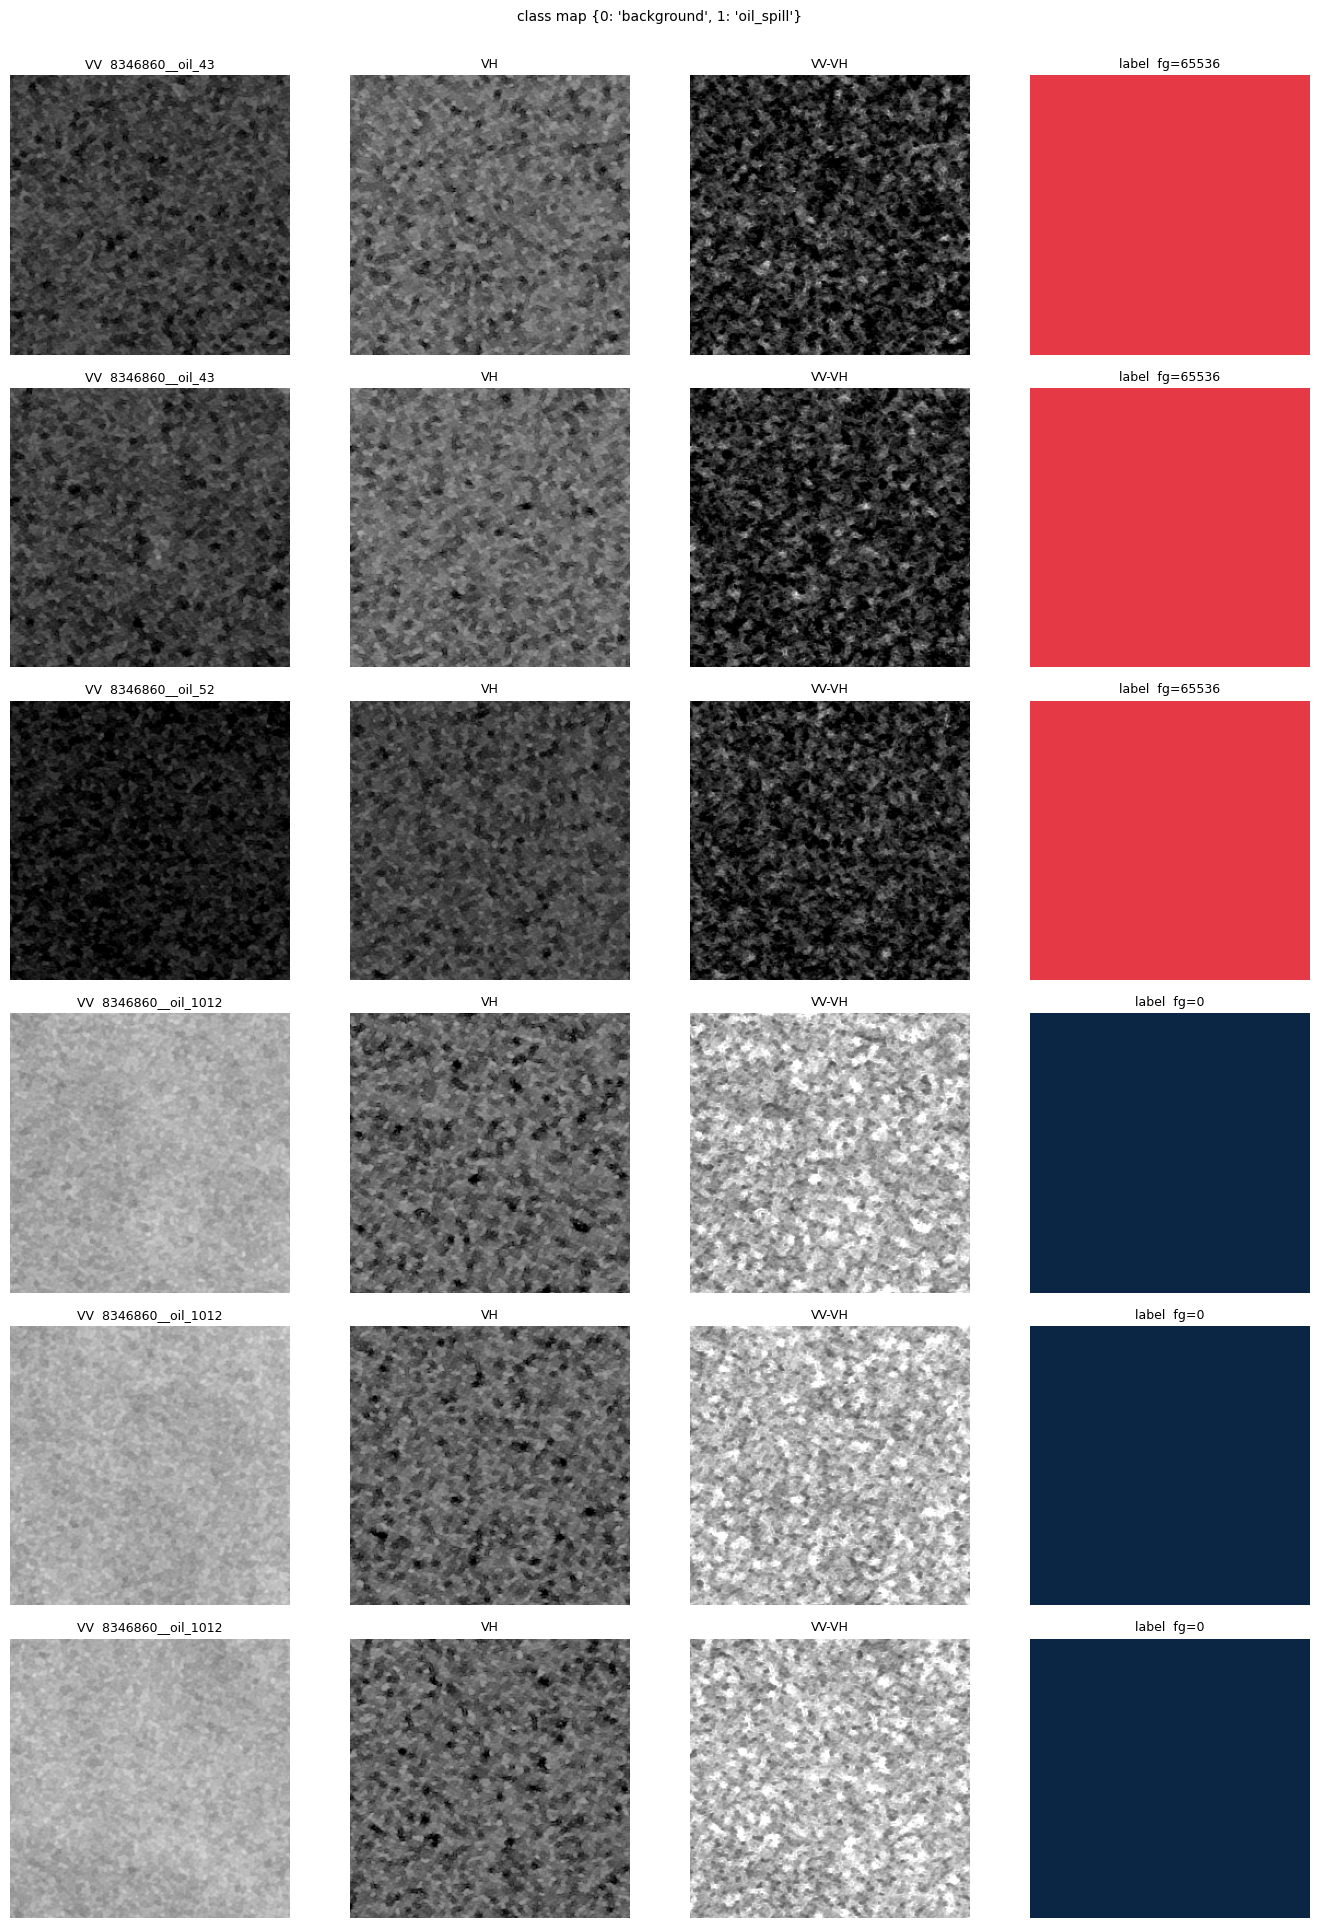

In [20]:
# ---------------------------------------------------------------- look at the tiles
show = pd.concat([TILESDF[TILESDF.positive].nlargest(3, "oil_px"),
                  TILESDF[~TILESDF.positive].head(3)])
CMAP = matplotlib.colors.ListedColormap(["#0b2545", "#e63946", "#2a9d8f"][:max(NUM_CLASSES, 2)])
fig, axes = plt.subplots(len(show), 4, figsize=(14, 3.2 * len(show)))
for ax_row, (_, r) in zip(np.atleast_2d(axes), show.iterrows()):
    z = np.load(TILES / r["tile"])
    x = to_model_input(z["image"][0].astype(np.float32), z["image"][1].astype(np.float32))
    for j, (arr, ttl) in enumerate([(x[0], "VV"), (x[1], "VH"), (x[2], "VV-VH")]):
        ax_row[j].imshow(arr, cmap="gray", vmin=0, vmax=1)
        ax_row[j].set_title(f"{ttl}  {r['scene_id']}" if j == 0 else ttl, fontsize=9)
    ax_row[3].imshow(z["label"], cmap=CMAP, vmin=0, vmax=max(1, NUM_CLASSES - 1),
                     interpolation="nearest")
    ax_row[3].set_title(f"label  fg={r['fg_px']}", fontsize=9)
    for a in ax_row: a.axis("off")
plt.suptitle(f"class map {dict(enumerate(CLASS_NAMES))}", y=1.002, fontsize=10)
plt.tight_layout(); plt.savefig(PLOTS / "tiles_sample.png", dpi=110, bbox_inches="tight"); plt.show()

# B. Stage 1 — Coarse-to-fine multi-scale CFAR

Final Freeze v3 §2 flags this as the single most important correction. The reference notebooks
use a Gaussian-subtracted image with a **global 5th-percentile cut**, which has no constant
false-alarm property at all: the false-alarm rate then varies with sea state across the scene,
which is precisely the failure CFAR exists to fix. Presenting that under the name CFAR costs more
credibility than the detector earns.

The production path has three distinct roles:

1. **Coarse block screen (diagnostic by default)** — block-reduce and record darker sectors. It is
   not applied as a hard output mask after calibration, because the real-scene PFA sweep operates
   on full-scene CFAR statistics. An optional hard gate exists only for controlled experiments.
2. **Full-scene multi-scale guard-cell CFAR** — its PFA is calibrated on TRAIN-only real-SAR
   negative windows and oil-component windows.
3. **Two post-CFAR masks** — a strict 150px consolidated-region mask for false-region reporting,
   and a separate 50px candidate-proposal mask for U-Net crop generation. The U-Net and scene-level
   validation FP gate decide which proposals survive. Ground truth is never passed into inference.

**Why multi-scale is required, not decorative.** For a dark target occupying fraction *f* of the
training annulus with contrast *C* dB against speckle σ:

$$\frac{\mu - x}{\sigma_{\text{loc}}} \;\approx\; \frac{C\,(1-f)}{\sqrt{\sigma^{2} + f(1-f)C^{2}}}$$

At *f* → 0 that is *C/σ*, a strong detection. At *f* → 1 it is **zero** — a slick wider than the
training window supplies its own background, so the detector goes blind to exactly the pixels it
should be most certain about.

Widening the window does not rescue it: the contaminated term `f(1−f)C²` grows with it, so the
guard band would have to exceed the entire slick before the annulus is clean again. Decimating by
*s* does rescue it — the slick shrinks by *s* while speckle averages down by about *s*, so *f*
falls and *C/σ* rises. Roughly, a slick *W* pixels across needs a level with `s > W / guard`, and
that level must still leave an image at least `train` pixels wide. Unlike a global percentile, the
constant false-alarm property holds at **every** level of the pyramid.

`CFG.cfar_scales` is an **engineering initialisation, not a proven optimum**. §C measures the
whole family against controlled ground truth in this run and selects from evidence.

**Honesty note for Q&A:** multi-look SAR intensity is Gamma-distributed and in dB the lower tail
is only approximately Gaussian. Say *"Gaussian approximation on the SAR dB lower tail"*, never
"exact CFAR".

In [21]:
# ======================= science/detect/cfar.py =======================
import numpy as np
from skimage.measure import block_reduce, label as sk_label, regionprops
from scipy.ndimage import uniform_filter, binary_fill_holes
from scipy.stats import norm


def coarse_sectors(sigma0_db, ocean_mask, block=32, z_thresh=1.0):
    """Blocks worth examining at full resolution. Cheap screen, nothing more."""
    img = np.where(ocean_mask, sigma0_db, np.nan)
    coarse = block_reduce(img, (block, block), np.nanmean)
    valid = np.isfinite(coarse)
    if valid.sum() == 0:
        return []
    mu, sd = np.nanmean(coarse[valid]), np.nanstd(coarse[valid])
    if sd < 1e-6:
        return []
    z = (coarse - mu) / sd
    return [tuple(i) for i in np.argwhere(valid & (z < -z_thresh))]


def cfar_dark_statistics(sigma0_db, ocean_mask, guard=7, train=21):
    """Compute the PFA-independent guard-cell statistic once for one scale."""
    img = np.where(ocean_mask, sigma0_db, np.nan)
    finite = np.isfinite(img)
    if finite.sum() == 0:
        return np.zeros(ocean_mask.shape, np.float32)
    filled = np.where(finite, img, np.nanmean(img[finite])).astype(np.float64)
    s_out, s_in = uniform_filter(filled, train), uniform_filter(filled, guard)
    n_out, n_in = train ** 2, guard ** 2
    n_ann = n_out - n_in
    mu = (s_out * n_out - s_in * n_in) / n_ann
    sq_out, sq_in = uniform_filter(filled ** 2, train), uniform_filter(filled ** 2, guard)
    mean_sq = (sq_out * n_out - sq_in * n_in) / n_ann
    sd = np.sqrt(np.maximum(mean_sq - mu ** 2, 1e-9))
    return ((mu - filled) / sd).astype(np.float32)


def threshold_cfar_statistic(statistic, ocean_mask, pfa):
    alpha = float(-norm.ppf(pfa))
    return ocean_mask & (statistic > alpha)


def cfar_dark(sigma0_db, ocean_mask, guard=7, train=21, pfa=1e-4):
    """Local-statistics CFAR; the statistic is independent of PFA."""
    statistic = cfar_dark_statistics(sigma0_db, ocean_mask, guard, train)
    return threshold_cfar_statistic(statistic, ocean_mask, pfa), statistic


def cfar_pyramid_statistics(sigma0_db, ocean_mask, scales=(1, 2, 4), guard=7, train=21):
    """Compute per-scale CFAR statistics once; PFA is applied in a separate cheap pass."""
    statistics = {}
    for scale in scales:
        if scale == 1:
            statistics[scale] = cfar_dark_statistics(sigma0_db, ocean_mask, guard, train)
            continue
        image = np.where(ocean_mask, sigma0_db, np.nan)
        small = block_reduce(image, (scale, scale), np.nanmean)
        if min(small.shape) < train:
            statistics[scale] = None
            continue
        finite = np.isfinite(small)
        if finite.sum() == 0:
            statistics[scale] = None
            continue
        small = np.where(finite, small, np.nanmean(small[finite]))
        scale_ocean = block_reduce(ocean_mask.astype(np.float32), (scale, scale), np.mean) > 0.5
        statistics[scale] = cfar_dark_statistics(small, scale_ocean, guard, train)
    return statistics


def threshold_cfar_pyramid(statistics, ocean_mask, scales=(1, 2, 4), pfa=1e-4,
                           sectors=None, block=32):
    """Apply PFA thresholds to cached statistics, preserving cfar_pyramid's output contract."""
    out, per_scale = np.zeros(ocean_mask.shape, bool), {}
    alpha = float(-norm.ppf(pfa))
    for scale in scales:
        statistic = statistics.get(scale)
        if statistic is None:
            per_scale[scale] = None
            continue
        if scale == 1:
            detected = ocean_mask & (statistic > alpha)
        else:
            scale_ocean = block_reduce(ocean_mask.astype(np.float32), (scale, scale), np.mean) > 0.5
            detected_small = scale_ocean & (statistic > alpha)
            detected = np.kron(detected_small, np.ones((scale, scale), bool))[:ocean_mask.shape[0], :ocean_mask.shape[1]]
        per_scale[scale] = int(detected.sum())
        out |= detected
    out &= ocean_mask
    if sectors is not None:
        sector_mask = np.zeros(ocean_mask.shape, bool)
        for row, col in sectors:
            sector_mask[row * block:(row + 1) * block, col * block:(col + 1) * block] = True
        out &= sector_mask
    return out, per_scale


def cfar_pyramid(sigma0_db, ocean_mask, scales=(1, 2, 4), guard=7, train=21, pfa=1e-4,
                 sectors=None, block=32):
    """PFA-independent statistics pass followed by the per-PFA threshold pass."""
    statistics = cfar_pyramid_statistics(sigma0_db, ocean_mask, scales, guard, train)
    return threshold_cfar_pyramid(statistics, ocean_mask, scales, pfa, sectors, block)


def consolidate_detections(detections, close_radius=5, min_pixels=150, fill=True):
    """Build a morphology-closed mask and apply the requested component-area floor."""
    from skimage import morphology as _m
    close = getattr(_m, "closing", None) or _m.binary_closing
    d = np.asarray(close(detections, _m.disk(close_radius))).astype(bool)
    if fill:
        d = binary_fill_holes(d)
    lab = sk_label(d)
    areas = np.bincount(lab.ravel())
    keep = areas >= int(min_pixels)
    keep[0] = False
    return keep[lab]


def candidate_proposal_mask(raw_detections, close_radius=5, proposal_min_pixels=50, fill=True):
    """Recall-oriented proposal mask for U-Net review.

    This intentionally retains coherent CFAR components smaller than the strict final-region
    floor. It is NOT a final oil mask: candidate_crops + the U-Net + scene-level FP QA decide
    whether any proposed region survives. No ground-truth input is accepted here.
    """
    proposal_min_pixels = int(proposal_min_pixels)
    if proposal_min_pixels < 1:
        raise ValueError("proposal_min_pixels must be >= 1")
    return consolidate_detections(raw_detections, close_radius, proposal_min_pixels, fill)



def large_slick_block_z_scores(sigma0_db, ocean_mask, block_size=32, min_valid_fraction=0.75):
    """Scene-reference dark-block z scores. Lower VV backscatter yields positive scores.

    This is a candidate proposal statistic, not a final oil classifier. It uses only SAR pixels
    and a robust within-scene median/MAD reference. Calibration is performed on full 2048px
    TRAIN negative scenes; scenes smaller than the calibration footprint are not used to fit
    its threshold.
    """
    image = np.asarray(sigma0_db, dtype=np.float32)
    valid = np.asarray(ocean_mask, dtype=bool) & np.isfinite(image)
    if image.ndim != 2 or valid.shape != image.shape:
        raise ValueError("large-slick score expects matching 2-D image and ocean mask")
    b = int(block_size)
    h = (image.shape[0] // b) * b
    w = (image.shape[1] // b) * b
    if h < b or w < b:
        return np.empty((0, 0), dtype=np.float32)
    vals = image[valid]
    if vals.size < b * b:
        return np.full((h // b, w // b), np.nan, dtype=np.float32)
    center = float(np.median(vals))
    mad = float(np.median(np.abs(vals - center)))
    scale = max(1.4826 * mad, 1e-3)
    vv = image[:h, :w].reshape(h // b, b, w // b, b)
    vm = valid[:h, :w].reshape(h // b, b, w // b, b)
    counts = vm.sum(axis=(1, 3)).astype(np.float32)
    sums = np.where(vm, vv, 0.0).sum(axis=(1, 3), dtype=np.float64)
    means = np.divide(sums, counts, out=np.full(counts.shape, np.nan, np.float64), where=counts > 0)
    valid_fraction = counts / float(b * b)
    scores = ((center - means) / scale).astype(np.float32)
    scores[valid_fraction < float(min_valid_fraction)] = np.nan
    return scores


def large_slick_proposal_mask(sigma0_db, ocean_mask, z_threshold, block_size=32,
                              min_valid_fraction=0.75, min_component_pixels=50):
    """Upsample robust dark-block candidates to pixels; proposals only, never final detections."""
    if z_threshold is None or not np.isfinite(float(z_threshold)):
        return np.zeros(np.asarray(ocean_mask).shape, dtype=bool)
    scores = large_slick_block_z_scores(sigma0_db, ocean_mask, block_size, min_valid_fraction)
    if scores.size == 0:
        return np.zeros(np.asarray(ocean_mask).shape, dtype=bool)
    block_mask = np.isfinite(scores) & (scores >= float(z_threshold))
    b = int(block_size)
    proposal = np.repeat(np.repeat(block_mask, b, axis=0), b, axis=1)
    proposal = proposal[:np.asarray(ocean_mask).shape[0], :np.asarray(ocean_mask).shape[1]]
    proposal &= np.asarray(ocean_mask, dtype=bool)
    if proposal.any():
        lab = sk_label(proposal)
        areas = np.bincount(lab.ravel())
        keep = areas >= int(min_component_pixels)
        keep[0] = False
        proposal = keep[lab]
    return proposal


def candidate_crops(detections, sigma0_db, min_pixels=150, size=256,
                    cover_large=True, max_crops_per_region=None):
    """Generate CFAR seeds on the fixed scene-global 50%-overlap lattice.

    The lattice is anchored at scene origin, with a terminal edge origin added if needed.
    Small regions snap their center to the nearest grid crop; large regions use every grid crop
    intersecting their bounding box. Seeds and adaptive crops therefore share one finite grid.
    """
    crops, (H, W) = [], detections.shape
    size = int(size)
    if size <= 0 or H < size or W < size:
        raise ValueError(f"invalid crop size {size} for scene {(H, W)}")
    lab = sk_label(detections)
    seen_origins = set()
    stride = max(1, int(size // 2))

    def _global_axis_origins(length):
        terminal = int(length) - size
        values = list(range(0, terminal + 1, stride))
        if not values or values[-1] != terminal:
            values.append(terminal)
        return np.asarray(sorted(set(int(v) for v in values)), dtype=np.int32)

    grid_rows = _global_axis_origins(H)
    grid_cols = _global_axis_origins(W)

    def _intersecting_origins(lo, hi, axis):
        axis = np.asarray(axis, dtype=np.int32)
        return [int(origin) for origin in axis
                if int(origin) < int(hi) and int(origin) + size > int(lo)]

    for region in regionprops(lab):
        if region.area < min_pixels:
            continue
        minr, minc, maxr, maxc = map(int, region.bbox)
        if not cover_large or ((maxr-minr) <= size and (maxc-minc) <= size):
            center_r, center_c = map(float, region.centroid)
            desired_r, desired_c = center_r - size / 2.0, center_c - size / 2.0
            r0 = int(grid_rows[int(np.argmin(np.abs(grid_rows - desired_r)))])
            c0 = int(grid_cols[int(np.argmin(np.abs(grid_cols - desired_c)))])
            origins = [(r0, c0)]
        else:
            rows = _intersecting_origins(minr, maxr, grid_rows)
            cols = _intersecting_origins(minc, maxc, grid_cols)
            origins = [(r, c) for r in rows for c in cols]

        if max_crops_per_region is not None and len(origins) > int(max_crops_per_region):
            selected, remaining = [], list(origins)
            covered = np.zeros((H, W), dtype=bool)
            while remaining and len(selected) < int(max_crops_per_region):
                best = None; best_gain = -1
                for origin in remaining:
                    r0, c0 = origin
                    rr0, rr1 = max(minr, r0), min(maxr, r0 + size)
                    cc0, cc1 = max(minc, c0), min(maxc, c0 + size)
                    if rr1 <= rr0 or cc1 <= cc0:
                        gain = 0
                    else:
                        local_region = lab[rr0:rr1, cc0:cc1] == int(region.label)
                        gain = int(np.count_nonzero(local_region & ~covered[rr0:rr1, cc0:cc1]))
                    if gain > best_gain:
                        best_gain, best = gain, origin
                if best is None or best_gain <= 0:
                    break
                selected.append(best); remaining.remove(best)
                r0, c0 = best
                covered[r0:r0+size, c0:c0+size] = True
            origins = selected

        for r0, c0 in origins:
            origin = (int(r0), int(c0))
            if origin in seen_origins:
                continue
            crop = sigma0_db[r0:r0+size, c0:c0+size]
            if crop.shape[:2] == (size, size):
                seen_origins.add(origin)
                crops.append({"origin": origin, "array": crop, "region_label": int(region.label),
                              "area_px": int(region.area), "bbox": tuple(int(b) for b in region.bbox),
                              "adaptive_expansion": False, "expansion_round": 0,
                              "adaptive_grid_policy": "scene_global_half_overlap_v1"})
    return crops

def stitch_probability_maps(probability_maps, crops, shape, n_classes=2):
    """Hann-weighted probability averaging across overlapping crop predictions."""
    h_scene, w_scene = map(int, shape)
    weighted = np.zeros((int(n_classes), h_scene, w_scene), dtype=np.float32)
    weight_sum = np.zeros((h_scene, w_scene), dtype=np.float32)
    if probability_maps is None or len(crops) == 0:
        return weighted, np.zeros((h_scene, w_scene), dtype=bool)
    if len(probability_maps) != len(crops):
        raise ValueError("probability map count does not match crop count")
    for probs, crop in zip(probability_maps, crops):
        p = np.asarray(probs, dtype=np.float32)
        if p.ndim != 3:
            raise ValueError("each crop probability map must be 3-D")
        if p.shape[0] != int(n_classes) and p.shape[-1] == int(n_classes):
            p = np.moveaxis(p, -1, 0)
        if p.shape[0] != int(n_classes):
            raise ValueError(f"probability map class axis mismatch: {p.shape}")
        r0, c0 = map(int, crop["origin"])
        h, w = p.shape[1:]
        r1, c1 = min(h_scene, r0 + h), min(w_scene, c0 + w)
        if r1 <= r0 or c1 <= c0:
            continue
        p = p[:, :r1-r0, :c1-c0]
        # Interior Hann weights reduce seams; positive endpoints retain scene-border pixels.
        wy = np.hanning(p.shape[1] + 2)[1:-1].astype(np.float32)
        wx = np.hanning(p.shape[2] + 2)[1:-1].astype(np.float32)
        weights = np.maximum(np.outer(wy, wx), 1e-3)
        finite = np.isfinite(p).all(axis=0)
        weights *= finite.astype(np.float32)
        weighted[:, r0:r1, c0:c1] += np.nan_to_num(p, nan=0.0) * weights[None, ...]
        weight_sum[r0:r1, c0:c1] += weights
    covered = weight_sum > 0
    weighted = np.divide(weighted, weight_sum[None, ...], out=np.zeros_like(weighted),
                         where=weight_sum[None, ...] > 0)
    return weighted, covered


def filter_oil_components(candidate_mask, oil_probability, proposal_mask=None,
                           min_area_px=32, strong_core_probability=0.65,
                           proposal_support_fraction=0.35):
    """Keep thresholded components with a confident core or substantial detector support.

    This is a deterministic hysteresis-style *scene-mask* filter. It never sees labels.
    A component must first exceed the operating probability threshold (applied by the caller)
    and the minimum area. It is then retained if it contains a pixel at/above the strong-core
    threshold, or if the component has the configured overlap with the independently generated
    CFAR/large-slick proposal mask. The proposal path is an alternative support signal for faint
    real slicks; it is not a class label. All parameters are stored in the run card/package.
    """
    mask = np.asarray(candidate_mask, dtype=bool)
    probability = np.asarray(oil_probability, dtype=np.float32)
    if mask.ndim != 2 or probability.shape != mask.shape:
        raise ValueError("candidate mask and oil probability must be matching 2-D arrays")
    if proposal_mask is None:
        proposal = np.zeros(mask.shape, dtype=bool)
    else:
        proposal = np.asarray(proposal_mask, dtype=bool)
        if proposal.shape != mask.shape:
            raise ValueError("proposal mask shape does not match candidate mask")
    min_area_px = max(1, int(min_area_px))
    core_threshold = float(strong_core_probability)
    support_threshold = float(proposal_support_fraction)
    if not 0.0 < core_threshold <= 1.0:
        raise ValueError("strong_core_probability must be in (0, 1]")
    if not 0.0 <= support_threshold <= 1.0:
        raise ValueError("proposal_support_fraction must be in [0, 1]")

    labels = sk_label(mask, connectivity=2)
    filtered = np.zeros(mask.shape, dtype=bool)
    for region in regionprops(labels):
        if int(region.area) < min_area_px:
            continue
        local_labels = labels[region.slice]
        component = local_labels == int(region.label)
        local_probability = probability[region.slice][component]
        finite_probability = local_probability[np.isfinite(local_probability)]
        max_probability = float(finite_probability.max()) if finite_probability.size else 0.0
        local_proposal = proposal[region.slice][component]
        proposal_support = float(local_proposal.mean()) if local_proposal.size else 0.0
        strong_core = max_probability >= core_threshold
        detector_supported = proposal_support >= support_threshold
        if strong_core or detector_supported:
            view = filtered[region.slice]
            view[component] = True
    return filtered


def stitch_crop_masks(crop_masks, crops, shape, n_classes=2, probability_maps=None,
                      probability_threshold=0.50, return_probability_map=False,
                      component_filter=True, proposal_mask=None, component_min_area_px=32,
                      component_core_probability=0.65, component_proposal_support_fraction=0.35):
    """Compose crop outputs with shared filtering; legacy masks retain majority-vote behaviour.

    The same component rule is also applied by the validation threshold sweep, so the operating
    threshold selector and the final scene-level gate measure identical binary predictions.
    """
    if probability_maps is not None:
        averaged, covered = stitch_probability_maps(probability_maps, crops, shape, n_classes)
        if int(n_classes) == 2:
            raw_oil_mask = covered & (averaged[1] >= float(probability_threshold))
            if component_filter:
                raw_oil_mask = filter_oil_components(
                    raw_oil_mask, averaged[1], proposal_mask=proposal_mask,
                    min_area_px=component_min_area_px,
                    strong_core_probability=component_core_probability,
                    proposal_support_fraction=component_proposal_support_fraction)
            mask = np.zeros(tuple(shape), dtype=np.uint8)
            mask[raw_oil_mask] = 1
        else:
            mask = np.where(covered, averaged.argmax(0), 0).astype(np.uint8)
        if return_probability_map:
            oil_probability = averaged[1] if int(n_classes) > 1 else averaged[0]
            return mask, oil_probability.astype(np.float32), covered
        return mask
    votes = np.zeros((n_classes,) + tuple(shape), np.uint16)
    for m, c in zip(crop_masks, crops):
        r0, c0 = c["origin"]; h, w = m.shape
        for k in range(n_classes):
            votes[k, r0:r0 + h, c0:c0 + w] += (m == k)
    covered = votes.sum(axis=0) > 0
    return np.where(covered, votes.argmax(0), 0).astype(np.uint8)


def detect_scene(sigma0_db, ocean_mask, cfg):
    """Calibrated scene detector with separate strict and recall-oriented masks.

    The coarse sector map is retained as a diagnostic. A hard sector mask is opt-in only,
    because the real-scene PFA sweep calibrates full-scene CFAR without that extra gate.
    Applying a coarse gate after calibration would silently change the production detector.
    """
    sectors = coarse_sectors(sigma0_db, ocean_mask, cfg["coarse_block"], cfg["coarse_z"])
    apply_coarse_gate = bool(cfg.get("apply_coarse_sector_gate", False))
    raw, per_scale = cfar_pyramid(
        sigma0_db, ocean_mask, tuple(cfg["scales"]), cfg["guard"], cfg["train"], cfg["pfa"],
        sectors if apply_coarse_gate else None, cfg["coarse_block"])
    detections = consolidate_detections(raw, cfg["close_radius"], cfg["min_region_px"])
    proposals = candidate_proposal_mask(
        raw, cfg["close_radius"], cfg.get("proposal_min_pixels", 50))
    large_slick = np.zeros(ocean_mask.shape, dtype=bool)
    large_threshold = cfg.get("large_slick_z_threshold")
    # Threshold is calibrated on complete 2048px TRAIN negative scenes. Never apply that
    # threshold to 1024px calibration windows, where the scene reference distribution differs.
    if large_threshold is not None and min(ocean_mask.shape) >= 2048:
        large_slick = large_slick_proposal_mask(
            sigma0_db, ocean_mask, large_threshold,
            cfg.get("large_slick_block_size", 32),
            cfg.get("large_slick_min_valid_fraction", 0.75),
            cfg.get("proposal_min_pixels", 50))
        proposals |= large_slick
    return {"sectors": sectors, "coarse_sector_gate_applied": apply_coarse_gate,
            "raw": raw, "detections": detections, "proposals": proposals,
            "large_slick_proposals": large_slick,
            "large_slick_proposal_px": int(large_slick.sum()),
            "per_scale": per_scale}
# ======================= end cfar.py =======================
CFAR_CFG = {"guard": CFG.cfar_guard, "train": CFG.cfar_train, "scales": list(CFG.cfar_scales),
            "pfa": CFG.cfar_pfa, "coarse_block": CFG.coarse_block, "coarse_z": CFG.coarse_z,
            "min_region_px": CFG.min_region_px, "proposal_min_pixels": CFG.cfar_proposal_min_pixels,
            "close_radius": CFG.cfar_close_radius,
            "apply_coarse_sector_gate": CFG.cfar_apply_coarse_sector_gate,
            "large_slick_z_threshold": None, "large_slick_block_size": CFG.large_slick_block_size,
            "large_slick_min_valid_fraction": 0.75,
            "adaptive_expansion_max_rounds": CFG.adaptive_expansion_max_rounds,
            "adaptive_expansion_max_crops": CFG.adaptive_expansion_max_crops,
            "adaptive_expansion_edge_probability": CFG.adaptive_expansion_edge_probability,
            "adaptive_expansion_large_slick_edge_probability": CFG.adaptive_expansion_large_slick_edge_probability,
            "adaptive_expansion_large_slick_min_proposal_fraction": CFG.adaptive_expansion_large_slick_min_proposal_fraction,
            "adaptive_expansion_grid_policy": CFG.adaptive_expansion_grid_policy,
            "oil_component_filter_enabled": CFG.oil_component_filter_enabled,
            "oil_component_min_area_px": CFG.oil_component_min_area_px,
            "oil_component_core_probability": CFG.oil_component_core_probability,
            "oil_component_proposal_support_fraction": CFG.oil_component_proposal_support_fraction,
            "oil_probability_threshold": CFG.unet_default_oil_probability_threshold}
print("CFAR module defined.  alpha(pfa=%g) = %.3f" % (CFG.cfar_pfa, float(-norm.ppf(CFG.cfar_pfa))))

CFAR module defined.  alpha(pfa=0.0001) = 3.719


# C. CFAR synthetic regression tests and scale selection

Controlled ground truth, so recall and false-positive rate are **measured in this run** rather
than quoted from a previous one. Scenarios: homogeneous ocean, a narrow slick, a medium slick, a
wide slick and multiple slicks — all against a scene carrying a sea-state gradient, because a
uniform synthetic scene would let a global threshold look fine.

Two stages: first select the scale set by measurement, then run the full contrast grid
(5/7/9/11/13 dB × two speckle levels) on the selection and on the single-scale baseline.

The regression that matters: **single-scale must fail on the wide slick, and the selected
multi-scale set must not.**

In [22]:
SYNTH_GEOMETRY = {          # boxes are (r0, r1, c0, c1) in a 1024 px scene
    "homogeneous": [],
    "narrow":      [(420, 444, 300, 380)],                       # 24 x 80 px
    "medium":      [(400, 460, 300, 400)],                       # 60 x 100 px
    "wide":        [(350, 470, 300, 520)],                       # 120 x 220 px
    "multiple":    [(180, 215, 180, 255), (520, 590, 640, 760), (760, 790, 300, 350)],
}
SYNTH_N = 1024

def synth_scene(kind, contrast_db, speckle_sd, n=SYNTH_N, gradient_db=2.5, seed=0):
    """Stylised algorithm-regression scene; never used to calibrate production PFA."""
    rng = np.random.default_rng(seed)
    img = rng.normal(-8.0, speckle_sd, (n, n)).astype(np.float32)
    img[:, n // 2:] += gradient_db
    truth = np.zeros((n, n), bool)
    for (r0, r1, c0, c1) in SYNTH_GEOMETRY[kind]:
        img[r0:r1, c0:c1] -= contrast_db
        truth[r0:r1, c0:c1] = True
    return img, np.ones((n, n), bool), truth


def score_detection(det, truth, min_pixels):
    tp = int((det & truth).sum()); fp = int((det & ~truth).sum())
    regions = sum(1 for rp in regionprops(sk_label(det)) if rp.area >= min_pixels)
    return {"recall": (tp / truth.sum()) if truth.sum() else float("nan"),
            "precision": (tp / det.sum()) if det.sum() else 0.0,
            "fp_rate": fp / max(int((~truth).sum()), 1),
            "n_candidate_regions": regions}


def run_detector(img, ocean, scales, pfa=None):
    raw, per = cfar_pyramid(img, ocean, tuple(scales), CFG.cfar_guard, CFG.cfar_train,
                            pfa or CFG.cfar_pfa)
    return consolidate_detections(raw, CFG.cfar_close_radius, CFG.min_region_px), per

print("stylised CFAR regression scenes ready (not used for real-scene PFA calibration) | scenarios:", list(SYNTH_GEOMETRY))

# Stylised scenes remain regression fixtures for scale selection only. Real-tile PFA calibration
# runs once after the production scale set is selected, below.

stylised CFAR regression scenes ready (not used for real-scene PFA calibration) | scenarios: ['homogeneous', 'narrow', 'medium', 'wide', 'multiple']


In [23]:
# ---------------------------------------------------------------- scale-set selection
CANDIDATE_SETS = [(1,), tuple(CFG.cfar_scales), (1, 2, 4, 8), (1, 2, 4, 8, 16), (1, 2, 4, 8, 16, 32)]
CANDIDATE_SETS = list(dict.fromkeys(CANDIDATE_SETS))       # de-dup, keep order
FALSE_REGION_BUDGET = 3.0        # per homogeneous 1024x1024 scene, after the area filter

sweep, t0 = [], time.time()
for _scale_index, scales in enumerate(CANDIDATE_SETS, 1):
    heartbeat("CFAR scale candidates", _scale_index, len(CANDIDATE_SETS))
    recs = []
    for kind in ("narrow", "medium", "wide", "multiple"):
        for contrast in (5, 9, 13):
            img, ocean, truth = synth_scene(kind, contrast, 1.3,
                                            seed=abs(hash((kind, contrast))) % 9999)
            det, _ = run_detector(img, ocean, scales)
            recs.append(score_detection(det, truth, CFG.min_region_px))
    false_regions = []
    for _sd_index, sd in enumerate(range(3), 1):
        heartbeat("CFAR clean fixtures", _sd_index, 3)
        img, ocean, _ = synth_scene("homogeneous", 0, 1.3, seed=500 + sd)
        det, _ = run_detector(img, ocean, scales)
        false_regions.append(sum(1 for rp in regionprops(sk_label(det))))
    r = float(np.mean([x["recall"] for x in recs]))
    p = float(np.mean([x["precision"] for x in recs]))
    sweep.append({"scales": str(tuple(scales)), "levels": len(scales),
                  "mean_recall": round(r, 4), "mean_precision": round(p, 4),
                  "f1": round(2 * r * p / max(r + p, 1e-9), 4),
                  "false_regions_per_homogeneous_scene": round(float(np.mean(false_regions)), 2)})
    print(f"\r  swept {len(sweep)}/{len(CANDIDATE_SETS)} | {time.time()-t0:.0f}s", end="", flush=True)
print()

SWEEP = pd.DataFrame(sweep)
display(SWEEP)

INIT_SCALES = tuple(CFG.cfar_scales)
ok = SWEEP[SWEEP.false_regions_per_homogeneous_scene <= FALSE_REGION_BUDGET]
best = (ok if len(ok) else SWEEP).sort_values("f1", ascending=False).iloc[0]
CFG.cfar_scales = tuple(int(x) for x in best["scales"].strip("(),").split(",") if x.strip())
CFAR_CFG["scales"] = list(CFG.cfar_scales)

init_row = SWEEP[SWEEP.scales == str(INIT_SCALES)].iloc[0]
print(f"\ninitialisation  {INIT_SCALES}  -> mean recall {init_row['mean_recall']:.4f}")
print(f"SELECTED        {CFG.cfar_scales}  -> mean recall {best['mean_recall']:.4f}, "
      f"precision {best['mean_precision']:.4f}, "
      f"{best['false_regions_per_homogeneous_scene']} false regions per clean scene")
if tuple(CFG.cfar_scales) != INIT_SCALES:
    print("\nThe configured initialisation was upgraded by measurement, which is what")
    print("'engineering initialisation, not a proven optimum' means in practice. A slick W pixels")
    print(f"across needs a level with s > W/{CFG.cfar_guard}; the initialisation tops out at")
    print(f"s={max(INIT_SCALES)}, i.e. slicks under ~{max(INIT_SCALES)*CFG.cfar_guard} px wide.")
print("\nPrecision below recall is expected: coarse levels over-extend by design.")
print("CFAR proposes regions; the U-Net segments inside them. That IS the coarse-to-fine contract.")
RUN_CARD["cfar_scale_selection"] = {
    "initialisation": list(INIT_SCALES), "selected": list(CFG.cfar_scales),
    "false_region_budget_per_scene": FALSE_REGION_BUDGET,
    "sweep": SWEEP.to_dict(orient="records"),
    "rule_of_thumb": "a slick W px across needs a pyramid level with s > W / guard",
}

HEARTBEAT CFAR scale candidates 1/5
HEARTBEAT CFAR clean fixtures 1/3
  swept 1/5 | 7sHEARTBEAT CFAR clean fixtures 1/3
  swept 2/5 | 16sHEARTBEAT CFAR clean fixtures 1/3
  swept 3/5 | 25sHEARTBEAT CFAR clean fixtures 1/3
  swept 4/5 | 34sHEARTBEAT CFAR clean fixtures 1/3
  swept 5/5 | 44s


,scales,levels,mean_recall,mean_precision,f1,false_regions_per_homogeneous_scene
0,"(1,)",1,0.0000,0.0000,0.0000,0.0
1,"(1, 2, 4)",3,0.0000,0.0000,0.0000,0.0
2,"(1, 2, 4, 8)",4,0.2405,0.4598,0.3158,0.0
3,"(1, 2, 4, 8, 16)",5,0.6947,0.6027,0.6455,1.0
4,"(1, 2, 4, 8, 16, 32)",6,0.9237,0.7451,0.8249,1.0



initialisation  (1, 2, 4)  -> mean recall 0.0000
SELECTED        (1, 2, 4, 8, 16, 32)  -> mean recall 0.9237, precision 0.7451, 1.0 false regions per clean scene

The configured initialisation was upgraded by measurement, which is what
'engineering initialisation, not a proven optimum' means in practice. A slick W pixels
across needs a level with s > W/7; the initialisation tops out at
s=4, i.e. slicks under ~28 px wide.

Precision below recall is expected: coarse levels over-extend by design.
CFAR proposes regions; the U-Net segments inside them. That IS the coarse-to-fine contract.


In [24]:
with stage("synthetic_cfar_regression"):
    # ---------------------------------------------------------------- full regression suite
    # Cached statistic path and final PFA choice must match the original full recomputation.
    _fixture_rng = np.random.default_rng(42017)
    _fixture_image = _fixture_rng.normal(-17.0, 3.0, (128, 128)).astype(np.float32)
    _fixture_ocean = _fixture_rng.random((128, 128)) > 0.08
    _fixture_image[~_fixture_ocean] = np.nan
    _fixture_stats = cfar_pyramid_statistics(_fixture_image, _fixture_ocean, (1, 2, 4), 3, 9)
    _fixture_truth = np.zeros((128, 128), bool); _fixture_truth[44:72, 50:78] = True
    _fixture_pfas = (1e-2, 1e-3, 1e-4, 1e-5)
    _fixture_cached_rows, _fixture_legacy_rows = [], []
    for _fixture_index, _fixture_pfa in enumerate(_fixture_pfas, 1):
        heartbeat("CFAR cached-vs-legacy PFA fixture", _fixture_index, len(_fixture_pfas))
        _cached, _ = threshold_cfar_pyramid(_fixture_stats, _fixture_ocean, (1, 2, 4), _fixture_pfa)
        _legacy, _ = cfar_pyramid(_fixture_image, _fixture_ocean, (1, 2, 4), 3, 9, _fixture_pfa)
        assert np.array_equal(_cached, _legacy), "cached CFAR differs from legacy path"
        _cached_regions = sum(r.area >= CFG.min_region_px for r in regionprops(sk_label(
            consolidate_detections(_cached, CFG.cfar_close_radius, CFG.min_region_px))))
        _legacy_regions = sum(r.area >= CFG.min_region_px for r in regionprops(sk_label(
            consolidate_detections(_legacy, CFG.cfar_close_radius, CFG.min_region_px))))
        _cached_hit = bool(np.any(consolidate_detections(_cached, CFG.cfar_close_radius, CFG.min_region_px) & _fixture_truth))
        _legacy_hit = bool(np.any(consolidate_detections(_legacy, CFG.cfar_close_radius, CFG.min_region_px) & _fixture_truth))
        _fixture_cached_rows.append((_fixture_pfa, _cached_regions, _cached_hit))
        _fixture_legacy_rows.append((_fixture_pfa, _legacy_regions, _legacy_hit))
    _fixture_false_region_budget = 1.0  # same declared per-1024-window budget as the real-scene sweep

    def _fixture_select(rows):
        feasible = [row for row in rows if row[1] <= _fixture_false_region_budget]
        if not feasible: return None
        recall = max(float(row[2]) for row in feasible)
        return min(row[0] for row in feasible if float(row[2]) == recall)
    _fixture_choice_cached = _fixture_select(_fixture_cached_rows)
    _fixture_choice_legacy = _fixture_select(_fixture_legacy_rows)
    assert _fixture_choice_cached == _fixture_choice_legacy
    print(f"CFAR cached-statistics selector equivalence: PASS; selected PFA={_fixture_choice_cached}")

    rows, t0 = [], time.time()
    for _scenario_number, kind in enumerate(SYNTH_GEOMETRY, 1):
        heartbeat("synthetic CFAR scenarios", _scenario_number, len(SYNTH_GEOMETRY))
        for contrast in (5, 7, 9, 11, 13):
            for speckle in (1.0, 1.6):
                img, ocean, truth = synth_scene(kind, contrast, speckle,
                                                seed=abs(hash((kind, contrast, speckle))) % 9999)
                for tag, scales in (("single_scale", (1,)), ("multi_scale", tuple(CFG.cfar_scales))):
                    det, per = run_detector(img, ocean, scales)
                    s = score_detection(det, truth, CFG.min_region_px)
                    rows.append({"scenario": kind, "contrast_db": contrast, "speckle_sd": speckle,
                                 "detector": tag, "scales": str(tuple(scales)), **s})
        print(f"\r  {kind:12s} done | {time.time()-t0:.0f}s", end="", flush=True)
    print()

    CFAR_VALID = pd.DataFrame(rows).round(5)
    CFAR_VALID.to_csv(OUTROOT / "cfar_validation.csv", index=False)

    summary = (CFAR_VALID[CFAR_VALID.scenario != "homogeneous"]
               .groupby(["scenario", "detector"])
               .agg(mean_recall=("recall", "mean"), mean_precision=("precision", "mean"),
                    mean_fp_rate=("fp_rate", "mean")).round(4).reset_index())
    display(summary)

    homog = (CFAR_VALID[CFAR_VALID.scenario == "homogeneous"]
             .groupby("detector")["n_candidate_regions"].mean())
    print("\nfalse candidate regions per homogeneous-ocean scene:")
    print(homog.round(2).to_string())

    by_contrast = (CFAR_VALID[CFAR_VALID.scenario != "homogeneous"]
                   .pivot_table(index="contrast_db", columns="detector", values="recall", aggfunc="mean")
                   .round(4))
    print("\nmean recall by contrast:")
    print(by_contrast.to_string())

    wide = CFAR_VALID[CFAR_VALID.scenario == "wide"]
    wide_single = float(wide[wide.detector == "single_scale"]["recall"].mean())
    wide_multi  = float(wide[wide.detector == "multi_scale"]["recall"].mean())
    WIDE_SLICK_FIXED = bool(wide_multi > max(wide_single, 0.05))
    print(f"\nWIDE SLICK   single-scale mean recall {wide_single:.4f}   "
          f"multi-scale mean recall {wide_multi:.4f}")
    print("wide-slick zero-recall failure resolved: "
          + ("YES" if WIDE_SLICK_FIXED else "NO — do not quote the multi-scale claim"))

    RUN_CARD["cfar"] = {
        **CFAR_CFG, "alpha": round(float(-norm.ppf(CFG.cfar_pfa)), 4),
        "threshold_model": "Gaussian approximation on the SAR dB lower tail (NOT exact CFAR)",
        "synthetic_scene_px": SYNTH_N, "synthetic_scenarios": list(SYNTH_GEOMETRY),
        "synthetic_rows": int(len(CFAR_VALID)),
        "contrasts_db": [5, 7, 9, 11, 13], "speckle_sd": [1.0, 1.6],
        "mean_recall_by_contrast": {str(k): v.to_dict() for k, v in by_contrast.iterrows()},
        "wide_slick_recall_single_scale": round(wide_single, 4),
        "wide_slick_recall_multi_scale": round(wide_multi, 4),
        "wide_slick_failure_resolved": WIDE_SLICK_FIXED,
        "homogeneous_false_regions_per_scene": {k: round(float(v), 3) for k, v in homog.items()},
        "measured_in_this_run": True,
    }

STAGE_START synthetic_cfar_regression
HEARTBEAT CFAR cached-vs-legacy PFA fixture 1/4
CFAR cached-statistics selector equivalence: PASS; selected PFA=1e-05
HEARTBEAT synthetic CFAR scenarios 1/5
  multiple     done | 54s


,scenario,detector,mean_recall,mean_precision,mean_fp_rate
0,medium,multi_scale,0.9771,0.7185,0.0025
1,medium,single_scale,0.0000,0.0000,0.0000
2,multiple,multi_scale,0.9668,0.6436,0.0066
3,multiple,single_scale,0.0000,0.0000,0.0000
4,narrow,multi_scale,0.9744,0.6390,0.0011
5,narrow,single_scale,0.0000,0.0000,0.0000
6,wide,multi_scale,0.8104,0.9438,0.0013
7,wide,single_scale,0.0000,0.0000,0.0000



false candidate regions per homogeneous-ocean scene:
detector
multi_scale     0.3
single_scale    0.0

mean recall by contrast:
detector     multi_scale  single_scale
contrast_db                           
5                 0.8507           0.0
7                 0.9343           0.0
9                 0.9520           0.0
11                0.9609           0.0
13                0.9629           0.0

WIDE SLICK   single-scale mean recall 0.0000   multi-scale mean recall 0.8104
wide-slick zero-recall failure resolved: YES
STAGE_END synthetic_cfar_regression seconds=54.15


In [25]:
# ---------------------------------------------------------------- triage benchmark (v3 §2)
bench = []
for _bench_index, kind in enumerate(("wide", "multiple"), 1):
    heartbeat("CFAR triage benchmark", _bench_index, 2)
    img, ocean, _ = synth_scene(kind, 9, 1.3, n=2048, seed=7)
    t0 = time.perf_counter(); sec = coarse_sectors(img, ocean, CFG.coarse_block, CFG.coarse_z)
    t1 = time.perf_counter(); cfar_pyramid(img, ocean, tuple(CFG.cfar_scales), CFG.cfar_guard,
                                           CFG.cfar_train, CFG.cfar_pfa)
    t2 = time.perf_counter(); cfar_pyramid(img, ocean, tuple(CFG.cfar_scales), CFG.cfar_guard,
                                           CFG.cfar_train, CFG.cfar_pfa, sec, CFG.coarse_block)
    t3 = time.perf_counter()
    bench.append({"scenario": kind, "coarse_s": t1 - t0, "full_cfar_s": t2 - t1,
                  "gated_cfar_s": t3 - t2, "sectors_flagged": len(sec),
                  "sector_fraction": len(sec) / (2048 // CFG.coarse_block) ** 2})
B = pd.DataFrame(bench)
TRIAGE = {"scene_px": 2048 * 2048,
          "coarse_screen_s": round(float(B.coarse_s.mean()), 3),
          "full_scene_cfar_s": round(float(B.full_cfar_s.mean()), 3),
          "coarse_plus_gated_s": round(float((B.coarse_s + B.gated_cfar_s).mean()), 3),
          "mean_sector_fraction": round(float(B.sector_fraction.mean()), 4),
          "hardware": torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU only",
          "unet_pixel_saving": f"{CFG.tile_size**2} px per crop vs {2048**2} px per scene "
                               f"({(2048**2)//(CFG.tile_size**2)}x fewer per forward pass)"}
TRIAGE["gated_speedup_vs_full_scene"] = None
TRIAGE["coarse_sector_gate_is_production_default"] = False
TRIAGE["gating_scope"] = ("this is a diagnostic comparison only; production detect_scene keeps the coarse map "
                          "as metadata and runs the calibrated full-scene CFAR path. No production CFAR "
                          "runtime saving or hard-gated crop reduction is claimed")
RUN_CARD["cfar"]["triage_benchmark"] = TRIAGE
print(json.dumps(TRIAGE, indent=2))
print("\nDiagnostic-only timing comparison. Production inference does not hard-mask CFAR with coarse sectors; "
      "no coarse-gating speedup is claimed.")

HEARTBEAT CFAR triage benchmark 1/2
{
  "scene_px": 4194304,
  "coarse_screen_s": 0.024,
  "full_scene_cfar_s": 1.25,
  "coarse_plus_gated_s": 1.277,
  "mean_sector_fraction": 0.0079,
  "hardware": "Tesla T4",
  "unet_pixel_saving": "65536 px per crop vs 4194304 px per scene (64x fewer per forward pass)",
  "gated_speedup_vs_full_scene": null,
  "coarse_sector_gate_is_production_default": false,
  "gating_scope": "this is a diagnostic comparison only; production detect_scene keeps the coarse map as metadata and runs the calibrated full-scene CFAR path. No production CFAR runtime saving or hard-gated crop reduction is claimed"
}

Diagnostic-only timing comparison. Production inference does not hard-mask CFAR with coarse sectors; no coarse-gating speedup is claimed.


# D. Stage 2 — U-Net segmentation

Guide §5.2, the line that matters more than the architecture:

> *"Class weighting matters more than architecture here. Oil pixels are a tiny minority of every
> scene; unweighted cross-entropy produces a model that predicts 'sea surface' everywhere and
> reports 97% accuracy. Track per-class IoU on the oil class as your real metric and ignore
> overall accuracy entirely."*

So: Dice + weighted cross-entropy, AdamW, mixed precision, best checkpoint selected on
**validation oil IoU**, early stopping on the same. Pixel accuracy is printed only to show how
uninformative it is.

The encoder starts from ImageNet weights, which `segmentation_models_pytorch` fetches. **No
pre-trained oil-spill model is downloaded** — the oil weights in this package are created by this
run's training loop.

Augmentation is flips, 90° rotations and a speckle-like perturbation only. No hue, saturation,
RGB jitter or photographic brightness: those are meaningless on calibrated backscatter, where the
dB level *is* the physical signal.

In [26]:
with stage('tile_ram_preload_and_reference_panels'):
    import albumentations as A
    import segmentation_models_pytorch as smp
    from torch.utils.data import Dataset, DataLoader

    def speckle_aug(p=0.3):
        """GaussNoise, built version-safely — albumentations renamed var_limit -> std_range in 2.x."""
        for kw in ({"std_range": (0.02, 0.09), "p": p}, {"var_limit": (0.001, 0.01), "p": p}):
            try:
                return A.GaussNoise(**kw)
            except TypeError:
                continue
        return A.NoOp()

    train_tf = A.Compose([A.HorizontalFlip(p=0.5), A.VerticalFlip(p=0.5),
                          A.RandomRotate90(p=0.5),
                          A.ShiftScaleRotate(shift_limit=0.05, scale_limit=0.08, rotate_limit=12,
                                             border_mode=0, p=0.3),
                          speckle_aug(0.3)])
    eval_tf = None


    TILE_RAM_CACHE = {}
    class SARTileDataset(Dataset):
        """Tiles are preloaded once; normalization still uses TRAIN-fitted constants."""
        def __init__(self, df, tiles_dir, transform=None, norm=None):
            self.rows = df.reset_index(drop=True).to_dict(orient="records")
            self.dir, self.transform, self.norm = Path(tiles_dir), transform, norm or NORM
            for number, row in enumerate(self.rows, 1):
                name = row["tile"]
                if name not in TILE_RAM_CACHE:
                    with np.load(self.dir / name, allow_pickle=False) as tile:
                        TILE_RAM_CACHE[name] = {
                            "image": np.asarray(tile["image"], np.float32).copy(),
                            "label": np.asarray(tile["label"], np.uint8).copy(),
                        }
                if number == 1 or number % 10 == 0:
                    heartbeat(f"RAM tile preload {row['split']}", number, len(self.rows))

        def __len__(self):
            return len(self.rows)

        def __getitem__(self, i):
            r = self.rows[i]
            z = TILE_RAM_CACHE[r["tile"]]
            x = to_model_input(z["image"][0], z["image"][1], self.norm)
            lab = z["label"]
            img = np.transpose(x, (1, 2, 0))
            if self.transform is not None:
                o = self.transform(image=img, mask=lab)
                img, lab = o["image"], o["mask"]
            img = np.ascontiguousarray(np.transpose(img, (2, 0, 1)))
            return torch.from_numpy(img).float(), torch.from_numpy(np.ascontiguousarray(lab)).long()


    # Remove any products left by an earlier kernel run. A default tuning run must not
    # accidentally package stale TEST references from a previous final-audit execution.
    _stale_test_products = [
        SCI / "oil_residual_bank_test.npz",
        SCI / "validation_reference_tile.npz",
        SCI / "validation_reference_examples.npz",
        SCI / "validation_reference_best_case.npz",
        OUTROOT / "cfar_test_negative_1024_windows.npz",
        OUTROOT / "cfar_test_window_gate.csv",
        OUTROOT / "end_to_end_test_validation.csv",
        OUTROOT / "end_to_end_test_crop_diagnostics.csv",
    ]
    for _stale_path in _stale_test_products:
        if _stale_path.is_file(): _stale_path.unlink()
    for _stale_key in ("validation_reference_tile", "validation_reference_examples",
                       "validation_reference_best_case"):
        RUN_CARD.pop(_stale_key, None)
    for _stale_key in ("test", "physics_test_reference", "physics_compatibility_filename"):
        RUN_CARD.setdefault("oil_residual_banks", {}).pop(_stale_key, None)
    RUN_CARD["post_freeze_test_evaluation"] = {
        "status": NOT_EXECUTED, "freeze_before_test": False,
        "execution_count": 0, "report_only_not_used_for_tuning_or_success_gate": True,
        "reason": "TEST reference artifacts are created only after explicit final-audit opt-in.",
    }

    train_df = TILESDF[TILESDF.split == "train"]
    val_df   = TILESDF[TILESDF.split == "val"]
    assert len(train_df) and len(val_df), "empty train or validation tile set"
    TILE_RAM_CACHE_BYTES = int(sum(v["image"].nbytes + v["label"].nbytes for v in TILE_RAM_CACHE.values()))
    print(f"TILE_RAM_CACHE_BYTES={TILE_RAM_CACHE_BYTES} (~{TILE_RAM_CACHE_BYTES/1024**3:.3f} GiB)", flush=True)
    train_ds = SARTileDataset(train_df, TILES, train_tf)
    val_ds   = SARTileDataset(val_df,   TILES, eval_tf)
    TILE_RAM_CACHE_BYTES = int(sum(v["image"].nbytes + v["label"].nbytes for v in TILE_RAM_CACHE.values()))
    RUN_CARD["tile_ram_cache_bytes"] = TILE_RAM_CACHE_BYTES
    print(f"TILE_RAM_CACHE_BYTES_FINAL={TILE_RAM_CACHE_BYTES} (~{TILE_RAM_CACHE_BYTES/1024**3:.3f} GiB)", flush=True)

    # Export empirical, split-isolated oil residual banks. Each stored residual is the local
    # background median minus the observed dB pixel; the mask controls where it may be rendered.
    def export_oil_residual_bank(split_name, frame, output_path):
        rows = frame[(frame["split"] == split_name) & frame["positive"].astype(bool)].sort_values(
            ["scene_id", "tile"])
        residuals, masks, background_medians, scene_ids, tile_names = [], [], [], [], []
        failures = []
        for _row_index, (_, row) in enumerate(rows.iterrows(), 1):
            heartbeat(f"residual bank {split_name} tiles", _row_index, len(rows))
            with np.load(TILES / row["tile"], allow_pickle=False) as tile:
                image = np.asarray(tile["image"], np.float32)
                label = np.asarray(tile["label"])
            oil_mask = label == OIL_CLASS
            if image.ndim != 3 or image.shape[0] != 2 or image.shape[1:] != label.shape or not oil_mask.any():
                failures.append(f"{row['tile']}: invalid shape or empty oil mask")
                continue
            band_medians = []
            for band in range(2):
                valid_background = np.isfinite(image[band]) & (image[band] != 0) & ~oil_mask
                if not valid_background.any():
                    failures.append(f"{row['tile']}: no valid local background in band {band}")
                    break
                band_medians.append(float(np.median(image[band][valid_background])))
            if len(band_medians) != 2:
                continue
            residual = np.asarray(band_medians, np.float32)[:, None, None] - image
            residuals.append(residual)
            masks.append(oil_mask.astype(np.uint8))
            background_medians.append(band_medians)
            scene_ids.append(str(row["scene_id"]))
            tile_names.append(str(row["tile"]))
        if failures or not residuals:
            result = {"status": "BLOCKED", "split": split_name, "tiles": len(residuals),
                      "errors": failures or ["no positive oil tiles for residual bank"]}
            RUN_CARD.setdefault("oil_residual_banks", {})[split_name] = result
            raise RuntimeError(f"{split_name} oil residual bank is incomplete: {failures[:5]}")
        np.savez_compressed(
            output_path, residuals=np.stack(residuals).astype(np.float32),
            masks=np.stack(masks).astype(np.uint8),
            background_medians=np.asarray(background_medians, np.float32),
            scene_ids=np.asarray(scene_ids, dtype=str), tile_names=np.asarray(tile_names, dtype=str),
            split=np.asarray(split_name, dtype=str),
            residual_definition=np.asarray("local background median minus observed VV/VH dB pixel"))
        result = {"status": "EXECUTED", "split": split_name, "tiles": len(residuals),
                  "artifact": str(Path(output_path).relative_to(SCI)),
                  "residual_definition": "local background median - VV/VH dB pixel",
                  "stored_raw_without_clipping": True}
        RUN_CARD.setdefault("oil_residual_banks", {})[split_name] = result
        print(f"{split_name} oil residual bank: {len(residuals)} tiles -> {output_path.name}")
        return result

    OIL_RESIDUAL_BANK_TRAIN = SCI / "oil_residual_bank_train.npz"
    export_oil_residual_bank("train", TILESDF, OIL_RESIDUAL_BANK_TRAIN)

    # The three scene-distinct Physics reference-panel selectors are defined here but not
    # materialized until the opt-in final TEST audit after the checkpoint is frozen.
    def _distinct_validation_examples(frame, positive, limit, seed, best_case=False, exclude_scenes=()):
        candidates = frame[(frame["positive"].astype(bool) == positive)
                           & ~frame["scene_id"].astype(str).isin(set(map(str, exclude_scenes)))]
        if best_case and positive:
            candidates = candidates.sort_values(["oil_px", "scene_id", "tile"], ascending=[False, True, True])
        else:
            candidates = candidates.sample(frac=1.0, random_state=seed)
        return candidates.drop_duplicates("scene_id", keep="first").head(limit)

    print(f"train tiles {len(train_ds)} | validation tiles {len(val_ds)} | "
          "TEST metrics/references are deferred until the explicit post-freeze audit")
    xb, yb = train_ds[0]
    print("sample:", tuple(xb.shape), xb.dtype, "->", tuple(yb.shape), yb.dtype,
          "| label values", torch.unique(yb).tolist())

STAGE_START tile_ram_preload_and_reference_panels
TILE_RAM_CACHE_BYTES=0 (~0.000 GiB)
HEARTBEAT RAM tile preload train 1/1062
HEARTBEAT RAM tile preload train 10/1062
HEARTBEAT RAM tile preload train 20/1062
HEARTBEAT RAM tile preload train 30/1062
HEARTBEAT RAM tile preload train 40/1062
HEARTBEAT RAM tile preload train 50/1062
HEARTBEAT RAM tile preload train 60/1062
HEARTBEAT RAM tile preload train 70/1062
HEARTBEAT RAM tile preload train 80/1062
HEARTBEAT RAM tile preload train 90/1062
HEARTBEAT RAM tile preload train 100/1062
HEARTBEAT RAM tile preload train 110/1062
HEARTBEAT RAM tile preload train 120/1062
HEARTBEAT RAM tile preload train 130/1062
HEARTBEAT RAM tile preload train 140/1062
HEARTBEAT RAM tile preload train 150/1062
HEARTBEAT RAM tile preload train 160/1062
HEARTBEAT RAM tile preload train 170/1062
HEARTBEAT RAM tile preload train 180/1062
HEARTBEAT RAM tile preload train 190/1062
HEARTBEAT RAM tile preload train 200/1062
HEARTBEAT RAM tile preload train 210/1062
H

In [27]:
# ---------------------------------------------------------------- model, loss, AMP
def build_model():
    return smp.Unet(encoder_name=CFG.encoder, encoder_weights=CFG.encoder_weights,
                    in_channels=CFG.in_channels, classes=NUM_CLASSES)

def criterion(logits, target):
    return 0.5 * dice(logits, target) + 0.5 * ce(logits, target)

if TRAINING_PREREQUISITES_OK and COVERAGE_STATUS == "OK":
    with stage("unet_model_initialization"):
        print("UNET_MODEL_INIT_START", flush=True)
        model = build_model().to(DEVICE)
        dice = smp.losses.DiceLoss(mode="multiclass")
        ce = nn.CrossEntropyLoss(weight=torch.tensor(CE_WEIGHTS, dtype=torch.float32).to(DEVICE))
        optimizer = torch.optim.AdamW(model.parameters(), lr=CFG.learning_rate,
                                  weight_decay=CFG.weight_decay)
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=CFG.epochs)
        try:
            scaler = torch.amp.GradScaler("cuda", enabled=(DEVICE == "cuda"))
            autocast = lambda: torch.amp.autocast("cuda", enabled=(DEVICE == "cuda"))
        except (AttributeError, TypeError):
            scaler = torch.cuda.amp.GradScaler(enabled=(DEVICE == "cuda"))
            autocast = lambda: torch.cuda.amp.autocast(enabled=(DEVICE == "cuda"))
        print(f"U-Net {CFG.encoder} | {NUM_CLASSES} classes {CLASS_NAMES} | "
          f"{sum(p.numel() for p in model.parameters())/1e6:.1f}M params | {DEVICE}")
        print("CE weights:", dict(zip(CLASS_NAMES, CE_WEIGHTS)))
        print("UNET_MODEL_INIT_END", flush=True)
else:
    print("U-Net initialization: NOT EXECUTED — coverage gate blocked training")

STAGE_START unet_model_initialization
UNET_MODEL_INIT_START


config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            

U-Net resnet34 | 2 classes ['background', 'oil_spill'] | 24.4M params | cuda
CE weights: {'background': 0.1, 'oil_spill': 1.0}
UNET_MODEL_INIT_END
STAGE_END unet_model_initialization seconds=2.65


In [28]:
with stage('training_warmup_and_loaders'):
    class IoUMeter:
        """Dataset-level per-class IoU + Dice, accumulated over an epoch."""
        def __init__(self, n):
            self.n = n
            self.inter = np.zeros(n); self.union = np.zeros(n)
            self.pred_n = np.zeros(n); self.true_n = np.zeros(n)
            self.correct = 0.0; self.total = 0.0

        def update(self, pred, target):
            p = pred.detach().cpu().numpy().ravel(); t = target.detach().cpu().numpy().ravel()
            self.correct += float((p == t).sum()); self.total += p.size
            for c in range(self.n):
                pc, tc = (p == c), (t == c)
                self.inter[c] += float((pc & tc).sum()); self.union[c] += float((pc | tc).sum())
                self.pred_n[c] += float(pc.sum()); self.true_n[c] += float(tc.sum())

        def report(self, names):
            out = {}
            ious, dices = [], []
            for i, nm in enumerate(names):
                if self.union[i] > 0:
                    iou = self.inter[i] / self.union[i]
                    dc = 2 * self.inter[i] / max(self.pred_n[i] + self.true_n[i], 1e-9)
                    out[f"iou_{nm}"] = round(float(iou), 4); out[f"dice_{nm}"] = round(float(dc), 4)
                    ious.append(iou); dices.append(dc)
                else:
                    out[f"iou_{nm}"] = None; out[f"dice_{nm}"] = None
            out["macro_iou"]  = round(float(np.mean(ious)), 4) if ious else 0.0
            out["macro_dice"] = round(float(np.mean(dices)), 4) if dices else 0.0
            out["pixel_acc"]  = round(self.correct / max(self.total, 1), 4)
            return out


    def _worker_init(_worker_id):
        import os
        os.environ["OMP_NUM_THREADS"] = "1"
        if "cv2" in globals():
            cv2.setNumThreads(0)
            cv2.ocl.setUseOpenCL(False)

    import threading

    def _next_batch_with_watchdog(data_loader, watchdog_seconds=60):
        """Pull one first batch with a 60 s wall-clock watchdog.
        A timed-out worker iterator is shut down before callers retry with zero workers.
        """
        iterator = iter(data_loader)
        result, error = {}, {}
        done = threading.Event()
        def _pull():
            try:
                result["batch"] = next(iterator)
            except BaseException as exc:
                error["exc"] = exc
            finally:
                done.set()
        t = threading.Thread(target=_pull, name="tidetrace-first-batch-watchdog", daemon=True)
        t.start()
        if not done.wait(float(watchdog_seconds)):
            shutdown = getattr(iterator, "_shutdown_workers", None)
            if callable(shutdown):
                try:
                    shutdown()
                except Exception:
                    pass
            raise TimeoutError(f"first DataLoader batch exceeded {watchdog_seconds:.0f}s watchdog")
        if "exc" in error:
            raise error["exc"]
        return result["batch"]

    def make_loaders(bs, first_batch_watchdog=False):
        workers = int(CFG.num_workers)
        common = {"num_workers": workers, "pin_memory": (DEVICE == "cuda"),
                  "worker_init_fn": _worker_init if workers else None,
                  "timeout": 120 if workers else 0,
                  "persistent_workers": workers > 0}
        return (DataLoader(train_ds, batch_size=bs, shuffle=True,
                           drop_last=len(train_ds) > bs, **common),
                DataLoader(val_ds, batch_size=bs, shuffle=False, **common))


    def run_epoch(dl, train):
        model.train(train)
        meter, losses = IoUMeter(NUM_CLASSES), []
        ctx = torch.enable_grad() if train else torch.inference_mode()
        with ctx:
            _last_heartbeat = time.monotonic()
            for _batch_number, (xb, yb) in enumerate(dl, 1):
                if _batch_number == 1 or _batch_number % 10 == 0 or time.monotonic() - _last_heartbeat >= 60:
                    heartbeat("training batch" if train else "validation batch", _batch_number, len(dl))
                    _last_heartbeat = time.monotonic()
                xb, yb = xb.to(DEVICE, non_blocking=True), yb.to(DEVICE, non_blocking=True)
                if train:
                    optimizer.zero_grad(set_to_none=True)
                with autocast():
                    logits = model(xb); loss = criterion(logits, yb)
                if train:
                    scaler.scale(loss).backward(); scaler.step(optimizer); scaler.update()
                losses.append(float(loss.detach())); meter.update(logits.argmax(1), yb)
        rep = meter.report(CLASS_NAMES); rep["loss"] = round(float(np.mean(losses)), 5)
        return rep


    if TRAINING_PREREQUISITES_OK and COVERAGE_STATUS == "OK":
        BATCH = CFG.batch_size
        for bs in [b for b in (16, 8, 4, 2) if b <= CFG.batch_size] or [CFG.batch_size]:
            try:
                print("TRAIN_WARMUP_START", flush=True)
                tl, vl = make_loaders(bs, first_batch_watchdog=True)
                try:
                    xb, yb = _next_batch_with_watchdog(tl, 60)
                except Exception as _loader_error:
                    if CFG.num_workers <= 0:
                        raise
                    print(f"first-batch worker watchdog fallback: {type(_loader_error).__name__}: {_loader_error}; retrying with num_workers=0", flush=True)
                    CFG.num_workers = 0
                    tl, vl = make_loaders(bs)
                    xb, yb = _next_batch_with_watchdog(tl, 60)
                print(f"TRAIN_WARMUP_BATCH_RECEIVED shape={tuple(xb.shape)}", flush=True)
                xb, yb = xb.to(DEVICE), yb.to(DEVICE)
                with autocast():
                    loss = criterion(model(xb), yb)
                scaler.scale(loss).backward(); optimizer.zero_grad(set_to_none=True)
                BATCH = bs; print(f"batch_size {bs}: OK"); break
            except RuntimeError as e:
                if "out of memory" not in str(e).lower():
                    raise
                print(f"batch_size {bs}: CUDA OOM, trying smaller"); torch.cuda.empty_cache()
        else:
            raise RuntimeError("Even batch_size=2 does not fit. Reduce CFG.tile_size or use a larger GPU.")

        model = build_model().to(DEVICE)
        optimizer = torch.optim.AdamW(model.parameters(), lr=CFG.learning_rate, weight_decay=CFG.weight_decay)
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=CFG.epochs)
        train_dl, val_dl = make_loaders(BATCH)
        print(f"training with batch_size={BATCH}, {len(train_dl)} steps/epoch")
    else:
        print("Training warm-up and DataLoader setup: NOT EXECUTED — coverage gate blocked training")


STAGE_START training_warmup_and_loaders
TRAIN_WARMUP_START
TRAIN_WARMUP_BATCH_RECEIVED shape=(16, 3, 256, 256)
batch_size 16: OK
training with batch_size=16, 66 steps/epoch
STAGE_END training_warmup_and_loaders seconds=5.46


In [29]:
with stage('training_selection_validation_only'):
    CKPT_BEST = WEIGHTS / "unet_resnet34_best.pt"
    CKPT_LAST = WEIGHTS / "unet_resnet34_last.pt"
    CKPT      = WEIGHTS / "unet_resnet34.pt"

    def checkpoint_payload(extra):
        return {"state_dict": model.state_dict(), "encoder": CFG.encoder, "classes": NUM_CLASSES,
                "class_names": CLASS_NAMES, "oil_class": OIL_CLASS,
                "in_channels": CFG.in_channels, "tile_size": CFG.tile_size,
                "normalisation": NORM, "band_order": {"VV": int(BAND_VV), "VH": int(BAND_VH)},
                "dataset": RUN_CARD["dataset"]["mode"],
                "dataset_records": [r["record"] for r in RUN_CARD["dataset"]["records"]],
                "smoke_test_only": RUN_CARD["dataset"]["smoke_test_only"],
                "trained_at": datetime.now(timezone.utc).isoformat(), **extra}

    if RUN_CARD["dataset_coverage"]["status"] != "OK":
        RUN_CARD["coverage_gate_blocked"] = True
        print("=" * 78)
        print("TIDETRACE TRAINING BLOCKED — insufficient dataset coverage")
        print("=" * 78)
        print(json.dumps(RUN_CARD["dataset_coverage"], indent=2))
        print("\nThe final run card will record BLOCKED. Raise CFG.ingest_time_budget_min or "
              "CFG.max_scenes_per_class, or fix pairing, then re-run.")
        # Do not raise: final freeze gate records BLOCKED after all contract checks.

    history, best_oil = [], -1.0
    RUN_CARD["seeds_completed"] = []
    RUN_CARD["training_stall_localization_contract"] = {
        "warmup_markers": ["TRAIN_WARMUP_START", "TRAIN_WARMUP_BATCH_RECEIVED"],
        "epoch_marker_prefix": "seed <seed> ep",
        "default_num_workers": int(CFG.num_workers),
        "first_batch_watchdog_seconds": 60,
        "worker_timeout_seconds": 120,
    }
    seed_selection_records = []
    TRAINING_SEEDS = (42, 43, 44)
    t_start = time.time()
    OIL_KEY = f"iou_{CLASS_NAMES[OIL_CLASS]}"
    OIL_DICE_KEY = f"dice_{CLASS_NAMES[OIL_CLASS]}"
    TRAINING_LOOP_EXECUTED = False
    CHECKPOINT_CREATED_THIS_RUN = False
    if COVERAGE_STATUS != "OK":
        RUN_CARD.pop("unet", None)
        RUN_CARD.pop("checkpoint_contract", None)
        RUN_CARD.pop("training_artifact", None)

    if TRAINING_PREREQUISITES_OK and COVERAGE_STATUS == "OK":
        for _seed in TRAINING_SEEDS:
            seed_everything(_seed)
            model = build_model().to(DEVICE)
            optimizer = torch.optim.AdamW(model.parameters(), lr=CFG.learning_rate,
                                          weight_decay=CFG.weight_decay)
            scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=CFG.epochs)
            scaler = torch.amp.GradScaler("cuda", enabled=(DEVICE == "cuda"))
            _seed_best_path = WEIGHTS / f".unet_seed_{_seed}_best.pt"
            _seed_last_path = WEIGHTS / f".unet_seed_{_seed}_last.pt"
            _seed_history = []
            _best_ema, _best_raw, _best_metrics, _bad = -1.0, -1.0, None, 0
            _ema = None
            for epoch in range(1, CFG.epochs + 1):
                _epoch_started = time.perf_counter()
                TRAINING_LOOP_EXECUTED = True
                tr = run_epoch(train_dl, True)
                va = run_epoch(val_dl, False)
                scheduler.step()
                oil = float(va.get(OIL_KEY) or 0.0)
                _ema = oil if _ema is None else (0.5 * oil + 0.5 * _ema)
                epoch_record = {"seed": _seed, "epoch": epoch,
                                **{f"train_{k}": v for k, v in tr.items()},
                                **{f"val_{k}": v for k, v in va.items()},
                                "val_oil_iou_ema3": float(_ema),
                                "lr": optimizer.param_groups[0]["lr"]}
                epoch_record["epoch_wall_seconds"] = float(time.perf_counter() - _epoch_started)
                _seed_history.append(epoch_record)
                history.append(epoch_record)
                torch.save(checkpoint_payload({"seed": _seed, "epoch": epoch,
                    "val_oil_iou": oil, "val_oil_iou_ema3": float(_ema),
                    "selection_metric": "3-epoch EMA of validation oil IoU"}), _seed_last_path)
                CHECKPOINT_CREATED_THIS_RUN = True
                if _ema > _best_ema:
                    _best_ema, _best_raw, _best_metrics, _bad = float(_ema), oil, dict(va), 0
                    torch.save(checkpoint_payload({"seed": _seed, "epoch": epoch,
                        "val_oil_iou": oil, "val_oil_iou_ema3": float(_ema),
                        "val_oil_dice": va.get(OIL_DICE_KEY),
                        "selection_metric": "3-epoch EMA of validation oil IoU"}), _seed_best_path)
                    flag = "   <-- best EMA"
                else:
                    _bad += 1; flag = ""
                print(f"seed { _seed } ep{epoch:3d} | train loss {tr['loss']:.4f} | "
                      f"val oil IoU {oil:.4f} | EMA3 {float(_ema):.4f} | "
                      f"val oil Dice {va.get(OIL_DICE_KEY)} | lr {optimizer.param_groups[0]['lr']:.3g}{flag}",
                      flush=True)
                heartbeat(f"seed {_seed} epoch", epoch, CFG.epochs)
                _seed_position = TRAINING_SEEDS.index(_seed)
                _remaining_epochs = max(0, CFG.epochs - epoch) + max(0, len(TRAINING_SEEDS) - _seed_position - 1) * CFG.epochs
                _recent_epoch_seconds = [float(row.get("epoch_wall_seconds", 0.0)) for row in history[-3:]
                                         if float(row.get("epoch_wall_seconds", 0.0)) > 0]
                _epoch_seconds = float(np.mean(_recent_epoch_seconds)) if _recent_epoch_seconds else epoch_record["epoch_wall_seconds"]
                session_packaging_guard(_remaining_epochs * _epoch_seconds)
                if _bad >= CFG.patience:
                    print(f"seed {_seed}: early stop after {CFG.patience} epochs without EMA improvement")
                    break
            if _seed_best_path.is_file():
                seed_selection_records.append({
                    "seed": int(_seed), "best_val_oil_iou_ema3": _best_ema,
                    "best_val_oil_iou": _best_raw,
                    "best_val_oil_dice": _best_metrics.get(OIL_DICE_KEY),
                    "best_val_macro_iou": _best_metrics.get("macro_iou"),
                    "best_val_macro_dice": _best_metrics.get("macro_dice"),
                    "epochs_run": len(_seed_history),
                    "best_checkpoint": str(_seed_best_path), "last_checkpoint": str(_seed_last_path),
                })
                RUN_CARD["seeds_completed"] = [int(row["seed"]) for row in seed_selection_records]

    SEED_TEST_METRICS = []  # intentionally empty: TEST is not touched during seed selection
    CHECKPOINT_SELECTION_SPLIT = "val"
    CHECKPOINT_SELECTION_METRIC = "3-epoch EMA of validation oil IoU"
    RUN_CARD["checkpoint_selection"] = {
        "status": "EXECUTED" if TRAINING_LOOP_EXECUTED else NOT_EXECUTED,
        "split": CHECKPOINT_SELECTION_SPLIT,
        "metric": CHECKPOINT_SELECTION_METRIC,
        "test_used_for_selection": False,
        "test_evaluations_before_final_freeze": 0,
    }
    if seed_selection_records:
        _winner = max(seed_selection_records, key=lambda row: row["best_val_oil_iou_ema3"])
        _winner_payload = torch.load(_winner["best_checkpoint"], map_location=DEVICE, weights_only=False)
        shutil.copyfile(_winner["best_checkpoint"], CKPT_BEST)
        shutil.copyfile(_winner["best_checkpoint"], CKPT)
        shutil.copyfile(_winner["last_checkpoint"], CKPT_LAST)
        best_oil = float(_winner["best_val_oil_iou"])
        model.load_state_dict(_winner_payload["state_dict"])
        for _record in seed_selection_records:
            Path(_record["best_checkpoint"]).unlink(missing_ok=True)
            Path(_record["last_checkpoint"]).unlink(missing_ok=True)
        SEED_SELECTION_SUMMARY = {
            "status": "EXECUTED", "seeds": [row["seed"] for row in seed_selection_records],
            "selected_seed": int(_winner["seed"]),
            "selection_metric": CHECKPOINT_SELECTION_METRIC,
            "best_val_oil_iou_role": "checkpoint-selection metric; validation only, not headline detection performance",
            "test_used_for_selection": False,
            "test_evaluations_before_final_freeze": 0,
            "test_tile_metrics": "NOT EXECUTED — TEST reserved for the final frozen end-to-end audit",
            "validation_oil_iou_mean_sd": [
                float(np.mean([r["best_val_oil_iou"] for r in seed_selection_records])),
                float(np.std([r["best_val_oil_iou"] for r in seed_selection_records], ddof=1))],
            "validation_oil_dice_mean_sd": [
                float(np.mean([r["best_val_oil_dice"] for r in seed_selection_records])),
                float(np.std([r["best_val_oil_dice"] for r in seed_selection_records], ddof=1))],
            "per_seed": seed_selection_records,
        }
        RUN_CARD["unet_seed_evaluation"] = SEED_SELECTION_SUMMARY
    else:
        SEED_SELECTION_SUMMARY = {"status": NOT_EXECUTED, "reason": "training prerequisites or coverage gate blocked",
                                  "test_evaluations_before_final_freeze": 0}
        RUN_CARD["unet_seed_evaluation"] = SEED_SELECTION_SUMMARY

    HIST = pd.DataFrame(history)
    HIST.to_csv(OUTROOT / "validation_metrics.csv", index=False)
    if not CHECKPOINT_CREATED_THIS_RUN:
        print("no checkpoint promoted: training did not execute in this run")
    TRAIN_MINUTES = round((time.time() - t_start) / 60, 1) if TRAINING_LOOP_EXECUTED else None
    if TRAINING_LOOP_EXECUTED:
        print(f"\ntrained {len(HIST)} seed-epochs in {TRAIN_MINUTES} min | "
              f"selected seed={SEED_SELECTION_SUMMARY.get('selected_seed')} | "
              f"checkpoint-selection metric (VAL oil IoU) {best_oil:.4f}")
        print("validation oil IoU mean±sd:", SEED_SELECTION_SUMMARY.get("validation_oil_iou_mean_sd"))
        print("validation oil Dice mean±sd:", SEED_SELECTION_SUMMARY.get("validation_oil_dice_mean_sd"))
        print("TEST tile metrics: NOT EXECUTED; TEST reserved for one frozen scene-level audit")
        print(f"best checkpoint -> {CKPT_BEST}\npromoted to      -> {CKPT}")
        print("\nNote the pixel-accuracy column: high from epoch 1, and it tells you nothing.")
    else:
        print("TIDETRACE TRAINING BLOCKED — insufficient dataset coverage")

write_progress_note("phase1_training", "EXECUTED" if TRAINING_LOOP_EXECUTED else "NOT EXECUTED", {"seeds_completed": RUN_CARD.get("seeds_completed", []), "training_loop_executed": bool(TRAINING_LOOP_EXECUTED), "checkpoint_created_this_run": bool(CHECKPOINT_CREATED_THIS_RUN)})

STAGE_START training_selection_validation_only
HEARTBEAT training batch 1/66
HEARTBEAT training batch 10/66
HEARTBEAT training batch 20/66
HEARTBEAT training batch 30/66
HEARTBEAT training batch 40/66
HEARTBEAT training batch 50/66
HEARTBEAT training batch 60/66
HEARTBEAT validation batch 1/23
HEARTBEAT validation batch 10/23
HEARTBEAT validation batch 20/23
seed 42 ep  1 | train loss 0.4132 | val oil IoU 0.2315 | EMA3 0.2315 | val oil Dice 0.376 | lr 0.0003   <-- best EMA
HEARTBEAT seed 42 epoch 1/40
HEARTBEAT training batch 1/66
HEARTBEAT training batch 10/66
HEARTBEAT training batch 20/66
HEARTBEAT training batch 30/66
HEARTBEAT training batch 40/66
HEARTBEAT training batch 50/66
HEARTBEAT training batch 60/66
HEARTBEAT validation batch 1/23
HEARTBEAT validation batch 10/23
HEARTBEAT validation batch 20/23
seed 42 ep  2 | train loss 0.3198 | val oil IoU 0.3203 | EMA3 0.2759 | val oil Dice 0.4851 | lr 0.000298   <-- best EMA
HEARTBEAT training batch 1/66
HEARTBEAT training batch 10/6

In [30]:
with stage("real_scene_cfar_calibration"):
    # Dependency-order lock: real-scene calibrated PFA is introduced only after checkpoint selection.
    RUN_CARD["cfar_dependency_check"] = {
        "status": "PASS",
        "real_scene_calibration_stage": "post_checkpoint_selection",
        "calibrated_pfa_used_by_unet_training": False,
        "pre_training_pfa_role": "predeclared/default only for algorithm regression and triage diagnostics",
        "checkpoint_selection_already_executed": bool(seed_selection_records),
    }
    print("CFAR DEPENDENCY CHECK PASS: real-scene calibrated PFA is post-checkpoint-selection", flush=True)
    # Scene-scale real-SAR CFAR calibration: deterministic 1024x1024 windows from 2048x2048 scenes.
    # PFA selection uses TRAIN only. VALIDATION negative windows provide the frozen
    # acceptance surface. TEST windows are materialized only under final-audit opt-in.
    import time as _cfar_time
    from collections import defaultdict as _cfar_defaultdict
    CFAR_PREDECLARED_PFA = float(CFAR_CFG.get("pfa", CFG.cfar_pfa))
    _CFar_started_at = _cfar_time.monotonic()
    _CFar_budget_seconds = max(0.0, float(CFG.cfar_calibration_budget_min) * 60.0)
    _CFar_budget_hit = False
    def _cfar_budget_expired():
        global _CFar_budget_hit
        if _cfar_time.monotonic() - _CFar_started_at >= _CFar_budget_seconds:
            if not _CFar_budget_hit:
                print(f"CFAR calibration budget reached at {_cfar_time.monotonic()-_CFar_started_at:.1f}s; partial sweep will not select a PFA", flush=True)
            _CFar_budget_hit = True
        return _CFar_budget_hit

    CFAR_WINDOW_SIZE = 1024
    CFAR_WINDOWS_PER_NEGATIVE_SCENE = 4
    REAL_FALSE_REGION_BUDGET_PER_1024 = 1.0
    REAL_PFA_GRID = (1e-2, 3e-3, 1e-3, 3e-4, 1e-4, 3e-5, 1e-5, 3e-6,
                     1e-6, 3e-7, 1e-7, 1e-8)

    def _read_scene_for_cfar(row):
        entry = ARCHIVE_INDEX[row["image_archive"]]["entry"]
        root = SCRATCH / "cfar_scene_windows" / hashlib.sha256(
            str(row["scene_id"]).encode("utf-8")).hexdigest()[:16]
        root.mkdir(parents=True, exist_ok=True)
        extracted_paths = extract_members(entry, [row["image_member"]], root)
        if not extracted_paths or not Path(extracted_paths[0]).is_file():
            raise FileNotFoundError(f"scene archive extraction failed for {row['scene_id']}")
        image, _transform, _crs, _meta = read_image(extracted_paths[0])
        if image.shape[:2] != (2048, 2048):
            raise ValueError(f"scene {row['scene_id']} is {image.shape[:2]}, expected 2048x2048")
        vv = np.asarray(image[..., BAND_VV], np.float32)
        vh = np.asarray(image[..., BAND_VH], np.float32)
        labels = read_mask(MASKDIR / row["mask_member"])
        if labels.shape != vv.shape:
            raise ValueError(f"scene/mask dimensions differ for {row['scene_id']}")
        return vv, vh, np.asarray(labels)

    def _valid_scene_window(vv, vh, labels, r0, c0, require_no_oil,
                            diagnostics=None, scene_id=None, quadrant=None):
        """Return a 1024px window only if the unchanged 90% joint-validity rule passes."""
        size = CFAR_WINDOW_SIZE
        sl = (slice(r0, r0 + size), slice(c0, c0 + size))
        a, b, y = vv[sl], vh[sl], labels[sl]
        finite_vv = np.isfinite(a)
        finite_vh = np.isfinite(b)
        valid_vv = finite_vv & (a != 0)
        valid_vh = finite_vh & (b != 0)
        valid = valid_vv & valid_vh
        valid_fraction = float(valid.mean())
        oil_label_pixels = int(np.count_nonzero(y == OIL_CLASS))
        reasons = []
        if valid_fraction < 0.90:
            reasons.append("JOINT_VALID_SAR_BELOW_0.90")
        if require_no_oil and oil_label_pixels:
            reasons.append("OIL_LABEL_PIXELS_PRESENT_IN_NEGATIVE_SCENE")
        record = {
            "scene_id": str(scene_id) if scene_id is not None else None,
            "quadrant": str(quadrant) if quadrant is not None else None,
            "window_origin": [int(r0), int(c0)],
            "window_size": int(size),
            "finite_VV_fraction": float(finite_vv.mean()),
            "finite_VH_fraction": float(finite_vh.mean()),
            "valid_VV_nonzero_fraction": float(valid_vv.mean()),
            "valid_VH_nonzero_fraction": float(valid_vh.mean()),
            "joint_valid_fraction": valid_fraction,
            "invalid_fraction": float(1.0 - valid_fraction),
            "oil_label_pixels": oil_label_pixels,
            "accepted": not reasons,
            "selected": False,
            "rejection_reason": "; ".join(reasons) if reasons else None,
        }
        if diagnostics is not None:
            diagnostics.append(record)
        if reasons:
            return None
        return {
            "image": np.stack((a, b)).astype(np.float32),
            "valid": valid,
            "labels": y.copy(),
            "origin": (int(r0), int(c0)),
            "valid_fraction": valid_fraction,
            "quadrant": str(quadrant) if quadrant is not None else None,
        }

    # Four disjoint quadrants give spatial coverage without counting overlapping windows
    # as four independent calibration samples. A source scene is included only as a complete
    # four-window set; partial scenes are excluded from the CFAR window cohort, not the model data.
    CFAR_QUADRANT_ORIGINS = {
        "NW": (0, 0), "NE": (0, 1024),
        "SW": (1024, 0), "SE": (1024, 1024),
    }
    CFAR_NEGATIVE_WINDOW_SAMPLING = {}
    TRAIN_LARGE_SLICK_Z_SAMPLES = []
    TRAIN_LARGE_SLICK_SCENE_STATS = []
    # Idempotent rerun support: remove stale artifacts from a previous V10/V11 attempt.
    RUN_CARD.pop("cfar_validation_window_gate", None)
    RUN_CARD.pop("cfar_test_window_audit", None)
    for _stale_window_file in (
        SCI / "cfar_train_negative_1024_windows.npz",
        SCI / "cfar_validation_negative_1024_windows.npz",
        OUTROOT / "cfar_train_negative_1024_windows.npz",
        OUTROOT / "cfar_validation_negative_1024_windows.npz",
        OUTROOT / "cfar_test_negative_1024_windows.npz",
    ):
        _stale_window_file.unlink(missing_ok=True)

    def _collect_negative_windows(split_name, respect_budget=True):
        scene_frame = SUBSET[(SUBSET.split == split_name) &
            (SUBSET.category.isin(("no_oil", "lookalike")))].sort_values("scene_id").copy()
        window_rows, exclusion_rows, fatal_errors, diagnostic_rows = [], [], [], []
        eligible_ids = []
        for scene_number, (_, scene_row) in enumerate(scene_frame.iterrows(), 1):
            scene_id = str(scene_row["scene_id"])
            if respect_budget and _cfar_budget_expired():
                exclusion_rows.append({"scene_id": scene_id, "status": "NOT_PROCESSED_BUDGET",
                    "accepted_quadrants": 0, "missing_quadrants": list(CFAR_QUADRANT_ORIGINS),
                    "reason": "CFAR_CALIBRATION_TIME_BUDGET_REACHED"})
                continue
            if scene_number == 1 or scene_number % 10 == 0:
                heartbeat(f"CFAR {split_name} negative scenes", scene_number, len(scene_frame))
            scene_diagnostics = []
            try:
                vv_scene, vh_scene, labels_scene = _read_scene_for_cfar(scene_row)
                scene_oil_label_pixels = int(np.count_nonzero(labels_scene == OIL_CLASS))
                if scene_oil_label_pixels:
                    fatal_errors.append(
                        f"{split_name} negative scene {scene_id}: {scene_oil_label_pixels} oil-labelled pixels found")
                    exclusion_rows.append({"scene_id": scene_id, "status": "LABEL_CONTRADICTION",
                        "accepted_quadrants": 0, "missing_quadrants": list(CFAR_QUADRANT_ORIGINS),
                        "reason": "OIL_LABEL_PIXELS_PRESENT_IN_NEGATIVE_SCENE"})
                    diagnostic_rows.append({"scene_id": scene_id, "quadrant": None,
                        "window_origin": None, "window_size": CFAR_WINDOW_SIZE,
                        "oil_label_pixels": scene_oil_label_pixels, "accepted": False,
                        "selected": False, "rejection_reason": "OIL_LABEL_PIXELS_PRESENT_IN_NEGATIVE_SCENE"})
                    continue
                selected = []
                for quadrant, (r0, c0) in CFAR_QUADRANT_ORIGINS.items():
                    window = _valid_scene_window(vv_scene, vh_scene, labels_scene, r0, c0, True,
                        diagnostics=scene_diagnostics, scene_id=scene_id, quadrant=quadrant)
                    if window is not None:
                        selected.append({"scene_id": scene_id, **window})
                complete = len(selected) == CFAR_WINDOWS_PER_NEGATIVE_SCENE
                if complete:
                    if split_name == "train":
                        # Full 2048px context is essential for this scene-reference proposal path.
                        # Scores are derived from SAR only; negative labels are used only to qualify
                        # the calibration scene, never as detector inputs.
                        _full_valid = (np.isfinite(vv_scene) & np.isfinite(vh_scene)
                                       & (vv_scene != 0) & (vh_scene != 0))
                        _large_scores = large_slick_block_z_scores(
                            vv_scene, _full_valid, CFG.large_slick_block_size, 0.75)
                        _large_scores = _large_scores[np.isfinite(_large_scores)]
                        if _large_scores.size:
                            TRAIN_LARGE_SLICK_Z_SAMPLES.append(_large_scores.astype(np.float32))
                            TRAIN_LARGE_SLICK_SCENE_STATS.append({
                                "scene_id": scene_id, "valid_blocks": int(_large_scores.size),
                                "median_score": float(np.median(_large_scores)),
                                "p99_score": float(np.quantile(_large_scores, 0.99)),
                            })
                    eligible_ids.append(scene_id)
                    for diagnostic in scene_diagnostics:
                        diagnostic["selected"] = bool(diagnostic["accepted"])
                    window_rows.extend(selected)
                else:
                    # Never keep 1-3 windows from a scene. That would silently change the
                    # per-scene weighting and make the negative sample count look complete.
                    missing = [q for q in CFAR_QUADRANT_ORIGINS
                               if not any(w.get("quadrant") == q for w in selected)]
                    has_label_contradiction = any(
                        "OIL_LABEL_PIXELS_PRESENT_IN_NEGATIVE_SCENE" in str(d.get("rejection_reason"))
                        for d in scene_diagnostics)
                    reason = ("NEGATIVE_SCENE_LABEL_CONTRADICTION" if has_label_contradiction
                              else "INSUFFICIENT_VALID_QUADRANTS")
                    exclusion_rows.append({"scene_id": scene_id, "status": "EXCLUDED",
                        "accepted_quadrants": len(selected), "missing_quadrants": missing,
                        "reason": reason})
                    if has_label_contradiction:
                        fatal_errors.append(f"{split_name} negative scene {scene_id}: oil pixels found in negative labels")
                diagnostic_rows.extend(scene_diagnostics)
            except Exception as window_error:
                message = f"{type(window_error).__name__}: {window_error}"
                fatal_errors.append(f"{split_name} negative scene {scene_id}: {message}")
                exclusion_rows.append({"scene_id": scene_id, "status": "READ_ERROR",
                    "accepted_quadrants": 0, "missing_quadrants": list(CFAR_QUADRANT_ORIGINS),
                    "reason": message})
                diagnostic_rows.append({"scene_id": scene_id, "quadrant": None,
                    "window_origin": None, "window_size": CFAR_WINDOW_SIZE,
                    "accepted": False, "selected": False, "rejection_reason": message})

        eligible_frame = scene_frame[scene_frame.scene_id.astype(str).isin(set(eligible_ids))].copy()
        split_errors = [
            f"{split_name} negative scene {row['scene_id']}: excluded; "
            f"{row['accepted_quadrants']}/4 complete quadrants; missing={row['missing_quadrants']}; "
            f"reason={row['reason']}" for row in exclusion_rows
        ]
        # Raw 1024px calibration inputs are run diagnostics, not model-inference assets.
        # Keep them in OUTROOT so they do not bloat the production science ZIP.
        artifact_root = OUTROOT
        artifact_root.mkdir(parents=True, exist_ok=True)
        artifact_name = {
            "train": "cfar_train_negative_1024_windows.npz",
            "val": "cfar_validation_negative_1024_windows.npz",
            "test": "cfar_test_negative_1024_windows.npz",
        }[split_name]
        artifact_path = artifact_root / artifact_name
        artifact_path.unlink(missing_ok=True)
        if window_rows:
            np.savez_compressed(
                artifact_path,
                images=np.stack([item["image"] for item in window_rows]).astype(np.float32),
                scene_ids=np.asarray([item["scene_id"] for item in window_rows], dtype=str),
                origins=np.asarray([item["origin"] for item in window_rows], dtype=np.int32),
                quadrants=np.asarray([item["quadrant"] for item in window_rows], dtype=str),
                splits=np.asarray([split_name] * len(window_rows), dtype=str),
                window_size=np.asarray(CFAR_WINDOW_SIZE, dtype=np.int32))
        audit = {
            "split": split_name,
            "status": "REPORT_ONLY" if split_name == "test" else "SAMPLED",
            "source_scenes": int(len(scene_frame)),
            "eligible_complete_scenes": int(len(eligible_frame)),
            "excluded_scenes": int(len(exclusion_rows)),
            "windows": int(len(window_rows)),
            "windows_per_eligible_scene": int(CFAR_WINDOWS_PER_NEGATIVE_SCENE),
            "minimum_eligible_scenes_required": (int(CFG.min_negative_train_scenes) if split_name == "train"
                else int(CFG.min_negative_val_scenes) if split_name == "val" else None),
            "coverage_floor_status": ("PASS" if split_name == "test" or len(eligible_frame) >=
                int(CFG.min_negative_train_scenes if split_name == "train" else CFG.min_negative_val_scenes)
                else "BLOCKED"),
            "fatal_error_count": int(len(fatal_errors)),
            "window_size": int(CFAR_WINDOW_SIZE),
            "sampling_method": "four non-overlapping 1024x1024 scene quadrants: NW, NE, SW, SE",
            "joint_validity_threshold": 0.90,
            "negative_label_rule": "zero OIL_CLASS pixels in every selected quadrant",
            "all_or_none_scene_inclusion": True,
            "eligible_scene_ids": eligible_ids,
            "exclusions": exclusion_rows,
            "fatal_errors": fatal_errors,
            "artifact": artifact_path.name,
            "artifact_location": "KAGGLE_WORKING_OUTPUT",
        }
        CFAR_NEGATIVE_WINDOW_SAMPLING[split_name] = audit
        RUN_CARD["cfar_negative_window_sampling"] = CFAR_NEGATIVE_WINDOW_SAMPLING
        audit_root = OUTROOT if split_name == "test" else SCI
        pd.DataFrame(diagnostic_rows).to_csv(
            audit_root / f"cfar_{'validation' if split_name == 'val' else split_name}_negative_window_sampling.csv",
            index=False)
        print(f"CFAR {split_name} negative-window cohort: {len(eligible_frame)}/{len(scene_frame)} "
              f"complete scenes; {len(window_rows)} windows; {len(exclusion_rows)} excluded; "
              f"{len(fatal_errors)} fatal read/label errors", flush=True)
        if split_errors:
            print("CFAR negative scene exclusions:\n" + "\n".join(split_errors), flush=True)
        return eligible_frame, window_rows, split_errors

    _no_oil_scene_frame = SUBSET[(SUBSET.split == "train") &
        (SUBSET.category.isin(("no_oil", "lookalike")))].sort_values("scene_id").copy()
    _oil_scene_frame = SUBSET[(SUBSET.split == "train") &
        (SUBSET.category == "oil")].sort_values("scene_id")
    _train_negative_eligible_scenes, _train_negative_windows, _train_negative_window_errors = _collect_negative_windows("train")
    if (len(_train_negative_eligible_scenes) >= int(CFG.min_negative_train_scenes)
            and len(TRAIN_LARGE_SLICK_Z_SAMPLES) >= int(CFG.min_negative_train_scenes)):
        _large_slick_scores = np.concatenate(TRAIN_LARGE_SLICK_Z_SAMPLES)
        LARGE_SLICK_Z_THRESHOLD = float(np.quantile(
            _large_slick_scores, CFG.large_slick_negative_quantile))
        CFAR_CFG.update({"large_slick_z_threshold": LARGE_SLICK_Z_THRESHOLD,
                         "large_slick_block_size": int(CFG.large_slick_block_size),
                         "large_slick_min_valid_fraction": 0.75})
        RUN_CARD["large_slick_proposal_calibration"] = {
            "status": "TRAIN_ONLY_CALIBRATED",
            "split": "train", "source": "complete 2048x2048 TRAIN negative scenes only",
            "eligible_train_negative_scenes": int(len(TRAIN_LARGE_SLICK_SCENE_STATS)),
            "block_size_px": int(CFG.large_slick_block_size),
            "valid_block_fraction_minimum": 0.75,
            "scene_reference": "median(VV) and 1.4826*MAD over valid pixels, evaluated on block means",
            "threshold_quantile": float(CFG.large_slick_negative_quantile),
            "z_threshold": LARGE_SLICK_Z_THRESHOLD,
            "valid_blocks": int(_large_slick_scores.size),
            "threshold_selected_from_validation": False,
            "threshold_selected_from_test": False,
            "limitation": "global scene median is unreliable when a slick occupies approximately half or more of the valid scene",
            "scene_diagnostics": TRAIN_LARGE_SLICK_SCENE_STATS,
        }
        print(f"TRAIN-only full-scene large-slick proposal threshold: z>={LARGE_SLICK_Z_THRESHOLD:.4f} "
              f"from {len(TRAIN_LARGE_SLICK_SCENE_STATS)} complete negative scenes")
    else:
        LARGE_SLICK_Z_THRESHOLD = None
        CFAR_CFG["large_slick_z_threshold"] = None
        RUN_CARD["large_slick_proposal_calibration"] = {
            "status": "BLOCKED_INSUFFICIENT_TRAIN_NEGATIVES",
            "eligible_train_negative_scenes": int(len(_train_negative_eligible_scenes)),
            "required": int(CFG.min_negative_train_scenes),
            "threshold_selected_from_validation": False,
            "threshold_selected_from_test": False,
        }
    _train_negative_scene_exclusions = CFAR_NEGATIVE_WINDOW_SAMPLING["train"]["exclusions"]
    _train_negative_fatal_errors = CFAR_NEGATIVE_WINDOW_SAMPLING["train"]["fatal_errors"]
    _train_component_windows, _train_window_errors = [], []
    _small_oil_component_drops = []
    for _scene_n, (_, _scene_row) in enumerate(_oil_scene_frame.iterrows(), 1):
        if _cfar_budget_expired(): break
        if _scene_n == 1 or _scene_n % 10 == 0: heartbeat("CFAR train oil scenes", _scene_n, len(_oil_scene_frame))
        try:
            _vv, _vh, _labels = _read_scene_for_cfar(_scene_row)
            _component_labels = sk_label(_labels == OIL_CLASS, connectivity=2)
            _component_regions = regionprops(_component_labels)
            for _component_index, _component in enumerate(_component_regions, 1):
                heartbeat("CFAR oil components", _component_index, len(_component_regions))
                if _component.area < CFG.min_region_px:
                    _small_oil_component_drops.append((str(_scene_row["scene_id"]), int(_component.label), int(_component.area)))
                    continue
                _cy, _cx = _component.centroid
                _r0 = int(np.clip(round(_cy - CFAR_WINDOW_SIZE / 2), 0, 2048 - CFAR_WINDOW_SIZE))
                _c0 = int(np.clip(round(_cx - CFAR_WINDOW_SIZE / 2), 0, 2048 - CFAR_WINDOW_SIZE))
                _window = _valid_scene_window(_vv, _vh, _labels, _r0, _c0, False)
                if _window is None:
                    continue
                _window_labels = _component_labels[
                    _r0:_r0 + CFAR_WINDOW_SIZE, _c0:_c0 + CFAR_WINDOW_SIZE]
                if not np.any(_window_labels == _component.label):
                    continue
                _train_component_windows.append({
                    "scene_id": str(_scene_row["scene_id"]),
                    "component_id": int(_component.label),
                    "image": _window["image"],
                    "target_mask": (_window_labels == _component.label),
                    "component_area": int(_component.area),
                    "origin": _window["origin"],
                })
        except Exception as _window_error:
            _train_window_errors.append(
                f"train oil scene {_scene_row['scene_id']}: {type(_window_error).__name__}: {_window_error}")

    _oil_by_scene = _cfar_defaultdict(list)
    for _ow in _train_component_windows: _oil_by_scene[_ow["scene_id"]].append(_ow)
    _component_areas = np.asarray([int(row["component_area"]) for row in _train_component_windows], np.float64)
    if _component_areas.size:
        _component_tertiles = np.quantile(_component_areas, [1/3, 2/3]).tolist()
    else:
        _component_tertiles = [None, None]
    _oil_size_strata = {sid: {0: [], 1: [], 2: []} for sid in _oil_by_scene}
    for _sid, _rows in _oil_by_scene.items():
        for _row in _rows:
            _bin = int(np.searchsorted(_component_tertiles, int(_row["component_area"]), side="right")) if _component_areas.size else 0
            _row["calibration_size_stratum"] = ("small", "medium", "large")[_bin]
            _oil_size_strata[_sid][_bin].append(_row)
        for _bin_rows in _oil_size_strata[_sid].values():
            _bin_rows.sort(key=lambda row: (-row["component_area"], row["component_id"]))
    # The same negative-window budget is retained, but oil windows are sampled across
    # scene and size strata instead of repeatedly taking the largest components first.
    _oil_selected, _oil_stratum_counts = [], {"small": 0, "medium": 0, "large": 0}
    _oil_stratum_rank = {sid: {0: 0, 1: 0, 2: 0} for sid in _oil_size_strata}
    while len(_oil_selected) < len(_train_negative_windows):
        _added = False
        for _bin in (0, 1, 2):
            for _sid_index, _sid in enumerate(sorted(_oil_size_strata), 1):
                heartbeat("CFAR oil scene/size-stratum sampling", _sid_index, len(_oil_size_strata))
                _rank = _oil_stratum_rank[_sid][_bin]
                _pool = _oil_size_strata[_sid][_bin]
                if _rank < len(_pool) and len(_oil_selected) < len(_train_negative_windows):
                    _selected_row = _pool[_rank]
                    _oil_selected.append(_selected_row)
                    _oil_stratum_counts[_selected_row["calibration_size_stratum"]] += 1
                    _oil_stratum_rank[_sid][_bin] += 1
                    _added = True
        if not _added: break
    _oil_dropped_by_cap = len(_train_component_windows) - len(_oil_selected)
    _train_component_windows = _oil_selected
    RUN_CARD["cfar_component_sampling"] = {
        "method": "scene_round_robin_with_global_component_area_tertiles",
        "component_area_tertiles_px": _component_tertiles,
        "eligible_components": int(len(_component_areas)),
        "selected_windows": int(len(_oil_selected)),
        "selected_size_strata": _oil_stratum_counts,
        "small_components_below_min_region_px": int(len(_small_oil_component_drops)),
        "eligible_windows_dropped_by_negative_window_budget": int(_oil_dropped_by_cap),
        "negative_window_budget_unchanged": int(len(_train_negative_windows)),
    }
    print(f"Oil components skipped below min_region_px: {len(_small_oil_component_drops)}; "
          f"eligible windows dropped by fixed negative-window budget: {_oil_dropped_by_cap}; "
          f"selected size strata: {_oil_stratum_counts}", flush=True)

    # VALIDATION uses the same frozen, all-or-none four-quadrant sampling contract.
    # Ineligible source scenes remain in the full scene-level E2E validation set below;
    # only this separate 1024px false-alarm window cohort excludes them.
    _validation_negative_source_scenes = SUBSET[(SUBSET.split == "val") &
        (SUBSET.category.isin(("no_oil", "lookalike")))].sort_values("scene_id").copy()
    _validation_negative_eligible_scenes, _validation_negative_windows, _validation_window_errors = _collect_negative_windows("val")
    _test_negative_scenes = SUBSET[(SUBSET.split == "test") &
        (SUBSET.category.isin(("no_oil", "lookalike")))].sort_values("scene_id")
    _test_negative_windows, _test_window_errors = [], []  # TEST is not read during tuning
    if _validation_window_errors:
        print("VALIDATION CFAR negative-window exclusions:", _validation_window_errors, flush=True)
    print("TEST CFAR windows: NOT MATERIALIZED during tuning; set CFG.run_final_test_audit=True for the final frozen audit")

    PFA_CALIBRATION_SCENE_IDS = sorted({str(item["scene_id"])
        for item in (_train_negative_windows + _train_component_windows)})
    _cfar_cache_root = SCRATCH / "cfar_stat_cache"
    _cfar_cache_root.mkdir(parents=True, exist_ok=True)
    def _cache_stats(_window, _number):
        if _cfar_budget_expired(): return False
        _valid = _window.get("valid")
        if _valid is None: _valid = np.isfinite(_window["image"]).all(axis=0) & np.all(_window["image"] != 0, axis=0)
        _image = np.where(_valid, _window["image"][0], np.nan)
        _key = hashlib.sha256(np.ascontiguousarray(_image, dtype=np.float32).tobytes() +
            np.ascontiguousarray(_valid, dtype=np.uint8).tobytes() +
            repr((tuple(CFG.cfar_scales), CFG.cfar_guard, CFG.cfar_train)).encode()).hexdigest()[:18]
        _paths = {}
        for _scale, _stat in cfar_pyramid_statistics(_image, _valid, tuple(CFG.cfar_scales), CFG.cfar_guard, CFG.cfar_train).items():
            if _stat is None: _paths[int(_scale)] = None
            else:
                _file = _cfar_cache_root / f"{_number:06d}_{_key}_{int(_scale)}.npy"
                np.save(_file, np.asarray(_stat, np.float32), allow_pickle=False); _paths[int(_scale)] = str(_file)
        _window["_cfar_stat_paths"] = _paths
        return True
    def _cached_detection(_window, _pfa):
        _stats = {int(k): None if v is None else np.load(v, mmap_mode="r", allow_pickle=False)
                  for k, v in _window["_cfar_stat_paths"].items()}
        _valid = _window.get("valid")
        if _valid is None: _valid = np.isfinite(_window["image"]).all(axis=0) & np.all(_window["image"] != 0, axis=0)
        return threshold_cfar_pyramid(_stats, _valid, tuple(CFG.cfar_scales), _pfa)[0]
    _cfar_stat_windows = _train_negative_windows + _train_component_windows
    _cfar_cache_complete = True
    for _number, _window in enumerate(_cfar_stat_windows, 1):
        if not _cache_stats(_window, _number): _cfar_cache_complete = False; break
        if _number == 1 or _number % 10 == 0: heartbeat("CFAR statistic windows", _number, len(_cfar_stat_windows))
    if not _cfar_cache_complete: _CFar_budget_hit = True

    _train_negative_eligible_count = int(_train_negative_eligible_scenes.scene_id.nunique())
    _train_negative_windows_balanced = (
        len(_train_negative_windows) == CFAR_WINDOWS_PER_NEGATIVE_SCENE * _train_negative_eligible_count
        and all(sum(str(w["scene_id"]) == str(sid) for w in _train_negative_windows) == CFAR_WINDOWS_PER_NEGATIVE_SCENE
                    for sid in _train_negative_eligible_scenes.scene_id.astype(str)))
    _CALIBRATION_INPUTS_OK = bool(
        not _CFar_budget_hit
        and _cfar_cache_complete
        and not _train_window_errors
        and not _train_negative_fatal_errors
        and _train_negative_eligible_count >= int(CFG.min_negative_train_scenes)
        and _train_negative_windows_balanced
        and len(_train_component_windows) > 0)
    if not _CALIBRATION_INPUTS_OK:
        if _CFar_budget_hit:
            CFG.cfar_pfa = CFAR_PREDECLARED_PFA
            CFAR_CFG["pfa"] = CFAR_PREDECLARED_PFA
        CAL = pd.DataFrame()
        RUN_CARD["cfar_real_tile_calibration"] = {
            "status": "BLOCKED_BUDGET" if _CFar_budget_hit else "BLOCKED", "calibration_version": 3,
            "source": "2048x2048 TRAIN scenes, deterministic 1024x1024 windows",
            "window_size": 1024, "windows_per_train_negative_scene": 4,
            "train_negative_source_scenes": int(len(_no_oil_scene_frame)),
            "train_negative_scenes": int(_train_negative_eligible_count),
            "minimum_eligible_train_negative_scenes": int(CFG.min_negative_train_scenes),
            "train_negative_windows": int(len(_train_negative_windows)),
            "train_negative_windows_balanced": bool(_train_negative_windows_balanced),
            "train_negative_scene_sampling": CFAR_NEGATIVE_WINDOW_SAMPLING.get("train", {}),
            "train_oil_components": int(len(_train_component_windows)),
            "reason": "scene-scale calibration inputs insufficient or invalid",
            "input_errors": list(_train_window_errors) + list(_train_negative_fatal_errors),
            "excluded_negative_scenes_are_not_partial_samples": True,
            "selected_pfa": CFAR_PREDECLARED_PFA if _CFar_budget_hit else None,
            "partial_sweep_used_for_selection": False if _CFar_budget_hit else None, "results": [],
            "budget_seconds": _CFar_budget_seconds,
            "elapsed_seconds": round(_cfar_time.monotonic() - _CFar_started_at, 3),
        }
        print("CFAR CALIBRATION BLOCKED_BUDGET — declared PFA retained" if _CFar_budget_hit
              else "CFAR CALIBRATION BLOCKED — scene-scale TRAIN windows/components are incomplete", flush=True)
        if _train_window_errors or _train_negative_fatal_errors:
            print("\n".join(list(_train_window_errors) + list(_train_negative_fatal_errors)))
        print(f"Eligible complete negative scenes: {_train_negative_eligible_count}/"
              f"{len(_no_oil_scene_frame)}; required minimum: {CFG.min_negative_train_scenes}")
    else:
        _cal_rows = []
        for _pfa in REAL_PFA_GRID:
            if _cfar_budget_expired(): break
            _false_regions, _component_hits, _pixel_recalls, _crop_coverages = [], [], [], []
            for _window_number, _window in enumerate(_train_negative_windows, 1):
                if _cfar_budget_expired(): break
                _raw_window = _cached_detection(_window, _pfa)
                _detected = consolidate_detections(_raw_window, CFG.cfar_close_radius, CFG.min_region_px)
                _false_regions.append(sum(1 for _r in regionprops(sk_label(_detected))
                                          if _r.area >= CFG.min_region_px))
                if _window_number == 1 or _window_number % 10 == 0: heartbeat(f"CFAR PFA {_pfa:g} negatives", _window_number, len(_train_negative_windows))
            if _cfar_budget_expired(): break
            for _window_number, _window in enumerate(_train_component_windows, 1):
                if _cfar_budget_expired(): break
                _raw_window = _cached_detection(_window, _pfa)
                _detected = consolidate_detections(_raw_window, CFG.cfar_close_radius, CFG.min_region_px)
                _proposal_mask = candidate_proposal_mask(
                    _raw_window, CFG.cfar_close_radius, CFG.cfar_proposal_min_pixels)
                _target = np.asarray(_window["target_mask"], dtype=bool)
                _target_px = int(_target.sum())
                _pixel_recalls.append(float((_detected & _target).sum() / _target_px) if _target_px else 0.0)
                _component_hits.append(bool(np.any(_detected & _target)))
                _candidate_crops = candidate_crops(
                    _proposal_mask, np.transpose(_window["image"], (1,2,0)),
                    CFG.cfar_proposal_min_pixels, CFG.tile_size, cover_large=True)
                _crop_support = np.zeros(_target.shape, dtype=bool)
                for _candidate in _candidate_crops:
                    _r0,_c0 = map(int,_candidate["origin"])
                    _crop_support[_r0:_r0+CFG.tile_size,_c0:_c0+CFG.tile_size] = True
                _crop_coverages.append(float((_crop_support & _target).sum()/_target_px) if _target_px else 0.0)
                if _window_number == 1 or _window_number % 10 == 0: heartbeat(f"CFAR PFA {_pfa:g} oil", _window_number, len(_train_component_windows))
            if _cfar_budget_expired(): break
            _mean_false = float(np.mean(_false_regions))
            _region_recall = float(np.mean(_component_hits)) if _component_hits else 0.0
            _pixel_recall = float(np.mean(_pixel_recalls)) if _pixel_recalls else 0.0
            _crop_coverage_recall = float(np.mean(_crop_coverages)) if _crop_coverages else 0.0
            _cal_rows.append({
                "nominal_pfa": float(_pfa), "alpha": float(-norm.ppf(_pfa)),
                "mean_false_regions_per_1024px_window": _mean_false,
                "region_level_recall": _region_recall,
                "consolidated_pixel_recall": _pixel_recall,
                "candidate_crop_coverage_recall": _crop_coverage_recall,
                "proposal_min_pixels": int(CFG.cfar_proposal_min_pixels),
                "strict_final_region_min_pixels": int(CFG.min_region_px),
                "oil_components_evaluated": len(_component_hits),
                "no_oil_windows_evaluated": len(_false_regions),
                "passes_false_region_budget": _mean_false <= REAL_FALSE_REGION_BUDGET_PER_1024,
            })
        CAL = pd.DataFrame(_cal_rows)
        CAL.to_csv(OUTROOT / "cfar_validation.csv", index=False)
        _feasible = CAL.iloc[0:0] if _CFar_budget_hit else CAL[CAL["passes_false_region_budget"]]
        if _feasible.empty:
            RUN_CARD["cfar_real_tile_calibration"] = {
                "status": "BLOCKED_BUDGET" if _CFar_budget_hit else "BLOCKED", "calibration_version": 3,
                "source": "2048x2048 TRAIN scenes, deterministic 1024x1024 windows",
                "split": "train", "window_size": 1024,
                "windows_per_train_negative_scene": 4,
                "false_region_budget_per_window": REAL_FALSE_REGION_BUDGET_PER_1024,
                "train_negative_source_scenes": int(len(_no_oil_scene_frame)),
                "train_negative_scenes": int(_train_negative_eligible_count),
                "minimum_eligible_train_negative_scenes": int(CFG.min_negative_train_scenes),
                "train_negative_windows": len(_train_negative_windows),
                "train_negative_windows_balanced": bool(_train_negative_windows_balanced),
                "train_negative_scene_sampling": CFAR_NEGATIVE_WINDOW_SAMPLING.get("train", {}),
                "train_oil_components": len(_train_component_windows),
                "selected_pfa": CFAR_PREDECLARED_PFA if _CFar_budget_hit else None,
                "partial_sweep_used_for_selection": False if _CFar_budget_hit else None,
                "results": CAL.to_dict(orient="records"),
                "heldout_1024px_background": {"status": NOT_EXECUTED,
                    "reason": "TRAIN sweep has no feasible PFA; TEST was not used for selection"},
                "reason": "no PFA met the predeclared <=1 false-region-per-window budget",
            }
            if _CFar_budget_hit:
                CFG.cfar_pfa = CFAR_PREDECLARED_PFA
                CFAR_CFG["pfa"] = CFAR_PREDECLARED_PFA
                RUN_CARD["cfar_real_tile_calibration"].update({"reason": "wall-clock budget reached; partial sweep not selected",
                    "budget_seconds": _CFar_budget_seconds, "elapsed_seconds": round(_cfar_time.monotonic()-_CFar_started_at, 3)})
                print("CFAR CALIBRATION BLOCKED_BUDGET — predeclared PFA retained; partial sweep not selected")
            else:
                print("CFAR UNCALIBRATED: no tested TRAIN PFA met the false-region budget")
        else:
            # Select for spatial support recall, not a one-pixel component hit. The
            # predeclared false-region budget and PFA search grid remain unchanged.
            _chosen = _feasible.sort_values(
                ["candidate_crop_coverage_recall", "consolidated_pixel_recall", "region_level_recall", "nominal_pfa"],
                ascending=[False, False, False, True]).iloc[0]
            CFG.cfar_pfa = float(_chosen["nominal_pfa"])
            CFAR_CFG["pfa"] = CFG.cfar_pfa
            RUN_CARD["cfar_real_tile_calibration"] = {
                "status": "PENDING_TEST_GATE", "calibration_version": 3,
                "source": "2048x2048 TRAIN scenes, deterministic 1024x1024 windows",
                "split": "train", "negative_categories": ["lookalike", "no_oil"], "positive_category": "oil",
                "window_size": 1024, "windows_per_train_negative_scene": 4,
                "false_region_budget_per_window": REAL_FALSE_REGION_BUDGET_PER_1024,
                "selected_pfa": CFG.cfar_pfa,
                "selected_mean_false_regions_per_1024px_window": float(_chosen["mean_false_regions_per_1024px_window"]),
                "selected_region_level_recall": float(_chosen["region_level_recall"]),
                "selected_consolidated_pixel_recall": float(_chosen["consolidated_pixel_recall"]),
                "selected_candidate_crop_coverage_recall": float(_chosen["candidate_crop_coverage_recall"]),
                "candidate_proposal_min_pixels": int(CFG.cfar_proposal_min_pixels),
                "strict_final_region_min_pixels": int(CFG.min_region_px),
                "coarse_sector_hard_gate": False,
                "selection_objective": "proposal-crop truth coverage, then strict consolidated pixel recall, then component hit recall; strict false-region budget unchanged",
                "heldout_1024px_background": {"status": NOT_EXECUTED,
                    "reason": "post-freeze TEST gate runs after model selection"},
                "results": CAL.to_dict(orient="records"),
            }
            print(f"TRAIN CFAR selected pfa={CFG.cfar_pfa:g}; "
                  f"false regions/window={_chosen['mean_false_regions_per_1024px_window']:.3f}; "
                  f"proposal crop coverage={_chosen['candidate_crop_coverage_recall']:.4f}; "
                  f"pixel recall={_chosen['consolidated_pixel_recall']:.4f}; "
                  f"component hit recall={_chosen['region_level_recall']:.4f}")
    RUN_CARD["cfar_real_tile_calibration"] = RUN_CARD.get("cfar_real_tile_calibration", {})
    RUN_CARD["cfar"]["calibration"] = RUN_CARD["cfar_real_tile_calibration"]
    RUN_CARD["cfar"]["calibration_status"] = RUN_CARD["cfar_real_tile_calibration"].get("status", "BLOCKED")
    RUN_CARD["cfar_real_tile_calibration"].update({
        "budget_seconds": _CFar_budget_seconds,
        "elapsed_seconds": round(_cfar_time.monotonic() - _CFar_started_at, 3),
        "oil_components_dropped_below_min_region_px": len(_small_oil_component_drops),
        "oil_windows_dropped_by_selection_cap": int(_oil_dropped_by_cap),
        "oil_window_selection_policy": "scene round-robin across component-area tertiles",
        "oil_window_cap": int(len(_train_negative_windows)),
        "cached_statistic_windows": int(sum("_cfar_stat_paths" in w for w in _cfar_stat_windows)),
    })
    print(f"CFAR calibration data shape: train negative {len(_train_negative_windows)} 1024 windows "
          f"from {_train_negative_eligible_count}/{len(_no_oil_scene_frame)} complete scenes; "
          f"train oil {len(_train_component_windows)} component-centred windows; "
          f"test no-oil {len(_test_negative_windows)} 1024 windows")


STAGE_START real_scene_cfar_calibration
CFAR DEPENDENCY CHECK PASS: real-scene calibrated PFA is post-checkpoint-selection
HEARTBEAT CFAR train negative scenes 1/44
HEARTBEAT CFAR train negative scenes 10/44
HEARTBEAT CFAR train negative scenes 20/44
HEARTBEAT CFAR train negative scenes 30/44
HEARTBEAT CFAR train negative scenes 40/44
CFAR train negative-window cohort: 36/44 complete scenes; 144 windows; 8 excluded; 0 fatal read/label errors
CFAR negative scene exclusions:
train negative scene 8253899__lookalike_185: excluded; 2/4 complete quadrants; missing=['NE', 'SE']; reason=INSUFFICIENT_VALID_QUADRANTS
train negative scene 8253899__lookalike_200: excluded; 2/4 complete quadrants; missing=['SW', 'SE']; reason=INSUFFICIENT_VALID_QUADRANTS
train negative scene 8253899__lookalike_365: excluded; 2/4 complete quadrants; missing=['SW', 'SE']; reason=INSUFFICIENT_VALID_QUADRANTS
train negative scene 8253899__lookalike_471: excluded; 1/4 complete quadrants; missing=['NW', 'NE', 'SW']; reas

In [31]:
# The packaged cfar.py DEFAULT_CFG and CFG.cfar_pfa carry the TRAIN-CALIBRATED operating PFA. The run card
# (read by Notebook 2 and the final report) must say the same thing; the synthetic-regression numbers were
# measured at the engineering-initialisation PFA, so that value is kept under its own name.
if "regression_pfa" not in RUN_CARD["cfar"]:
    RUN_CARD["cfar"]["regression_pfa"] = RUN_CARD["cfar"].get("pfa")
    RUN_CARD["cfar"]["regression_alpha"] = RUN_CARD["cfar"].get("alpha")
RUN_CARD["cfar"]["pfa"] = float(CFG.cfar_pfa)
RUN_CARD["cfar"]["alpha"] = round(float(-norm.ppf(CFG.cfar_pfa)), 4)

write_progress_note("phase1_cfar_calibration", RUN_CARD.get("cfar_real_tile_calibration", {}).get("status", "NOT EXECUTED"), {
    "selected_pfa": RUN_CARD.get("cfar_real_tile_calibration", {}).get("selected_pfa"),
    "partial_sweep_used_for_selection": RUN_CARD.get("cfar_real_tile_calibration", {}).get("partial_sweep_used_for_selection"),
    "budget_seconds": RUN_CARD.get("cfar_real_tile_calibration", {}).get("budget_seconds"),
    "elapsed_seconds": RUN_CARD.get("cfar_real_tile_calibration", {}).get("elapsed_seconds"),
    "oil_components_dropped_below_min_region_px": RUN_CARD.get("cfar_real_tile_calibration", {}).get("oil_components_dropped_below_min_region_px"),
    "oil_windows_dropped_by_round_robin_cap": RUN_CARD.get("cfar_real_tile_calibration", {}).get("oil_windows_dropped_by_round_robin_cap"),
})

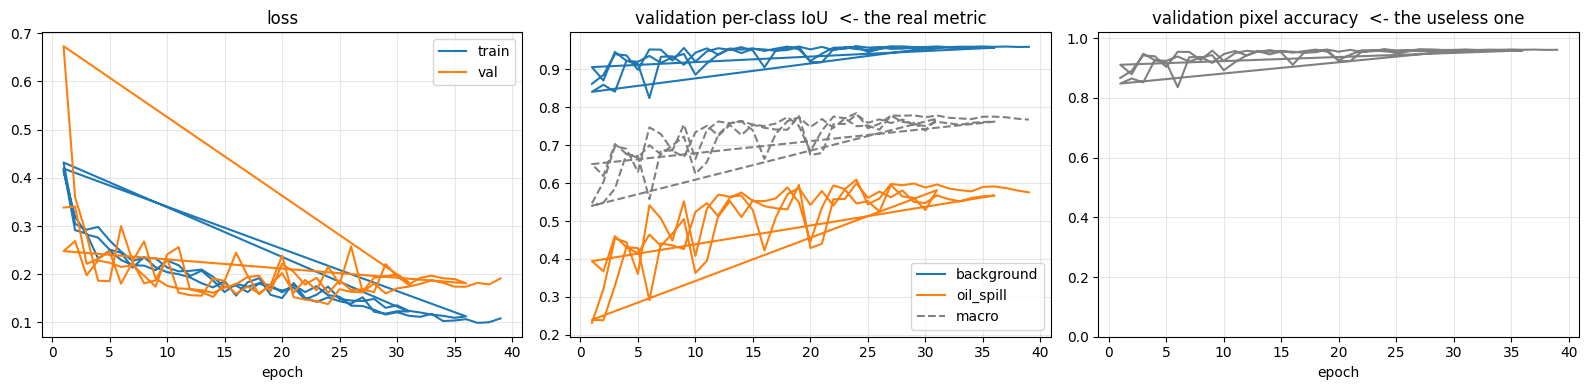

fresh-instance checkpoint load: OK — identical logits

checkpoint contract: PASS
      output_shape: [16, 2, 256, 256]
  OK  output_shape_is_B_2_H_W: True
  OK  fresh_instance_logits_match: True
  OK  class_map_is_0_background_1_oil: True
  OK  normalisation_metadata_present: True
  -> science/weights/checkpoint_contract.json
HEARTBEAT validation batch 1/23
HEARTBEAT validation batch 10/23
HEARTBEAT validation batch 20/23

FINAL VALIDATION
{
  "iou_background": 0.9603,
  "dice_background": 0.9797,
  "iou_oil_spill": 0.5965,
  "dice_oil_spill": 0.7472,
  "macro_iou": 0.7784,
  "macro_dice": 0.8635,
  "pixel_acc": 0.9625,
  "loss": 0.1744
}


In [32]:
if TRAINING_LOOP_EXECUTED:
    fig, ax = plt.subplots(1, 3, figsize=(16, 4))
    ax[0].plot(HIST.epoch, HIST.train_loss, label="train")
    ax[0].plot(HIST.epoch, HIST.val_loss, label="val")
    ax[0].set_title("loss"); ax[0].legend(); ax[0].grid(alpha=.3); ax[0].set_xlabel("epoch")
    for c in CLASS_NAMES:
        if f"val_iou_{c}" in HIST:
            ax[1].plot(HIST.epoch, HIST[f"val_iou_{c}"], label=c)
    ax[1].plot(HIST.epoch, HIST.val_macro_iou, "--", color="grey", label="macro")
    ax[1].set_title("validation per-class IoU  <- the real metric")
    ax[1].legend(); ax[1].grid(alpha=.3)
    ax[2].plot(HIST.epoch, HIST.val_pixel_acc, color="grey")
    ax[2].set_ylim(0, 1.02)
    ax[2].set_title("validation pixel accuracy  <- the useless one")
    ax[2].grid(alpha=.3); ax[2].set_xlabel("epoch")
    plt.tight_layout(); plt.savefig(OUTROOT / "training_curves.png", dpi=120, bbox_inches="tight")
    plt.show()

    _ck = torch.load(CKPT, map_location="cpu", weights_only=False)
    # CKPT is the best validation epoch, which may precede the final training epoch.
    model.load_state_dict(_ck["state_dict"], strict=True)
    model.eval()
    fresh = build_model()
    fresh.load_state_dict(_ck["state_dict"], strict=True)
    fresh.to(DEVICE).eval()

    # Pin the exact checkpoint used by every inference-only validation experiment.
    def _sha256_file(path, chunk_size=8 * 1024 * 1024):
        _h = hashlib.sha256()
        with Path(path).open("rb") as _fh:
            for _chunk in iter(lambda: _fh.read(chunk_size), b""):
                _h.update(_chunk)
        return _h.hexdigest()

    CHECKPOINT_SHA256 = _sha256_file(CKPT)
    CHECKPOINT_SIZE_BYTES = int(CKPT.stat().st_size)
    RUN_CARD["inference_checkpoint_lock"] = {
        "checkpoint_file": CKPT.name,
        "sha256": CHECKPOINT_SHA256,
        "size_bytes": CHECKPOINT_SIZE_BYTES,
        "selected_seed": RUN_CARD.get("checkpoint_selection", {}).get("selected_seed"),
        "verified_after_fresh_reload": True,
        "verified_before_validation": False,
        "verified_after_validation": False,
        "validation_checkpoint_unchanged": None,
        "test_audit_uses_same_frozen_checkpoint": True,
    }
    with torch.inference_mode():
        probe_x, _ = next(iter(val_dl))
        out_fresh = fresh(probe_x.to(DEVICE))
        out_live = model(probe_x.to(DEVICE))
    CKPT_LOAD_OK = bool(torch.allclose(out_fresh, out_live, atol=1e-4))
    print(f"fresh-instance checkpoint load: {'OK — identical logits' if CKPT_LOAD_OK else 'MISMATCH'}")

    _shape_ok = tuple(out_fresh.shape[1:2]) == (NUM_CLASSES,)
    _norm_meta = _ck.get("normalisation") or _ck.get("norm")
    CHECKPOINT_CONTRACT = {
        "schema": "tidetrace/checkpoint_contract/1",
        "weights_file": CKPT.name,
        "architecture": {"family": "smp.Unet", "encoder": _ck.get("encoder", CFG.encoder),
                         "encoder_weights_at_init": CFG.encoder_weights,
                         "in_channels": _ck.get("in_channels", CFG.in_channels)},
        "classes": {"num_classes": int(NUM_CLASSES), "names": list(CLASS_NAMES),
                    "oil_class": int(OIL_CLASS), "binary": bool(NUM_CLASSES == 2)},
        "input": {"channels": ["VV_dB", "VH_dB", "VV_minus_VH_dB"],
                  "band_order": {"VV": int(BAND_VV), "VH": int(BAND_VH)},
                  "tile_size": int(CFG.tile_size)},
        "normalisation": _norm_meta,
        "checkpoint_sha256": CHECKPOINT_SHA256,
        "checkpoint_size_bytes": CHECKPOINT_SIZE_BYTES,
        "verification": {
            "output_shape": list(out_fresh.shape),
            "output_shape_is_B_2_H_W": bool(_shape_ok and out_fresh.ndim == 4),
            "fresh_instance_logits_match": CKPT_LOAD_OK,
            "class_map_is_0_background_1_oil": bool(NUM_CLASSES == 2 and OIL_CLASS == 1),
            "normalisation_metadata_present": bool(_norm_meta is not None),
        },
        "verified_at": datetime.now(timezone.utc).isoformat(),
    }
    _fail = [k for k, v in CHECKPOINT_CONTRACT["verification"].items()
             if isinstance(v, bool) and not v]
    CHECKPOINT_CONTRACT["status"] = "PASS" if not _fail else f"FAILED: {_fail}"
    (WEIGHTS / "checkpoint_contract.json").write_text(json.dumps(CHECKPOINT_CONTRACT, indent=2))
    (OUTROOT / "checkpoint_contract.json").write_text(json.dumps(CHECKPOINT_CONTRACT, indent=2))
    RUN_CARD["checkpoint_contract"] = CHECKPOINT_CONTRACT
    print(f"\ncheckpoint contract: {CHECKPOINT_CONTRACT['status']}")
    for k, v in CHECKPOINT_CONTRACT["verification"].items():
        print(f"  {'OK ' if v is True else ('-- ' if v is False else '   ')} {k}: {v}")
    print("  -> science/weights/checkpoint_contract.json")
    if _fail:
        print("  !! checkpoint contract FAILED — Notebook 2 must not consume these weights.")
    assert CKPT_LOAD_OK, "checkpoint does not reproduce the trained model — Notebook 2 would be wrong"

    final_val = run_epoch(val_dl, False)
    UNET_METRICS = {**final_val, "best_val_oil_iou": round(float(best_oil), 4),
                    "epochs_run": int(len(HIST)), "batch_size": BATCH,
                    "train_tiles": int(len(train_ds)), "val_tiles": int(len(val_ds)),
                    "train_minutes": TRAIN_MINUTES, "device": DEVICE,
                    "selection_metric": "validation oil IoU",
                    "encoder_weights": CFG.encoder_weights,
                    "oil_weights_origin": "trained in this notebook run (no pre-trained oil model downloaded)"}
    RUN_CARD["unet"] = UNET_METRICS
    print("\nFINAL VALIDATION"); print(json.dumps(final_val, indent=2))
else:
    CKPT_LOAD_OK = False
    CHECKPOINT_SHA256 = None
    CHECKPOINT_SIZE_BYTES = None
    RUN_CARD["inference_checkpoint_lock"] = {
        "status": NOT_EXECUTED,
        "reason": "no fresh checkpoint was created in this run",
    }
    RUN_CARD["checkpoint_contract"] = {
        "schema": "tidetrace/checkpoint_contract/1",
        "status": NOT_EXECUTED,
        "reason": "coverage gate blocked training; no fresh checkpoint exists to validate",
    }
    print("fresh-checkpoint validation: NOT EXECUTED — coverage gate blocked training")


# E. Inference on crops, stitching, and polygon output

Crops are bounded U-Net inputs, so there is no full-scene model tensor. Candidate crops are generated from a recall-oriented CFAR proposal mask, while strict 150px regions remain a separate reporting threshold. The U-Net and negative-scene QA filter the extra proposals. A region wider than one crop is covered
by a half-overlapping grid and stitched back into **scene coordinates** before polygonising, so
the polygon is produced against the scene geospatial transform rather than a crop's.

`Coordinate` in `app/models.py` is **(lon, lat)** — longitude first — and `observed_polygon` is
capped at 2000 points. Simplification is progressive: it tightens the tolerance until the count
fits, rather than picking one tolerance and hoping. A hard-coded tolerance that works on the demo
scene fails on a larger slick at exactly the wrong moment.

In [33]:
# ======================= science/detect/segment.py =======================
@torch.inference_mode()
def _segment_crops_with_probabilities(unet, crops, norm, device=None, n_classes=None, batch_size=16,
                                      tta_mode="none"):
    """Internal inference helper safe to call directly from mining and audit code.

    TTA averages inverse-transformed softmax probabilities. The model is temporarily put in
    evaluation mode and its original training flag is restored even if inference raises.
    """
    device = device or ("cuda" if torch.cuda.is_available() else "cpu")
    n_classes = n_classes or NUM_CLASSES
    if not crops:
        return (np.zeros((0, 0, 0), np.uint8), np.zeros((0,), np.float32),
                np.zeros((0, int(n_classes), 0, 0), np.float16))
    batch_size = max(1, int(batch_size))
    tta_dims = {
        "none": (), "hflip": ((-1,),), "vflip": ((-2,),),
        "hvflip": ((-1,), (-2,), (-2, -1)),
    }
    if tta_mode not in tta_dims:
        raise ValueError(f"unsupported tta_mode={tta_mode!r}; expected one of {tuple(tta_dims)}")
    flip_transforms = ((),) + tuple(tta_dims[tta_mode])
    masks_out, confidence_out, probabilities_out = [], [], []
    _was_training = bool(getattr(unet, "training", False))
    unet.eval()
    try:
        for start in range(0, len(crops), batch_size):
            chunk = crops[start:start + batch_size]
            batch = torch.stack([
                torch.from_numpy(to_model_input(c["array"][..., 0], c["array"][..., 1], norm)).float()
                for c in chunk]).to(device)
            probability_sum = None
            for flip_dims in flip_transforms:
                transformed = torch.flip(batch, dims=flip_dims) if flip_dims else batch
                transformed_probs = torch.softmax(unet(transformed), dim=1)
                if flip_dims:
                    transformed_probs = torch.flip(transformed_probs, dims=flip_dims)
                probability_sum = transformed_probs if probability_sum is None else probability_sum + transformed_probs
                del transformed, transformed_probs
            probs = probability_sum / float(len(flip_transforms))
            probs_np = probs.detach().cpu().numpy()
            masks_out.append(probs_np.argmax(axis=1).astype(np.uint8))
            confidence_out.append(probs.max(dim=1).values.mean(dim=(1, 2)).detach().cpu().numpy())
            probabilities_out.append(probs_np.astype(np.float16))
            del batch, probs, probs_np, probability_sum
    finally:
        if _was_training:
            unet.train()
    return (np.concatenate(masks_out, axis=0), np.concatenate(confidence_out, axis=0),
            np.concatenate(probabilities_out, axis=0))


@torch.inference_mode()
def segment_crops(unet, crops, norm, device=None, n_classes=None, batch_size=16,
                  return_probabilities=False, tta_mode="none"):
    """U-Net inference; the default two-value return stays backward compatible."""
    masks, confidence, probabilities = _segment_crops_with_probabilities(
        unet, crops, norm, device, n_classes, batch_size, tta_mode)
    if return_probabilities:
        return masks, confidence, probabilities
    return masks, confidence


@torch.inference_mode()
def segment_crops_adaptive(unet, crops, full_image, norm, device=None, n_classes=None,
                           max_rounds=32, max_total_crops=900, border_fraction=0.005,
                           edge_probability_threshold=0.50, return_probabilities=False,
                           low_confidence_proposal_mask=None, low_confidence_edge_probability=0.30,
                           low_confidence_min_proposal_fraction=0.001, tta_mode="none"):
    """Expand only on one deterministic scene-global 50%-overlap grid.

    Every CFAR seed is snapped to the nearest global grid origin and duplicate seeds are merged.
    Every adaptive crop is selected from the same finite grid, whose origins are 0, stride,
    2*stride, ... plus the terminal edge origin. Thus seed and expansion crops cannot create
    translated lattices or exceed the number of unique scene positions. Neighbour proposals are
    triggered by confident oil probabilities (>= edge_probability_threshold) along crop edges.
    Ground truth is never accepted. `stopped_by` is always recorded for non-empty runs.

    Return contract is backward-compatible: four values by default, five with probabilities.
    """
    device = device or ("cuda" if torch.cuda.is_available() else "cpu")
    n_classes = n_classes or NUM_CLASSES
    if not crops:
        empty_log = [{"event": "stop", "stopped_by": "no_crops", "rounds_completed": 0,
                      "total_crops": 0, "adaptive_grid_positions": 0}]
        empty = (np.zeros((0, 0, 0), np.uint8), [], np.zeros((0,), np.float32), empty_log)
        if return_probabilities:
            return empty + (np.zeros((0, int(n_classes), 0, 0), np.float16),)
        return empty

    image = np.asarray(full_image)
    low_conf_mask = None
    if low_confidence_proposal_mask is not None:
        low_conf_mask = np.asarray(low_confidence_proposal_mask, dtype=bool)
        if low_conf_mask.shape != image.shape[:2]:
            raise ValueError("low_confidence_proposal_mask must match full_image spatial shape")
        if not 0.0 < float(low_confidence_edge_probability) <= float(edge_probability_threshold):
            raise ValueError("low-confidence edge probability must be positive and no greater than the standard trigger")
        if not 0.0 <= float(low_confidence_min_proposal_fraction) <= 1.0:
            raise ValueError("low_confidence_min_proposal_fraction must be in [0,1]")
    if image.ndim != 3:
        raise ValueError("full_image must be HxWxC")
    H, W = image.shape[:2]
    size = int(crops[0]["array"].shape[0])
    if size <= 0 or any(np.asarray(c["array"]).shape[:2] != (size, size) for c in crops):
        raise ValueError("all seed crops must be square and share one crop size")
    if H < size or W < size:
        raise ValueError(f"scene {(H, W)} is smaller than crop size {size}")
    requested_max_total_crops = int(max_total_crops)
    max_rounds = int(max_rounds)
    if requested_max_total_crops < 1 or max_rounds < 1:
        raise ValueError("max_total_crops and max_rounds must be positive")

    stride = max(1, size // 2)
    def _global_axis_origins(length):
        terminal = int(length) - size
        values = list(range(0, terminal + 1, stride))
        if not values or values[-1] != terminal:
            values.append(terminal)
        return np.asarray(sorted(set(int(v) for v in values)), dtype=np.int32)

    grid_rows = _global_axis_origins(H)
    grid_cols = _global_axis_origins(W)
    grid_positions = {(int(r), int(c)) for r in grid_rows for c in grid_cols}
    max_total_crops = min(requested_max_total_crops, len(grid_positions))

    raw_seed_crop_count = len(crops)
    # Snap CFAR seeds onto the predeclared scene lattice and merge duplicates before inference.
    # This also makes the effective crop cap a hard upper bound on unique scene positions.
    seed_by_origin = {}
    for crop in crops:
        original_origin = tuple(map(int, crop["origin"]))
        ri = int(np.argmin(np.abs(grid_rows - original_origin[0])))
        ci = int(np.argmin(np.abs(grid_cols - original_origin[1])))
        snapped_origin = (int(grid_rows[ri]), int(grid_cols[ci]))
        normalized = dict(crop)
        normalized["origin"] = snapped_origin
        normalized["array"] = image[snapped_origin[0]:snapped_origin[0]+size,
                                     snapped_origin[1]:snapped_origin[1]+size]
        if np.asarray(normalized["array"]).shape[:2] != (size, size):
            raise ValueError(f"snapped seed crop {snapped_origin} is outside the scene")
        normalized["seed_original_origins"] = [list(original_origin)]
        normalized["seed_grid_snapped"] = bool(snapped_origin != original_origin)
        normalized["adaptive_grid_policy"] = "scene_global_half_overlap_v1"
        previous = seed_by_origin.get(snapped_origin)
        if previous is None:
            seed_by_origin[snapped_origin] = normalized
        else:
            previous["seed_original_origins"].extend(normalized["seed_original_origins"])
            previous["seed_grid_snapped"] = bool(previous["seed_grid_snapped"] or normalized["seed_grid_snapped"])
            if int(normalized.get("area_px", 0)) > int(previous.get("area_px", 0)):
                normalized["seed_original_origins"] = previous["seed_original_origins"]
                normalized["seed_grid_snapped"] = previous["seed_grid_snapped"]
                seed_by_origin[snapped_origin] = normalized
    all_candidates = [seed_by_origin[key] for key in sorted(seed_by_origin)]
    initial_candidate_count = len(all_candidates)
    seed_crops_deduplicated = int(raw_seed_crop_count - initial_candidate_count)
    initial_crop_cap_hit = initial_candidate_count > max_total_crops
    if initial_crop_cap_hit:
        # Deterministic farthest-point sampling prevents a seed-only overflow from becoming
        # a top-left bias. This event remains an explicit crop-cap failure signal.
        coords = np.asarray([
            (float(c["origin"][0]) + size / 2.0, float(c["origin"][1]) + size / 2.0)
            for c in all_candidates], dtype=np.float32)
        scene_center = np.asarray([H / 2.0, W / 2.0], dtype=np.float32)
        first = int(np.argmin(np.sum((coords - scene_center[None, :]) ** 2, axis=1)))
        selected_indices = [first]
        min_distance_sq = np.sum((coords - coords[first][None, :]) ** 2, axis=1)
        min_distance_sq[first] = -1.0
        while len(selected_indices) < max_total_crops:
            next_index = int(np.argmax(min_distance_sq))
            if min_distance_sq[next_index] < 0:
                break
            selected_indices.append(next_index)
            distance_sq = np.sum((coords - coords[next_index][None, :]) ** 2, axis=1)
            min_distance_sq = np.minimum(min_distance_sq, distance_sq)
            min_distance_sq[selected_indices] = -1.0
        selected_indices = sorted(selected_indices)
        all_crops = [all_candidates[i] for i in selected_indices]
    else:
        all_crops = all_candidates

    seen = {tuple(map(int, c["origin"])) for c in all_crops}
    masks, conf, probability_maps = _segment_crops_with_probabilities(
        unet, all_crops, norm, device, n_classes, tta_mode=tta_mode)
    expansion_log = [{
        "event": "grid", "policy": "scene_global_half_overlap_v1",
        "stride_px": int(stride), "grid_rows": grid_rows.tolist(),
        "grid_cols": grid_cols.tolist(), "adaptive_grid_positions": int(len(grid_positions)),
        "seed_crops_input": int(raw_seed_crop_count),
        "seed_crops_unique_after_grid_snap": int(initial_candidate_count),
        "seed_crops_deduplicated": int(seed_crops_deduplicated),
        "seed_crops_retained": int(len(all_crops)),
        "requested_max_total_crops": int(requested_max_total_crops),
        "effective_max_total_crops": int(max_total_crops),
        "edge_probability_threshold": float(edge_probability_threshold),
        "low_confidence_edge_probability": (float(low_confidence_edge_probability) if low_conf_mask is not None else None),
        "low_confidence_proposal_enabled": bool(low_conf_mask is not None),
        "tta_mode": str(tta_mode),
    }]
    if initial_crop_cap_hit:
        expansion_log.append({"event": "initial_crop_cap", "input_crops": int(initial_candidate_count),
                              "retained_crops": int(len(all_crops)),
                              "selection": "deterministic_farthest_point"})

    initial_seed_retained_count = int(len(all_crops))
    edge_min = max(4, int(round(size * float(border_fraction))))
    stop_reason = "crop_cap" if initial_crop_cap_hit else "converged"
    rounds_completed = 0
    adaptive_grid_seen = set()
    if not initial_crop_cap_hit:
        for round_index in range(1, max_rounds + 1):
            # Evaluate the current frontier even when the crop count exactly equals the cap.
            # A scene that has converged at the cap is not a crop-cap failure; only additional
            # eligible grid proposals that cannot be served should produce stopped_by=crop_cap.
            proposal_strength = {}
            low_confidence_crops_this_round = 0
            edge_triggered_any = False
            for crop, probs in zip(all_crops, probability_maps):
                if probs.shape[0] <= 1:
                    continue
                crop_threshold = float(edge_probability_threshold)
                if low_conf_mask is not None:
                    rr, cc = map(int, crop["origin"])
                    _proposal_patch = low_conf_mask[rr:rr + size, cc:cc + size]
                    _proposal_fraction = float(_proposal_patch.mean()) if _proposal_patch.size else 0.0
                    if _proposal_fraction >= float(low_confidence_min_proposal_fraction):
                        crop_threshold = float(low_confidence_edge_probability)
                        low_confidence_crops_this_round += 1
                oil_probability = np.asarray(probs[int(OIL_CLASS)], dtype=np.float32)
                if oil_probability.size == 0:
                    continue
                top_vals = oil_probability[0, :]
                bottom_vals = oil_probability[-1, :]
                left_vals = oil_probability[:, 0]
                right_vals = oil_probability[:, -1]
                top_count = int(np.count_nonzero(top_vals >= crop_threshold))
                bottom_count = int(np.count_nonzero(bottom_vals >= crop_threshold))
                left_count = int(np.count_nonzero(left_vals >= crop_threshold))
                right_count = int(np.count_nonzero(right_vals >= crop_threshold))
                top = top_count >= edge_min
                bottom = bottom_count >= edge_min
                left = left_count >= edge_min
                right = right_count >= edge_min
                if not (top or bottom or left or right):
                    continue
                edge_triggered_any = True

                r0, c0 = map(int, crop["origin"])
                ri = int(np.argmin(np.abs(grid_rows - r0)))
                ci = int(np.argmin(np.abs(grid_cols - c0)))
                row_steps = ([-1] if top else []) + ([1] if bottom else [])
                col_steps = ([-1] if left else []) + ([1] if right else [])
                neighbours = set()
                neighbours.update((ri + dr, ci) for dr in row_steps)
                neighbours.update((ri, ci + dc) for dc in col_steps)
                neighbours.update((ri + dr, ci + dc) for dr in row_steps for dc in col_steps)
                edge_strength = max(top_count, bottom_count, left_count, right_count) / float(size)
                for nr_i, nc_i in neighbours:
                    if not (0 <= nr_i < len(grid_rows) and 0 <= nc_i < len(grid_cols)):
                        continue
                    origin = (int(grid_rows[nr_i]), int(grid_cols[nc_i]))
                    if origin in seen:
                        continue
                    if image[origin[0]:origin[0] + size, origin[1]:origin[1] + size].shape[:2] != (size, size):
                        continue
                    proposal_strength[origin] = max(proposal_strength.get(origin, 0.0), float(edge_strength))

            if not proposal_strength:
                stop_reason = ("grid_exhausted" if edge_triggered_any
                               and len(seen) >= len(grid_positions) else "converged")
                break

            room = max_total_crops - len(all_crops)
            if room <= 0:
                stop_reason = "crop_cap"
                break
            ordered = sorted(proposal_strength, key=lambda origin: (-proposal_strength[origin], origin[0], origin[1]))
            if len(ordered) > room:
                ordered = ordered[:room]
                stop_reason = "crop_cap"
            else:
                stop_reason = "converged"

            new_crops = []
            for origin in ordered:
                r0, c0 = origin
                seen.add(origin)
                adaptive_grid_seen.add(origin)
                new_crops.append({"origin": origin,
                                  "array": image[r0:r0 + size, c0:c0 + size],
                                  "region_label": -1, "area_px": 0,
                                  "bbox": (r0, r0 + size, c0, c0 + size),
                                  "adaptive_expansion": True,
                                  "expansion_round": round_index,
                                  "adaptive_grid_policy": "scene_global_half_overlap_v1"})
            if not new_crops:
                stop_reason = "converged"
                break
            new_masks, new_conf, new_probs = _segment_crops_with_probabilities(
                unet, new_crops, norm, device, n_classes, tta_mode=tta_mode)
            all_crops.extend(new_crops)
            masks = np.concatenate([masks, new_masks], axis=0)
            conf = np.concatenate([conf, new_conf], axis=0)
            probability_maps = np.concatenate([probability_maps, new_probs], axis=0)
            rounds_completed = round_index
            expansion_log.append({"event": "round", "round": int(round_index),
                                  "new_crops": int(len(new_crops)),
                                  "total_crops": int(len(all_crops)),
                                  "origins": [list(c["origin"]) for c in new_crops],
                                  "grid_positions_used": int(len(adaptive_grid_seen)),
                                  "low_confidence_crops_this_round": int(low_confidence_crops_this_round),
                                  "tta_mode": str(tta_mode)})
            if stop_reason == "crop_cap":
                break
        else:
            stop_reason = "round_cap"

    expansion_log.append({"event": "stop", "stopped_by": stop_reason,
                          "rounds_completed": int(rounds_completed),
                          "total_crops": int(len(all_crops)),
                          "seed_crops_input": int(raw_seed_crop_count),
                          "seed_crops_unique_after_grid_snap": int(initial_candidate_count),
                          "seed_crops_deduplicated": int(seed_crops_deduplicated),
                          "seed_crops_retained": int(initial_seed_retained_count),
                          "adaptive_grid_positions": int(len(grid_positions)),
                          "adaptive_grid_positions_used": int(len(adaptive_grid_seen)),
                          "scene_grid_positions_seen": int(len(seen)),
                          "scene_grid_positions_remaining": int(max(0, len(grid_positions) - len(seen))),
                          "requested_max_total_crops": int(requested_max_total_crops),
                          "effective_max_total_crops": int(max_total_crops),
                          "max_rounds": int(max_rounds), "max_total_crops": int(max_total_crops),
                          "edge_probability_threshold": float(edge_probability_threshold),
                          "low_confidence_edge_probability": (float(low_confidence_edge_probability) if low_conf_mask is not None else None),
                          "low_confidence_proposal_enabled": bool(low_conf_mask is not None),
                          "tta_mode": str(tta_mode),
                          "grid_policy": "scene_global_half_overlap_v1"})
    result = (masks, all_crops, conf, expansion_log)
    if return_probabilities:
        return result + (probability_maps,)
    return result

def aggregate_adaptive_stop_reason(expansion_log):
    """Collapse per-crop-size stop logs without hiding expansion safety failures."""
    stops = [str(item.get("stopped_by")) for item in (expansion_log or [])
             if item.get("event") == "stop"]
    for status in ("crop_cap", "grid_exhausted", "round_cap"):
        if status in stops:
            return status
    return "converged" if stops else "no_crops"


# ======================= end segment.py =======================


# ======================= science/detect/postprocess.py =======================
from rasterio.features import shapes as rio_shapes
from rasterio.transform import Affine
import rasterio.warp
from shapely.geometry import shape as shp_shape, Polygon, mapping as shp_mapping


def mask_to_polygon(mask, transform_affine, oil_class=1, max_points=1800, src_crs=None):
    """Largest contiguous oil polygon as (lon, lat) tuples, guaranteed under the point cap.

    Two things beyond the guide listing, both required for correctness:
      * escalating simplification with a hard decimation backstop, so the cap cannot be exceeded
      * CRS reprojection — the Zenodo scenes are UTM and Coordinate is lon/lat degrees. Posting
        projected metres as 'lon' is a silent, catastrophic bug.
    """
    polys = [shp_shape(g) for g, v in rio_shapes(np.asarray(mask).astype("uint8"),
                                                 transform=transform_affine) if int(v) == oil_class]
    if not polys:
        return None
    merged = max(polys, key=lambda p: p.area)
    step = max(abs(transform_affine.a), 1e-6) * 0.25 if transform_affine is not None else 2e-4
    tol = 0.0
    while len(merged.exterior.coords) > max_points and tol < step * 400:
        tol += step
        merged = merged.simplify(tol, preserve_topology=True)
    if len(merged.exterior.coords) > max_points:
        coords = list(merged.exterior.coords)
        coords = coords[::int(np.ceil(len(coords) / max_points))]
        if coords[0] != coords[-1]:
            coords.append(coords[0])
        merged = Polygon(coords)
    xs, ys = np.array(merged.exterior.coords).T
    if src_crs is not None and getattr(src_crs, "to_epsg", lambda: None)() != 4326:
        xs, ys = rasterio.warp.transform(src_crs, "EPSG:4326", xs.tolist(), ys.tolist())
        xs, ys = np.asarray(xs), np.asarray(ys)
    return [(round(float(x), 6), round(float(y), 6)) for x, y in zip(xs, ys)]


def polygon_area_km2(lonlat):
    if not lonlat or len(lonlat) < 4:
        return 0.0
    lon = np.array([p[0] for p in lonlat]); lat = np.array([p[1] for p in lonlat])
    lat0 = np.deg2rad(lat.mean())
    x = np.deg2rad(lon - lon.mean()) * 6371.0088 * np.cos(lat0)
    y = np.deg2rad(lat - lat.mean()) * 6371.0088
    return float(abs(0.5 * np.sum(x[:-1] * y[1:] - x[1:] * y[:-1])))


def polygon_centroid(lonlat):
    p = Polygon(lonlat)
    return (round(float(p.centroid.x), 6), round(float(p.centroid.y), 6))
# ======================= end postprocess.py =======================
print("segment + postprocess defined")

segment + postprocess defined


### E2E diagnostic interpretation

The validation-split pipeline diagnostics are for stage attribution and engineering analysis only. They do not tune parameters automatically, change CFAR thresholds/PFA, modify normalization, or use ground truth as model input. Any tuning must be performed using the validation split and re-evaluated without touching the held-out TEST split. The post-freeze TEST scene evaluation below runs once and is report-only.


STAGE_START validation_gate_and_optional_final_post_freeze_test_audit

VALIDATION INFERENCE VARIANT: baseline_256
  [VAL 1/26] 8253899__lookalike_13        crops=21  coverage=None  crop-recall=None  stitched-recall=None  stop=converged
  [VAL 2/26] 8253899__lookalike_162       crops=0  coverage=None  crop-recall=None  stitched-recall=None  stop=no_crops
  [VAL 3/26] 8253899__lookalike_305       crops=5  coverage=None  crop-recall=None  stitched-recall=None  stop=converged
  [VAL 4/26] 8253899__lookalike_389       crops=7  coverage=None  crop-recall=None  stitched-recall=None  stop=converged
  [VAL 5/26] 8253899__lookalike_428       crops=65  coverage=None  crop-recall=None  stitched-recall=None  stop=converged
  [VAL 6/26] 8253899__lookalike_598       crops=28  coverage=None  crop-recall=None  stitched-recall=None  stop=converged
  [VAL 7/26] 8253899__lookalike_668       crops=8  coverage=None  crop-recall=None  stitched-recall=None  stop=converged
  [VAL 8/26] 8253899__no_oil_133     

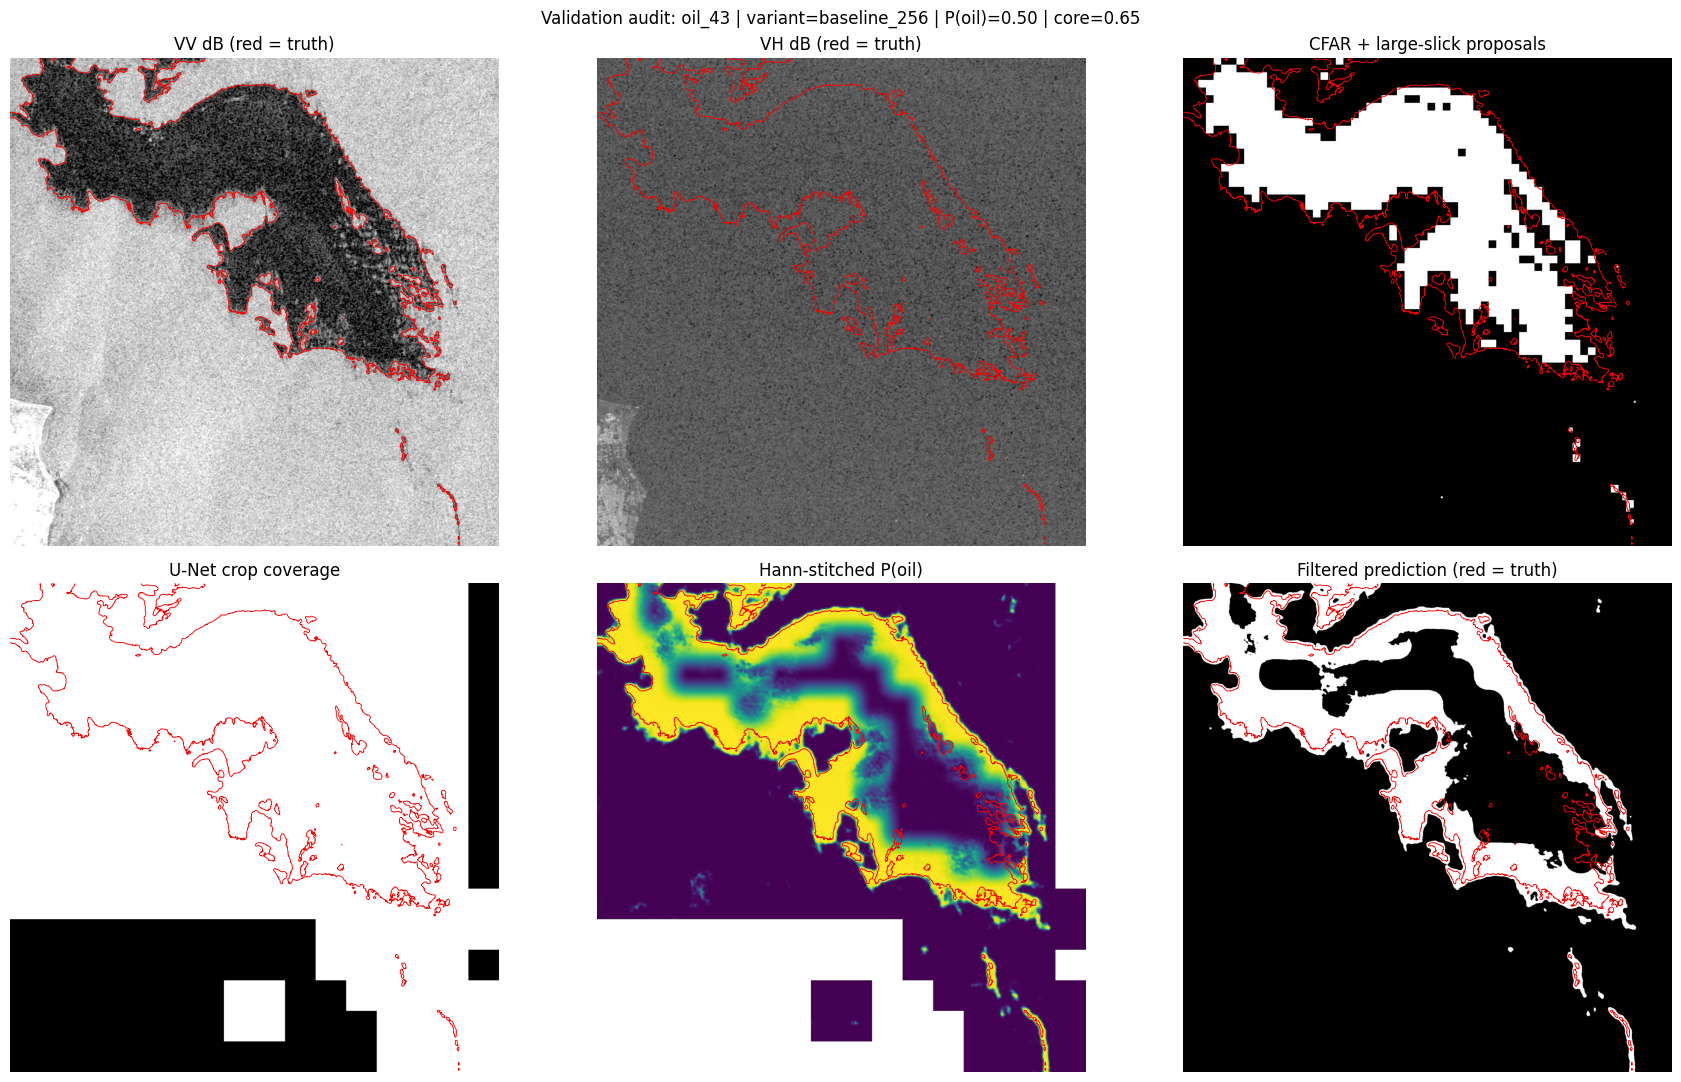

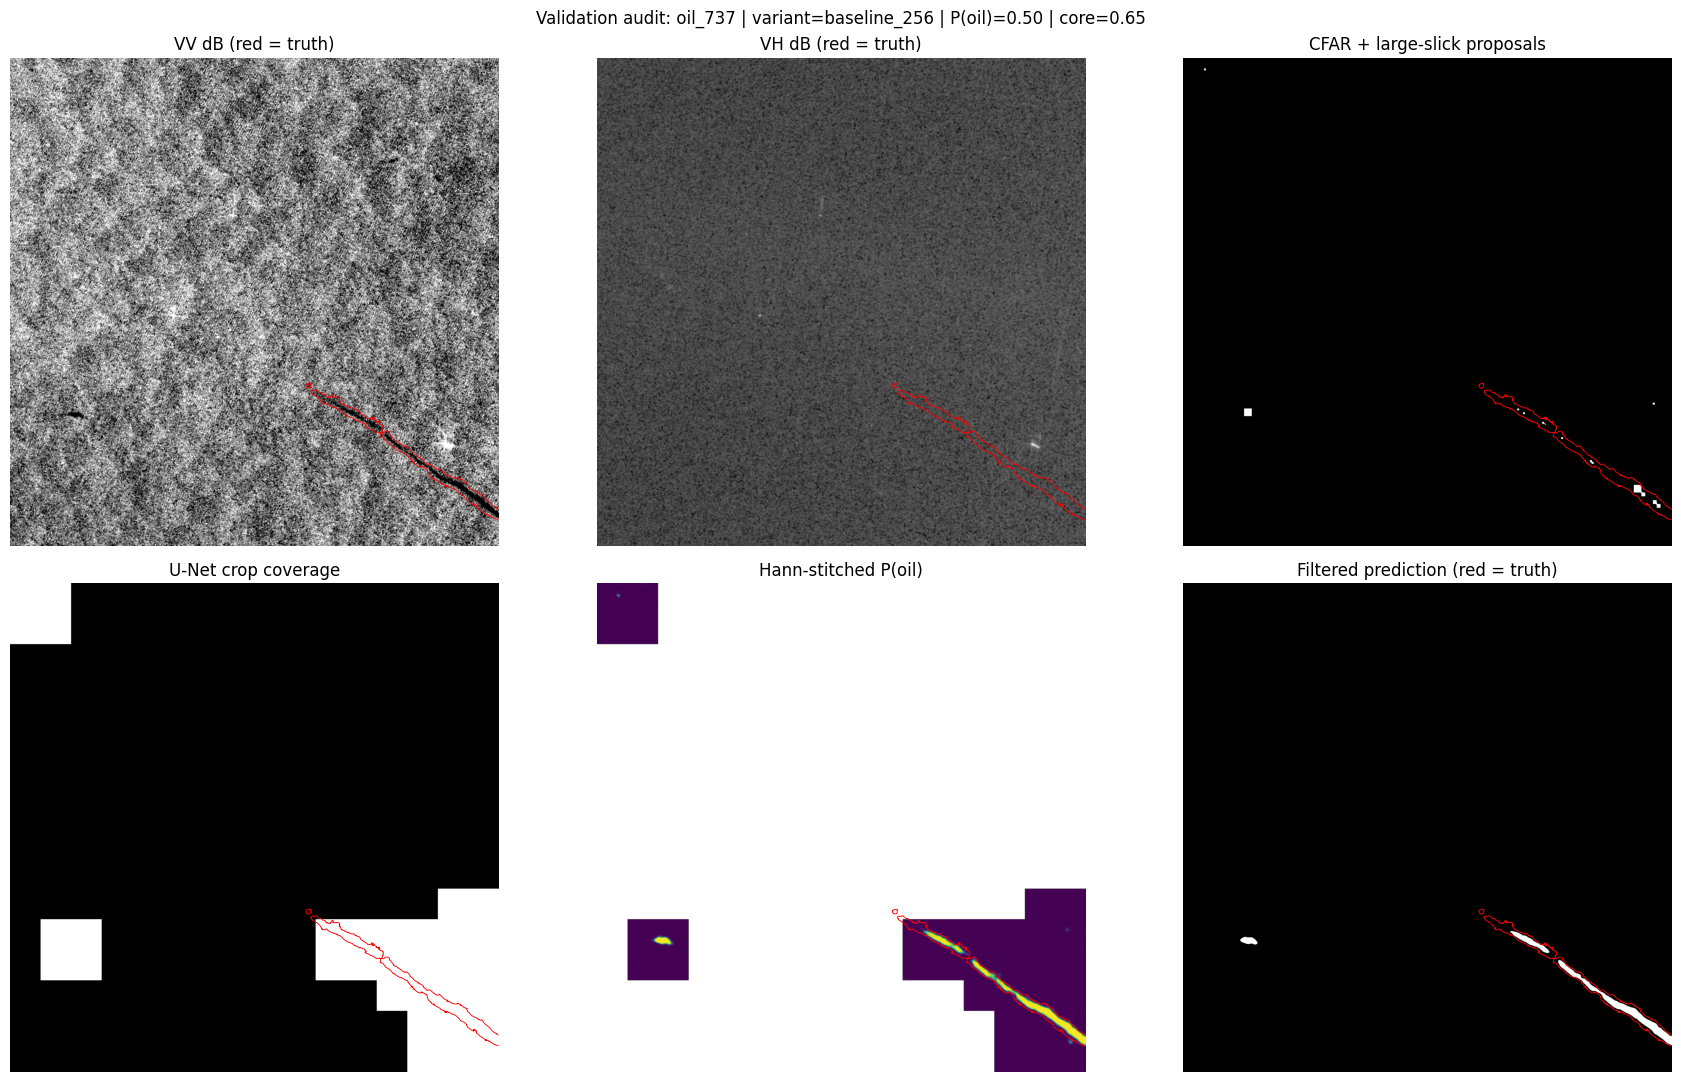

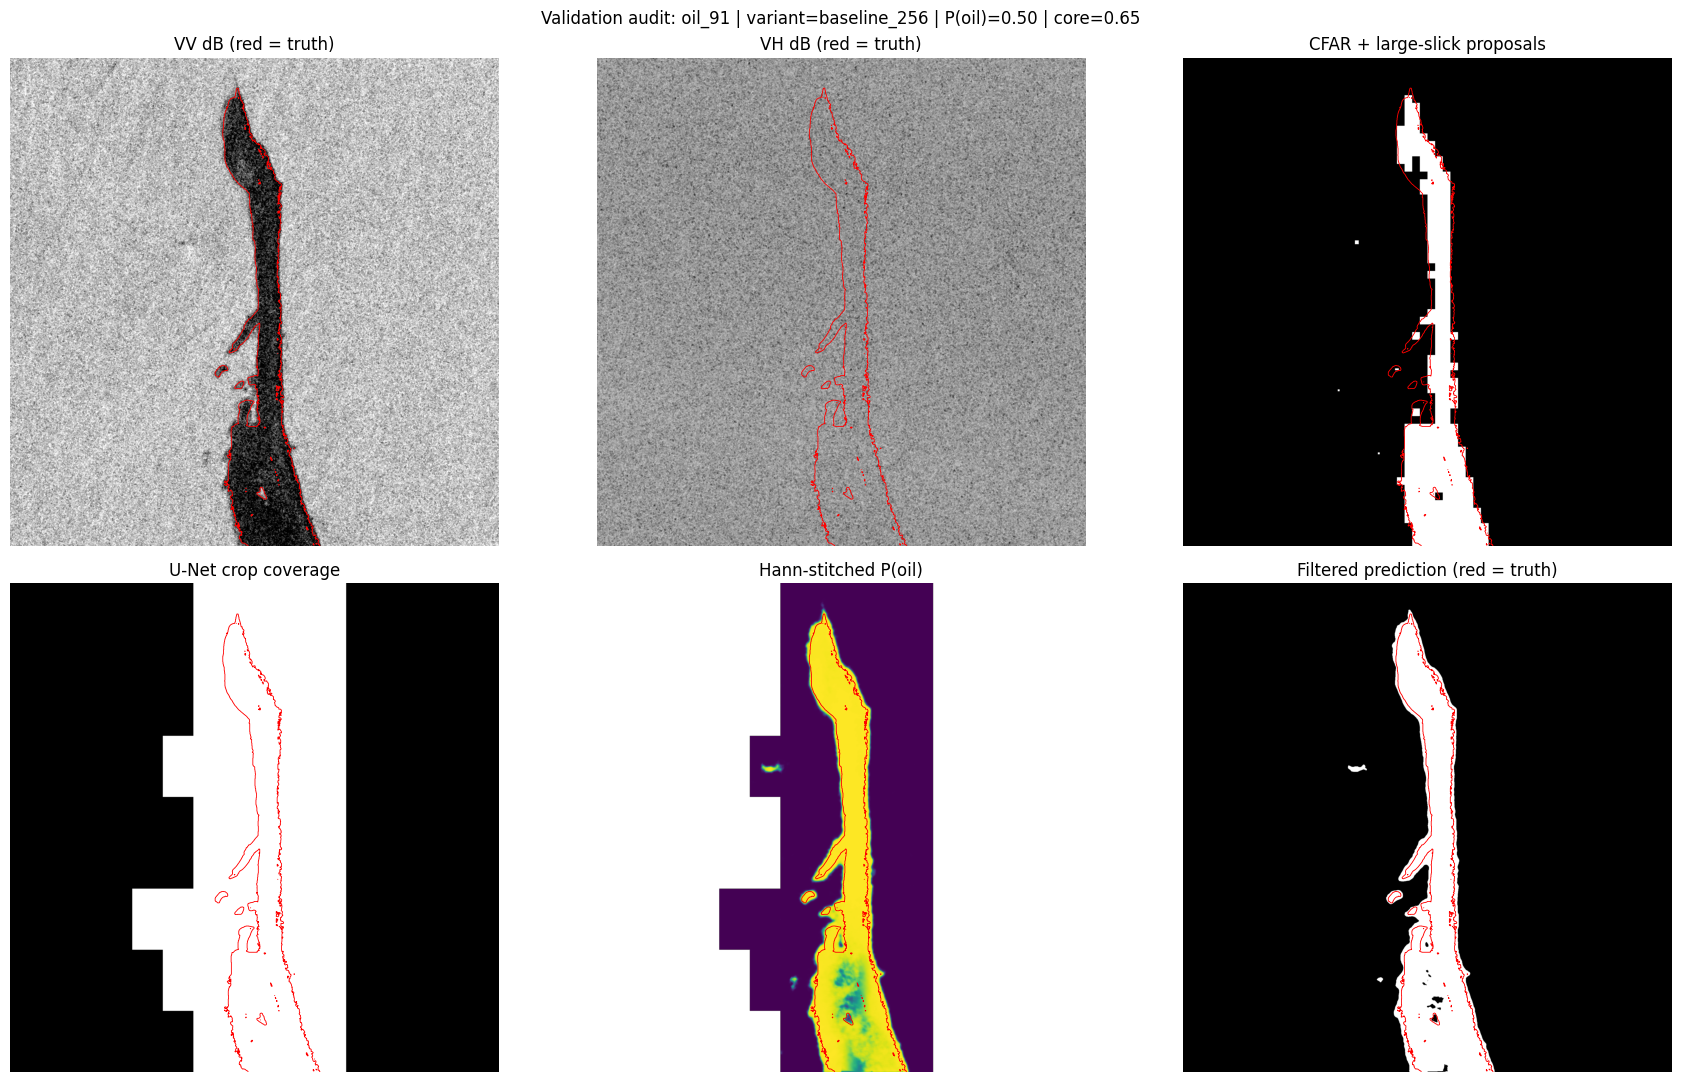


VALIDATION PIPELINE DIAGNOSTICS (selected predeclared variant; tuning-surface only)
  selected variant=baseline_256 | TTA=none | core=0.65 | threshold=0.50
  selected-variant scenes=26 / 26; crop diagnostics=757; component diagnostics=590


,scene_id,scene_key,split,category,cfar_candidate_present,n_crops,adaptive_expansion_crops,adaptive_expansion_rounds,adaptive_expansion_stopped_by,adaptive_expansion_max_rounds,...,valid_ground_truth_oil_px,oil_iou,oil_dice,quality_tp_pixels,quality_fp_pixels,quality_fn_pixels,quality_valid_truth_pixels,quality_valid_background_pixels,quality_false_negative_fraction,quality_false_positive_fraction
0,8253899__lookalike_13,8253899__lookalike_13,val,lookalike,True,21,14,2,converged,32,...,0,0.000000,0.000000,0,2265,0,0,4194304,NaN,0.000540
1,8253899__lookalike_162,8253899__lookalike_162,val,lookalike,False,0,0,0,no_crops,32,...,0,NaN,NaN,0,0,0,0,4194304,NaN,0.000000
2,8253899__lookalike_305,8253899__lookalike_305,val,lookalike,True,5,0,0,converged,32,...,0,NaN,NaN,0,0,0,0,4194304,NaN,0.000000
3,8253899__lookalike_389,8253899__lookalike_389,val,lookalike,True,7,1,1,converged,32,...,0,0.000000,0.000000,0,4315,0,0,4194304,NaN,0.001029
4,8253899__lookalike_428,8253899__lookalike_428,val,lookalike,True,65,26,3,converged,32,...,0,0.000000,0.000000,0,51699,0,0,4194304,NaN,0.012326
5,8253899__lookalike_598,8253899__lookalike_598,val,lookalike,True,28,0,0,converged,32,...,0,NaN,NaN,0,0,0,0,4080404,NaN,0.000000
6,8253899__lookalike_668,8253899__lookalike_668,val,lookalike,True,8,0,0,converged,32,...,0,NaN,NaN,0,0,0,0,4194304,NaN,0.000000
7,8253899__no_oil_133,8253899__no_oil_133,val,no_oil,True,2,0,0,converged,32,...,0,0.000000,0.000000,0,221,0,0,4194304,NaN,0.000053
8,8253899__no_oil_24,8253899__no_oil_24,val,no_oil,True,4,0,0,converged,32,...,0,0.000000,0.000000,0,583,0,0,4194304,NaN,0.000139
9,8253899__no_oil_266,8253899__no_oil_266,val,no_oil,True,18,0,0,converged,32,...,0,NaN,NaN,0,0,0,0,4194302,NaN,0.000000


,scene_id,split,category,crop_index,crop_size_px,adaptive_expansion,expansion_round,region_label,origin_row,origin_col,height,width,valid_truth_px,predicted_oil_px,predicted_oil_border_px,tp_px,fp_px,fn_px,crop_iou,crop_recall
0,8253899__lookalike_13,val,lookalike,1,256,False,0,1,128,1280,256,256,0,0,0,0,0,0,NaN,NaN
1,8253899__lookalike_13,val,lookalike,2,256,False,0,2,768,1280,256,256,0,1334,83,0,1334,0,0.0,NaN
2,8253899__lookalike_13,val,lookalike,3,256,False,0,3,1152,1536,256,256,0,3375,19,0,3375,0,0.0,NaN
3,8253899__lookalike_13,val,lookalike,4,256,False,0,4,1280,1536,256,256,0,5618,172,0,5618,0,0.0,NaN
4,8253899__lookalike_13,val,lookalike,5,256,False,0,5,1280,1664,256,256,0,3573,131,0,3573,0,0.0,NaN
5,8253899__lookalike_13,val,lookalike,6,256,False,0,6,1536,1024,256,256,0,0,0,0,0,0,NaN,NaN
6,8253899__lookalike_13,val,lookalike,7,256,False,0,7,1536,1792,256,256,0,2607,75,0,2607,0,0.0,NaN
7,8253899__lookalike_13,val,lookalike,8,256,True,1,-1,1408,1536,256,256,0,1504,81,0,1504,0,0.0,NaN
8,8253899__lookalike_13,val,lookalike,9,256,True,1,-1,1408,1664,256,256,0,436,26,0,436,0,0.0,NaN
9,8253899__lookalike_13,val,lookalike,10,256,True,1,-1,1280,1408,256,256,0,3959,102,0,3959,0,0.0,NaN


category is_truth_overlapping_component area_px                  \
                                              count  median     max   
0  lookalike                          False     200   435.0   10888   
1     no_oil                          False       8   404.0     583   
2        oil                          False     184   165.5    1628   
3        oil                           True     198  3076.5  914946   

  max_oil_probability                     p90_oil_probability            \
                count    median       max               count    median   
0                 200  0.868165  0.996296                 200  0.814132   
1                   8  0.927246  0.984375                   8  0.914795   
2                 184  0.781738  0.999512                 184  0.745285   
3                 198  0.994062  1.000000                 198  0.986218   

            proposal_support_fraction                      
        max                     count    median       max  
0  0.993652                       200  0.000000  1.000000  
1  0.977051                         8  0.830072  0.982301  
2  0.999023                       184  0.000000  0.879310  
3  0.999977                       198  0.182285  1.000000

VALIDATION CFAR GATE: {
  "status": "PASS",
  "split": "val",
  "window_size": 1024,
  "source_negative_scenes": 14,
  "eligible_complete_scenes": 13,
  "excluded_scenes": 1,
  "minimum_eligible_scenes_required": 5,
  "sampling_method": "four non-overlapping 1024x1024 quadrants per eligible scene",
  "sampling_exclusions": [
    {
      "scene_id": "8253899__lookalike_598",
      "status": "EXCLUDED",
      "accepted_quadrants": 3,
      "missing_quadrants": [
        "NE"
      ],
      "reason": "INSUFFICIENT_VALID_QUADRANTS"
    }
  ],
  "scenes_required": 13,
  "scenes_evaluated": 13,
  "windows_evaluated": 52,
  "windows_per_scene": {
    "8253899__no_oil_24": 4,
    "8253899__lookalike_162": 4,
    "8253899__lookalike_668": 4,
    "8253899__no_oil_565": 4,
    "8253899__no_oil_628": 4,
    "8253899__no_oil_266": 4,
    "8253899__no_oil_461": 4,
    "8253899__no_oil_349": 4,
    "8253899__lookalike_13": 4,
    "8253899__lookalike_389": 4,
    "8253899__lookalike_428": 4,
    "8253

,scene_id,scene_key,split,category,cfar_candidate_present,n_crops,adaptive_expansion_crops,adaptive_expansion_rounds,adaptive_expansion_stopped_by,adaptive_expansion_max_rounds,...,valid_ground_truth_oil_px,oil_iou,oil_dice,quality_tp_pixels,quality_fp_pixels,quality_fn_pixels,quality_valid_truth_pixels,quality_valid_background_pixels,quality_false_negative_fraction,quality_false_positive_fraction
0,8253899__lookalike_13,8253899__lookalike_13,val,lookalike,True,21,14,2,converged,32,...,0,0.000000,0.000000,0,2265,0,0,4194304,NaN,0.000540
1,8253899__lookalike_162,8253899__lookalike_162,val,lookalike,False,0,0,0,no_crops,32,...,0,NaN,NaN,0,0,0,0,4194304,NaN,0.000000
2,8253899__lookalike_305,8253899__lookalike_305,val,lookalike,True,5,0,0,converged,32,...,0,NaN,NaN,0,0,0,0,4194304,NaN,0.000000
3,8253899__lookalike_389,8253899__lookalike_389,val,lookalike,True,7,1,1,converged,32,...,0,0.000000,0.000000,0,4315,0,0,4194304,NaN,0.001029
4,8253899__lookalike_428,8253899__lookalike_428,val,lookalike,True,65,26,3,converged,32,...,0,0.000000,0.000000,0,51699,0,0,4194304,NaN,0.012326
5,8253899__lookalike_598,8253899__lookalike_598,val,lookalike,True,28,0,0,converged,32,...,0,NaN,NaN,0,0,0,0,4080404,NaN,0.000000
6,8253899__lookalike_668,8253899__lookalike_668,val,lookalike,True,8,0,0,converged,32,...,0,NaN,NaN,0,0,0,0,4194304,NaN,0.000000
7,8253899__no_oil_133,8253899__no_oil_133,val,no_oil,True,2,0,0,converged,32,...,0,0.000000,0.000000,0,221,0,0,4194304,NaN,0.000053
8,8253899__no_oil_24,8253899__no_oil_24,val,no_oil,True,4,0,0,converged,32,...,0,0.000000,0.000000,0,583,0,0,4194304,NaN,0.000139
9,8253899__no_oil_266,8253899__no_oil_266,val,no_oil,True,18,0,0,converged,32,...,0,NaN,NaN,0,0,0,0,4194302,NaN,0.000000


,scene_id,split,category,crop_index,crop_size_px,adaptive_expansion,expansion_round,region_label,origin_row,origin_col,height,width,valid_truth_px,predicted_oil_px,predicted_oil_border_px,tp_px,fp_px,fn_px,crop_iou,crop_recall
0,8253899__lookalike_13,val,lookalike,1,256,False,0,1,128,1280,256,256,0,0,0,0,0,0,NaN,NaN
1,8253899__lookalike_13,val,lookalike,2,256,False,0,2,768,1280,256,256,0,1334,83,0,1334,0,0.0,NaN
2,8253899__lookalike_13,val,lookalike,3,256,False,0,3,1152,1536,256,256,0,3375,19,0,3375,0,0.0,NaN
3,8253899__lookalike_13,val,lookalike,4,256,False,0,4,1280,1536,256,256,0,5618,172,0,5618,0,0.0,NaN
4,8253899__lookalike_13,val,lookalike,5,256,False,0,5,1280,1664,256,256,0,3573,131,0,3573,0,0.0,NaN
5,8253899__lookalike_13,val,lookalike,6,256,False,0,6,1536,1024,256,256,0,0,0,0,0,0,NaN,NaN
6,8253899__lookalike_13,val,lookalike,7,256,False,0,7,1536,1792,256,256,0,2607,75,0,2607,0,0.0,NaN
7,8253899__lookalike_13,val,lookalike,8,256,True,1,-1,1408,1536,256,256,0,1504,81,0,1504,0,0.0,NaN
8,8253899__lookalike_13,val,lookalike,9,256,True,1,-1,1408,1664,256,256,0,436,26,0,436,0,0.0,NaN
9,8253899__lookalike_13,val,lookalike,10,256,True,1,-1,1280,1408,256,256,0,3959,102,0,3959,0,0.0,NaN


TEST was not evaluated in this run; the post-freeze TEST audit remains disabled.
STAGE_END validation_gate_and_optional_final_post_freeze_test_audit seconds=831.07


In [34]:
with stage('validation_gate_and_optional_final_post_freeze_test_audit'):
    # ---------------------------------------------------------------- validation gate + explicitly enabled final TEST audit
    RUN_FINAL_TEST_AUDIT_REQUESTED = bool(getattr(CFG, "run_final_test_audit", False))
    RUN_FINAL_TEST_AUDIT = False  # enabled only after the complete validation gate passes below
    if RUN_FINAL_TEST_AUDIT_REQUESTED and RUN_CARD.get("post_freeze_test_evaluation", {}).get("status") == "EXECUTED":
        raise RuntimeError("post-freeze TEST evaluation already executed in this kernel; TEST cannot be rescored")

    if TRAINING_LOOP_EXECUTED:
        _current_checkpoint_sha256 = _sha256_file(CKPT)
        if not CHECKPOINT_SHA256 or _current_checkpoint_sha256 != CHECKPOINT_SHA256:
            raise RuntimeError("frozen checkpoint SHA-256 changed before validation; refusing inference")
        RUN_CARD.setdefault("inference_checkpoint_lock", {})["verified_before_validation"] = True
        RUN_CARD["inference_checkpoint_lock"]["validation_checkpoint_unchanged"] = True
    test_scenes = SUBSET[SUBSET.split == "test"].sort_values("scene_id").reset_index(drop=True)
    validation_scenes = SUBSET[SUBSET.split == "val"].sort_values("scene_id").reset_index(drop=True)
    DEMO_OK, POLY_TEST, SAMPLE_POLYS = False, {}, []

    # --- scene-level end-to-end evaluation -----------------------------------------------------
    # Tile-level validation IoU is not enough: it never exercises the coarse screen, the CFAR
    # proposal step, the crop grid or the stitching. This runs the REAL chain on held-out scenes
    # and scores the stitched scene mask against ground truth.
    N_E2E_SCENES = int(len(validation_scenes))  # every VALIDATION scene, including look-alike/no-oil negatives
    E2E_ROWS = []
    # Provisional engineering QA floors, deliberately stricter than an execution-only gate.
    # They are not externally validated operational acceptance criteria and remain visible in run_card.
    DETECTION_QUALITY_POLICY = {
        "minimum_positive_support_weighted_iou": 0.50,
        "maximum_false_negative_fraction_per_positive_scene": 0.25,
        "maximum_false_positive_fraction_per_negative_scene": 0.01,
        "status": "PROVISIONAL_ENGINEERING_QA_NOT_OPERATIONALLY_VALIDATED",
        "weighting": "positive-scene IoU weighted by the scene's valid ground-truth oil pixel support",
        "note": "A PASS is a dataset QA result only; real-scene production validity requires external validation.",
    }
    E2E_EXECUTION_STATUS = "EXECUTED" if TRAINING_LOOP_EXECUTED else NOT_EXECUTED
    E2E_PROBABILITY_THRESHOLD_GRID = tuple(float(x) for x in CFG.unet_probability_threshold_grid)
    E2E_COMPONENT_CORE_GRID = tuple(float(x) for x in CFG.oil_component_core_probability_grid)
    E2E_INFERENCE_VARIANTS = {
        "baseline_256": {"tta_mode": "none", "large_slick_relaxed": False, "wide_512": False},
        "hflip_256": {"tta_mode": "hflip", "large_slick_relaxed": False, "wide_512": False},
        "large_slick_low_edge_256": {"tta_mode": "none", "large_slick_relaxed": True, "wide_512": False},
        "large_slick_low_edge_wide512": {"tta_mode": "none", "large_slick_relaxed": True, "wide_512": True},
    }
    if tuple(E2E_INFERENCE_VARIANTS) != tuple(CFG.inference_variant_grid):
        raise RuntimeError("Inference-variant grid differs from the statically declared configuration")
    if len(E2E_INFERENCE_VARIANTS) > 4:
        raise RuntimeError("At most four predeclared inference variants may be compared")
    E2E_THRESHOLD_METRIC_ROWS = []
    E2E_COMPONENT_DIAGNOSTIC_ROWS = []
    E2E_SELECTED_OIL_PROB_THRESHOLD = float(CFG.unet_default_oil_probability_threshold)
    E2E_SELECTED_CORE_PROBABILITY = float(CFG.oil_component_core_probability)
    E2E_SELECTED_INFERENCE_VARIANT = "baseline_256"
    E2E_AUDIT_SCENE_IDS = {"oil_43", "oil_91", "oil_737"}

    def select_validation_oil_probability_threshold(metric_frame, expected_positive_scenes,
                                                    expected_negative_scenes, default_threshold=0.50,
                                                    max_negative_fp_fraction=0.005,
                                                    max_positive_fn_fraction=0.25,
                                                    default_core_probability=0.65,
                                                    default_variant="baseline_256"):
        """Select a predeclared inference/core/threshold tuple using VALIDATION only."""
        fallback = {"selected_threshold": float(default_threshold),
                    "selected_core_probability": float(default_core_probability),
                    "selected_inference_variant": str(default_variant)}
        if metric_frame is None or metric_frame.empty:
            return float(default_threshold), {
                "status": "NO_THRESHOLD_METRICS", **fallback,
                "selection_metric": "positive-support-weighted IoU"}, pd.DataFrame()
        required = {"inference_variant", "component_core_probability", "threshold"}
        if not required.issubset(metric_frame.columns):
            raise ValueError(f"threshold metric table missing columns: {sorted(required - set(metric_frame.columns))}")
        rows = []
        group_cols = ["inference_variant", "component_core_probability", "threshold"]
        for (variant, core_probability, threshold), group in metric_frame.groupby(group_cols, sort=True):
            pos = group[(group["category"].astype(str) == "oil") &
                        (pd.to_numeric(group["ground_truth_oil_px"], errors="coerce") > 0)]
            neg = group[group["category"].astype(str).isin(("lookalike", "no_oil"))]
            pos_iou = pd.to_numeric(pos["oil_iou"], errors="coerce").dropna()
            neg_fp = pd.to_numeric(neg["quality_false_positive_fraction"], errors="coerce").dropna()
            pos_fn = pd.to_numeric(pos["quality_false_negative_fraction"], errors="coerce").dropna()
            support = pd.to_numeric(pos.get("ground_truth_oil_px", pd.Series(dtype=float)), errors="coerce").fillna(0)
            weighted_iou = (float(np.average(
                pd.to_numeric(pos.loc[pos_iou.index, "oil_iou"], errors="coerce"),
                weights=support.loc[pos_iou.index]))
                if len(pos_iou) and float(support.loc[pos_iou.index].sum()) > 0 else None)
            stopped = neg.get("adaptive_expansion_stopped_by", pd.Series("missing", index=neg.index)).astype(str)
            negative_crop_cap_count = int((stopped == "crop_cap").sum())
            negative_grid_exhausted_count = int((stopped == "grid_exhausted").sum())
            negative_expansion_guard_count = int(stopped.isin(("crop_cap", "grid_exhausted")).sum())
            complete = bool(len(pos_iou) == int(expected_positive_scenes)
                            and len(neg_fp) == int(expected_negative_scenes))
            max_fn = float(pos_fn.max()) if len(pos_fn) else None
            max_fp = float(neg_fp.max()) if len(neg_fp) else None
            expansion_guard_clear = (negative_expansion_guard_count == 0
                                     and len(neg) == int(expected_negative_scenes))
            rows.append({
                "inference_variant": str(variant),
                "component_core_probability": float(core_probability),
                "threshold": float(threshold),
                "positive_scenes": int(len(pos_iou)),
                "negative_scenes": int(len(neg_fp)),
                "positive_scene_macro_iou": float(pos_iou.mean()) if len(pos_iou) else None,
                "positive_support_weighted_iou": weighted_iou,
                "maximum_positive_scene_fn_fraction": max_fn,
                "maximum_negative_scene_fp_fraction": max_fp,
                "negative_fp_cap": float(max_negative_fp_fraction),
                "positive_fn_cap": float(max_positive_fn_fraction),
                "negative_crop_cap_count": negative_crop_cap_count,
                "negative_grid_exhausted_count": negative_grid_exhausted_count,
                "negative_expansion_guard_count": negative_expansion_guard_count,
                "negative_expansion_guard_clear": bool(expansion_guard_clear),
                "negative_crop_cap_clear": bool(negative_crop_cap_count == 0 and len(neg) == int(expected_negative_scenes)),
                "complete_scene_coverage": complete,
                "feasible": bool(
                    complete and expansion_guard_clear and max_fp is not None
                    and max_fp <= float(max_negative_fp_fraction)
                    and max_fn is not None and max_fn <= float(max_positive_fn_fraction)
                    and weighted_iou is not None),
            })
        summary = pd.DataFrame(rows)
        feasible = summary[summary.feasible].copy()
        if feasible.empty:
            return float(default_threshold), {
                "status": "NO_FEASIBLE_INFERENCE_CONFIGURATION_DEFAULT_RETAINED", **fallback,
                "selection_metric": "positive-support-weighted IoU",
                "negative_scene_fp_cap": float(max_negative_fp_fraction),
                "positive_scene_fn_cap": float(max_positive_fn_fraction),
                "negative_expansion_guard_required": 0,
                "note": "No predeclared inference/core/threshold tuple met full-scene coverage, negative crop-cap/grid-exhaustion, FP and FN constraints. Defaults are retained and validation remains BLOCKED unless they independently pass the final gate."}, summary
        chosen = feasible.sort_values(
            ["positive_support_weighted_iou", "maximum_positive_scene_fn_fraction",
             "maximum_negative_scene_fp_fraction", "threshold", "component_core_probability"],
            ascending=[False, True, True, False, False]).iloc[0]
        return float(chosen.threshold), {
            "status": "SELECTED_ON_VALIDATION",
            "selected_threshold": float(chosen.threshold),
            "selected_core_probability": float(chosen.component_core_probability),
            "selected_inference_variant": str(chosen.inference_variant),
            "selection_metric": "positive-support-weighted IoU subject to predeclared full validation constraints",
            "negative_scene_fp_cap": float(max_negative_fp_fraction),
            "positive_scene_fn_cap": float(max_positive_fn_fraction),
            "selected_support_weighted_iou": float(chosen.positive_support_weighted_iou),
            "selected_max_negative_fp_fraction": float(chosen.maximum_negative_scene_fp_fraction),
            "selected_max_positive_fn_fraction": float(chosen.maximum_positive_scene_fn_fraction),
            "selected_negative_crop_cap_count": int(chosen.negative_crop_cap_count),
            "selected_negative_grid_exhausted_count": int(chosen.negative_grid_exhausted_count),
            "selected_negative_expansion_guard_count": int(chosen.negative_expansion_guard_count),
            "complete_scene_coverage": bool(chosen.complete_scene_coverage),
            "validation_ground_truth_used_for_selection": True,
            "test_ground_truth_used_for_selection": False,
            "independent_holdout": False,
            "note": "The same validation scenes select and report this tuple; this is a tuning-surface QA check, not an independent holdout estimate."}, summary

    def _e2e_scene(row, probability_threshold=None, collect_threshold_sweep=False,
                   inference_variant="baseline_256", component_core_probability=None,
                   save_audit_panel=False):
        """Run an inference-only variant, then score it with GT (GT is never an inference input)."""
        if inference_variant not in E2E_INFERENCE_VARIANTS:
            raise ValueError(f"unknown predeclared inference variant: {inference_variant}")
        _variant = E2E_INFERENCE_VARIANTS[inference_variant]
        _tta_mode = str(_variant["tta_mode"])
        _relaxed_large_slick = bool(_variant["large_slick_relaxed"])
        _wide_512 = bool(_variant["wide_512"])
        effective_core_probability = (float(CFG.oil_component_core_probability)
            if component_core_probability is None else float(component_core_probability))
        e = ARCHIVE_INDEX[row["image_archive"]]["entry"]
        d = SCRATCH / "demo"
        if not (d / row["image_member"]).exists():
            extract_members(e, [row["image_member"]], d)
        img, tr_s, crs_s, _ = read_image(d / row["image_member"])
        vv = img[..., BAND_VV].astype(np.float32)
        vh = img[..., BAND_VH].astype(np.float32)
        ocean = np.isfinite(vv) & np.isfinite(vh) & (vv != 0) & (vh != 0)
        vv_m = np.where(ocean, vv, np.nan)

        # Inference is completed before the truth mask is loaded. No GT-derived value is
        # passed to detect_scene(), candidate_crops(), segment_crops(), or stitching.
        res = detect_scene(vv_m, ocean, CFAR_CFG)
        full_image = np.stack([vv, vh], -1)
        proposal_mask = np.asarray(res.get("proposals", res["detections"]), dtype=bool)
        large_slick_mask = np.asarray(res.get("large_slick_proposals", np.zeros(vv.shape, bool)), dtype=bool)
        base_crops = candidate_crops(proposal_mask, full_image, CFG.cfar_proposal_min_pixels,
                                     CFG.tile_size, cover_large=True)
        all_crops, all_crop_masks, all_probability_maps, expansion_log = [], [], [], []
        _low_conf_mask = large_slick_mask if _relaxed_large_slick and large_slick_mask.any() else None
        if base_crops:
            _masks, _crops, _conf, _log, _probs = segment_crops_adaptive(
                fresh, base_crops, full_image, NORM, DEVICE, NUM_CLASSES,
                max_rounds=CFG.adaptive_expansion_max_rounds,
                max_total_crops=CFG.adaptive_expansion_max_crops,
                edge_probability_threshold=CFG.adaptive_expansion_edge_probability,
                return_probabilities=True,
                low_confidence_proposal_mask=_low_conf_mask,
                low_confidence_edge_probability=CFG.adaptive_expansion_large_slick_edge_probability,
                low_confidence_min_proposal_fraction=CFG.adaptive_expansion_large_slick_min_proposal_fraction,
                tta_mode=_tta_mode)
            all_crops.extend(_crops); all_crop_masks.extend(list(_masks))
            all_probability_maps.extend(list(_probs))
            for _event in _log:
                _event = dict(_event); _event["crop_size_px"] = int(CFG.tile_size); _event["crop_group"] = "base"
                expansion_log.append(_event)

        # The optional 512 px pass is a separate homogeneous-size batch. Its seed crops come
        # only from the independently generated large-slick proposal mask. The crop cap is
        # shared with the 256 px pass, never granted a second independent budget.
        wide_crops = []
        if _wide_512 and large_slick_mask.any():
            wide_crops = candidate_crops(large_slick_mask, full_image,
                CFG.cfar_proposal_min_pixels, CFG.wide_inference_crop_size, cover_large=True)
        if wide_crops:
            _remaining_crop_budget = int(CFG.adaptive_expansion_max_crops) - len(all_crops)
            if _remaining_crop_budget <= 0:
                expansion_log.append({"event": "stop", "stopped_by": "crop_cap",
                    "rounds_completed": 0, "total_crops": int(len(all_crops)),
                    "crop_size_px": int(CFG.wide_inference_crop_size), "crop_group": "wide512",
                    "reason": "shared_crop_budget_exhausted_before_wide_seed_crops"})
            else:
                _wm, _wc, _wconf, _wlog, _wp = segment_crops_adaptive(
                    fresh, wide_crops, full_image, NORM, DEVICE, NUM_CLASSES,
                    max_rounds=CFG.adaptive_expansion_max_rounds,
                    max_total_crops=_remaining_crop_budget,
                    edge_probability_threshold=CFG.adaptive_expansion_edge_probability,
                    return_probabilities=True,
                    low_confidence_proposal_mask=_low_conf_mask,
                    low_confidence_edge_probability=CFG.adaptive_expansion_large_slick_edge_probability,
                    low_confidence_min_proposal_fraction=CFG.adaptive_expansion_large_slick_min_proposal_fraction,
                    tta_mode=_tta_mode)
                all_crops.extend(_wc); all_crop_masks.extend(list(_wm))
                all_probability_maps.extend(list(_wp))
                for _event in _wlog:
                    _event = dict(_event); _event["crop_size_px"] = int(CFG.wide_inference_crop_size); _event["crop_group"] = "wide512"
                    expansion_log.append(_event)

        crops, crop_masks, crop_probability_maps = all_crops, all_crop_masks, all_probability_maps
        effective_probability_threshold = (float(CFG.unet_default_oil_probability_threshold)
            if probability_threshold is None else float(probability_threshold))
        if crops:
            scene_mask, scene_oil_probability, probability_coverage = stitch_crop_masks(
                crop_masks, crops, vv.shape, NUM_CLASSES, probability_maps=crop_probability_maps,
                probability_threshold=effective_probability_threshold, return_probability_map=True,
                component_filter=CFG.oil_component_filter_enabled, proposal_mask=proposal_mask,
                component_min_area_px=CFG.oil_component_min_area_px,
                component_core_probability=effective_core_probability,
                component_proposal_support_fraction=CFG.oil_component_proposal_support_fraction)
        else:
            scene_mask = np.zeros(vv.shape, np.uint8)
            scene_oil_probability = np.zeros(vv.shape, np.float32)
            probability_coverage = np.zeros(vv.shape, dtype=bool)

        # Preserve crop-cap/full-grid failures across the 256px and optional 512px groups.
        expansion_stop = aggregate_adaptive_stop_reason(expansion_log)
        expansion_round_count = sum(1 for item in expansion_log if item.get("event") == "round")
        adaptive_crop_count = int(sum(bool(c.get("adaptive_expansion", False)) for c in crops))

        # Evaluation-only truth access starts here, after the complete inference path.
        gt_raw = read_mask(MASKDIR / row["mask_member"])
        gt = (gt_raw == 1)
        valid_gt = gt & ocean
        pred = (scene_mask == OIL_CLASS)
        valid_pred = pred & ocean
        valid_background = (~gt) & ocean

        # Threshold sweep is evaluation/tuning only and starts after model-only inference has
        # finished. No label pixels are passed back into the detector, crop selector, or U-Net.
        if collect_threshold_sweep and str(row["split"]) == "val":
            _truth_px = int(valid_gt.sum())
            _background_px = int(valid_background.sum())
            # Compare true-positive and false-positive component confidence distributions
            # at the fixed 0.50 component seed threshold before choosing a stricter core.
            _component_seed = probability_coverage & ocean & (
                scene_oil_probability >= float(CFG.unet_default_oil_probability_threshold))
            _component_labels = sk_label(_component_seed, connectivity=2)
            for _component in regionprops(_component_labels):
                if int(_component.area) < int(CFG.oil_component_min_area_px):
                    continue
                _local_labels = _component_labels[_component.slice]
                _component_mask = (_local_labels == int(_component.label))
                _local_prob = scene_oil_probability[_component.slice][_component_mask]
                _local_prop = proposal_mask[_component.slice][_component_mask]
                _local_truth = valid_gt[_component.slice][_component_mask]
                _pfinite = _local_prob[np.isfinite(_local_prob)]
                _truth_overlap = int(_local_truth.sum())
                E2E_COMPONENT_DIAGNOSTIC_ROWS.append({
                    "scene_id": str(row["scene_id"]), "category": str(row["category"]),
                    "inference_variant": str(inference_variant), "component_label": int(_component.label),
                    "area_px": int(_component.area),
                    "max_oil_probability": float(_pfinite.max()) if _pfinite.size else 0.0,
                    "p90_oil_probability": float(np.quantile(_pfinite, 0.90)) if _pfinite.size else 0.0,
                    "mean_oil_probability": float(_pfinite.mean()) if _pfinite.size else 0.0,
                    "proposal_support_fraction": float(_local_prop.mean()) if _local_prop.size else 0.0,
                    "truth_overlap_px": _truth_overlap,
                    "truth_overlap_fraction": float(_local_truth.mean()) if _local_truth.size else 0.0,
                    "is_truth_overlapping_component": bool(_truth_overlap > 0),
                })

            for _core_probability in E2E_COMPONENT_CORE_GRID:
                for _threshold in E2E_PROBABILITY_THRESHOLD_GRID:
                    _threshold_raw = probability_coverage & ocean & (scene_oil_probability >= float(_threshold))
                    _threshold_pred = (_threshold_raw if not CFG.oil_component_filter_enabled else
                        filter_oil_components(
                            _threshold_raw, scene_oil_probability, proposal_mask=proposal_mask,
                            min_area_px=CFG.oil_component_min_area_px,
                            strong_core_probability=float(_core_probability),
                            proposal_support_fraction=CFG.oil_component_proposal_support_fraction))
                    _tp = int((_threshold_pred & valid_gt).sum())
                    _fp = int((_threshold_pred & valid_background).sum())
                    _fn = int((~_threshold_pred & valid_gt).sum())
                    _union = _tp + _fp + _fn
                    _threshold_polygon_count = sum(1 for _region in regionprops(sk_label(_threshold_pred))
                                                   if _region.area >= 1800)
                    _is_negative_threshold_scene = str(row["category"]).strip().lower() in ("lookalike", "no_oil")
                    E2E_THRESHOLD_METRIC_ROWS.append({
                        "scene_id": str(row["scene_id"]), "category": str(row["category"]),
                        "inference_variant": str(inference_variant), "tta_mode": _tta_mode,
                        "component_core_probability": float(_core_probability),
                        "threshold": float(_threshold), "ground_truth_oil_px": _truth_px,
                        "oil_iou": float(_tp / _union) if _union else None,
                        "oil_dice": float((2 * _tp) / (2 * _tp + _fp + _fn)) if (2 * _tp + _fp + _fn) else None,
                        "quality_tp_pixels": _tp, "quality_fp_pixels": _fp, "quality_fn_pixels": _fn,
                        "predicted_oil_px": int(_threshold_pred.sum()),
                        "quality_valid_truth_pixels": _truth_px,
                        "quality_valid_background_pixels": _background_px,
                        "quality_false_negative_fraction": float(_fn / _truth_px) if _truth_px else None,
                        "quality_false_positive_fraction": float(_fp / _background_px) if _background_px else None,
                        "final_stitched_scene_recall": float(_tp / _truth_px) if _truth_px else None,
                        "unet_polygon_present": bool(_threshold_polygon_count > 0),
                        "false_polygons": int(_threshold_polygon_count) if _is_negative_threshold_scene else 0,
                        "adaptive_expansion_stopped_by": str(expansion_stop),
                        "adaptive_expansion_crops": int(len(crops)),
                    })

        # Audit panels are regenerated only for the selected validation configuration.
        # Match the stable scene suffix because archive IDs are prefixed (e.g. 8346860__oil_737).
        _scene_suffix = str(row["scene_id"]).rsplit("__", 1)[-1]
        if save_audit_panel and _scene_suffix in E2E_AUDIT_SCENE_IDS:
            try:
                _fig, _axes = plt.subplots(2, 3, figsize=(18, 11))
                _vv = np.asarray(vv_m, dtype=np.float32)
                _finite_vv = _vv[np.isfinite(_vv)]
                _vmin, _vmax = np.nanpercentile(_finite_vv, [2, 98]) if _finite_vv.size else (-30, 0)
                _axes[0, 0].imshow(_vv, cmap="gray", vmin=_vmin, vmax=_vmax)
                _axes[0, 0].contour(valid_gt, levels=[0.5], colors=["red"], linewidths=0.6)
                _axes[0, 0].set_title("VV dB (red = truth)")
                _axes[0, 1].imshow(np.where(ocean, vh, np.nan), cmap="gray")
                _axes[0, 1].contour(valid_gt, levels=[0.5], colors=["red"], linewidths=0.6)
                _axes[0, 1].set_title("VH dB (red = truth)")
                _axes[0, 2].imshow(proposal_mask, cmap="gray")
                _axes[0, 2].contour(valid_gt, levels=[0.5], colors=["red"], linewidths=0.6)
                _axes[0, 2].set_title("CFAR + large-slick proposals")
                _axes[1, 0].imshow(probability_coverage, cmap="gray")
                _axes[1, 0].contour(valid_gt, levels=[0.5], colors=["red"], linewidths=0.6)
                _axes[1, 0].set_title("U-Net crop coverage")
                _axes[1, 1].imshow(np.where(probability_coverage, scene_oil_probability, np.nan),
                                   cmap="viridis", vmin=0, vmax=1)
                _axes[1, 1].contour(valid_gt, levels=[0.5], colors=["red"], linewidths=0.6)
                _axes[1, 1].set_title("Hann-stitched P(oil)")
                _axes[1, 2].imshow((scene_mask == OIL_CLASS).astype(np.uint8), cmap="gray")
                _axes[1, 2].contour(valid_gt, levels=[0.5], colors=["red"], linewidths=0.6)
                _axes[1, 2].set_title("Filtered prediction (red = truth)")
                for _ax in _axes.ravel(): _ax.set_axis_off()
                _fig.suptitle(f"Validation audit: {_scene_suffix} | variant={inference_variant} | "
                              f"P(oil)={effective_probability_threshold:.2f} | core={effective_core_probability:.2f}")
                _fig.tight_layout()
                PLOTS.mkdir(parents=True, exist_ok=True)
                _audit_path = PLOTS / f"validation_audit_{_scene_suffix}_{inference_variant}.png"
                _fig.savefig(_audit_path, dpi=120, bbox_inches="tight")
                RUN_CARD.setdefault("validation_scene_audit_panels", {})[_scene_suffix] = str(_audit_path)
                display(_fig)
                plt.close(_fig)
            except Exception as _audit_error:
                RUN_CARD.setdefault("validation_scene_audit_errors", []).append(
                    {"scene_id": str(row["scene_id"]), "error": f"{type(_audit_error).__name__}: {_audit_error}"[:200]})

        def _safe_fraction(numerator, denominator):
            return float(numerator / denominator) if denominator else None

        # The union of crop windows is the spatial support actually seen by the U-Net.
        crop_support = np.zeros(vv.shape, dtype=bool)
        crop_diagnostics = []
        # Crop-level metrics are accumulated before stitching. Overlapping crop pixels
        # are counted once per model input window and are explicitly labelled accordingly.
        crop_weighted_tp = 0
        crop_weighted_fp = 0
        crop_weighted_fn = 0
        for crop_index, (crop, crop_mask) in enumerate(zip(crops, crop_masks), 1):
            r0, c0 = map(int, crop["origin"])
            h, w = crop_mask.shape
            crop_support[r0:r0+h, c0:c0+w] = True
            crop_valid = ocean[r0:r0+h, c0:c0+w]
            crop_gt = valid_gt[r0:r0+h, c0:c0+w]
            crop_pred = (crop_mask == OIL_CLASS) & crop_valid
            crop_gt = crop_gt & crop_valid
            crop_tp = int((crop_pred & crop_gt).sum())
            crop_fp = int((crop_pred & ~crop_gt & crop_valid).sum())
            crop_fn = int((~crop_pred & crop_gt).sum())
            crop_union = int((crop_pred | crop_gt).sum())
            crop_truth_px = int(crop_gt.sum())
            crop_weighted_tp += crop_tp
            crop_weighted_fp += crop_fp
            crop_weighted_fn += crop_fn
            border_oil_px = int(crop_pred[0,:].sum() + crop_pred[-1,:].sum()
                                + crop_pred[:,0].sum() + crop_pred[:,-1].sum())
            crop_diagnostics.append({
                "scene_id": str(row["scene_id"]),
                "split": str(row["split"]),
                "category": str(row["category"]),
                "crop_index": int(crop_index),
                "crop_size_px": int(crop_mask.shape[0]),
                "adaptive_expansion": bool(crop.get("adaptive_expansion", False)),
                "expansion_round": int(crop.get("expansion_round", 0)),
                "region_label": int(crop.get("region_label", -1)),
                "origin_row": int(r0), "origin_col": int(c0),
                "height": int(h), "width": int(w),
                "valid_truth_px": crop_truth_px,
                "predicted_oil_px": int(crop_pred.sum()),
                "predicted_oil_border_px": border_oil_px,
                "tp_px": crop_tp, "fp_px": crop_fp, "fn_px": crop_fn,
                "crop_iou": _safe_fraction(crop_tp, crop_union),
                "crop_recall": _safe_fraction(crop_tp, crop_truth_px),
            })

        valid_truth_pixels = int(valid_gt.sum())
        valid_background_pixels = int(valid_background.sum())
        quality_tp = int((valid_pred & valid_gt).sum())
        quality_fp = int((valid_pred & valid_background).sum())
        quality_fn = int((~valid_pred & valid_gt).sum())
        union = int((valid_pred | valid_gt).sum())
        dice_denominator = int(valid_pred.sum()) + valid_truth_pixels
        iou = _safe_fraction(quality_tp, union)
        dice = _safe_fraction(2 * quality_tp, dice_denominator)

        raw_cfar = np.asarray(res.get("raw", np.zeros(vv.shape, bool)), dtype=bool)
        consolidated_cfar = np.asarray(res.get("detections", np.zeros(vv.shape, bool)), dtype=bool)
        proposal_cfar = np.asarray(res.get("proposals", consolidated_cfar), dtype=bool)
        raw_truth_px = int((raw_cfar & valid_gt).sum())
        consolidated_truth_px = int((consolidated_cfar & valid_gt).sum())
        proposal_truth_px = int((proposal_cfar & valid_gt).sum())
        crop_covered_truth_px = int((crop_support & valid_gt).sum())
        in_crop_gt = valid_gt & crop_support
        in_crop_pred = valid_pred & crop_support
        in_crop_tp = int((in_crop_gt & in_crop_pred).sum())
        in_crop_union = int((in_crop_gt | in_crop_pred).sum())
        in_crop_truth_px = int(in_crop_gt.sum())
        stitched_in_crop_iou = _safe_fraction(in_crop_tp, in_crop_union)
        stitched_in_crop_recall = _safe_fraction(in_crop_tp, in_crop_truth_px)
        crop_weighted_iou = _safe_fraction(
            crop_weighted_tp, crop_weighted_tp + crop_weighted_fp + crop_weighted_fn)
        crop_weighted_recall = _safe_fraction(
            crop_weighted_tp, crop_weighted_tp + crop_weighted_fn)
        raw_cfar_recall = _safe_fraction(raw_truth_px, valid_truth_pixels)
        consolidated_cfar_recall = _safe_fraction(consolidated_truth_px, valid_truth_pixels)
        proposal_cfar_recall = _safe_fraction(proposal_truth_px, valid_truth_pixels)
        crop_coverage_fraction = _safe_fraction(crop_covered_truth_px, valid_truth_pixels)
        final_scene_recall = _safe_fraction(quality_tp, valid_truth_pixels)
        truth_equivalent_diameter_px = (float(2.0 * np.sqrt(valid_truth_pixels / np.pi))
                                        if valid_truth_pixels > 0 else 0.0)
        truth_size_bin = ("small_le_128px" if truth_equivalent_diameter_px <= 128 else
                          "medium_128_512px" if truth_equivalent_diameter_px <= 512 else "large_gt_512px")
        # Deterministic zero-overlap hints only. Nonzero cases are left for inspection
        # of continuous metrics rather than classified using arbitrary QA cutoffs.
        if valid_truth_pixels == 0:
            stage_hint = "NEGATIVE_SCENE"
        elif raw_cfar_recall == 0:
            stage_hint = "CFAR_RAW_NO_GT_OVERLAP"
        elif proposal_cfar_recall == 0 and raw_cfar_recall is not None:
            stage_hint = "PROPOSAL_POSTPROCESS_REMOVED_GT_OVERLAP"
        elif crop_coverage_fraction == 0:
            stage_hint = "CANDIDATE_CROPS_MISS_GT"
        elif crop_weighted_recall == 0:
            stage_hint = "UNET_CROP_PREDICTIONS_HAVE_ZERO_GT_RECALL"
        else:
            stage_hint = "INSPECT_CONTINUOUS_STAGE_METRICS"

        poly = mask_to_polygon(scene_mask, tr_s, OIL_CLASS, 1800, crs_s)
        detected_regions = sum(1 for region in regionprops(sk_label(consolidated_cfar))
                               if region.area >= CFG.min_region_px)
        is_negative = str(row["category"]).strip().lower() in ("no_oil", "lookalike")
        metrics = {
            "scene_id": str(row["scene_id"]), "scene_key": row.get("scene_key", row["scene_id"]),
            "split": str(row["split"]), "category": str(row["category"]),
            "cfar_candidate_present": bool(len(crops) > 0), "n_crops": int(len(crops)),
            "adaptive_expansion_crops": int(sum(bool(c.get("adaptive_expansion", False)) for c in crops)),
            "adaptive_expansion_rounds": int(expansion_round_count),
            "adaptive_expansion_stopped_by": str(expansion_stop),
            "adaptive_expansion_max_rounds": int(CFG.adaptive_expansion_max_rounds),
            "adaptive_expansion_max_crops": int(CFG.adaptive_expansion_max_crops),
            "adaptive_expansion_edge_probability": float(CFG.adaptive_expansion_edge_probability),
            "adaptive_expansion_large_slick_edge_probability": float(CFG.adaptive_expansion_large_slick_edge_probability),
            "adaptive_expansion_large_slick_enabled": bool(_relaxed_large_slick),
            "wide_512_crop_count": int(sum(int(c["array"].shape[0]) == int(CFG.wide_inference_crop_size) for c in crops)),
            "inference_variant": str(inference_variant),
            "tta_mode": str(_tta_mode),
            "adaptive_expansion_grid_policy": str(CFG.adaptive_expansion_grid_policy),
            "adaptive_expansion_grid_positions": int(next((x.get("adaptive_grid_positions", 0)
                for x in expansion_log if x.get("event") == "stop"), 0)),
            "adaptive_expansion_grid_positions_used": int(next((x.get("adaptive_grid_positions_used", 0)
                for x in expansion_log if x.get("event") == "stop"), 0)),
            "oil_component_filter_enabled": bool(CFG.oil_component_filter_enabled),
            "oil_component_min_area_px": int(CFG.oil_component_min_area_px),
            "oil_component_core_probability": float(effective_core_probability),
            "oil_component_proposal_support_fraction": float(CFG.oil_component_proposal_support_fraction),
            "oil_probability_threshold": float(effective_probability_threshold),
            "large_slick_proposal_px": int(res.get("large_slick_proposal_px", 0)),
            "truth_equivalent_diameter_px": truth_equivalent_diameter_px,
            "truth_size_bin": truth_size_bin,
            "cfar_raw_px": int(raw_cfar.sum()),
            "cfar_raw_truth_px": raw_truth_px,
            "cfar_raw_truth_recall": raw_cfar_recall,
            "cfar_consolidated_px": int(consolidated_cfar.sum()),
            "cfar_consolidated_truth_px": consolidated_truth_px,
            "cfar_consolidated_truth_recall": consolidated_cfar_recall,
            "cfar_proposal_px": int(proposal_cfar.sum()),
            "cfar_proposal_truth_px": proposal_truth_px,
            "cfar_proposal_truth_recall": proposal_cfar_recall,
            "proposal_min_pixels": int(CFG.cfar_proposal_min_pixels),
            "coarse_sector_gate_applied": bool(res.get("coarse_sector_gate_applied", False)),
            "crop_support_px": int(crop_support.sum()),
            "crop_covered_truth_px": crop_covered_truth_px,
            "crop_coverage_fraction": crop_coverage_fraction,
            "unet_crop_pixel_weighted_tp_px": int(crop_weighted_tp),
            "unet_crop_pixel_weighted_fp_px": int(crop_weighted_fp),
            "unet_crop_pixel_weighted_fn_px": int(crop_weighted_fn),
            "unet_crop_pixel_weighted_iou": crop_weighted_iou,
            "unet_crop_pixel_weighted_recall": crop_weighted_recall,
            "in_crop_truth_px": in_crop_truth_px,
            "stitched_in_crop_iou": stitched_in_crop_iou,
            "stitched_in_crop_recall": stitched_in_crop_recall,
            "final_stitched_scene_recall": final_scene_recall,
            "stitch_vs_crop_recall_delta_diagnostic": (
                stitched_in_crop_recall - crop_weighted_recall
                if stitched_in_crop_recall is not None and crop_weighted_recall is not None else None),
            "crop_metric_overlap_weighted": True,
            "metric_comparison_note": (
                "crop metrics count a pixel once per crop window; stitched metrics count each scene pixel once; "
                "their delta is descriptive and not an exact causal attribution"),
            "diagnostic_stage_hint": stage_hint,
            "false_polygons": int(bool(poly)) if is_negative else 0,
            "cfar_false_regions": int(detected_regions) if is_negative else 0,
            "unet_polygon_present": bool(poly is not None),
            "predicted_oil_px": int(pred.sum()), "ground_truth_oil_px": int(gt.sum()),
            "valid_ground_truth_oil_px": valid_truth_pixels,
            "oil_iou": iou, "oil_dice": dice,
            "quality_tp_pixels": quality_tp, "quality_fp_pixels": quality_fp,
            "quality_fn_pixels": quality_fn,
            "quality_valid_truth_pixels": valid_truth_pixels,
            "quality_valid_background_pixels": valid_background_pixels,
            "quality_false_negative_fraction": _safe_fraction(quality_fn, valid_truth_pixels),
            "quality_false_positive_fraction": _safe_fraction(quality_fp, valid_background_pixels),
        }
        return metrics, (vv_m, res, scene_mask, gt_raw, poly, tr_s, crs_s,
                         scene_oil_probability, probability_coverage), crop_diagnostics

    # Validation is deliberately a tuning surface, not an independent holdout. Run no more
    # than four predeclared inference variants; select a single tuple using all validation scenes.
    VALIDATION_VARIANT_DIAGNOSTIC_ROWS, VALIDATION_VARIANT_CROP_ROWS = {}, {}
    VALIDATION_DIAGNOSTIC_ERRORS = []
    if TRAINING_LOOP_EXECUTED:
        for _variant_name in E2E_INFERENCE_VARIANTS:
            _variant_metrics, _variant_crops = [], []
            print(f"\nVALIDATION INFERENCE VARIANT: {_variant_name}")
            for k in range(len(validation_scenes)):
                try:
                    metrics, _artifacts, crop_rows = _e2e_scene(
                        validation_scenes.iloc[k],
                        probability_threshold=CFG.unet_default_oil_probability_threshold,
                        collect_threshold_sweep=True, inference_variant=_variant_name)
                    metrics["inference_variant"] = str(_variant_name)
                    _variant_metrics.append(metrics)
                    _variant_crops.extend(crop_rows)
                    print(f"  [VAL {k+1}/{len(validation_scenes)}] {metrics['scene_id']:<28} "
                          f"crops={metrics['n_crops']}  coverage={metrics['crop_coverage_fraction']}  "
                          f"crop-recall={metrics['unet_crop_pixel_weighted_recall']}  "
                          f"stitched-recall={metrics['final_stitched_scene_recall']}  "
                          f"stop={metrics['adaptive_expansion_stopped_by']}")
                except Exception as ex:
                    VALIDATION_DIAGNOSTIC_ERRORS.append({
                        "inference_variant": str(_variant_name),
                        "scene_id": str(validation_scenes.iloc[k]["scene_id"]),
                        "error": f"{type(ex).__name__}: {ex}"[:240],
                    })
            VALIDATION_VARIANT_DIAGNOSTIC_ROWS[_variant_name] = _variant_metrics
            VALIDATION_VARIANT_CROP_ROWS[_variant_name] = _variant_crops

    # Fixed threshold/core grids are evaluated from the cached stitched probability map for
    # each inference variant. No extra U-Net forwards are needed for the component/threshold grid.
    E2E_THRESHOLD_DF = pd.DataFrame(E2E_THRESHOLD_METRIC_ROWS)
    E2E_THRESHOLD_DF.to_csv(OUTROOT / "validation_oil_probability_threshold_sweep.csv", index=False)
    _expected_pos = int((validation_scenes.category.astype(str) == "oil").sum())
    _expected_neg = int(validation_scenes.category.astype(str).isin(("lookalike", "no_oil")).sum())
    E2E_SELECTED_OIL_PROB_THRESHOLD, E2E_THRESHOLD_SELECTION, E2E_THRESHOLD_CANDIDATES = \
        select_validation_oil_probability_threshold(
            E2E_THRESHOLD_DF, _expected_pos, _expected_neg,
            CFG.unet_default_oil_probability_threshold,
            CFG.threshold_selection_max_negative_fp_fraction,
            max_positive_fn_fraction=0.25,
            default_core_probability=CFG.oil_component_core_probability,
            default_variant="baseline_256")
    E2E_THRESHOLD_CANDIDATES.to_csv(OUTROOT / "validation_oil_probability_threshold_candidates.csv", index=False)
    E2E_COMPONENT_DIAGNOSTIC_DF = pd.DataFrame(E2E_COMPONENT_DIAGNOSTIC_ROWS)
    E2E_COMPONENT_DIAGNOSTIC_DF.to_csv(OUTROOT / "validation_component_probability_diagnostics.csv", index=False)
    E2E_SELECTED_INFERENCE_VARIANT = str(E2E_THRESHOLD_SELECTION.get("selected_inference_variant", "baseline_256"))
    E2E_SELECTED_CORE_PROBABILITY = float(E2E_THRESHOLD_SELECTION.get(
        "selected_core_probability", CFG.oil_component_core_probability))
    CFG.unet_default_oil_probability_threshold = float(E2E_SELECTED_OIL_PROB_THRESHOLD)
    CFG.oil_component_core_probability = float(E2E_SELECTED_CORE_PROBABILITY)
    CFG.unet_inference_variant_selected = E2E_SELECTED_INFERENCE_VARIANT
    CFG.unet_tta_mode_selected = str(E2E_INFERENCE_VARIANTS[E2E_SELECTED_INFERENCE_VARIANT]["tta_mode"])
    _selected_variant_rows = VALIDATION_VARIANT_DIAGNOSTIC_ROWS.get(E2E_SELECTED_INFERENCE_VARIANT, [])
    VALIDATION_DIAGNOSTIC_ROWS = list(_selected_variant_rows)
    VALIDATION_CROP_ROWS = list(VALIDATION_VARIANT_CROP_ROWS.get(E2E_SELECTED_INFERENCE_VARIANT, []))
    _selected_rows = E2E_THRESHOLD_DF[
        (E2E_THRESHOLD_DF.get("inference_variant", pd.Series(dtype=str)).astype(str) == E2E_SELECTED_INFERENCE_VARIANT)
        & np.isclose(pd.to_numeric(E2E_THRESHOLD_DF.get("threshold", pd.Series(dtype=float)), errors="coerce"),
                     E2E_SELECTED_OIL_PROB_THRESHOLD)
        & np.isclose(pd.to_numeric(E2E_THRESHOLD_DF.get("component_core_probability", pd.Series(dtype=float)), errors="coerce"),
                     E2E_SELECTED_CORE_PROBABILITY)
    ] if len(E2E_THRESHOLD_DF) else pd.DataFrame()
    _selected_by_scene = ({str(r["scene_id"]): r for _, r in _selected_rows.iterrows()}
                          if len(_selected_rows) else {})
    _quality_fields = ("oil_iou", "oil_dice", "quality_tp_pixels", "quality_fp_pixels",
        "quality_fn_pixels", "predicted_oil_px", "quality_valid_truth_pixels",
        "quality_valid_background_pixels", "quality_false_negative_fraction",
        "quality_false_positive_fraction", "final_stitched_scene_recall",
        "unet_polygon_present", "false_polygons")
    for _metric in VALIDATION_DIAGNOSTIC_ROWS:
        _chosen = _selected_by_scene.get(str(_metric["scene_id"]))
        if _chosen is not None:
            for _field in _quality_fields:
                if _field in _chosen.index:
                    _metric[_field] = _chosen[_field]
            _metric["oil_probability_threshold"] = float(E2E_SELECTED_OIL_PROB_THRESHOLD)
            _metric["oil_component_core_probability"] = float(E2E_SELECTED_CORE_PROBABILITY)
            _metric["inference_variant"] = E2E_SELECTED_INFERENCE_VARIANT
    RUN_CARD["oil_probability_threshold_selection"] = {
        **E2E_THRESHOLD_SELECTION,
        "predeclared_threshold_grid": list(E2E_PROBABILITY_THRESHOLD_GRID),
        "predeclared_component_core_grid": list(E2E_COMPONENT_CORE_GRID),
        "predeclared_inference_variants": E2E_INFERENCE_VARIANTS,
        "threshold_candidate_artifact": "validation_oil_probability_threshold_candidates.csv",
        "threshold_scene_metrics_artifact": "validation_oil_probability_threshold_sweep.csv",
        "component_probability_diagnostics_artifact": "validation_component_probability_diagnostics.csv",
        "selected_threshold_written_to_cfar_default_cfg": True,
        "selected_component_core_written_to_cfar_default_cfg": True,
        "validation_gate_uses_same_scenes_as_selection": True,
        "test_used_for_selection": False,
    }
    RUN_CARD["inference_variant_selection"] = {
        "selected_variant": E2E_SELECTED_INFERENCE_VARIANT,
        "selected_tta_mode": CFG.unet_tta_mode_selected,
        "selected_large_slick_low_edge": bool(E2E_INFERENCE_VARIANTS[E2E_SELECTED_INFERENCE_VARIANT]["large_slick_relaxed"]),
        "selected_wide_512": bool(E2E_INFERENCE_VARIANTS[E2E_SELECTED_INFERENCE_VARIANT]["wide_512"]),
        "variants_tested": list(E2E_INFERENCE_VARIANTS),
        "maximum_variants": 4,
        "selection_split": "validation",
        "independent_holdout": False,
    }
    CFAR_CFG["oil_probability_threshold"] = float(E2E_SELECTED_OIL_PROB_THRESHOLD)
    CFAR_CFG["oil_component_core_probability"] = float(E2E_SELECTED_CORE_PROBABILITY)
    CFAR_CFG["inference_variant_selected"] = E2E_SELECTED_INFERENCE_VARIANT
    CFAR_CFG["unet_tta_mode"] = CFG.unet_tta_mode_selected
    print("VALIDATION INFERENCE/CORE/THRESHOLD SELECTION:", json.dumps(E2E_THRESHOLD_SELECTION, indent=2))

    # Save the correctly prefixed oil_43/oil_91/oil_737 panels using the selected configuration.
    if TRAINING_LOOP_EXECUTED and E2E_SELECTED_INFERENCE_VARIANT in E2E_INFERENCE_VARIANTS:
        for _suffix in sorted(E2E_AUDIT_SCENE_IDS):
            _matches = validation_scenes[validation_scenes.scene_id.astype(str).str.endswith("__" + _suffix)]
            if len(_matches) == 1:
                try:
                    _ = _e2e_scene(_matches.iloc[0],
                        probability_threshold=E2E_SELECTED_OIL_PROB_THRESHOLD,
                        collect_threshold_sweep=False,
                        inference_variant=E2E_SELECTED_INFERENCE_VARIANT,
                        component_core_probability=E2E_SELECTED_CORE_PROBABILITY,
                        save_audit_panel=True)
                except Exception as _audit_exc:
                    RUN_CARD.setdefault("validation_scene_audit_errors", []).append({
                        "scene_id": str(_matches.iloc[0]["scene_id"]),
                        "error": f"{type(_audit_exc).__name__}: {_audit_exc}"[:240]})
            elif len(_matches) == 0:
                RUN_CARD.setdefault("validation_scene_audit_errors", []).append({
                    "scene_id_suffix": _suffix, "error": "audit scene not present in validation split"})

    VALIDATION_DIAGNOSTIC_DF = pd.DataFrame(VALIDATION_DIAGNOSTIC_ROWS)
    VALIDATION_CROP_DF = pd.DataFrame(VALIDATION_CROP_ROWS)
    VALIDATION_DIAGNOSTIC_DF.to_csv(OUTROOT / "validation_pipeline_diagnostics.csv", index=False)
    VALIDATION_CROP_DF.to_csv(OUTROOT / "validation_crop_diagnostics.csv", index=False)
    _expected_validation_ids = set(validation_scenes.scene_id.astype(str))
    _selected_validation_ids = (set(VALIDATION_DIAGNOSTIC_DF.scene_id.astype(str))
        if len(VALIDATION_DIAGNOSTIC_DF) and "scene_id" in VALIDATION_DIAGNOSTIC_DF else set())
    _selected_variant_errors = [e for e in VALIDATION_DIAGNOSTIC_ERRORS
        if str(e.get("inference_variant", E2E_SELECTED_INFERENCE_VARIANT)) == E2E_SELECTED_INFERENCE_VARIANT]
    _validation_pipeline_diagnostics_ok = bool(
        TRAINING_LOOP_EXECUTED
        and _selected_validation_ids == _expected_validation_ids
        and len(VALIDATION_DIAGNOSTIC_DF) == len(validation_scenes)
        and not _selected_variant_errors)
    RUN_CARD["validation_pipeline_diagnostics"] = {
        "status": "EXECUTED" if _validation_pipeline_diagnostics_ok else ("BLOCKED" if TRAINING_LOOP_EXECUTED else NOT_EXECUTED),
        "selected_variant": E2E_SELECTED_INFERENCE_VARIANT,
        "scenes_expected": int(len(validation_scenes)),
        "scenes_scored": int(len(VALIDATION_DIAGNOSTIC_DF)),
        "scene_coverage_complete": bool(_selected_validation_ids == _expected_validation_ids),
        "selected_variant_errors": _selected_variant_errors,
        "all_variant_errors": VALIDATION_DIAGNOSTIC_ERRORS,
        "threshold_sweep_rows": int(len(E2E_THRESHOLD_DF)),
        "component_diagnostic_rows": int(len(E2E_COMPONENT_DIAGNOSTIC_DF)),
        "audit_panels": RUN_CARD.get("validation_scene_audit_panels", {}),
        "audit_panel_errors": RUN_CARD.get("validation_scene_audit_errors", []),
        "independent_holdout": False,
    }
    RUN_CARD["validation_crop_diagnostics"] = {
        "status": "EXECUTED" if TRAINING_LOOP_EXECUTED and len(VALIDATION_CROP_DF) else ("EMPTY" if TRAINING_LOOP_EXECUTED else NOT_EXECUTED),
        "rows": int(len(VALIDATION_CROP_DF)),
    }
    (OUTROOT / "validation_scene_audit_panels.json").write_text(
        json.dumps(RUN_CARD.get("validation_scene_audit_panels", {}), indent=2))
    print("\nVALIDATION PIPELINE DIAGNOSTICS (selected predeclared variant; tuning-surface only)")
    print(f"  selected variant={E2E_SELECTED_INFERENCE_VARIANT} | "
          f"TTA={CFG.unet_tta_mode_selected} | core={E2E_SELECTED_CORE_PROBABILITY:.2f} | "
          f"threshold={E2E_SELECTED_OIL_PROB_THRESHOLD:.2f}")
    print(f"  selected-variant scenes={len(VALIDATION_DIAGNOSTIC_ROWS)} / {len(validation_scenes)}; "
          f"crop diagnostics={len(VALIDATION_CROP_ROWS)}; component diagnostics={len(E2E_COMPONENT_DIAGNOSTIC_DF)}")
    if VALIDATION_DIAGNOSTIC_ERRORS:
        print(f"  variant/scene inference errors: {len(VALIDATION_DIAGNOSTIC_ERRORS)}")
    display(VALIDATION_DIAGNOSTIC_DF)
    if len(VALIDATION_CROP_DF):
        display(VALIDATION_CROP_DF.head(30))
    if len(E2E_COMPONENT_DIAGNOSTIC_DF):
        display(E2E_COMPONENT_DIAGNOSTIC_DF.groupby(
            ["category", "is_truth_overlapping_component"], dropna=False)[
            ["area_px", "max_oil_probability", "p90_oil_probability", "proposal_support_fraction"]
        ].agg(["count", "median", "max"]).reset_index())

    # Post-freeze validation CFAR gate is the calibrated acceptance surface. The TEST window
    # audit below is reported once at the end but is not used to tune or promote any parameter.
    CFAR_VALIDATION_WINDOW_GATE = {"status": NOT_EXECUTED, "reason": "no frozen model or validation windows"}
    CFAR_TEST_WINDOW_GATE = {"status": NOT_EXECUTED, "reason": "final report-only audit not executed"}
    _cfar_calibration = RUN_CARD.get("cfar_real_tile_calibration", {})

    def _evaluate_negative_window_artifact(path, expected_frame, split_name):
        rows, errors = [], []
        if not path.is_file():
            return rows, errors + [f"{split_name} 1024-window artifact is missing"]
        with np.load(path,allow_pickle=False) as windows:
            images = windows["images"].astype(np.float32)
            scene_ids = windows["scene_ids"].astype(str)
            origins = windows["origins"].astype(int)
            splits = windows["splits"].astype(str)
            size = int(windows["window_size"])
        if size != 1024 or not np.all(splits == split_name):
            errors.append(f"{split_name} window artifact has an invalid size or split label")
        for window_image, scene_id_value, origin in zip(images,scene_ids,origins):
            valid = np.isfinite(window_image).all(axis=0) & np.all(window_image != 0,axis=0)
            full_image = np.transpose(window_image,(1,2,0))
            detector_result = detect_scene(np.where(valid,window_image[0],np.nan), valid, CFAR_CFG)
            detected = np.asarray(detector_result["detections"], dtype=bool)
            proposals = np.asarray(detector_result.get("proposals", detected), dtype=bool)
            false_regions = sum(1 for region in regionprops(sk_label(detected))
                                if region.area >= CFG.min_region_px)
            crops = candidate_crops(proposals,full_image,CFG.cfar_proposal_min_pixels,
                                    CFG.tile_size,cover_large=True)
            expansion_log = []
            _window_oil_threshold = float(CFAR_CFG.get(
                "oil_probability_threshold", CFG.unet_default_oil_probability_threshold))
            if crops:
                masks,crops,_,expansion_log,probability_maps = segment_crops_adaptive(
                    fresh,crops,full_image,NORM,DEVICE,NUM_CLASSES,
                    max_rounds=CFG.adaptive_expansion_max_rounds,
                    max_total_crops=CFG.adaptive_expansion_max_crops,
                    edge_probability_threshold=CFG.adaptive_expansion_edge_probability,
                    return_probabilities=True)
                predicted = stitch_crop_masks(masks,crops,(1024,1024),NUM_CLASSES,
                    probability_maps=probability_maps, probability_threshold=_window_oil_threshold,
                    component_filter=CFG.oil_component_filter_enabled, proposal_mask=proposals,
                    component_min_area_px=CFG.oil_component_min_area_px,
                    component_core_probability=CFG.oil_component_core_probability,
                    component_proposal_support_fraction=CFG.oil_component_proposal_support_fraction)
            else:
                predicted = np.zeros((1024,1024),dtype=np.uint8)
            unet_false_polygons = sum(1 for region in regionprops(sk_label(predicted == OIL_CLASS))
                                      if region.area >= CFG.min_region_px)
            _stop = next((x.get("stopped_by") for x in reversed(expansion_log)
                          if x.get("event") == "stop"), "no_crops")
            _rounds = sum(1 for x in expansion_log if x.get("event") == "round")
            rows.append({"scene_id":str(scene_id_value),"origin_row":int(origin[0]),
                "origin_col":int(origin[1]),"false_regions":int(false_regions),
                "unet_confirmed_false_polygons":int(unet_false_polygons),
                "adaptive_crop_count":int(len(crops)),"adaptive_expansion_rounds":int(_rounds),
                "adaptive_expansion_stopped_by":str(_stop),
                "adaptive_expansion_edge_probability":float(CFG.adaptive_expansion_edge_probability),
                "adaptive_expansion_grid_policy":str(CFG.adaptive_expansion_grid_policy),
                "oil_component_filter_enabled":bool(CFG.oil_component_filter_enabled),
                "oil_probability_threshold":float(_window_oil_threshold),
                "split":split_name,"window_size":1024})
        expected_ids = set(expected_frame.scene_id.astype(str))
        seen_ids = {row["scene_id"] for row in rows}
        windows_per_scene = {sid:sum(row["scene_id"]==sid for row in rows) for sid in expected_ids}
        if seen_ids != expected_ids:
            errors.append(f"not all {split_name.upper()} negative scenes have windows")
        if any(count < CFAR_WINDOWS_PER_NEGATIVE_SCENE for count in windows_per_scene.values()):
            errors.append(f"one or more {split_name.upper()} negative scenes have fewer than four windows")
        crop_cap_rows = [row for row in rows if row.get("adaptive_expansion_stopped_by") == "crop_cap"]
        grid_exhausted_rows = [row for row in rows if row.get("adaptive_expansion_stopped_by") == "grid_exhausted"]
        if split_name == "val" and crop_cap_rows:
            errors.append(f"{len(crop_cap_rows)} negative validation 1024-window(s) hit adaptive crop_cap")
        if split_name == "val" and grid_exhausted_rows:
            errors.append(f"{len(grid_exhausted_rows)} negative validation 1024-window(s) exhausted the fixed adaptive grid")
        return rows, errors

    _validation_negative_source_scenes = SUBSET[(SUBSET.split == "val") &
        (SUBSET.category.isin(("no_oil","lookalike")))].sort_values("scene_id")
    _validation_negative_scenes = globals().get("_validation_negative_eligible_scenes", _validation_negative_source_scenes)
    _validation_sampling_audit = CFAR_NEGATIVE_WINDOW_SAMPLING.get("val", {})
    _validation_sampling_exclusions = _validation_sampling_audit.get("exclusions", [])
    _validation_sampling_fatal_errors = _validation_sampling_audit.get("fatal_errors", [])
    _validation_rows, _validation_errors = [], []
    if TRAINING_LOOP_EXECUTED and _cfar_calibration.get("status") == "PENDING_TEST_GATE":
        _validation_rows, _validation_errors = _evaluate_negative_window_artifact(
            OUTROOT / "cfar_validation_negative_1024_windows.npz",_validation_negative_scenes,"val")
        _validation_mean_false = float(np.mean([r["false_regions"] for r in _validation_rows])) if _validation_rows else float("inf")
        _validation_mean_unet_fp = float(np.mean([r["unet_confirmed_false_polygons"] for r in _validation_rows])) if _validation_rows else None
        _validation_eligible_count = int(_validation_negative_scenes.scene_id.nunique())
        _validation_minimum_eligible = int(CFG.min_negative_val_scenes)
        _validation_coverage_ok = _validation_eligible_count >= _validation_minimum_eligible
        _validation_gate_errors = list(_validation_errors) + list(_validation_sampling_fatal_errors)
        if not _validation_coverage_ok:
            _validation_gate_errors.append(
                f"only {_validation_eligible_count} complete validation negative scenes; "
                f"minimum required is {_validation_minimum_eligible}")
        _validation_pass = bool(not _validation_gate_errors and _validation_rows and
            _validation_mean_false <= REAL_FALSE_REGION_BUDGET_PER_1024)
        CFAR_VALIDATION_WINDOW_GATE = {
            "status":"PASS" if _validation_pass else "BLOCKED","split":"val","window_size":1024,
            "source_negative_scenes":int(_validation_negative_source_scenes.scene_id.nunique()),
            "eligible_complete_scenes":_validation_eligible_count,
            "excluded_scenes":len(_validation_sampling_exclusions),
            "minimum_eligible_scenes_required":_validation_minimum_eligible,
            "sampling_method":"four non-overlapping 1024x1024 quadrants per eligible scene",
            "sampling_exclusions":_validation_sampling_exclusions,
            "scenes_required":_validation_eligible_count,
            "scenes_evaluated":int(len({r["scene_id"] for r in _validation_rows})),
            "windows_evaluated":len(_validation_rows),
            "windows_per_scene":{sid:sum(r["scene_id"]==sid for r in _validation_rows)
                                 for sid in set(_validation_negative_scenes.scene_id.astype(str))},
            "mean_false_regions_per_window":_validation_mean_false,
            "maximum_false_regions_per_window":REAL_FALSE_REGION_BUDGET_PER_1024,
            "mean_unet_confirmed_false_polygons_per_window":_validation_mean_unet_fp,
            "negative_windows_hitting_crop_cap": int(sum(r.get("adaptive_expansion_stopped_by") == "crop_cap" for r in _validation_rows)),
            "negative_windows_hitting_grid_exhausted": int(sum(r.get("adaptive_expansion_stopped_by") == "grid_exhausted" for r in _validation_rows)),
            "used_for_pfa_selection":False,"errors":_validation_gate_errors,
        }
        if _validation_rows:
            pd.DataFrame(_validation_rows).to_csv(OUTROOT/"cfar_validation_window_gate.csv",index=False)
        _cfar_calibration["validation_1024px_background"] = CFAR_VALIDATION_WINDOW_GATE
        _cfar_calibration["status"] = "PASS" if _validation_pass else "BLOCKED"
        # Required by the final training-success contract even when TEST audit is disabled.
        RUN_CARD["cfar_validation_window_gate"] = CFAR_VALIDATION_WINDOW_GATE
        if not _validation_pass:
            _cfar_calibration["reason"] = "validation negative 1024-window CFAR gate failed"
        RUN_CARD["cfar_real_tile_calibration"] = _cfar_calibration
        RUN_CARD["cfar"]["calibration"] = _cfar_calibration
        RUN_CARD["cfar"]["calibration_status"] = _cfar_calibration["status"]
        print("VALIDATION CFAR GATE:",json.dumps(CFAR_VALIDATION_WINDOW_GATE,indent=2))

        # TEST is intentionally not opened in the pre-validation calibration section.
        CFAR_TEST_WINDOW_GATE = {"status": NOT_EXECUTED, "split": "test",
            "report_only_not_used_for_tuning_or_success_gate": True,
            "reason": "deferred until the complete validation gate passes"}
    else:
        _calibration_status = str(_cfar_calibration.get("status", "BLOCKED"))
        CFAR_VALIDATION_WINDOW_GATE = {
            "status": NOT_EXECUTED,
            "split": "val",
            "window_size": 1024,
            "used_for_pfa_selection": False,
            "reason": (
                "TRAIN real-scene CFAR calibration did not produce a frozen PFA "
                f"(status={_calibration_status}); validation negative windows were not evaluated."
            ),
        }
        # Always preserve the validation gate record. NOT_EXECUTED is not a PASS and
        # does not change the blocked TRAIN calibration status or authorize a package.
        _cfar_calibration["validation_1024px_background"] = CFAR_VALIDATION_WINDOW_GATE
        RUN_CARD["cfar_validation_window_gate"] = CFAR_VALIDATION_WINDOW_GATE
        RUN_CARD["cfar_real_tile_calibration"] = _cfar_calibration
        RUN_CARD["cfar"]["calibration"] = _cfar_calibration
        RUN_CARD["cfar"]["calibration_status"] = _calibration_status
        print("CFAR VALIDATION GATE NOT EXECUTED — " + CFAR_VALIDATION_WINDOW_GATE["reason"])

    # --- Validation quality gate (sole tuning/acceptance surface) -------------------------------
    def _summarize_e2e(frame, expected_scenes, split_name):
        frame = frame.copy() if isinstance(frame, pd.DataFrame) else pd.DataFrame()
        positives = expected_scenes[expected_scenes.category.astype(str) == "oil"]
        negatives = expected_scenes[expected_scenes.category.astype(str).isin(("lookalike","no_oil"))]
        pos_ids = set(positives.scene_id.astype(str)); neg_ids = set(negatives.scene_id.astype(str))
        observed_pos = frame[pd.to_numeric(frame.get("ground_truth_oil_px", pd.Series(dtype=float)), errors="coerce").fillna(0) > 0] if len(frame) else pd.DataFrame()
        observed_neg = frame[frame.get("category", pd.Series(dtype=str)).astype(str).isin(("lookalike","no_oil"))] if len(frame) else pd.DataFrame()
        evaluated_pos = set(observed_pos.get("scene_id", pd.Series(dtype=str)).astype(str))
        evaluated_neg = set(observed_neg.get("scene_id", pd.Series(dtype=str)).astype(str))
        pos_iou = pd.to_numeric(observed_pos.get("oil_iou", pd.Series(dtype=float)), errors="coerce")
        pos_support = pd.to_numeric(observed_pos.get("quality_valid_truth_pixels", pd.Series(dtype=float)), errors="coerce").fillna(0)
        scored_mask = pos_iou.notna() & pos_support.gt(0)
        scored_pos = set(observed_pos.loc[scored_mask, "scene_id"].astype(str)) if len(observed_pos) else set()
        weights = pos_support[scored_mask]
        weighted_iou = float(np.average(pos_iou[scored_mask], weights=weights)) if bool(scored_mask.any()) and float(weights.sum()) > 0 else None
        fn = pd.to_numeric(observed_pos.get("quality_false_negative_fraction", pd.Series(dtype=float)), errors="coerce")
        fp = pd.to_numeric(observed_neg.get("quality_false_positive_fraction", pd.Series(dtype=float)), errors="coerce")
        max_fn = float(fn.max()) if fn.notna().any() else None
        max_fp = float(fp.max()) if fp.notna().any() else None
        negative_stop = observed_neg.get("adaptive_expansion_stopped_by", pd.Series("missing", index=observed_neg.index)).astype(str)
        negative_crop_cap_ids = set(observed_neg.loc[negative_stop == "crop_cap", "scene_id"].astype(str)) if len(observed_neg) else set()
        negative_grid_exhausted_ids = set(observed_neg.loc[negative_stop == "grid_exhausted", "scene_id"].astype(str)) if len(observed_neg) else set()
        negative_expansion_guard_ids = negative_crop_cap_ids | negative_grid_exhausted_ids
        negative_expansion_guard_pass = bool(neg_ids.issubset(evaluated_neg) and not negative_expansion_guard_ids)
        checks = {
            "positive_support_weighted_iou": weighted_iou,
            "minimum_required_weighted_iou": DETECTION_QUALITY_POLICY["minimum_positive_support_weighted_iou"],
            "weighted_iou_pass": bool(weighted_iou is not None and weighted_iou >= DETECTION_QUALITY_POLICY["minimum_positive_support_weighted_iou"]),
            "maximum_positive_scene_false_negative_fraction": max_fn,
            "maximum_allowed_false_negative_fraction": DETECTION_QUALITY_POLICY["maximum_false_negative_fraction_per_positive_scene"],
            "false_negative_gate_pass": bool(max_fn is not None and max_fn <= DETECTION_QUALITY_POLICY["maximum_false_negative_fraction_per_positive_scene"]),
            "maximum_negative_scene_false_positive_fraction": max_fp,
            "maximum_allowed_false_positive_fraction": DETECTION_QUALITY_POLICY["maximum_false_positive_fraction_per_negative_scene"],
            "false_positive_gate_pass": bool(max_fp is not None and max_fp <= DETECTION_QUALITY_POLICY["maximum_false_positive_fraction_per_negative_scene"]),
            "negative_scene_expansion_crop_cap_pass": bool(negative_expansion_guard_pass),
            "negative_scene_expansion_guard_pass": bool(negative_expansion_guard_pass),
            "negative_scenes_hitting_crop_cap": int(len(negative_crop_cap_ids)),
            "negative_scenes_hitting_grid_exhausted": int(len(negative_grid_exhausted_ids)),
            "negative_scenes_hitting_expansion_guard": int(len(negative_expansion_guard_ids)),
        }
        all_pos_evaluated = bool(pos_ids) and pos_ids.issubset(evaluated_pos)
        all_pos_scored = bool(pos_ids) and pos_ids.issubset(scored_pos)
        all_neg_evaluated = bool(neg_ids) and neg_ids.issubset(evaluated_neg)
        count_pass = int(scored_mask.sum()) >= int(CFG.min_e2e_validation_scenes)
        quality_pass = bool(checks["weighted_iou_pass"] and checks["false_negative_gate_pass"] and checks["false_positive_gate_pass"])
        components = {
            "training_loop_executed": bool(TRAINING_LOOP_EXECUTED),
            "minimum_positive_scene_count_pass": bool(count_pass),
            f"all_{split_name}_positive_scenes_evaluated": bool(all_pos_evaluated),
            f"all_{split_name}_positive_scenes_scored": bool(all_pos_scored),
            f"all_{split_name}_negative_scenes_evaluated": bool(all_neg_evaluated),
            "segmentation_quality_gate_pass": bool(quality_pass),
            "negative_scene_expansion_not_crop_capped_or_grid_exhausted": bool(negative_expansion_guard_pass),
        }
        pass_gate = bool(all(components.values()))
        iou_values = pos_iou[scored_mask]
        dice_values = pd.to_numeric(observed_pos.get("oil_dice", pd.Series(dtype=float)), errors="coerce").dropna()
        recall_values = pd.to_numeric(observed_pos.get("final_stitched_scene_recall", pd.Series(dtype=float)), errors="coerce").dropna()
        _rng_boot = np.random.default_rng(int(CFG.seed) + (9107 if split_name == "validation" else 9108))
        def _bootstrap_mean_ci(values, repeats=2000):
            _v = np.asarray(pd.to_numeric(values, errors="coerce"), dtype=float)
            _v = _v[np.isfinite(_v)]
            if _v.size == 0: return None
            if _v.size == 1: return [float(_v[0]), float(_v[0])]
            _means = np.empty(int(repeats), dtype=np.float32)
            for _b in range(int(repeats)):
                _means[_b] = float(_rng_boot.choice(_v, size=_v.size, replace=True).mean())
            return [float(np.quantile(_means, 0.025)), float(np.quantile(_means, 0.975))]
        _size_recall = {}
        if len(observed_pos) and "truth_size_bin" in observed_pos:
            for _bin, _group in observed_pos.groupby("truth_size_bin", dropna=False):
                _values = pd.to_numeric(_group.get("final_stitched_scene_recall", pd.Series(dtype=float)), errors="coerce").dropna()
                _size_recall[str(_bin)] = {"scenes": int(len(_values)),
                    "mean_scene_recall": float(_values.mean()) if len(_values) else None,
                    "median_scene_recall": float(_values.median()) if len(_values) else None}
        return {
            "split":split_name,"status":"EXECUTED" if len(frame)==len(expected_scenes) else NOT_EXECUTED,
            "scenes_expected":int(len(expected_scenes)),"scenes_evaluated":int(len(frame)),
            "positive_scenes_expected":int(len(pos_ids)),"positive_scenes_evaluated":int(len(evaluated_pos)),
            "positive_scenes_scored":int(len(scored_pos)),"negative_scenes_expected":int(len(neg_ids)),
            "negative_scenes_evaluated":int(len(evaluated_neg)),
            "all_positive_scenes_evaluated":bool(all_pos_evaluated),"all_positive_scenes_scored":bool(all_pos_scored),
            "all_negative_scenes_evaluated":bool(all_neg_evaluated),
            "minimum_scenes_required":int(CFG.min_e2e_validation_scenes),
            "minimum_positive_scene_count_pass":bool(count_pass),
            "validation_components":components,"quality_checks":checks,"quality_gate_pass":bool(quality_pass),
            "gate":"PASS" if pass_gate else "BLOCKED","training_loop_executed":bool(TRAINING_LOOP_EXECUTED),
            "mean_scene_oil_iou":round(float(iou_values.mean()),4) if len(iou_values) else None,
            "median_scene_oil_iou":round(float(iou_values.median()),4) if len(iou_values) else None,
            "positive_scene_macro_iou": float(iou_values.mean()) if len(iou_values) else None,
            "positive_scene_macro_iou_bootstrap_95ci": _bootstrap_mean_ci(iou_values),
            "positive_scene_macro_recall": float(recall_values.mean()) if len(recall_values) else None,
            "positive_scene_macro_recall_bootstrap_95ci": _bootstrap_mean_ci(recall_values),
            "positive_scene_recall_by_size_bin": _size_recall,
            "threshold_selected_on_same_validation_scenes": bool(split_name == "validation"),
            "validation_gate_is_independent_holdout": False if split_name == "validation" else None,
            "mean_scene_oil_dice":round(float(dice_values.mean()),4) if len(dice_values) else None,
            "median_scene_oil_dice":round(float(dice_values.median()),4) if len(dice_values) else None,
            "reason":None if pass_gate else "failed components: "+", ".join(k for k,v in components.items() if not v),
            "quality_gate_policy":DETECTION_QUALITY_POLICY,
            "adaptive_expansion_policy": {"edge_probability": float(CFG.adaptive_expansion_edge_probability),
                "large_slick_edge_probability": float(CFG.adaptive_expansion_large_slick_edge_probability),
                "large_slick_min_proposal_fraction": float(CFG.adaptive_expansion_large_slick_min_proposal_fraction),
                "grid_policy": str(CFG.adaptive_expansion_grid_policy),
                "max_rounds": int(CFG.adaptive_expansion_max_rounds),
                "max_total_crops": int(CFG.adaptive_expansion_max_crops),
                "max_total_crops_clamped_to_unique_grid_positions": True,
                "grid_position_capacity_formula": "len(global_grid_rows) * len(global_grid_cols)",
                "large_slick_low_trigger_only": True,
                "crop_budget_shared_across_crop_sizes": True},
            "component_filter_policy": {"enabled": bool(CFG.oil_component_filter_enabled),
                "min_area_px": int(CFG.oil_component_min_area_px),
                "strong_core_probability": float(CFG.oil_component_core_probability),
                "predeclared_core_grid": [float(x) for x in CFG.oil_component_core_probability_grid],
                "proposal_support_fraction": float(CFG.oil_component_proposal_support_fraction),
                "component_confidence_comparison_artifact": "validation_component_probability_diagnostics.csv"},
            "note":"full CFAR -> candidate crop -> fixed-grid adaptive U-Net -> hysteresis component filter -> stitch -> scene mask; GT used only after inference",
        }

    # Canonical E2E files now mean VALIDATION; TEST has separate report-only filenames.
    VALIDATION_DIAGNOSTIC_DF.to_csv(OUTROOT / "end_to_end_validation.csv", index=False)
    VALIDATION_CROP_DF.to_csv(OUTROOT / "end_to_end_crop_diagnostics.csv", index=False)
    VALIDATION_E2E_SUMMARY = _summarize_e2e(VALIDATION_DIAGNOSTIC_DF, validation_scenes, "validation")
    E2E_VALIDATION_COMPONENTS = VALIDATION_E2E_SUMMARY["validation_components"]
    E2E_QUALITY_CHECKS = VALIDATION_E2E_SUMMARY["quality_checks"]
    E2E_QUALITY_PASS = bool(VALIDATION_E2E_SUMMARY["quality_gate_pass"])
    E2E_SCENE_COUNT_PASS = bool(VALIDATION_E2E_SUMMARY["minimum_positive_scene_count_pass"])
    E2E_VALIDATION_OK = bool(VALIDATION_E2E_SUMMARY["gate"] == "PASS")
    RUN_CARD["validation_e2e_gate"] = VALIDATION_E2E_SUMMARY
    RUN_CARD["end_to_end_validation"] = VALIDATION_E2E_SUMMARY

    if TRAINING_LOOP_EXECUTED:
        _post_validation_checkpoint_sha256 = _sha256_file(CKPT)
        _checkpoint_unchanged = bool(CHECKPOINT_SHA256 and _post_validation_checkpoint_sha256 == CHECKPOINT_SHA256)
        RUN_CARD.setdefault("inference_checkpoint_lock", {})["verified_after_validation"] = _checkpoint_unchanged
        RUN_CARD["inference_checkpoint_lock"]["validation_checkpoint_unchanged"] = _checkpoint_unchanged
        RUN_CARD["inference_checkpoint_lock"]["sha256_after_validation"] = _post_validation_checkpoint_sha256
        if not _checkpoint_unchanged:
            raise RuntimeError("checkpoint changed during inference-only validation; TEST/package freeze refused")

    # TEST is opened only after the complete validation gate and frozen-checkpoint check pass.
    RUN_FINAL_TEST_AUDIT = bool(
        RUN_FINAL_TEST_AUDIT_REQUESTED and E2E_VALIDATION_OK
        and TRAINING_LOOP_EXECUTED and CKPT_LOAD_OK
        and RUN_CARD.get("cfar_validation_window_gate", {}).get("status") == "PASS"
        and RUN_CARD.get("inference_checkpoint_lock", {}).get("validation_checkpoint_unchanged") is True)
    RUN_CARD["final_test_audit_request"] = {
        "requested": bool(RUN_FINAL_TEST_AUDIT_REQUESTED),
        "authorized_after_validation": bool(RUN_FINAL_TEST_AUDIT),
        "reason": ("validation and checkpoint gates passed" if RUN_FINAL_TEST_AUDIT else
            ("validation/CFAR/checkpoint gate did not pass" if RUN_FINAL_TEST_AUDIT_REQUESTED else "not requested")),
        "report_only": True,
    }

    # The CFAR TEST window audit is deliberately deferred until the same validation authorization.
    if RUN_FINAL_TEST_AUDIT:
        _test_negative_scenes, _test_negative_windows, _test_window_errors = _collect_negative_windows(
            "test", respect_budget=False)
        _test_rows, _test_errors_eval = _evaluate_negative_window_artifact(
            OUTROOT / "cfar_test_negative_1024_windows.npz", _test_negative_scenes, "test")
        _test_errors = list(_test_window_errors) + list(_test_errors_eval)
        _test_mean_false = float(np.mean([r["false_regions"] for r in _test_rows])) if _test_rows else float("inf")
        _test_mean_unet_fp = float(np.mean([r["unet_confirmed_false_polygons"] for r in _test_rows])) if _test_rows else None
        CFAR_TEST_WINDOW_GATE = {
            "status": "PASS" if (not _test_errors and _test_rows and _test_mean_false <= REAL_FALSE_REGION_BUDGET_PER_1024) else "BLOCKED",
            "split": "test", "window_size": 1024, "windows_evaluated": len(_test_rows),
            "mean_false_regions_per_window": _test_mean_false,
            "maximum_false_regions_per_window": REAL_FALSE_REGION_BUDGET_PER_1024,
            "mean_unet_confirmed_false_polygons_per_window": _test_mean_unet_fp,
            "report_only_not_used_for_tuning_or_success_gate": True, "errors": _test_errors,
        }
        if _test_rows:
            pd.DataFrame(_test_rows).to_csv(OUTROOT / "cfar_test_window_gate.csv", index=False)
        RUN_CARD["cfar_test_window_audit"] = CFAR_TEST_WINDOW_GATE
        RUN_CARD.setdefault("cfar_real_tile_calibration", {})["post_freeze_test_window_audit"] = CFAR_TEST_WINDOW_GATE
    else:
        CFAR_TEST_WINDOW_GATE = {"status": NOT_EXECUTED, "split": "test",
            "report_only_not_used_for_tuning_or_success_gate": True,
            "reason": RUN_CARD["final_test_audit_request"]["reason"]}
        RUN_CARD["cfar_test_window_audit"] = CFAR_TEST_WINDOW_GATE

    # --- Optional final post-freeze TEST audit: report-only after validation PASS. ---
    E2E_ROWS, E2E_CROP_ROWS = [], []
    if RUN_FINAL_TEST_AUDIT and TRAINING_PREREQUISITES_OK and TRAINING_LOOP_EXECUTED and len(test_scenes):
        for k in range(len(test_scenes)):
            try:
                metrics, _artifacts, crop_rows = _e2e_scene(
                    test_scenes.iloc[k], probability_threshold=E2E_SELECTED_OIL_PROB_THRESHOLD,
                    collect_threshold_sweep=False)
                E2E_ROWS.append(metrics); E2E_CROP_ROWS.extend(crop_rows)
                print(f"  [FINAL TEST {k+1}/{len(test_scenes)}] {metrics['scene_id']:<28} "
                      f"IoU {metrics['oil_iou']}  crops {metrics['n_crops']}  "
                      f"crop-cover {metrics['crop_coverage_fraction']}  "
                      f"adaptive={metrics['adaptive_expansion_crops']}")
            except Exception as ex:
                E2E_ROWS.append({"scene_id":str(test_scenes.iloc[k]["scene_id"]),"split":"test",
                                 "error":f"{type(ex).__name__}: {ex}"[:240]})
                print(f"  FINAL TEST scene {test_scenes.iloc[k]['scene_id']} FAILED: {str(ex)[:120]}")
    E2E_TEST_DF = pd.DataFrame(E2E_ROWS)
    E2E_TEST_CROP_DF = pd.DataFrame(E2E_CROP_ROWS)
    if RUN_FINAL_TEST_AUDIT:
        E2E_TEST_DF.to_csv(OUTROOT / "end_to_end_test_validation.csv", index=False)
        E2E_TEST_CROP_DF.to_csv(OUTROOT / "end_to_end_test_crop_diagnostics.csv", index=False)
        TEST_E2E_SUMMARY = _summarize_e2e(E2E_TEST_DF, test_scenes, "test") if len(test_scenes) else {
            "split":"test","status":NOT_EXECUTED,"gate":NOT_EXECUTED}

        # Physics-consumer references are created only now, after the validation-selected checkpoint
        # is frozen and the explicit final TEST audit has begun. TEST is never used to select/tune.
        test_df = TILESDF[TILESDF.split == "test"].copy()
        if test_df.empty:
            raise RuntimeError("final TEST audit requested but no TEST tiles are available")
        OIL_RESIDUAL_BANK_TEST = SCI / "oil_residual_bank_test.npz"
        _test_residual_result = export_oil_residual_bank("test", TILESDF, OIL_RESIDUAL_BANK_TEST)
        RUN_CARD.setdefault("oil_residual_banks", {})["physics_test_reference"] = {
            "status": "AVAILABLE", "artifact": "science/oil_residual_bank_test.npz",
            "source_split": "test", "created_after_checkpoint_freeze": True,
            "tiles": int(_test_residual_result["tiles"]),
        }

        validation_reference_candidates = test_df[test_df["positive"].astype(bool)].sort_values(
            ["oil_px", "tile"], ascending=[False, True])
        if validation_reference_candidates.empty:
            raise RuntimeError("no positive TEST tile is available for the frozen Physics inference reference")
        validation_reference_row = validation_reference_candidates.iloc[0]
        with np.load(TILES / validation_reference_row["tile"], allow_pickle=False) as validation_reference:
            validation_reference_image = validation_reference["image"].astype(np.float32)
            validation_reference_label = validation_reference["label"].astype(np.uint8)
        VALIDATION_REFERENCE_TILE = SCI / "validation_reference_tile.npz"
        np.savez_compressed(VALIDATION_REFERENCE_TILE, image=validation_reference_image,
            label=validation_reference_label, split=np.asarray("test"),
            scene_id=np.asarray(str(validation_reference_row["scene_id"])),
            tile=np.asarray(str(validation_reference_row["tile"])),
            oil_pixels=np.asarray(int(validation_reference_row["oil_px"])))
        RUN_CARD["validation_reference_tile"] = {
            "artifact": "science/validation_reference_tile.npz", "split": "test",
            "scene_id": str(validation_reference_row["scene_id"]),
            "tile": str(validation_reference_row["tile"]), "oil_pixels": int(validation_reference_row["oil_px"]),
            "created_after_checkpoint_freeze": True,
            "purpose": "post-freeze inference diagnostic only; label is not model input or attribution evidence",
        }

        random_positive_rows = _distinct_validation_examples(test_df, True, 3, seed=26143)
        random_negative_rows = _distinct_validation_examples(test_df, False, 3, seed=26144,
            exclude_scenes=random_positive_rows["scene_id"].astype(str))
        validation_reference_rows = pd.concat([random_positive_rows, random_negative_rows], ignore_index=True)
        if (int(validation_reference_rows["positive"].sum()) < 3
                or int((~validation_reference_rows["positive"]).sum()) < 3
                or validation_reference_rows["scene_id"].nunique() != len(validation_reference_rows)):
            raise RuntimeError("frozen TEST reference panel requires six distinct scenes: three positive and three negative")
        validation_reference_images, validation_reference_labels = [], []
        for _ref_index, (_, _reference_row) in enumerate(validation_reference_rows.iterrows(), 1):
            heartbeat("post-freeze TEST reference examples", _ref_index, len(validation_reference_rows))
            with np.load(TILES / _reference_row["tile"], allow_pickle=False) as _reference:
                validation_reference_images.append(_reference["image"].astype(np.float32))
                validation_reference_labels.append(_reference["label"].astype(np.uint8))
        VALIDATION_REFERENCE_SET = SCI / "validation_reference_examples.npz"
        np.savez_compressed(VALIDATION_REFERENCE_SET,
            images=np.stack(validation_reference_images), labels=np.stack(validation_reference_labels),
            splits=np.asarray(["test"] * len(validation_reference_rows)),
            scene_ids=np.asarray(validation_reference_rows["scene_id"].astype(str).tolist(), dtype=str),
            tiles=np.asarray(validation_reference_rows["tile"].astype(str).tolist(), dtype=str))
        RUN_CARD["validation_reference_examples"] = [
            {"split": "test", "selection": "stratified_random", "scene_id": str(row["scene_id"]),
             "tile": str(row["tile"]), "positive": bool(row["positive"]), "oil_pixels": int(row["oil_px"]),
             "created_after_checkpoint_freeze": True}
            for _, row in validation_reference_rows.iterrows()]

        best_positive_rows = _distinct_validation_examples(test_df, True, 3, seed=26145, best_case=True)
        best_negative_rows = _distinct_validation_examples(test_df, False, 3, seed=26146,
            exclude_scenes=best_positive_rows["scene_id"].astype(str))
        best_case_rows = pd.concat([best_positive_rows, best_negative_rows], ignore_index=True)
        if (int(best_case_rows["positive"].sum()) < 3
                or int((~best_case_rows["positive"]).sum()) < 3
                or best_case_rows["scene_id"].nunique() != len(best_case_rows)):
            raise RuntimeError("frozen TEST best-case panel requires six distinct scenes: three positive and three negative")
        best_images, best_labels = [], []
        for _best_index, (_, _best_row) in enumerate(best_case_rows.iterrows(), 1):
            heartbeat("post-freeze TEST best-case references", _best_index, len(best_case_rows))
            with np.load(TILES / _best_row["tile"], allow_pickle=False) as _best_tile:
                best_images.append(_best_tile["image"].astype(np.float32))
                best_labels.append(_best_tile["label"].astype(np.uint8))
        np.savez_compressed(SCI / "validation_reference_best_case.npz",
            images=np.stack(best_images), labels=np.stack(best_labels),
            splits=np.asarray(["test"] * len(best_case_rows)),
            scene_ids=np.asarray(best_case_rows["scene_id"].astype(str).tolist(), dtype=str),
            tiles=np.asarray(best_case_rows["tile"].astype(str).tolist(), dtype=str))
        RUN_CARD["validation_reference_best_case"] = [
            {"split": "test", "selection": "largest_oil_tile_per_scene" if bool(row["positive"]) else "random_negative_tile",
             "scene_id": str(row["scene_id"]), "tile": str(row["tile"]),
             "positive": bool(row["positive"]), "oil_pixels": int(row["oil_px"]),
             "created_after_checkpoint_freeze": True}
            for _, row in best_case_rows.iterrows()]
        RUN_CARD["post_freeze_test_evaluation"]["physics_reference_artifacts"] = [
            "oil_residual_bank_test.npz", "validation_reference_tile.npz",
            "validation_reference_examples.npz", "validation_reference_best_case.npz"]
        RUN_CARD["post_freeze_test_evaluation"]["reference_source_split"] = "test"
        print("Post-freeze TEST Physics reference artifacts created after checkpoint freeze.")
    else:
        TEST_E2E_SUMMARY = {"split":"test","status":NOT_EXECUTED,"gate":NOT_EXECUTED,
            "reason": RUN_CARD.get("final_test_audit_request", {}).get("reason", "post-freeze TEST audit not authorized")}
    RUN_CARD["post_freeze_test_evaluation"] = {
        "status":"EXECUTED" if (RUN_FINAL_TEST_AUDIT and TRAINING_LOOP_EXECUTED) else NOT_EXECUTED,
        "freeze_before_test":bool(RUN_FINAL_TEST_AUDIT and TRAINING_LOOP_EXECUTED and CHECKPOINT_CREATED_THIS_RUN),
        "execution_count":1 if (RUN_FINAL_TEST_AUDIT and TRAINING_LOOP_EXECUTED) else 0,
        "test_scenes_evaluated":int(len(E2E_TEST_DF)),
        "test_positive_scenes_scored":int(TEST_E2E_SUMMARY.get("positive_scenes_scored",0)),
        "test_negative_scenes_evaluated":int(TEST_E2E_SUMMARY.get("negative_scenes_evaluated",0)),
        "report_only_not_used_for_tuning_or_validation_gate":True,
        "summary":TEST_E2E_SUMMARY,
        "headline_detection_metrics_source":"validation E2E gate; TEST report-only and opt-in",
        "physics_reference_artifacts": (["oil_residual_bank_test.npz", "validation_reference_tile.npz",
            "validation_reference_examples.npz", "validation_reference_best_case.npz"]
            if RUN_FINAL_TEST_AUDIT and all((SCI / name).is_file() for name in (
                "oil_residual_bank_test.npz", "validation_reference_tile.npz",
                "validation_reference_examples.npz", "validation_reference_best_case.npz")) else []),
        "reference_source_split": "test" if RUN_FINAL_TEST_AUDIT and all((SCI / name).is_file() for name in (
            "oil_residual_bank_test.npz", "validation_reference_tile.npz",
            "validation_reference_examples.npz", "validation_reference_best_case.npz")) else NOT_EXECUTED,
        "created_after_checkpoint_freeze": bool(RUN_FINAL_TEST_AUDIT and TRAINING_LOOP_EXECUTED
            and CHECKPOINT_CREATED_THIS_RUN),
    }
    E2E = E2E_TEST_DF
    E2E_CROP_DF = E2E_TEST_CROP_DF
    E2E_SUMMARY = VALIDATION_E2E_SUMMARY
    E2E_EXECUTION_STATUS = VALIDATION_E2E_SUMMARY["status"]
    print("\nVALIDATION END-TO-END QUALITY GATE")
    print(f"  positive scenes scored: {VALIDATION_E2E_SUMMARY['positive_scenes_scored']} / {VALIDATION_E2E_SUMMARY['positive_scenes_expected']}")
    print(f"  negative scenes evaluated: {VALIDATION_E2E_SUMMARY['negative_scenes_evaluated']} / {VALIDATION_E2E_SUMMARY['negative_scenes_expected']}")
    print("  support-weighted IoU / max FN / max negative FP:",
          E2E_QUALITY_CHECKS["positive_support_weighted_iou"],
          E2E_QUALITY_CHECKS["maximum_positive_scene_false_negative_fraction"],
          E2E_QUALITY_CHECKS["maximum_negative_scene_false_positive_fraction"])
    print(f"  gate: {VALIDATION_E2E_SUMMARY['gate']} (same predeclared quality floors; validation only)")
    print("  TEST report-only audit:", TEST_E2E_SUMMARY.get("status", NOT_EXECUTED))
    if RUN_FINAL_TEST_AUDIT:
        print("  TEST outputs: end_to_end_test_validation.csv / end_to_end_test_crop_diagnostics.csv")
    else:
        print("  TEST audit NOT EXECUTED:", RUN_CARD.get("final_test_audit_request", {}).get("reason", "not requested"))
        print("  Once validation passes, set CFG.run_final_test_audit=True and rerun this cell for one frozen report-only pass.")
    display(VALIDATION_DIAGNOSTIC_DF)
    if len(VALIDATION_CROP_DF): display(VALIDATION_CROP_DF.head(40))
    if len(E2E_TEST_DF): display(E2E_TEST_DF)
    if RUN_FINAL_TEST_AUDIT and TRAINING_LOOP_EXECUTED and len(test_scenes):
        print("Post-freeze TEST audit was executed once and remained report-only; it was not used for tuning, selection, or the training success gate.")
    else:
        print("TEST was not evaluated in this run; the post-freeze TEST audit remains disabled.")


In [35]:
# ---------------------------------------------------------------- polygon cap vs a LARGE slick
worst, tested = {"points_raw": 0}, 0
for _, r in SUBSET[SUBSET.category == "oil"].head(10).iterrows():
    mp = MASKDIR / r["mask_member"]
    if not mp.exists():
        continue
    gtm = (read_mask(mp) > 0).astype(np.uint8) * OIL_CLASS
    if gtm.sum() == 0:
        continue
    tr_fake = Affine(1e-4, 0, 74.0, 0, -1e-4, 13.0)      # synthetic lon/lat transform
    raw = [shp_shape(g) for g, v in rio_shapes(gtm, transform=tr_fake) if int(v) == OIL_CLASS]
    if not raw:
        continue
    n_raw = len(max(raw, key=lambda p: p.area).exterior.coords)
    p = mask_to_polygon(gtm, tr_fake, OIL_CLASS, 1800)
    tested += 1
    if n_raw > worst["points_raw"]:
        worst = {"scene": r["scene_id"], "points_raw": n_raw, "points_simplified": len(p),
                 "area_km2": round(polygon_area_km2(p), 3), "centroid": polygon_centroid(p)}
POLY_TEST = {**worst, "scenes_tested": tested, "cap": 2000, "target": 1800}
print(json.dumps(POLY_TEST, indent=2))
if tested:
    assert worst["points_simplified"] <= 2000, "polygon exceeds the DetectionCreate cap"
    lo, la = worst["centroid"]
    assert -180 <= lo <= 180 and -90 <= la <= 90, "centroid is not lon/lat degrees — CRS bug"
    print(f"\nOK: worst raw contour {worst['points_raw']} pts -> {worst['points_simplified']} pts")
    print("OK: coordinates are (lon, lat) degrees, longitude first")
RUN_CARD["polygon"] = POLY_TEST

{
  "scene": "8346860__oil_1207",
  "points_raw": 4879,
  "points_simplified": 1460,
  "area_km2": 32.907,
  "centroid": [
    74.134254,
    12.954279
  ],
  "scenes_tested": 10,
  "cap": 2000,
  "target": 1800
}

OK: worst raw contour 4879 pts -> 1460 pts
OK: coordinates are (lon, lat) degrees, longitude first


# F. Stage 3 — Look-alike classifier

The guide's contract classes are `{oil, algae, low_wind, other}`. **This release does not label
algae or low-wind.** Part II gives a *scene-level* look-alike label with no pixel mask and no
sub-type. Inventing algae and low-wind labels from unlabeled imagery would produce trained-looking
numbers for categories the data cannot support, so this notebook does not do it.

What is genuinely supported, and therefore what is trained:

| contract class | index | training source | status |
|---|---|---|---|
| `oil` | 0 | regions inside oil-scene ground truth | **trained** |
| `algae` | 1 | — | **NOT AVAILABLE** in this release |
| `low_wind` | 2 | — | **NOT AVAILABLE** in this release |
| `other` | 3 | CFAR regions in look-alike and oil-free scenes | **trained** |

The output vector keeps all four contract slots so the API payload never changes shape; the two
untrained slots are structurally zero and the limitation is recorded in `run_card.json`. Index 0
stays `oil` because guide §6 reads `oil_confidence = proba[0]`.

Features are hand-crafted and explainable on purpose — Final Freeze v3 declined SHAP precisely
because these features need no post-hoc explanation.

In [36]:
from skimage.feature import graycomatrix, graycoprops
from skimage.filters import sobel
from skimage.morphology import binary_dilation, binary_erosion, disk

LOOKALIKE_CLASSES = ["oil", "algae", "low_wind", "other"]   # LOCKED — guide §6 reads proba[0]

def extract_features(crop_db, region_mask, wind_speed_ms=None, valid=None,
                     unet_lookalike_fraction=None, distance_to_coast_km=None):
    """Guide §6 feature groups: backscatter, texture, geometry, edge, context."""
    H, W = crop_db.shape
    m = np.asarray(region_mask, bool)
    if valid is None:
        valid = np.isfinite(crop_db) & (crop_db != 0)
    bg = valid & ~binary_dilation(m, disk(9))
    img = np.where(valid, crop_db, np.nan)
    inside, outside = img[m & valid], img[bg]
    if inside.size < 16 or outside.size < 16:
        return None

    f = {}
    f["sigma_mean"] = float(np.nanmean(inside)); f["sigma_std"] = float(np.nanstd(inside))
    f["sigma_min"] = float(np.nanmin(inside)); f["sigma_p10"] = float(np.nanpercentile(inside, 10))
    f["bg_mean"] = float(np.nanmean(outside)); f["bg_std"] = float(np.nanstd(outside))
    f["contrast_db"] = f["bg_mean"] - f["sigma_mean"]
    f["contrast_norm"] = f["contrast_db"] / (f["bg_std"] + 1e-6)

    fin = img[np.isfinite(img)]
    lo, hi = (np.percentile(fin, [1, 99]) if fin.size else (0.0, 1.0))
    def glcm(mask_, tag):
        sub = np.where(mask_, img, np.nan)
        q = np.clip((sub - lo) / max(hi - lo, 1e-6), 0, 1)
        q = (np.nan_to_num(q, nan=0.0) * 31).astype(np.uint8)
        g = graycomatrix(q, distances=[1], angles=[0, np.pi / 2], levels=32,
                         symmetric=True, normed=True)
        for prop in ("homogeneity", "contrast", "energy", "correlation"):
            f[f"glcm_{prop}_{tag}"] = float(np.nanmean(graycoprops(g, prop)))
    glcm(m & valid, "in"); glcm(bg, "out")
    f["glcm_homog_ratio"] = f["glcm_homogeneity_in"] / (f["glcm_homogeneity_out"] + 1e-6)
    p = np.histogram(inside, bins=32, density=True)[0]; p = p[p > 0]
    f["entropy_in"] = float(-(p * np.log2(p)).sum())

    props = regionprops(m.astype(np.uint8))
    if not props:
        return None
    rp = max(props, key=lambda r: r.area)
    f["area_px"] = float(rp.area); f["perimeter"] = float(rp.perimeter)
    f["compactness"] = float(4 * np.pi * rp.area / max(rp.perimeter ** 2, 1e-6))
    f["eccentricity"] = float(rp.eccentricity); f["solidity"] = float(rp.solidity)
    f["extent"] = float(rp.extent)
    f["axis_ratio"] = float(rp.major_axis_length / max(rp.minor_axis_length, 1e-6))
    f["area_frac"] = float(rp.area / (H * W))

    grad = sobel(np.nan_to_num(img, nan=float(np.nanmean(img))))
    ring = binary_dilation(m, disk(2)) & ~binary_erosion(m, disk(2))
    f["edge_grad_mean"] = float(np.nanmean(grad[ring])) if ring.sum() else 0.0
    f["edge_grad_p90"] = float(np.nanpercentile(grad[ring], 90)) if ring.sum() else 0.0
    f["edge_sharpness"] = f["edge_grad_mean"] / (f["bg_std"] + 1e-6)

    if wind_speed_ms is not None:            f["wind_speed_ms"] = float(wind_speed_ms)
    if unet_lookalike_fraction is not None:  f["unet_lookalike_frac"] = float(unet_lookalike_fraction)
    if distance_to_coast_km is not None:     f["distance_to_coast_km"] = float(distance_to_coast_km)
    return f

print(f"feature extractor ready | contract classes {LOOKALIKE_CLASSES}")

feature extractor ready | contract classes ['oil', 'algae', 'low_wind', 'other']


In [37]:
# --------------------------------------------------------------- region-level training table
# Wind/coast context features need ERA5 and a coastline; neither is attached during training, so
# they are excluded from the trained vector rather than filled with invented values. Wind still
# drives the post-hoc tier gate in §G, which is where the guide puts it anyway.
WIND_FEATURE = False

def regions_of(binary, min_px):
    out = []
    lab = sk_label(binary)
    for rp in regionprops(lab):
        if rp.area >= min_px:
            mm = np.zeros(binary.shape, bool); mm[rp.slice][rp.image] = True
            out.append(mm)
    return out

feat_rows, t0 = [], time.time()
HARD_NEGATIVE_REGION_COUNTS = {"train": 0, "val": 0}
HARD_NEGATIVE_TILE_COUNTS = {"train": 0, "val": 0}
HARD_NEGATIVE_TILE_MANIFEST = []

def _deduplicate_region_masks(regions, iou_threshold=0.50):
    """Keep larger regions first and avoid duplicate CFAR/U-Net views of one false alarm."""
    ordered = sorted(regions, key=lambda m: int(np.asarray(m, bool).sum()), reverse=True)
    kept = []
    for candidate in ordered:
        cm = np.asarray(candidate, bool)
        duplicate = False
        for previous in kept:
            intersection = int((cm & previous).sum())
            union = int((cm | previous).sum())
            if union and intersection / union >= float(iou_threshold):
                duplicate = True
                break
        if not duplicate:
            kept.append(cm)
    return kept

_hard_negative_mining_ready = bool(TRAINING_LOOP_EXECUTED and CKPT_LOAD_OK
                                   and "fresh" in globals() and "TILESDF" in globals()
                                   and TILESDF is not None and len(TILESDF) > 0)
def _region_training_target(split, category, has_oil_pixels):
    """Return a region target only for explicitly supported TRAIN/VAL source semantics."""
    split = str(split).strip().lower()
    category = str(category).strip().lower()
    if split not in ("train", "val"):
        return None
    if category == "oil":
        return "oil" if bool(has_oil_pixels) else None
    if category in ("lookalike", "no_oil"):
        return "other"
    return None

_hard_negative_rows = TILESDF.iterrows() if _hard_negative_mining_ready else []
for i, (_, r) in enumerate(_hard_negative_rows, 1):
    # Keep TEST unopened until the one authorized frozen report-only audit.
    if str(r["split"]).strip().lower() not in ("train", "val"):
        continue
    z = np.load(TILES / r["tile"])
    vv_db = z["image"][0].astype(np.float32)
    vh_db = z["image"][1].astype(np.float32)
    lab = z["label"]
    valid = np.isfinite(vv_db) & np.isfinite(vh_db) & (vv_db != 0) & (vh_db != 0)
    _region_target = _region_training_target(r["split"], r["category"], (lab == OIL_CLASS).any())
    if _region_target is None:
        # Never manufacture `other` examples from empty tiles of positive oil scenes,
        # unsupported categories, or TEST. Only explicit lookalike/no_oil scenes qualify.
        continue
    if _region_target == "oil":
        regs, y = regions_of(lab == OIL_CLASS, CFG.min_region_px), "oil"
        region_source = "ground_truth_oil_train_or_val"
    else:
        y = "other"
        # Scene-level negative labels make every predicted oil component a valid hard negative.
        # Mine with the just-trained U-Net on TRAIN negatives only; VAL predictions are held
        # aside as validation features and are never fed to classifier.fit().
        raw, _ = cfar_pyramid(vv_db, valid, tuple(CFG.cfar_scales), CFG.cfar_guard,
                              CFG.cfar_train, CFG.cfar_pfa)
        # Hard-negative mining has a dedicated 32 px floor. The 150 px final reporting
        # floor remains unchanged for the production CFAR/false-region tables.
        det = consolidate_detections(raw, CFG.cfar_close_radius, CFG.hard_negative_min_area_px)
        _cfar_regions = regions_of(det, int(CFG.hard_negative_min_area_px))
        regs = list(_cfar_regions)
        region_source = "cfar_hard_negative"
        tile_image = np.stack([vv_db, vh_db], axis=-1).astype(np.float32)
        _tile_crop = [{"origin": (0, 0), "array": tile_image}]
        _tile_probs = _segment_crops_with_probabilities(
            fresh, _tile_crop, NORM, DEVICE, NUM_CLASSES, batch_size=1)[2]
        _oil_probability = np.asarray(_tile_probs[0, OIL_CLASS], dtype=np.float32)
        _unet_false = valid & (_oil_probability >= float(CFG.unet_default_oil_probability_threshold))
        _unet_regions = regions_of(_unet_false, int(CFG.hard_negative_min_area_px))
        regs = _deduplicate_region_masks(regs + _unet_regions, iou_threshold=0.50)
        if regs:
            HARD_NEGATIVE_REGION_COUNTS[str(r["split"])] += len(regs)
            HARD_NEGATIVE_TILE_COUNTS[str(r["split"])] += 1
            region_source = ("cfar_plus_unet_hard_negative" if _cfar_regions and _unet_regions else
                             "unet_hard_negative" if _unet_regions else "cfar_hard_negative")
            HARD_NEGATIVE_TILE_MANIFEST.append({
                "split": str(r["split"]), "scene_id": str(r["scene_id"]),
                "tile": str(r["tile"]), "category": str(r["category"]),
                "cfar_regions": int(len(_cfar_regions)), "unet_regions": int(len(_unet_regions)),
                "deduplicated_hard_negative_regions": int(len(regs)),
                "training_use": "fit_only" if str(r["split"]) == "train" else "validation_evaluation_only",
            })
    for mm in regs:
        f = extract_features(vv_db, mm, valid=valid)
        if f is None:
            continue
        f.update({"_y": y, "_scene": r["scene_id"], "_split": r["split"],
                  "_category": r["category"], "_region_source": region_source})
        feat_rows.append(f)
    if i % 150 == 0 or i == len(TILESDF):
        print(f"\r  {i}/{len(TILESDF)} tiles | {len(feat_rows)} regions | {time.time()-t0:.0f}s",
              end="", flush=True)
print()

FEAT = pd.DataFrame(feat_rows)
HARD_NEGATIVE_TILE_MANIFEST_DF = pd.DataFrame(HARD_NEGATIVE_TILE_MANIFEST, columns=[
    "split", "scene_id", "tile", "category", "cfar_regions", "unet_regions",
    "deduplicated_hard_negative_regions", "training_use"])
HARD_NEGATIVE_TILE_MANIFEST_DF.to_csv(OUTROOT / "hard_negative_tile_manifest.csv", index=False)
if not _hard_negative_mining_ready:
    print("hard-negative mining NOT EXECUTED: no fresh validated checkpoint or tile corpus is available")
print("\nregions per supported class:")
print(FEAT["_y"].value_counts().to_string() if len(FEAT) else "  none")
if len(FEAT):
    print("\nsource category behind the 'other' class (the authors' scene label):")
    print(FEAT[FEAT._y == "other"]["_category"].value_counts().to_string())
RUN_CARD["lookalike_hard_negative_mining"] = {
    "status": "EXECUTED" if _hard_negative_mining_ready else NOT_EXECUTED,
    "source": "TRAIN lookalike/no_oil false regions only for classifier fitting; VAL lookalike/no_oil false regions are evaluation-only; oil positives require GT oil pixels",
    "other_class_category_allowlist": ["lookalike", "no_oil"],
    "empty_oil_scene_tiles_excluded_from_other": True,
    "test_split_excluded_before_tile_read": True,
    "train_regions_mined": int(HARD_NEGATIVE_REGION_COUNTS.get("train", 0)),
    "train_tiles_with_mined_regions": int(HARD_NEGATIVE_TILE_COUNTS.get("train", 0)),
    "validation_regions_mined_for_evaluation": int(HARD_NEGATIVE_REGION_COUNTS.get("val", 0)),
    "validation_tiles_with_mined_regions": int(HARD_NEGATIVE_TILE_COUNTS.get("val", 0)),
    "test_tiles_read": False,
    "deduplication_iou_threshold": 0.50,
    "min_region_area_px": int(CFG.hard_negative_min_area_px),
    "operating_probability_threshold": float(CFG.unet_default_oil_probability_threshold),
    "tile_manifest_artifact": "hard_negative_tile_manifest.csv",
    "unet_finetune_status": "NOT EXECUTED; manifest retained for a separately controlled replay fine-tune",
    "hard_negative_examples_are_train_only_for_fit": True,
}


  1811/1811 tiles | 993 regions | 76s

regions per supported class:
_y
oil      802
other    191

source category behind the 'other' class (the authors' scene label):
_category
lookalike    164
no_oil        27


train 759 | val 234 regions | 29 features

              precision    recall  f1-score   support

         oil       0.96      0.97      0.96       203
       other       0.79      0.71      0.75        31

    accuracy                           0.94       234
   macro avg       0.87      0.84      0.85       234
weighted avg       0.93      0.94      0.93       234

saved -> /kaggle/working/tidetrace_output/science/weights/lookalike_gbm.joblib


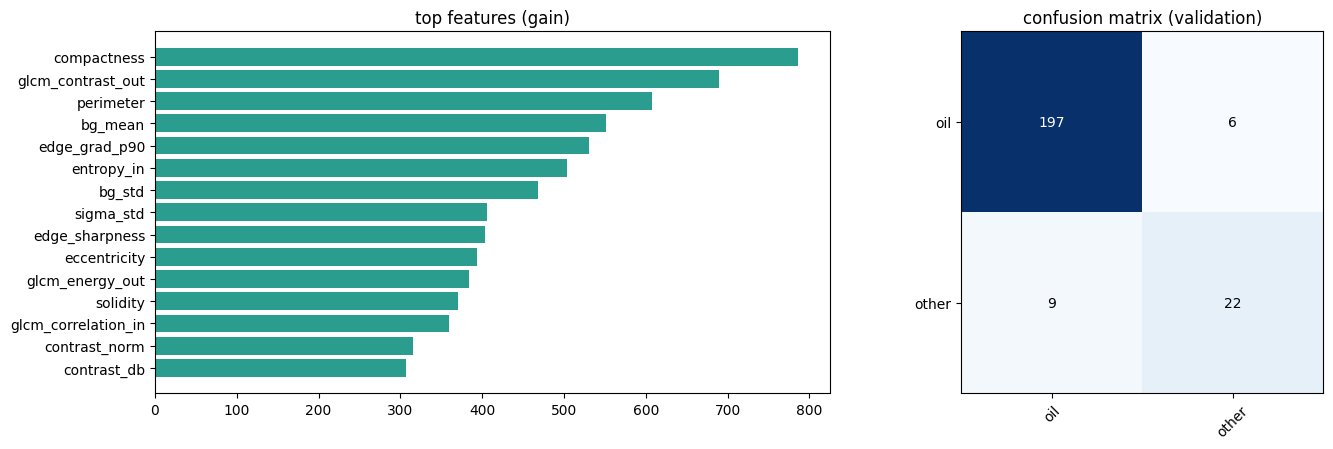

In [38]:
from lightgbm import LGBMClassifier
from sklearn.metrics import classification_report, confusion_matrix
import joblib

GBM_PATH = WEIGHTS / "lookalike_gbm.joblib"
# Never let a previous run's model masquerade as the result of this run.
GBM_PATH.unlink(missing_ok=True)
LOOKALIKE_CLASSIFIER = None
SUPPORTED = sorted(FEAT["_y"].unique()) if len(FEAT) else []
LOOKALIKE_TRAINED = len(SUPPORTED) >= 2 and all(
    (FEAT[FEAT._y == c]["_split"] == "train").sum() >= 15 for c in SUPPORTED)

if not LOOKALIKE_TRAINED:
    LOOKALIKE_REPORT = {"trained": False, "status": NOT_AVAILABLE,
                        "reason": f"supported region classes in this run: {SUPPORTED}; "
                                  "need >=2 classes with >=15 training regions each",
                        "hard_negative_mining": RUN_CARD.get("lookalike_hard_negative_mining", {}),
                        "contract_classes": LOOKALIKE_CLASSES}
    print(f"look-alike classifier: {NOT_AVAILABLE}")
    print(f"  {LOOKALIKE_REPORT['reason']}")
    print("  The API-compatible feature and classification layer is still written to the package;")
    print("  classify() falls back to a documented rule and reports classifier_trained=False.")
else:
    FEATURE_ORDER = [c for c in FEAT.columns if not c.startswith("_")]
    if not WIND_FEATURE:
        FEATURE_ORDER = [c for c in FEATURE_ORDER if c != "wind_speed_ms"]
    y_index = {c: LOOKALIKE_CLASSES.index(c) for c in SUPPORTED}
    FEAT["_yi"] = FEAT["_y"].map(y_index)
    tr_f, va_f = FEAT[FEAT._split == "train"], FEAT[FEAT._split == "val"]
    Xtr, ytr = tr_f[FEATURE_ORDER].fillna(0.0).values, tr_f["_yi"].values
    Xva, yva = va_f[FEATURE_ORDER].fillna(0.0).values, va_f["_yi"].values

    clf = LGBMClassifier(n_estimators=400, learning_rate=0.05, num_leaves=31,
                         class_weight="balanced", random_state=CFG.seed, verbose=-1)
    clf.fit(Xtr, ytr)
    _val_predictions = clf.predict(Xva) if len(Xva) else np.asarray([], dtype=int)
    present = sorted(set(yva.tolist()) | set(clf.classes_.tolist()))
    if len(Xva):
        rep = classification_report(yva, _val_predictions, labels=present,
                                    target_names=[LOOKALIKE_CLASSES[i] for i in present],
                                    zero_division=0, output_dict=True)
        print(f"train {len(Xtr)} | val {len(Xva)} regions | {len(FEATURE_ORDER)} features\n")
        print(classification_report(yva, _val_predictions, labels=present,
                                    target_names=[LOOKALIKE_CLASSES[i] for i in present],
                                    zero_division=0))
        _val_confusion = confusion_matrix(yva, _val_predictions, labels=present).tolist()
        _val_support = {LOOKALIKE_CLASSES[i]: int((yva == i).sum()) for i in present}
        _val_macro_f1 = round(float(rep.get("macro avg", {}).get("f1-score", 0.0)), 4)
        _validation_status = "EVALUATED"
    else:
        rep, _val_confusion, _val_support, _val_macro_f1 = {}, [], {}, None
        _validation_status = "NOT_EVALUABLE_NO_VALIDATION_REGIONS"
        print(f"train {len(Xtr)} | val 0 regions | {len(FEATURE_ORDER)} features")

    LOOKALIKE_CLASSIFIER = clf
    joblib.dump({"model": clf, "feature_order": FEATURE_ORDER, "classes": LOOKALIKE_CLASSES,
                 "trained_classes": SUPPORTED, "wind_feature": WIND_FEATURE,
                 "untrained_classes": [c for c in LOOKALIKE_CLASSES if c not in SUPPORTED],
                 "validation_status": _validation_status,
                 "validation_support_by_class": _val_support,
                 "validation_macro_f1": _val_macro_f1,
                 "trained_at": datetime.now(timezone.utc).isoformat()}, GBM_PATH)
    LOOKALIKE_REPORT = {"trained": True, "contract_classes": LOOKALIKE_CLASSES,
                        "trained_classes": SUPPORTED,
                        "untrained_classes": [c for c in LOOKALIKE_CLASSES if c not in SUPPORTED],
                        "untrained_reason": "this release carries no algae or low-wind labels",
                        "training_region_sources": (FEAT[FEAT._split == "train"].get("_region_source", pd.Series(dtype=str)).value_counts().to_dict()
                            if "_region_source" in FEAT.columns else {}),
                        "hard_negative_mining": RUN_CARD.get("lookalike_hard_negative_mining", {}),
                        "n_features": len(FEATURE_ORDER),
                        "validation_status": _validation_status,
                        "validation_support_by_class": _val_support,
                        "validation_confusion_matrix": _val_confusion,
                        "macro_f1": _val_macro_f1,
                        "val_regions": int(len(Xva)),
                        "deployment_note": "downstream region classification; not included in the U-Net scene-level FP/FN gate"}
    print(f"saved -> {GBM_PATH}")

    fig, ax = plt.subplots(1, 2, figsize=(15, 4.6))
    imp = pd.DataFrame({"f": FEATURE_ORDER, "g": clf.feature_importances_}).nlargest(15, "g")
    ax[0].barh(imp.f[::-1], imp.g[::-1], color="#2a9d8f"); ax[0].set_title("top features (gain)")
    if len(Xva):
        cm = np.asarray(_val_confusion, dtype=int)
        ax[1].imshow(cm, cmap="Blues")
        ax[1].set_xticks(range(len(present)), [LOOKALIKE_CLASSES[i] for i in present], rotation=45)
        ax[1].set_yticks(range(len(present)), [LOOKALIKE_CLASSES[i] for i in present])
        for (i, j), v in np.ndenumerate(cm):
            ax[1].text(j, i, int(v), ha="center", va="center",
                       color="white" if cm.size and v > cm.max() / 2 else "black")
        ax[1].set_title("confusion matrix (validation)")
    else:
        ax[1].text(0.5, 0.5, "Validation regions unavailable", ha="center", va="center")
        ax[1].set_axis_off()
    plt.tight_layout(); plt.savefig(PLOTS / "lookalike_classifier.png", dpi=110,
                                    bbox_inches="tight"); plt.show()

RUN_CARD["lookalike"] = LOOKALIKE_REPORT

# G. Stage 4 — Wind context gate and the confidence tier

SAR oil detection is unreliable at wind extremes: below ~2 m/s the sea is already smooth and
look-alikes are everywhere; above ~12 m/s wind roughening masks the damping signature. These are
**configurable engineering thresholds, not universal physical laws** — they are stated as such in
the run card and in the module docstring.

When wind data is unavailable the gate returns a structured `wind_unavailable` status and demotes
the tier. It never invents a wind value.

The tier is what gates the whole pipeline: `oil + high → proceed`, `oil + medium → validate`,
anything else → `stopped`.

In [39]:
# ======================= science/ingestion/wind_gate.py =======================
WIND_LOW_MS, WIND_HIGH_MS = CFG.wind_low_ms, CFG.wind_high_ms

def era5_wind_at(path, lon, lat, when):
    """Read wind speed from cached ERA5 or compatible synthetic NetCDF fields."""
    import xarray as xr
    from datetime import timezone

    when_naive_utc = (when.astimezone(timezone.utc).replace(tzinfo=None)
                      if getattr(when, "tzinfo", None) is not None else when)
    with xr.open_dataset(path) as ds:
        def find_name(names, available, role):
            for name in names:
                if name in available:
                    return name
            raise ValueError(f"wind NetCDF has no supported {role}; expected one of {names}")

        coords_and_dims = set(ds.coords) | set(ds.dims)
        lon_name = find_name(("lon", "longitude"), coords_and_dims, "longitude coordinate")
        lat_name = find_name(("lat", "latitude"), coords_and_dims, "latitude coordinate")
        time_name = find_name(("time", "valid_time"), coords_and_dims, "time coordinate")
        u_name = find_name(("x_wind", "eastward_wind", "u10", "u"), set(ds.data_vars), "eastward wind variable")
        v_name = find_name(("y_wind", "northward_wind", "v10", "v"), set(ds.data_vars), "northward wind variable")
        point = ds.interp({lon_name: lon, lat_name: lat, time_name: when_naive_utc})
        u, v = float(point[u_name].values), float(point[v_name].values)
    return (u ** 2 + v ** 2) ** 0.5

def wind_regime(speed_ms, low=WIND_LOW_MS, high=WIND_HIGH_MS):
    if speed_ms is None:  return "unavailable"
    if speed_ms < low:    return "too_low"
    if speed_ms > high:   return "too_high"
    return "favourable"


def wind_context(wind_nc, lon, lat, when, low=WIND_LOW_MS, high=WIND_HIGH_MS):
    """Structured status. Returns speed None + status 'wind_unavailable' rather than a guess."""
    try:
        if wind_nc and Path(wind_nc).exists():
            s = era5_wind_at(wind_nc, lon, lat, when)
            return {"wind_speed_ms": float(s), "regime": wind_regime(s, low, high),
                    "status": "ok", "source": "era5_cached"}
    except Exception as e:
        return {"wind_speed_ms": None, "regime": "unavailable",
                "status": "wind_unavailable", "source": f"error:{type(e).__name__}: {e}",
                "reason": f"{type(e).__name__}: {e}"}
    return {"wind_speed_ms": None, "regime": "unavailable",
            "status": "wind_unavailable", "source": "no_cached_field"}
# ======================= end wind_gate.py =======================


# ======================= science/detect/lookalike.py =======================
def classify(features, bundle, wind):
    """Guide §6 four-way call plus the tier that gates the pipeline.

    `wind` is the dict from wind_context(). Untrained contract classes stay at probability 0;
    the caller can see which ones from bundle['untrained_classes'].
    """
    proba = np.zeros(len(LOOKALIKE_CLASSES), float)
    trained = bool(bundle) and bundle.get("model") is not None
    if trained:
        order = bundle["feature_order"]
        x = np.array([[float(features.get(k, 0.0) or 0.0) for k in order]])
        raw = bundle["model"].predict_proba(x)[0]
        for col, cls in enumerate(bundle["model"].classes_):
            proba[int(cls)] = float(raw[col])
    else:
        # Documented fallback when no classifier could be trained: contrast-based, and it says so.
        c = float(features.get("contrast_norm", 0.0) or 0.0)
        p_oil = float(np.clip((c - 1.0) / 4.0, 0.0, 0.9))
        proba[0], proba[3] = p_oil, 1.0 - p_oil

    idx = int(proba.argmax())
    classification = LOOKALIKE_CLASSES[idx]
    p = float(proba[idx])
    ws, regime = wind.get("wind_speed_ms"), wind.get("regime", "unavailable")
    if regime in ("too_low", "too_high"):
        tier = "low" if p < 0.85 else "medium"
    elif regime == "unavailable":
        tier = "low" if p < 0.85 else "medium"     # never promote on missing context
    else:
        tier = "high" if p >= 0.80 else ("medium" if p >= 0.55 else "low")
    if not trained:
        tier = "low" if tier == "high" else tier   # an untrained classifier cannot say "high"

    return {"classification": classification, "oil_confidence": round(float(proba[0]), 4),
            "confidence_tier": tier,
            "classifier_trained": trained,
            "wind_status": wind.get("status", "wind_unavailable"), "wind_regime": regime}


def pipeline_status_for(verdict):
    """Mirror of app/main.py for local testing ONLY. The API remains the authority."""
    if verdict["classification"] == "oil":
        if verdict["confidence_tier"] == "high":   return "proceed"
        if verdict["confidence_tier"] == "medium": return "validate"
    return "stopped"
# ======================= end lookalike.py =======================

BUNDLE = joblib.load(GBM_PATH) if GBM_PATH.exists() else None
for w in (0.8, 3.0, 6.5, 11.9, 15.2, None):
    ctx = {"wind_speed_ms": w, "regime": wind_regime(w), "status": "ok" if w else "wind_unavailable"}
    print(f"  wind {str(w):>6} m/s -> regime {ctx['regime']:<12} status {ctx['status']}")
print("\ngate truth table (mirrors main.py):")
for c in LOOKALIKE_CLASSES:
    for t in ("high", "medium", "low"):
        print(f"  {c:9s} + {t:6s} -> {pipeline_status_for({'classification': c, 'confidence_tier': t})}")
RUN_CARD["wind_gate"] = {"low_ms": CFG.wind_low_ms, "high_ms": CFG.wind_high_ms,
                         "note": "configurable engineering thresholds, not physical laws",
                         "unavailable_behaviour": "structured wind_unavailable, tier demoted, "
                                                  "no invented wind value"}

  wind    0.8 m/s -> regime too_low      status ok
  wind    3.0 m/s -> regime favourable   status ok
  wind    6.5 m/s -> regime favourable   status ok
  wind   11.9 m/s -> regime favourable   status ok
  wind   15.2 m/s -> regime too_high     status ok
  wind   None m/s -> regime unavailable  status wind_unavailable

gate truth table (mirrors main.py):
  oil       + high   -> proceed
  oil       + medium -> validate
  oil       + low    -> stopped
  algae     + high   -> stopped
  algae     + medium -> stopped
  algae     + low    -> stopped
  low_wind  + high   -> stopped
  low_wind  + medium -> stopped
  low_wind  + low    -> stopped
  other     + high   -> stopped
  other     + medium -> stopped
  other     + low    -> stopped


# H. Source Consistency — four independent components, one combiner

Four functions, four floats, each independently defensible, **every one in [0,1]** or the API
rejects the payload. Centroid distance and Hausdorff distance are unbounded in metres, which is
exactly where this goes wrong if you are careless.

The separation that keeps the project honest:

* `score/components.py` computes the four components and **nothing else**.
* `score/consistency.py` holds `source_consistency_score()` — the single place the weights live,
  mirroring `services.py`. Two copies of the formula that can silently disagree is a failure mode,
  not redundancy.
* **BAS and VRP cannot reach either.** `consistency.py` takes four floats. There is no parameter
  through which a risk profile could enter, and `test_risk_profile_never_affects_consistency`
  proves it in §K.

Be ready to defend the exponential normalisations. `CENTROID_SCALE_KM = 25` is exactly the
constant a sharp judge asks about. They are calibration choices, reported explicitly in
`run_card.json` rather than buried, with the component scores always shown separately.

In [40]:
SCI_DIRS = ["ingestion", "detect", "trace", "score", "ais", "integrate", "training", "weights", "env"]
for d in SCI_DIRS:
    (SCI / d).mkdir(parents=True, exist_ok=True); (SCI / d / "__init__.py").touch()
(SCI / "__init__.py").touch()

def write_module(rel, body):
    p = SCI / rel; p.parent.mkdir(parents=True, exist_ok=True); p.write_text(body)
    print(f"  wrote science/{rel}  ({len(body.splitlines())} lines)")

COMPONENTS_PY = r'''"""science/score/components.py — the four Source Consistency components.

Each component is independent and returns a value in [0, 1]. This module computes components
ONLY; the weighted combination lives in score/consistency.py so there is exactly one formula.
"""
import numpy as np
from shapely.geometry import Polygon
from scipy.spatial.distance import directed_hausdorff

try:
    from dtaidistance import dtw
    _HAVE_DTW = True
except Exception:
    _HAVE_DTW = False

# Calibration choices. Fixed, documented, and reported — not measurements.
CENTROID_SCALE_KM = {CENTROID}
HAUSDORFF_SCALE_KM = {HAUSDORFF}
DTW_SCALE = {DTW}
DTW_IMPLEMENTATION = "pure numpy squared point cost with sqrt of accumulated path cost; dtaidistance-compatible"
EARTH_R_KM = 6371.0088


def haversine_km(a, b):
    """a, b: shapely Points or (lon, lat) tuples. LON FIRST — models.py Coordinate order."""
    lon1, lat1 = (a.x, a.y) if hasattr(a, "x") else (a[0], a[1])
    lon2, lat2 = (b.x, b.y) if hasattr(b, "x") else (b[0], b[1])
    p1, p2 = np.radians(lat1), np.radians(lat2)
    dp, dl = p2 - p1, np.radians(lon2 - lon1)
    h = np.sin(dp / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(dl / 2) ** 2
    return float(2 * EARTH_R_KM * np.arcsin(np.sqrt(np.clip(h, 0, 1))))


def _clip01(x):
    """Every Score field in models.py is ge=0, le=1. Enforced here, once."""
    return 0.0 if not np.isfinite(x) else float(min(1.0, max(0.0, x)))


def _valid(p):
    if p is None or p.is_empty:
        return None
    return p if p.is_valid else p.buffer(0)


def spatial_iou(observed, simulated) -> float:
    o, s = _valid(observed), _valid(simulated)
    if o is None or s is None:
        return 0.0
    u = o.union(s).area
    return _clip01(0.0 if u == 0 else o.intersection(s).area / u)


def centroid_match(observed, simulated) -> float:
    o, s = _valid(observed), _valid(simulated)
    if o is None or s is None:
        return 0.0
    return _clip01(np.exp(-haversine_km(o.centroid, s.centroid) / CENTROID_SCALE_KM))


def shape_match(observed, simulated) -> float:
    o, s = _valid(observed), _valid(simulated)
    if o is None or s is None:
        return 0.0
    a = np.array(o.exterior.coords); b = np.array(s.exterior.coords)
    d_deg = max(directed_hausdorff(a, b)[0], directed_hausdorff(b, a)[0])
    return _clip01(np.exp(-(d_deg * 111.32) / HAUSDORFF_SCALE_KM))


def _dtw_distance(o, s):
    """Canonical dtaidistance-compatible DTW: squared point cost, sqrt at the end."""
    n, m = len(o), len(s)
    D = np.full((n + 1, m + 1), np.inf); D[0, 0] = 0.0
    for i in range(1, n + 1):
        for j in range(1, m + 1):
            delta = o[i - 1] - s[j - 1]
            c = delta * delta
            D[i, j] = c + min(D[i - 1, j], D[i, j - 1], D[i - 1, j - 1])
    return float(np.sqrt(D[n, m]))


def area_curve_dtw(observed_areas, simulated_areas) -> float:
    o = np.asarray(observed_areas, float); s = np.asarray(simulated_areas, float)
    if o.size == 0 or s.size == 0:
        return 0.0
    o = o / max(o[0], 1e-9)          # growth ratio, not absolute km^2
    s = s / max(s[0], 1e-9)
    return _clip01(np.exp(-_dtw_distance(o, s) / DTW_SCALE))


def all_components(observed_poly, simulated_poly, observed_areas, simulated_areas):
    """Exactly the four keys SimulationRequest.components expects. StrictModel uses
    extra='forbid', so a debug key here is a 422, not a warning."""
    return {"spatial_iou":    round(spatial_iou(observed_poly, simulated_poly), 6),
            "centroid_match": round(centroid_match(observed_poly, simulated_poly), 6),
            "shape_match":    round(shape_match(observed_poly, simulated_poly), 6),
            "area_curve_dtw": round(area_curve_dtw(observed_areas, simulated_areas), 6)}
'''.replace("{CENTROID}", str(CFG.CENTROID_SCALE_KM)).replace(
    "{HAUSDORFF}", str(CFG.HAUSDORFF_SCALE_KM)).replace("{DTW}", str(CFG.DTW_SCALE))

# The backend owns the authoritative score. This mirror exists only so the science side can
# ORDER candidates locally (uncertainty-aware early stopping, Level A/B rank statistics,
# convergence). It must never be posted to the API and must never diverge from services.py.
assert tuple(CFG.consistency_weights) == tuple(CFG.backend_consistency_weights), (
    f"Source Consistency weight divergence: science {tuple(CFG.consistency_weights)} vs "
    f"backend {tuple(CFG.backend_consistency_weights)}. services.py is authoritative — "
    "two formulas that disagree silently re-rank candidates."
)
assert abs(sum(CFG.consistency_weights) - 1.0) < 1e-9, "consistency weights must sum to 1.0"

CONSISTENCY_PY = '''"""science/score/consistency.py — LOCAL MIRROR of the backend formula.

NOT AUTHORITATIVE. The backend's services.py.source_consistency_score() is the single owner of
the final weighted Source Consistency Score; this module exists only so the science side can
order candidates locally (early stopping, Level A/B rank statistics, convergence sweeps).

The weights below are copied from services.py and asserted equal at package-build time. Never
POST a score computed here — the runner posts the four components and reads the API's value back.

Takes four physics components and nothing else: there is no parameter through which a Behavioral
Anomaly Score or a Vessel Risk Profile could enter, by construction.
"""
AUTHORITATIVE = False          # the backend is
COMPONENT_KEYS = ("spatial_iou", "centroid_match", "shape_match", "area_curve_dtw")
WEIGHTS = {"spatial_iou": {W0}, "centroid_match": {W1}, "shape_match": {W2}, "area_curve_dtw": {W3}}


def source_consistency_score(components: dict) -> float:
    """Weighted combination of the four physics components. Physics only."""
    missing = [k for k in COMPONENT_KEYS if k not in components]
    if missing:
        raise KeyError(f"missing components: {missing}")
    extra = [k for k in components if k not in COMPONENT_KEYS]
    if extra:
        raise ValueError(f"unexpected components (physics only): {extra}")
    for k in COMPONENT_KEYS:
        v = float(components[k])
        if not (0.0 <= v <= 1.0):
            raise ValueError(f"component {k}={v} outside [0,1]")
    return round(sum(WEIGHTS[k] * float(components[k]) for k in COMPONENT_KEYS), 6)
'''.replace("{CENTROID}", str(CFG.CENTROID_SCALE_KM)) \
   .replace("{HAUSDORFF}", str(CFG.HAUSDORFF_SCALE_KM)).replace("{DTW}", str(CFG.DTW_SCALE)) \
   .replace("{W0}", str(CFG.consistency_weights[0])).replace("{W1}", str(CFG.consistency_weights[1])) \
   .replace("{W2}", str(CFG.consistency_weights[2])).replace("{W3}", str(CFG.consistency_weights[3]))

import ast as _components_ast
compile(COMPONENTS_PY, "science/score/components.py", "exec")
_components_ast.parse(COMPONENTS_PY, filename="science/score/components.py")
write_module("score/components.py", COMPONENTS_PY)
RUN_CARD["area_curve_dtw_implementation"] = (
    "pure numpy squared point cost with sqrt of accumulated path cost; "
    "dtaidistance-compatible and environment-independent")
write_module("score/consistency.py", CONSISTENCY_PY)

import importlib.util
def load_module(name, path):
    sp = importlib.util.spec_from_file_location(name, path)
    m = importlib.util.module_from_spec(sp); sp.loader.exec_module(m); return m

components = load_module("tt_components", SCI / "score" / "components.py")
consistency = load_module("tt_consistency", SCI / "score" / "consistency.py")
print("\nloaded for testing")

  wrote science/score/components.py  (96 lines)
  wrote science/score/consistency.py  (30 lines)

loaded for testing


In [41]:
# ---------------------------------------------------------------- [0,1] self-tests
from shapely.geometry import Polygon as ShPoly
from shapely.affinity import translate, scale as sh_scale

BASE = ShPoly([(74.80, 12.90), (74.90, 12.90), (74.92, 12.97), (74.78, 12.96)])
CASES = {"identical": BASE, "shifted 1 km": translate(BASE, 0.0092, 0),
         "shifted 30 km": translate(BASE, 0.276, 0), "shifted 300 km": translate(BASE, 2.76, 0),
         "half size": sh_scale(BASE, 0.5, 0.5, origin="centroid"),
         "disjoint": translate(BASE, 1.0, 1.0)}
OBS_AREAS = [1.0, 1.8, 2.9, 4.4]
rows = []
for nm, sim in CASES.items():
    for tag, sa in (("matched curve", [1.0, 1.75, 3.0, 4.3]), ("flat curve", [1.0, 1.02, 1.05, 1.08])):
        c = components.all_components(BASE, sim, OBS_AREAS, sa)
        rows.append({"case": nm, "area_curve": tag, **c,
                     "score": consistency.source_consistency_score(c)})
COMP_DF = pd.DataFrame(rows)
display(COMP_DF)

vals = COMP_DF[list(consistency.COMPONENT_KEYS) + ["score"]].values
assert np.all((vals >= 0) & (vals <= 1)), "a component or the score escaped [0,1] — the API would 422"
assert COMP_DF.iloc[0].spatial_iou == 1.0 and COMP_DF.iloc[0].centroid_match == 1.0
print("\nOK: four components and the combined score all inside [0,1] in every case")
print(f"OK: 300 km offset -> centroid_match "
      f"{COMP_DF[COMP_DF.case=='shifted 300 km'].centroid_match.iloc[0]:.6f} (decays, never negative)")
RUN_CARD["consistency"] = {
    "normalisation_constants": {"CENTROID_SCALE_KM": CFG.CENTROID_SCALE_KM,
                                "HAUSDORFF_SCALE_KM": CFG.HAUSDORFF_SCALE_KM,
                                "DTW_SCALE": CFG.DTW_SCALE},
    "weights": dict(consistency.WEIGHTS),
    "components": list(consistency.COMPONENT_KEYS),
    "physics_only": True,
    "calibration_status": "engineering defaults; calibrate on Level A in Notebook 2",
}

,case,area_curve,spatial_iou,centroid_match,shape_match,area_curve_dtw,score
0,identical,matched curve,1.000000,1.000000,1.000000,0.927743,0.985549
1,identical,flat curve,1.000000,1.000000,1.000000,0.145558,0.829112
2,shifted 1 km,matched curve,0.848141,0.960903,0.974721,0.927743,0.917568
3,shifted 1 km,flat curve,0.848141,0.960903,0.974721,0.145558,0.761131
4,shifted 30 km,matched curve,0.000000,0.302267,0.463890,0.927743,0.353893
5,shifted 30 km,flat curve,0.000000,0.302267,0.463890,0.145558,0.197456
6,shifted 300 km,matched curve,0.000000,0.000006,0.000461,0.927743,0.185642
7,shifted 300 km,flat curve,0.000000,0.000006,0.000461,0.145558,0.029205
8,half size,matched curve,0.250000,1.000000,0.897881,0.927743,0.702625
9,half size,flat curve,0.250000,1.000000,0.897881,0.145558,0.546188



OK: four components and the combined score all inside [0,1] in every case
OK: 300 km offset -> centroid_match 0.000006 (decays, never negative)


# I. AIS — funnel, Behavioral Anomaly Score, Vessel Risk Profile

The funnel is **100 raw → ~20 after cheap filtering → top-5 + uncertainty reserve**, with **no
hard cutoff**: the reserve exists so an alternative candidate is never silently discarded. Those
exact numbers come from the master architecture doc; Final Freeze v3 §9 explicitly declined
renumbering them, so they stay.

BAS and VRP are **priority and context only**. They order which counterfactuals get simulated
first and what the investigator sees; they never touch the physics score. The module docstrings
say so at the top, because this is the line most likely to be "helpfully" wired into the ranking
at 3am.

In [42]:
AIS_BEHAVIORAL_PY = '''"""science/ais/behavioral.py — Behavioral Anomaly Score.

FEEDS compute_priority ONLY. Never the physics Source Consistency Score. If you are reading this
at 3am because the ranking looks wrong, the fix is not in this file.
"""
import numpy as np

WEIGHTS = {"speed_drop": .30, "loitering": .25, "route_deviation": .20, "gap_timing": .25}


def speed_drop_signal(track, laden_kn=10.0, slow_kn=3.0):
    """A laden tanker slowing to near-steerage is the classic discharge signature.

    Percentiles, not a leading window: a discharge in the first third of the track would
    otherwise drag the 'transit speed' estimate down and hide itself.
    """
    sog = np.asarray([p["sog"] for p in track], float)
    if sog.size < 4:
        return 0.0
    fast, slow = float(np.percentile(sog, 75)), float(np.percentile(sog, 5))
    if fast < laden_kn:
        return 0.0
    return float(np.clip((fast - slow) / max(fast - slow_kn, 1e-6), 0, 1))


def heading_entropy_signal(track):
    """Circling / loitering: heading scattered rather than steady."""
    cog = np.radians(np.asarray([p["cog"] for p in track], float))
    if cog.size < 4:
        return 0.0
    r = np.hypot(np.cos(cog).mean(), np.sin(cog).mean())
    return float(np.clip(1.0 - r, 0, 1))


def corridor_deviation_signal(track, corridor_km=10.0):
    """Max cross-track offset from the vessel's own start->end line."""
    lon = np.asarray([p["lon"] for p in track], float)
    lat = np.asarray([p["lat"] for p in track], float)
    if lon.size < 3:
        return 0.0
    lat0 = np.radians(lat.mean())
    x = (lon - lon[0]) * 111.32 * np.cos(lat0); y = (lat - lat[0]) * 110.57
    vx, vy = x[-1], y[-1]; n = np.hypot(vx, vy)
    if n < 1e-6:
        return 0.0
    return float(np.clip((np.abs(x * vy - y * vx) / n).max() / corridor_km, 0, 1))


def gap_overlap_signal(track, release_window, normal_gap_s=1800):
    """Fraction of the hindcast release window covered by an AIS transmission gap."""
    start, end = release_window
    total = (end - start).total_seconds()
    if total <= 0 or len(track) < 2:
        return 0.0
    times = sorted(p["t"] for p in track)
    covered = 0.0
    for a, b in zip(times[:-1], times[1:]):
        if (b - a).total_seconds() <= normal_gap_s:
            continue
        lo, hi = max(a, start), min(b, end)
        if hi > lo:
            covered += (hi - lo).total_seconds()
    return float(np.clip(covered / total, 0, 1))


def behavioral_signals(track, release_window):
    return {"speed_drop": speed_drop_signal(track),
            "loitering": heading_entropy_signal(track),
            "route_deviation": corridor_deviation_signal(track),
            "gap_timing": gap_overlap_signal(track, release_window)}


def behavioral_anomaly_score(track, release_window) -> float:
    s = behavioral_signals(track, release_window)
    return round(min(1.0, sum(s[k] * WEIGHTS[k] for k in s)), 4)
'''

AIS_RISK_PY = '''"""science/ais/risk.py — Vessel Risk Profile.

FEEDS compute_priority and investigator context ONLY. Never the physics Source Consistency Score.
Fields are sourced from Equasis (age, hull, flag) and Paris/Tokyo MoU (PSC detentions); anything
absent contributes its documented neutral value rather than a guess.
"""
CURRENT_YEAR = 2026
NEUTRAL_AGE = 0.3


def vessel_risk_profile(record) -> float:
    g = record.get if isinstance(record, dict) else (lambda k, d=None: getattr(record, k, d))
    built = g("built_year", None)
    age = min((CURRENT_YEAR - built) / 30, 1.0) if built else NEUTRAL_AGE
    hull = 1.0 if g("hull_type", "") == "SINGLE" else 0.0
    psc = min((g("psc_detentions_3yr", 0) or 0) / 3, 1.0)
    sanctions = 1.0 if g("sanctions_listed", False) else 0.0
    return round(0.3 * age + 0.25 * hull + 0.25 * psc + 0.2 * sanctions, 4)


def risk_context(record) -> dict:
    g = record.get if isinstance(record, dict) else (lambda k, d=None: getattr(record, k, d))
    return {"built_year": g("built_year", None), "hull_type": g("hull_type", None),
            "flag": g("flag", None), "psc_detentions_3yr": g("psc_detentions_3yr", None),
            "sanctions_listed": g("sanctions_listed", None),
            "vessel_risk_profile": vessel_risk_profile(record),
            "use": "priority ordering and investigator context only"}
'''

AIS_FUNNEL_PY = '''"""science/ais/funnel.py — 100 raw -> ~20 -> top-5 + uncertainty reserve.

No hard cutoff. The reserve is the point: it keeps borderline candidates visible so the pipeline
can expand rather than force a call when the top two scores are close (Final Freeze v3 §3).
Physics ranking uses proximity / temporal compatibility / trajectory / speed. BAS and VRP enter
ONLY through priority ordering, downstream of this ranking.
"""
import numpy as np

EARTH_R_KM = 6371.0088


def haversine_km(a, b):
    lon1, lat1, lon2, lat2 = a[0], a[1], b[0], b[1]
    p1, p2 = np.radians(lat1), np.radians(lat2)
    dp, dl = p2 - p1, np.radians(lon2 - lon1)
    h = np.sin(dp / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(dl / 2) ** 2
    return float(2 * EARTH_R_KM * np.arcsin(np.sqrt(np.clip(h, 0, 1))))


def proximity_score(track, origin_lonlat, scale_km=20.0):
    d = min(haversine_km((p["lon"], p["lat"]), origin_lonlat) for p in track) if track else 1e9
    return float(np.exp(-d / scale_km)), d


def temporal_score(track, release_window):
    """Fraction of the release window in which the vessel reported at all."""
    start, end = release_window
    inside = [p for p in track if start <= p["t"] <= end]
    if not track:
        return 0.0
    return float(np.clip(len(inside) / max(1, len(track) * 0.25), 0, 1))


def trajectory_score(track, origin_lonlat, release_window, scale_km=15.0):
    """Closest approach to the origin field DURING the release window specifically."""
    sub = [p for p in track if release_window[0] <= p["t"] <= release_window[1]] or track
    d = min(haversine_km((p["lon"], p["lat"]), origin_lonlat) for p in sub)
    return float(np.exp(-d / scale_km))


def speed_profile_score(track, laden_kn=10.0):
    sog = np.asarray([p["sog"] for p in track], float)
    if sog.size < 3:
        return 0.0
    return float(np.clip((sog.max() - sog.min()) / max(laden_kn, 1e-6), 0, 1))


def rank_candidates(candidates, origin_lonlat, release_window,
                    filtered_n=20, shortlist_n=5, reserve_n=3):
    """candidates: [{'vessel_id','track',...}]. Returns filtered / shortlist / reserve.

    PHYSICS ONLY at this stage — proximity, temporal, trajectory, speed.
    """
    scored = []
    for c in candidates:
        tr = c["track"]
        prox, d_km = proximity_score(tr, origin_lonlat)
        s = {"proximity": prox, "temporal": temporal_score(tr, release_window),
             "trajectory": trajectory_score(tr, origin_lonlat, release_window),
             "speed_profile": speed_profile_score(tr)}
        physics = round(0.40 * s["proximity"] + 0.20 * s["temporal"]
                        + 0.30 * s["trajectory"] + 0.10 * s["speed_profile"], 6)
        scored.append({**c, "signals": s, "physics_score": physics,
                       "closest_approach_km": round(d_km, 3)})
    scored.sort(key=lambda x: -x["physics_score"])
    filtered = scored[:filtered_n]
    return {"raw_n": len(scored), "filtered": filtered,
            "shortlist": filtered[:shortlist_n],
            "uncertainty_reserve": filtered[shortlist_n:shortlist_n + reserve_n],
            "note": "no hard cutoff — the reserve keeps alternatives available"}


def compute_priority(candidate, bas, vrp, w_physics=0.70, w_bas=0.20, w_vrp=0.10):
    """Simulation ORDER only. Never the Source Consistency Score."""
    return round(w_physics * candidate["physics_score"] + w_bas * bas + w_vrp * vrp, 6)
'''

write_module("ais/behavioral.py", AIS_BEHAVIORAL_PY)
write_module("ais/risk.py", AIS_RISK_PY)
write_module("ais/funnel.py", AIS_FUNNEL_PY)

ais_behavioral = load_module("tt_bas", SCI / "ais" / "behavioral.py")
ais_risk       = load_module("tt_vrp", SCI / "ais" / "risk.py")
ais_funnel     = load_module("tt_funnel", SCI / "ais" / "funnel.py")
print("\nloaded for testing")

  wrote science/ais/behavioral.py  (75 lines)
  wrote science/ais/risk.py  (27 lines)
  wrote science/ais/funnel.py  (76 lines)

loaded for testing


In [43]:
# ---------------------------------------------------------------- synthetic AIS exercise
T0 = datetime(2026, 3, 14, 2, 0, tzinfo=timezone.utc)
RELEASE_WINDOW = (T0 + timedelta(hours=1), T0 + timedelta(hours=4))
ORIGIN = (74.35, 12.55)

def synth_track(kind, lon0=74.20, lat0=12.40, seed=0):
    rng = np.random.default_rng(seed)
    pts, lon, lat = [], lon0, lat0
    for i in range(28):
        t = T0 + timedelta(minutes=15 * i)
        if kind == "innocent":       sog, cog = 11.5, 45.0
        elif kind == "discharging":
            sog = 11.4 if i < 6 else (1.2 if i < 18 else 10.8)
            cog = 45.0 if i < 6 else (float((45 + i * 37) % 360) if i < 18 else 45.0)
        elif kind == "gap":          sog, cog = 11.0, 50.0
        else:                        sog, cog = 12.5, 210.0
        lon += sog * 0.25 / 60 * 1.852 / 111.32
        lat += sog * 0.25 / 60 * 1.852 / 110.57 * (0.6 if cog < 180 else -0.6)
        if kind == "gap" and 5 <= i <= 19:
            continue
        pts.append({"t": t, "lon": lon, "lat": lat, "sog": float(sog), "cog": float(cog)})
    return pts

rows = []
for kind in ("innocent", "discharging", "gap", "outbound"):
    tk = synth_track(kind, seed=hash(kind) % 999)
    sig = ais_behavioral.behavioral_signals(tk, RELEASE_WINDOW)
    rows.append({"track": kind, "n_points": len(tk),
                 **{k: round(v, 3) for k, v in sig.items()},
                 "BAS": ais_behavioral.behavioral_anomaly_score(tk, RELEASE_WINDOW)})
BAS_DF = pd.DataFrame(rows); display(BAS_DF)

VESSELS = [
    {"vessel_id": "IMO-9123456", "mmsi": "419001234", "imo": "9123456", "built_year": 1996,
     "hull_type": "SINGLE", "flag": "PA", "psc_detentions_3yr": 3, "sanctions_listed": True},
    {"vessel_id": "MV-KAVERI-02", "mmsi": "563112987", "imo": "9788001", "built_year": 2019,
     "hull_type": "DOUBLE", "flag": "SG", "psc_detentions_3yr": 0, "sanctions_listed": False},
    {"vessel_id": "IMO-9450012", "mmsi": "419556677", "imo": "9450012", "built_year": 2007,
     "hull_type": "DOUBLE", "flag": "IN", "psc_detentions_3yr": 1, "sanctions_listed": False},
]
VRP_DF = pd.DataFrame([{**v, "VRP": ais_risk.vessel_risk_profile(v)} for v in VESSELS])
display(VRP_DF[["vessel_id", "built_year", "hull_type", "flag", "psc_detentions_3yr",
                "sanctions_listed", "VRP"]])

# funnel: 100 raw -> ~20 -> top-5 + reserve
rng = np.random.default_rng(CFG.seed)
CANDIDATES = []
for i in range(CFG.funnel_raw):
    kind = ("discharging" if i == 0 else
            "gap" if i == 1 else
            rng.choice(["innocent", "outbound"], p=[0.6, 0.4]))
    lon0 = ORIGIN[0] + float(rng.normal(0, 0.35)); lat0 = ORIGIN[1] + float(rng.normal(0, 0.35))
    if i < 2:
        lon0, lat0 = ORIGIN[0] - 0.05, ORIGIN[1] - 0.05
    CANDIDATES.append({"vessel_id": f"IMO-{9100000 + i}", "mmsi": f"{419000000 + i:09d}",
                       "imo": f"{9100000 + i:07d}",
                       "track": synth_track(str(kind), lon0, lat0, seed=i)})
FUNNEL = ais_funnel.rank_candidates(CANDIDATES, ORIGIN, RELEASE_WINDOW,
                                    CFG.funnel_filtered, CFG.funnel_shortlist, CFG.funnel_reserve)
print(f"\nfunnel: {FUNNEL['raw_n']} raw -> {len(FUNNEL['filtered'])} filtered "
      f"-> {len(FUNNEL['shortlist'])} shortlist + {len(FUNNEL['uncertainty_reserve'])} reserve")
top = pd.DataFrame([{"vessel_id": c["vessel_id"], "physics_score": c["physics_score"],
                     "closest_km": c["closest_approach_km"],
                     **{k: round(v, 3) for k, v in c["signals"].items()}}
                    for c in FUNNEL["shortlist"]])
display(top)
assert len(FUNNEL["uncertainty_reserve"]) > 0, "reserve empty — a hard cutoff crept in"
print("uncertainty reserve is populated — no hard cutoff")
RUN_CARD["ais"] = {"funnel": {"raw": FUNNEL["raw_n"], "filtered": len(FUNNEL["filtered"]),
                              "shortlist": len(FUNNEL["shortlist"]),
                              "reserve": len(FUNNEL["uncertainty_reserve"])},
                   "bas_weights": dict(ais_behavioral.WEIGHTS),
                   "bas_vrp_use": "priority ordering and investigator context only — "
                                  "never the Source Consistency Score",
                   "synthetic_demo": True}

,track,n_points,speed_drop,loitering,route_deviation,gap_timing,BAS
0,innocent,28,0.0,0.000,0.000,0.0,0.0000
1,discharging,28,1.0,0.455,0.004,0.0,0.4147
2,gap,13,0.0,0.000,0.000,1.0,0.2500
3,outbound,28,0.0,0.000,0.000,0.0,0.0000


,vessel_id,built_year,hull_type,flag,psc_detentions_3yr,sanctions_listed,VRP
0,IMO-9123456,1996,SINGLE,PA,3,True,1.0000
1,MV-KAVERI-02,2019,DOUBLE,SG,0,False,0.0700
2,IMO-9450012,2007,DOUBLE,IN,1,False,0.2733



funnel: 100 raw -> 20 filtered -> 5 shortlist + 3 reserve


,vessel_id,physics_score,closest_km,proximity,temporal,trajectory,speed_profile
0,IMO-9100000,0.779941,6.204,0.733,1.0,0.622,1.0
1,IMO-9100050,0.622294,8.693,0.647,1.0,0.544,0.0
2,IMO-9100039,0.616564,8.968,0.639,1.0,0.537,0.0
3,IMO-9100015,0.606398,9.570,0.620,1.0,0.528,0.0
4,IMO-9100076,0.602145,9.605,0.619,1.0,0.516,0.0


uncertainty reserve is populated — no hard cutoff


# J. OpenDrift source — written here, executed in Notebook 2

Guide §3 is explicit: *"OpenDrift's dependency tree and PyTorch's do not need to meet."* OpenDrift
is conda-installed (Cartopy, netCDF4, GDAL) and is **not** installed in this environment.

So this section writes the real implementation into the package. `build_engine()` is the single
constructor that both the backward hindcast and every forward counterfactual call — that is what
makes *"we use the same engine"* a claim a judge can ask you to show, rather than a slide bullet.

Nothing here is executed, nothing is stubbed to look like it ran, and no trajectory numbers enter
`run_card.json`. §K records OpenDrift as **NOT EXECUTED** for this notebook.

In [44]:
import ast
DRIFT_PY = r'''"""science/trace/drift.py — the ONE shared OpenDrift engine.

Requires the spill-drift conda environment, NOT the CV environment. The backward hindcast and
every forward counterfactual call build_engine(); there is no second physics implementation.
"""
from datetime import timedelta, timezone
import numpy as np

OIL_TYPE = "GENERIC MEDIUM CRUDE"
MEMBER_CONFIG_AUDIT = []
CONFIGSPEC_DIAGNOSTICS = []


def to_naive_utc(t):
    """OpenDrift and CF NetCDF work in naive UTC; app/models.py requires tz-aware datetimes.

    Convert once, here, at the boundary. Mixing the two raises
    "can't compare offset-naive and offset-aware datetimes" from inside a reader, which is a
    miserable thing to debug mid-ensemble.
    """
    if t is None or getattr(t, "tzinfo", None) is None:
        return t
    return t.astimezone(timezone.utc).replace(tzinfo=None)

CONFIG_KEY_CANDIDATES = {
    "windage": ("seed:wind_drift_factor", "drift:wind_drift_factor"),
    "horizontal_diffusivity": ("environment:constant:horizontal_diffusivity",
                                "environment:fallback:horizontal_diffusivity",
                                "drift:horizontal_diffusivity"),
    "current_uncertainty_amplitude": ("drift:current_uncertainty",),
    "wind_uncertainty_amplitude": ("drift:wind_uncertainty",),
}
GENERAL_CONFIG_CANDIDATES = {"general:use_auto_landmask": ("general:use_auto_landmask",)}


def _flatten_configspec(spec, prefix=""):
    keys = set()
    metadata_names = {"default", "default_value", "min", "minimum", "max", "maximum",
                      "type", "description", "units", "choices", "hardwired",
                      "is_hardwired", "hardwired_by_openoil"}
    if hasattr(spec, "items"):
        for raw_key, value in spec.items():
            key = str(raw_key)
            full_key = key if ":" in key or not prefix else f"{prefix}:{key}"
            if hasattr(value, "items"):
                fields = {str(k).lower() for k in value}
                if metadata_names.intersection(fields):
                    keys.add(full_key)
                else:
                    keys.update(_flatten_configspec(value, full_key))
            else:
                keys.add(full_key)
                keys.add(key)
    elif isinstance(spec, (list, tuple, set)):
        for item in spec:
            if isinstance(item, str):
                key = item.split("=", 1)[0].strip()
                if key:
                    keys.add(key)
    return keys

def _configspec_for(o):
    diagnostics = []
    for method_name in ("get_configspec", "list_configspec"):
        method = getattr(o, method_name, None)
        if not callable(method):
            continue
        try:
            spec = method()
        except Exception as exc:
            diagnostics.append(f"{method_name}: {type(exc).__name__}: {exc}")
            continue
        if spec is not None and _flatten_configspec(spec):
            return spec, diagnostics
    spec = getattr(o, "_configspec", None)
    if spec is None:
        config = getattr(o, "_config", None)
        spec = getattr(config, "configspec", None) if config is not None else None
    return spec, diagnostics


def _configspec_records(spec, prefix=""):
    records = {}
    metadata_names = {"default", "default_value", "min", "minimum", "max", "maximum",
                      "type", "description", "units", "choices", "hardwired",
                      "is_hardwired", "hardwired_by_openoil"}
    if hasattr(spec, "items"):
        for raw_key, value in spec.items():
            key = str(raw_key)
            full_key = key if ":" in key or not prefix else f"{prefix}:{key}"
            if hasattr(value, "items"):
                fields = {str(k).lower(): v for k, v in value.items()}
                if metadata_names.intersection(fields):
                    records[full_key] = {
                        "default": fields.get("default", fields.get("default_value", "NOT_AVAILABLE")),
                        "min": fields.get("min", fields.get("minimum", "NOT_AVAILABLE")),
                        "max": fields.get("max", fields.get("maximum", "NOT_AVAILABLE")),
                        "hardwired_by_openoil": fields.get(
                            "hardwired_by_openoil", fields.get("is_hardwired", fields.get("hardwired", "NOT_AVAILABLE"))),
                    }
                else:
                    records.update(_configspec_records(value, full_key))
            else:
                records[full_key] = {"default": value, "min": "NOT_AVAILABLE",
                                     "max": "NOT_AVAILABLE", "hardwired_by_openoil": "NOT_AVAILABLE"}
    elif isinstance(spec, (list, tuple, set)):
        for item in spec:
            if isinstance(item, str):
                key = item.split("=", 1)[0].strip()
                if key:
                    records[key] = {"default": "NOT_AVAILABLE", "min": "NOT_AVAILABLE",
                                    "max": "NOT_AVAILABLE", "hardwired_by_openoil": "NOT_AVAILABLE"}
            elif hasattr(item, "name"):
                key = str(item.name)
                records[key] = {
                    "default": getattr(item, "default", "NOT_AVAILABLE"),
                    "min": getattr(item, "min", getattr(item, "minimum", "NOT_AVAILABLE")),
                    "max": getattr(item, "max", getattr(item, "maximum", "NOT_AVAILABLE")),
                    "hardwired_by_openoil": getattr(item, "hardwired_by_openoil", "NOT_AVAILABLE"),
                }
    return records


def _diagnose_configspec(o, logical_name, error):
    spec, access_errors = _configspec_for(o)
    records = _configspec_records(spec) if spec is not None else {}
    prefixes = ("drift:", "seed:wind", "environment:constant:", "environment:fallback:")
    needles = ("diffus", "uncertain", "wind_drift", "horizontal")
    selected = {key: value for key, value in records.items()
                if any(needle in key.lower() for needle in needles)
                or key.startswith(prefixes)}
    rows = []
    for key in sorted(selected):
        info = selected[key]
        default = info["default"]
        writable = "NOT_AVAILABLE"
        try:
            old_value = o.get_config(key)
            old_value_available = True
        except Exception:
            old_value = None
            old_value_available = False
        probe_value = default if default != "NOT_AVAILABLE" else old_value
        should_probe = default != "NOT_AVAILABLE" or old_value_available
        if should_probe:
            probe_applied = False
            try:
                o.set_config(key, probe_value)
                probe_applied = True
                writable = True
            except Exception as exc:
                writable = f"NO ({type(exc).__name__}: {exc})"
            finally:
                if probe_applied and old_value_available:
                    try:
                        o.set_config(key, old_value)
                    except Exception as restore_error:
                        writable = f"RESTORE_FAILED ({type(restore_error).__name__}: {restore_error})"
        rows.append({"parameter": key.split(":")[-1], "key": key, **info,
                     "default": default if default != "NOT_AVAILABLE" else old_value,
                     "writable": writable})
    record = {"logical_parameter": logical_name, "resolution_error": str(error),
              "opendrift_version": opendrift_version(), "configspec_access_errors": access_errors,
              "entries": rows}
    CONFIGSPEC_DIAGNOSTICS.append(record)
    print()
    print(f"OpenDrift configspec diagnostic: {logical_name} resolution failed: {error}")
    print("parameter | key | default | min | max | writable? | hardwired by OpenOil?")
    for row in rows:
        print("{parameter} | {key} | {default} | {min} | {max} | {writable} | {hardwired_by_openoil}".format(**row))
    if not rows:
        print("No matching live configspec keys were available.")
    return record


def _writable_config_key(o, key, records):
    info = records.get(key, {})
    default = info.get("default", "NOT_AVAILABLE")
    try:
        old_value = o.get_config(key)
        had_old_value = True
    except Exception:
        old_value, had_old_value = None, False
    probe_value = default if default != "NOT_AVAILABLE" else old_value
    if probe_value is None and not had_old_value:
        return False, "no config default/readback available"
    applied = False
    try:
        o.set_config(key, probe_value)
        applied = True
    except Exception as exc:
        return False, f"{type(exc).__name__}: {exc}"
    finally:
        if applied and had_old_value:
            try:
                o.set_config(key, old_value)
            except Exception as exc:
                raise RuntimeError(f"failed restoring OpenDrift config {key!r} after capability probe: {exc}") from exc
    return True, None


def _find_writable_config(o, candidates):
    spec, diagnostics = _configspec_for(o)
    available = _flatten_configspec(spec) if spec is not None else set()
    records = _configspec_records(spec) if spec is not None else {}
    attempts = []
    for candidate in candidates:
        if candidate not in available:
            continue
        writable, reason = _writable_config_key(o, candidate, records)
        attempts.append({"key": candidate, "writable": writable, "reason": reason})
        if writable:
            return candidate, attempts, diagnostics
    return None, attempts, diagnostics


def _element_variable_names(o):
    element_type = getattr(o, "ElementType", None)
    variables = getattr(element_type, "variables", None)
    if isinstance(variables, dict):
        return set(map(str, variables))
    if isinstance(variables, (list, tuple, set)):
        return {str(getattr(value, "name", value)) for value in variables}
    return set()


def diagnose_configspec(o, logical_name="startup"):
    """Print and retain the live, writable-tested OpenDrift configspec subset."""
    return _diagnose_configspec(o, logical_name, "startup capability inventory")


def resolve_capabilities(o):
    """Classify engine controls only from live configspec and element-variable evidence."""
    spec, access_errors = _configspec_for(o)
    available = _flatten_configspec(spec) if spec is not None else set()
    wind_key, wind_attempts, _ = _find_writable_config(o, CONFIG_KEY_CANDIDATES["windage"])
    if wind_key:
        windage = {"kind": "WRITABLE_CONFIG", "key": wind_key, "property": None,
                   "attempts": wind_attempts}
    elif "wind_drift_factor" in _element_variable_names(o):
        windage = {"kind": "SEED_PROPERTY", "key": None,
                   "property": "wind_drift_factor", "attempts": wind_attempts}
    else:
        reason = "no writable windage config key and wind_drift_factor is absent from live element variables"
        _diagnose_configspec(o, "windage", reason)
        windage = {"kind": "NOT_SUPPORTED", "reason": reason, "attempts": wind_attempts}

    dispersion_key, dispersion_attempts, _ = _find_writable_config(
        o, CONFIG_KEY_CANDIDATES["horizontal_diffusivity"])
    if dispersion_key:
        dispersion = {"kind": "WRITABLE_CONFIG", "key": dispersion_key,
                      "parameter_name": "horizontal_diffusivity", "semantics": "horizontal diffusivity",
                      "attempts": dispersion_attempts}
    else:
        dispersion = None
        for amplitude_name in ("current_uncertainty_amplitude", "wind_uncertainty_amplitude"):
            key, attempts, _ = _find_writable_config(o, CONFIG_KEY_CANDIDATES[amplitude_name])
            dispersion_attempts.extend(attempts)
            if key:
                dispersion = {"kind": "WRITABLE_CONFIG", "key": key,
                              "parameter_name": amplitude_name,
                              "semantics": "uncertainty amplitude", "attempts": dispersion_attempts}
                break
        if dispersion is None:
            reason = "no writable horizontal-diffusivity key or current/wind uncertainty-amplitude key"
            _diagnose_configspec(o, "dispersion", reason)
            dispersion = {"kind": "NOT_SUPPORTED", "reason": reason,
                          "attempts": dispersion_attempts}

    general = {}
    for logical_name, candidates in GENERAL_CONFIG_CANDIDATES.items():
        key, attempts, diagnostics = _find_writable_config(o, candidates)
        general[logical_name] = ({"kind": "WRITABLE_CONFIG", "key": key, "attempts": attempts}
                                 if key else {"kind": "NOT_SUPPORTED",
                                              "reason": "key absent or not writable in live configspec",
                                              "attempts": attempts,
                                              "configspec_access_errors": diagnostics})
    return {"windage": windage, "dispersion": dispersion,
            "general": general, "element_variables": sorted(_element_variable_names(o)),
            "configspec_keys": sorted(available), "configspec_access_errors": access_errors,
            "opendrift_version": opendrift_version()}


def resolve_config_key(o, logical_name):
    """Resolve a logical config key using the live configspec; candidate names are hints only."""
    aliases = {"wind_drift_factor": "windage", "horizontal_diffusivity": "dispersion"}
    logical = aliases.get(logical_name, logical_name)
    capabilities = resolve_capabilities(o)
    capability = capabilities.get(logical)
    if logical == "dispersion":
        capability = capabilities["dispersion"]
    if capability and capability.get("kind") == "WRITABLE_CONFIG":
        return capability["key"]
    error = RuntimeError(f"cannot resolve writable OpenDrift config {logical_name!r}: "
                         f"{(capability or {}).get('reason', 'unsupported logical parameter')}")
    _diagnose_configspec(o, logical_name, error)
    raise error


def resolve_config_keys(o):
    """Compatibility view of the live capability table; unsupported controls are omitted."""
    capabilities = resolve_capabilities(o)
    resolved = {}
    if capabilities["windage"]["kind"] == "WRITABLE_CONFIG":
        resolved["wind_drift_factor"] = capabilities["windage"]["key"]
    if capabilities["dispersion"]["kind"] == "WRITABLE_CONFIG":
        resolved[capabilities["dispersion"]["parameter_name"]] = capabilities["dispersion"]["key"]
    return resolved


def probe_opendrift_capabilities():
    """Run a standalone OpenOil inventory; production resolution uses reader-attached engines."""
    from opendrift.models.openoil import OpenOil
    probe = OpenOil(loglevel=50, weathering_model="noaa")
    diagnose_configspec(probe, "startup")
    return resolve_capabilities(probe)

def opendrift_version():
    try:
        from importlib.metadata import version
        return version("opendrift")
    except Exception:
        try:
            import opendrift
            return str(opendrift.__version__)
        except Exception:
            return "NOT_AVAILABLE"


DEFAULTS = {
    "windage": 0.03,
    "dispersion": 10.0,
    "general:use_auto_landmask": True,
}

# Perturbations are applied only when the live capability table supports the setting.
PERTURBATION = {
    "windage": ("normal", DEFAULTS["windage"], 0.005),
    "dispersion": ("uniform", 5.0, 20.0),
}



def trajectory_positions(o, hours):
    """Return finite (lon, lat) rows at an hourly output index.

    Current OpenDrift returns trajectories in result; history is a compatibility fallback only
    when result is absent. A present but malformed result is an error, not a reason to guess.
    """
    hour_value = float(hours)
    hour_index = int(round(hour_value))
    if not np.isfinite(hour_value) or hour_index < 0 or not np.isclose(hour_value, hour_index):
        raise ValueError(f"trajectory hour must be a non-negative integer; got {hours!r}")
    result = getattr(o, "result", None)
    if result is not None:
        if not all(name in result for name in ("lon", "lat")):
            raise ValueError("OpenDrift result lacks lon/lat trajectory variables")
        lon_data, lat_data = result["lon"], result["lat"]
        lon_dims, lat_dims = tuple(getattr(lon_data, "dims", ())), tuple(getattr(lat_data, "dims", ()))
        if ("trajectory" not in lon_dims or "time" not in lon_dims
                or lon_dims != lat_dims):
            raise ValueError(f"unsupported OpenDrift trajectory dimensions: lon={lon_dims}, lat={lat_dims}")
        lon_values = np.asarray(lon_data.transpose("trajectory", "time").values, dtype=float)
        lat_values = np.asarray(lat_data.transpose("trajectory", "time").values, dtype=float)
    else:
        history = getattr(o, "history", None)
        if history is None or history.dtype.names is None or not {"lon", "lat"}.issubset(history.dtype.names):
            raise ValueError("OpenDrift has neither a usable result nor legacy history")
        lon_values = np.ma.filled(history["lon"], np.nan).astype(float)
        lat_values = np.ma.filled(history["lat"], np.nan).astype(float)
    if lon_values.ndim != 2 or lat_values.shape != lon_values.shape:
        raise ValueError(f"invalid OpenDrift trajectory arrays: lon={lon_values.shape}, lat={lat_values.shape}")
    if hour_index >= lon_values.shape[1]:
        raise IndexError(f"trajectory hour {hour_index} unavailable; only {lon_values.shape[1]} outputs")
    points = np.column_stack((lon_values[:, hour_index], lat_values[:, hour_index]))
    return points[np.isfinite(points).all(axis=1)]

_CONFIGSPEC_STARTUP_DIAGNOSED = False


def build_engine(currents_nc, wind_nc, seed=None, config=None, loglevel=50):
    """Build the one OpenOil engine from live, verified capabilities.

    Capability resolution happens only after the actual forcing readers are attached.
    This keeps the capability table identical to the engine state used for forward
    and backward runs.
    """
    global _CONFIGSPEC_STARTUP_DIAGNOSED
    from opendrift.models.openoil import OpenOil
    from opendrift.readers import reader_netCDF_CF_generic
    o = OpenOil(loglevel=loglevel, weathering_model="noaa")
    readers = [reader_netCDF_CF_generic.Reader(p) for p in (currents_nc, wind_nc) if p]
    if readers:
        o.add_reader(readers)
    if not _CONFIGSPEC_STARTUP_DIAGNOSED:
        diagnose_configspec(o, "startup")
        _CONFIGSPEC_STARTUP_DIAGNOSED = True
    capabilities = resolve_capabilities(o)
    cfg = dict(DEFAULTS); cfg.update(config or {})
    resolved_keys, applied_config, seed_properties, skipped = {}, {}, {}, {}
    for setting, value in cfg.items():
        if setting == "general:use_auto_landmask":
            capability = capabilities["general"][setting]
            logical_name = setting
        elif setting == "windage":
            capability = capabilities["windage"]
            logical_name = "windage"
        elif setting == "dispersion":
            capability = capabilities["dispersion"]
            logical_name = "dispersion"
        else:
            raise ValueError(f"unsupported OpenDrift setting {setting!r}; add a live-configspec resolver")
        if capability["kind"] == "NOT_SUPPORTED":
            skipped[logical_name] = {"status": "NOT_SUPPORTED", "reason": capability["reason"]}
            continue
        if capability["kind"] == "SEED_PROPERTY":
            seed_properties[capability["property"]] = float(value)
            applied_config[logical_name] = {"kind": "SEED_PROPERTY",
                                            "property": capability["property"],
                                            "requested": float(value)}
            continue
        actual_key = capability["key"]
        try:
            o.set_config(actual_key, value)
            applied_value = o.get_config(actual_key)
        except Exception as exc:
            raise RuntimeError(
                f"OpenDrift rejected supported config {actual_key!r}={value!r}: "
                f"{type(exc).__name__}: {exc}") from exc
        if isinstance(value, (int, float, np.number)):
            if not np.isclose(float(applied_value), float(value), rtol=0.0, atol=1e-12):
                raise RuntimeError(
                    f"OpenDrift config readback mismatch for {logical_name!r} at {actual_key!r}: "
                    f"requested={value!r}, applied={applied_value!r}")
        elif applied_value != value:
            raise RuntimeError(
                f"OpenDrift config readback mismatch for {logical_name!r} at {actual_key!r}: "
                f"requested={value!r}, applied={applied_value!r}")
        resolved_keys[logical_name] = actual_key
        applied_config[logical_name] = {"kind": "WRITABLE_CONFIG", "key": actual_key,
                                        "requested": value, "applied": applied_value}
    if seed is not None:
        np.random.seed(seed)
    o._tidetrace_capabilities = capabilities
    o._tidetrace_resolved_config_keys = resolved_keys
    o._tidetrace_requested_config = applied_config
    o._tidetrace_seed_properties = seed_properties
    o._tidetrace_skipped_settings = skipped
    o._tidetrace_opendrift_version = opendrift_version()
    return o


def member_config(rng, engine):
    """Perturb every supported control; report unsupported parameters explicitly."""
    out = {}
    for logical_name, spec in PERTURBATION.items():
        capability = (engine.capabilities["windage"] if logical_name == "windage"
                     else engine.capabilities["dispersion"])
        if capability["kind"] == "NOT_SUPPORTED":
            continue
        kind = spec[0]
        if kind == "normal":
            out[logical_name] = float(rng.normal(spec[1], spec[2]))
        else:
            out[logical_name] = float(rng.uniform(spec[1], spec[2]))
    return out


class DriftEngine:
    """The shared contract Notebook 2 depends on. One configuration, both directions."""

    def __init__(self, currents_nc, wind_nc, oil_type=OIL_TYPE, config=None):
        self.currents_nc, self.wind_nc = currents_nc, wind_nc
        self.oil_type, self.config = oil_type, dict(config or {})
        # Use the exact same reader-attached engine state as the real run.
        # Do not resolve capabilities from a bare OpenOil object.
        probe = build_engine(currents_nc, wind_nc, config={}, loglevel=50)
        self.capabilities = probe._tidetrace_capabilities
        self.resolved_config_keys = probe._tidetrace_resolved_config_keys
        self.opendrift_version = probe._tidetrace_opendrift_version
        self.unsupported_settings = {
            name: value.get("reason") for name, value in
            (("windage", self.capabilities["windage"]),
             ("dispersion", self.capabilities["dispersion"]))
            if value.get("kind") == "NOT_SUPPORTED"}

    def run(self, seeds, start_time, hours, backward=False, seed=None, member_cfg=None,
            time_step_output=3600):
        """seeds: dict for o.seed_elements(). Negative time_step = backward, per OpenDrift."""
        cfg = dict(self.config); cfg.update(member_cfg or {})
        o = build_engine(self.currents_nc, self.wind_nc, seed=seed, config=cfg)
        seed_kwargs = dict(seeds)
        for property_name, requested_value in o._tidetrace_seed_properties.items():
            if property_name in seed_kwargs:
                raise ValueError(f"seed property {property_name!r} was supplied twice")
            seed_kwargs[property_name] = requested_value
        o.seed_elements(time=to_naive_utc(start_time), oil_type=self.oil_type, **seed_kwargs)
        seeded_elements = getattr(o, "elements_scheduled", None)
        requested_windage = o._tidetrace_requested_config.get("windage")
        if seeded_elements is None or not hasattr(seeded_elements, "wind_drift_factor"):
            seeded_wind_drift_factor_record = "NOT_AVAILABLE"
            if o._tidetrace_capabilities["windage"]["kind"] == "SEED_PROPERTY":
                raise RuntimeError("windage was classified as a seed property but seeded elements expose no wind_drift_factor")
        else:
            seeded_values = np.asarray(getattr(seeded_elements, "wind_drift_factor"), dtype=np.float32).reshape(-1)
            if requested_windage is None:
                seeded_wind_drift_factor_record = {"status": "NOT_AVAILABLE",
                    "reason": "no windage value was applied by the live capability table"}
            else:
                requested_wind_factor = np.float32(requested_windage["requested"])
                if (not seeded_values.size or not np.all(np.isfinite(seeded_values))
                        or not np.allclose(seeded_values, requested_wind_factor, rtol=0.0, atol=1e-6)):
                    raise RuntimeError(
                        "seeded element wind_drift_factor differs from requested value: "
                        f"requested_float32={float(requested_wind_factor)!r}, "
                        f"seeded_min={float(np.min(seeded_values)) if seeded_values.size else None!r}, "
                        f"seeded_max={float(np.max(seeded_values)) if seeded_values.size else None!r}")
                seeded_wind_drift_factor_record = {
                    "status": "PASS", "requested_float32": float(requested_wind_factor),
                    "count": int(seeded_values.size),
                    "min": float(np.min(seeded_values)), "max": float(np.max(seeded_values)),
                    "comparison": "np.float32 requested; atol=1e-6"}
        member_applied_config = {}
        for logical_name, requested_record in o._tidetrace_requested_config.items():
            if requested_record["kind"] != "WRITABLE_CONFIG":
                continue
            config_key = requested_record["key"]
            requested_value = requested_record["requested"]
            applied_value = o.get_config(config_key)
            if isinstance(requested_value, (int, float, np.number)):
                matches = np.isclose(float(applied_value), float(requested_value), rtol=0.0, atol=1e-12)
            else:
                matches = applied_value == requested_value
            if not matches:
                raise RuntimeError(
                    f"OpenDrift config readback mismatch for {logical_name!r} at {config_key!r}: "
                    f"requested={requested_value!r}, applied={applied_value!r}")
            member_applied_config[logical_name] = applied_value
        if (requested_windage is not None
                and o._tidetrace_capabilities["windage"]["kind"] == "SEED_PROPERTY"
                and isinstance(seeded_wind_drift_factor_record, dict)
                and seeded_wind_drift_factor_record.get("status") == "PASS"):
            member_applied_config["windage"] = float(seeded_wind_drift_factor_record["min"])
        o._tidetrace_member_config_provenance = {
            "requested_config": dict(o._tidetrace_requested_config),
            "applied_config": member_applied_config,
            "seed_properties_requested": dict(o._tidetrace_seed_properties),
            "seeded_elements_wind_drift_factor": seeded_wind_drift_factor_record,
            "resolved_config_keys": dict(o._tidetrace_resolved_config_keys),
            "capabilities": o._tidetrace_capabilities,
            "unsupported_settings": o._tidetrace_skipped_settings,
            "opendrift_version": o._tidetrace_opendrift_version,
        }
        MEMBER_CONFIG_AUDIT.append({
            "seed": seed, "backward": bool(backward),
            **o._tidetrace_member_config_provenance,
        })
        step = -600 if backward else 600
        o.run(duration=timedelta(hours=hours), time_step=step,
              time_step_output=time_step_output)
        return o
'''

HINDCAST_PY = r'''"""science/trace/hindcast.py — ensemble BACKWARD hindcast -> origin probability field."""
from datetime import timedelta
import numpy as np
from scipy.stats import gaussian_kde
from skimage.measure import find_contours
from shapely.geometry import Polygon, Point

from .drift import DriftEngine, member_config, trajectory_positions


def sample_within(polygon_lonlat, n, rng=None):
    rng = rng or np.random.default_rng(0)
    poly = Polygon(polygon_lonlat)
    minx, miny, maxx, maxy = poly.bounds
    lons, lats = [], []
    guard = 0
    while len(lons) < n and guard < 400:
        guard += 1
        xs = rng.uniform(minx, maxx, n); ys = rng.uniform(miny, maxy, n)
        for x, y in zip(xs, ys):
            if poly.contains(Point(x, y)):
                lons.append(float(x)); lats.append(float(y))
                if len(lons) == n:
                    break
    if not lons:
        c = poly.centroid
        lons, lats = [c.x] * n, [c.y] * n
    return np.array(lons), np.array(lats)


def ensemble_hindcast(polygon_lonlat, acquired_at, currents_nc, wind_nc,
                      lookback_hours=18, members=10, particles=500, base_seed=0):
    """Backward ensemble. Returns endpoint cloud plus per-member provenance."""
    engine = DriftEngine(currents_nc, wind_nc)
    endpoints, provenance = [], []
    for m in range(members):
        rng = np.random.default_rng(base_seed + m)
        cfg = member_config(rng, engine)
        lons, lats = sample_within(polygon_lonlat, particles, rng)
        o = engine.run({"lon": lons, "lat": lats}, acquired_at, lookback_hours,
                       backward=True, seed=base_seed + m, member_cfg=cfg)
        pts = trajectory_positions(o, lookback_hours)
        endpoints.append(pts)
        provenance.append({"member": m, "seed": base_seed + m, "config": cfg,
                            **o._tidetrace_member_config_provenance,
                           "particles": int(len(pts))})
    return np.vstack(endpoints), provenance


def probability_contours(points, levels=(0.95, 0.75, 0.50), grid=200):
    """Three nested rings, never a pin. A single coordinate would be a claim the physics
    does not support."""
    kde = gaussian_kde(points.T)
    lon = np.linspace(points[:, 0].min(), points[:, 0].max(), grid)
    lat = np.linspace(points[:, 1].min(), points[:, 1].max(), grid)
    LON, LAT = np.meshgrid(lon, lat)
    density = kde(np.vstack([LON.ravel(), LAT.ravel()])).reshape(grid, grid)
    flat = np.sort(density.ravel())[::-1]
    cumulative = np.cumsum(flat) / flat.sum()
    rings = []
    for level in levels:
        idx = min(int(np.searchsorted(cumulative, level)), flat.size - 1)
        for contour in find_contours(density, flat[idx]):
            rings.append({"level": float(level),
                          "ring": [(float(lon[int(min(c, grid - 1))]),
                                    float(lat[int(min(r, grid - 1))])) for r, c in contour]})
    return rings, {"lon": lon, "lat": lat, "density": density}


def spread_km(points, pct=90):
    lat0 = np.deg2rad(points[:, 1].mean())
    dx = (points[:, 0] - points[:, 0].mean()) * 111.32 * np.cos(lat0)
    dy = (points[:, 1] - points[:, 1].mean()) * 110.57
    return float(np.percentile(np.sqrt(dx ** 2 + dy ** 2), pct))


def release_window(acquired_at, lookback_hours, tail_hours=4):
    return (acquired_at - timedelta(hours=lookback_hours),
            acquired_at - timedelta(hours=max(1, lookback_hours - tail_hours)))
'''

COUNTERFACTUAL_PY = r'''"""science/trace/counterfactual.py — FORWARD run per (vessel, time, location).

Identical engine, opposite direction. The (0, 6, 12, 24) offsets are not arbitrary — they are the
four frames the dashboard simulation strip renders. Keep them aligned.
"""
import numpy as np
from shapely.geometry import MultiPoint

from .drift import DriftEngine, member_config, trajectory_positions

FRAME_HOURS = (0, 6, 12, 24)


def envelope_polygon(points, buffer_deg=0.004):
    if points is None or len(points) < 3:
        return None
    return MultiPoint([tuple(p) for p in points]).convex_hull.buffer(buffer_deg)


def counterfactual(vessel_lon, vessel_lat, release_time, forward_hours,
                   currents_nc, wind_nc, members=10, particles=500,
                   frames=FRAME_HOURS, radius_m=200, base_seed=1000,
                   return_particles=False):
    """Forward ensemble for one hypothesised release. Same engine as the hindcast."""
    engine = DriftEngine(currents_nc, wind_nc)
    acc, provenance = {h: [] for h in frames}, []
    for m in range(members):
        rng = np.random.default_rng(base_seed + m)
        cfg = member_config(rng, engine)
        o = engine.run({"lon": vessel_lon, "lat": vessel_lat,
                        "radius": radius_m, "number": particles},
                       release_time, max(frames), backward=False,
                       seed=base_seed + m, member_cfg=cfg)
        member_positions = {h: trajectory_positions(o, h) for h in frames}
        for h in frames:
            acc[h].append(member_positions[h])
        provenance.append({"member": m, "seed": base_seed + m, "config": cfg,
                            **o._tidetrace_member_config_provenance,
                           "particles": int(len(member_positions[max(frames)]))})
    polys, areas, particle_points = {}, {}, {}
    for h in frames:
        stacked = np.vstack([a for a in acc[h] if len(a)]) if any(len(a) for a in acc[h]) else None
        p = envelope_polygon(stacked)
        polys[h] = p
        areas[h] = float(p.area) if p is not None else 0.0
        if return_particles:
            particle_points[h] = (stacked.astype(np.float64, copy=True)
                                  if stacked is not None else np.empty((0, 2), np.float64))
    result = {"polygons": polys, "areas": areas, "frames": list(frames),
              "provenance": provenance}
    if return_particles:
        result["particle_points"] = particle_points
    return result
'''

ADAPTER_PY = '''"""science/integrate/adapter.py — drop-in replacement for DeterministicDriftAdapter.

app/main.py, the only change:
    # drift_engine = DeterministicDriftAdapter()
    drift_engine = OpenDriftAdapter(currents_nc=settings.currents_path,
                                    wind_nc=settings.wind_path, cache=hindcast_cache)

§11.1 problem, resolved deliberately rather than discovered on stage: create_hindcast is a
SYNCHRONOUS endpoint. DeterministicDriftAdapter returns in microseconds; a ten-member OpenDrift
ensemble takes tens of seconds to minutes, so the HTTP request would hang and the frontend fetch
would time out. This implements resolution 1 — precompute with integrate/runner.py, serve from
cache — and it appends a warning when it does, because is_fallback=False must not imply that
something ran live which did not.
"""
from datetime import timedelta

from app.models import Detection, HindcastRequest, OriginEstimate
from science.trace.hindcast import (ensemble_hindcast, probability_contours,
                                    spread_km, release_window)


class OpenDriftAdapter:
    """Real drift engine. Same signature as DeterministicDriftAdapter."""

    def __init__(self, currents_nc: str, wind_nc: str, cache=None, precomputed_only: bool = False):
        self.currents_nc, self.wind_nc, self.cache = currents_nc, wind_nc, cache
        self.precomputed_only = precomputed_only

    def hindcast(self, detection: Detection, request: HindcastRequest) -> OriginEstimate:
        key = (str(detection.id), request.lookback_hours, request.ensemble_size)
        if self.cache and (hit := self.cache.get(key)):
            est = OriginEstimate.model_validate(hit)
            if "served_from_precomputed_ensemble" not in est.warnings:
                est.warnings.append("served_from_precomputed_ensemble")
            return est
        if self.precomputed_only:
            raise RuntimeError(f"No precomputed ensemble for {key}. Pre-warm with "
                               "integrate/runner.py before the demo (guide §11.1).")

        points, provenance = ensemble_hindcast(
            polygon_lonlat=detection.observed_polygon, acquired_at=detection.acquired_at,
            currents_nc=self.currents_nc, wind_nc=self.wind_nc,
            lookback_hours=request.lookback_hours, members=request.ensemble_size)
        rings, _ = probability_contours(points)
        start, end = release_window(detection.acquired_at, request.lookback_hours)
        result = OriginEstimate(
            center=(round(float(points[:, 0].mean()), 6),      # (lon, lat)
                    round(float(points[:, 1].mean()), 6)),
            radius_km=round(spread_km(points), 2),
            release_window_start=start, release_window_end=end,
            probability_contours=[r["ring"] for r in rings],
            model="opendrift-openoil-ensemble",
            is_fallback=False,
            warnings=["metocean_fields_cached"],
        )
        if self.cache:
            self.cache.put(key, result.model_dump(mode="json"))
        return result
'''

MODULE_SOURCES = {"trace/drift.py": DRIFT_PY, "trace/hindcast.py": HINDCAST_PY,
                  "trace/counterfactual.py": COUNTERFACTUAL_PY}
for module_path, module_source in MODULE_SOURCES.items():
    compile(module_source, module_path, "exec")
    ast.parse(module_source, filename=module_path)
print("generated DriftEngine modules compile and parse")
import hashlib as _drift_hashlib
DRIFT_PY_SHA256 = _drift_hashlib.sha256(DRIFT_PY.encode("utf-8")).hexdigest()
RUN_CARD["drift_source_sha256"] = DRIFT_PY_SHA256
print(f"Training DRIFT_PY sha256: {DRIFT_PY_SHA256}")
print("writing OpenDrift sources (NOT executed here — spill-drift env required):")
write_module("trace/drift.py", DRIFT_PY)
write_module("trace/hindcast.py", HINDCAST_PY)
write_module("trace/counterfactual.py", COUNTERFACTUAL_PY)
write_module("integrate/adapter.py", ADAPTER_PY)
RUN_CARD["opendrift"] = {"executed_in_this_notebook": False, "status": NOT_EXECUTED,
                         "reason": "separate spill-drift conda environment by design (guide §3)",
                         "sources_written": ["trace/drift.py", "trace/hindcast.py",
                                             "trace/counterfactual.py", "integrate/adapter.py"],
                         "shared_engine": "science.trace.drift.DriftEngine — one constructor for "
                                          "backward hindcast and every forward counterfactual"}

generated DriftEngine modules compile and parse
Training DRIFT_PY sha256: 9134eca59500d6fb8835864cc5958b61629929fcc866bacf608b6c8937f3c50a
writing OpenDrift sources (NOT executed here — spill-drift env required):
  wrote science/trace/drift.py  (561 lines)
  wrote science/trace/hindcast.py  (79 lines)
  wrote science/trace/counterfactual.py  (53 lines)
  wrote science/integrate/adapter.py  (58 lines)


# K. Freeze the package

The modules exercised above are serialised with `inspect.getsource`, so the file that ships is
byte-identical to the code that ran in this notebook. No copy-paste drift between the notebook you
demoed and the repo you submit.

In [45]:
import ast
import inspect
import textwrap

def src_of(*objs):
    # Functions defined inside a notebook context such as `with stage(...):`
    # retain leading indentation in inspect.getsource().  The generated package
    # modules are top-level Python files, so dedent each extracted definition
    # before concatenating it.  This is semantics-preserving for top-level
    # functions and fixes nested notebook definitions such as to_model_input().
    return "\n\n".join(textwrap.dedent(inspect.getsource(o)) for o in objs)

SYNTHETIC_SCENE_SRC = (
    '"""Shared real-background Level A compositing and domain-gap diagnostics.\n"""\n'
    "import numpy as np\n\n\n"
    + src_of(find_clean_window, estimate_oil_damping, composite_slick, domain_gap_report))

CFAR_SRC = (
    f'"""science/detect/cfar.py — full-scene multi-scale CFAR + U-Net candidate proposals.\n\n'
    f'Engineering settings from training run {RUN_STARTED.date()}; PFA is calibrated only on real 1024x1024 windows from eligible TRAIN scenes.\n'
    f'  pfa={CFG.cfar_pfa:g} (alpha={float(-norm.ppf(CFG.cfar_pfa)):.3f}), guard={CFG.cfar_guard}, '
    f'train={CFG.cfar_train}, scales={tuple(CFG.cfar_scales)}\n'
    f'  real-scene calibration status: {RUN_CARD.get("cfar_real_tile_calibration", {}).get("status", "NOT RUN")}\n'
    f'  real-oil recall / no-oil false-region metrics are in run_card.json.\n'
    f'  wide-slick recall: single-scale {RUN_CARD["cfar"]["wide_slick_recall_single_scale"]:.4f} -> '
    f'multi-scale {RUN_CARD["cfar"]["wide_slick_recall_multi_scale"]:.4f}\n'
    f'Threshold model: Gaussian approximation on the SAR dB lower tail (NOT exact CFAR).\n"""\n'
    "import numpy as np\n"
    "from skimage.measure import block_reduce, label as sk_label, regionprops\n"
    "from scipy.ndimage import uniform_filter, binary_fill_holes\n"
    "from scipy.stats import norm\n\n"
    f"DEFAULT_CFG = {repr(CFAR_CFG)}\n\n\n"
    + src_of(coarse_sectors, cfar_dark_statistics, threshold_cfar_statistic, cfar_dark,
             cfar_pyramid_statistics, threshold_cfar_pyramid, cfar_pyramid,
             consolidate_detections, candidate_proposal_mask, large_slick_block_z_scores,
             large_slick_proposal_mask, candidate_crops, stitch_probability_maps,
             filter_oil_components, stitch_crop_masks, detect_scene))

# DEFAULT_CFG is embedded in a Python source module: use Python-literal syntax, not JSON.
# Round-trip the embedded config before compiling the generated module.
import re as _cfar_export_re
_default_cfg_match = _cfar_export_re.search(r"^DEFAULT_CFG = (\{.*\})$", CFAR_SRC, _cfar_export_re.M)
if _default_cfg_match is None or ast.literal_eval(_default_cfg_match.group(1)) != CFAR_CFG:
    raise RuntimeError("generated CFAR DEFAULT_CFG does not round-trip as a Python literal")

# Execute the generated CFAR module in isolation before writing it. Presence of detect_scene
# alone is not sufficient: every helper called transitively by the cascade must be present.
_CFar_export_namespace = {"__name__": "tidetrace_cfar_export_probe"}
exec(compile(CFAR_SRC, "science/detect/cfar.py", "exec"), _CFar_export_namespace)
_CFar_required_exports = ("cfar_dark_statistics", "threshold_cfar_statistic",
                          "cfar_pyramid_statistics", "threshold_cfar_pyramid",
                          "cfar_dark", "cfar_pyramid", "candidate_proposal_mask",
                          "large_slick_block_z_scores", "large_slick_proposal_mask",
                          "candidate_crops", "stitch_probability_maps", "filter_oil_components",
                          "stitch_crop_masks", "detect_scene")
_CFar_missing_exports = [name for name in _CFar_required_exports
                         if not callable(_CFar_export_namespace.get(name))]
if _CFar_missing_exports:
    raise RuntimeError("generated CFAR export is incomplete: " + ", ".join(_CFar_missing_exports))
_CFar_probe_image = np.full((256, 256), -14.0, np.float32)
_CFar_probe_image[88:144, 72:184] -= 7.0
_CFar_probe_ocean = np.ones(_CFar_probe_image.shape, bool)
_CFar_probe_cfg = {**CFAR_CFG, "scales": list(CFAR_CFG["scales"])}
_CFar_probe_result = _CFar_export_namespace["detect_scene"](
    _CFar_probe_image, _CFar_probe_ocean, _CFar_probe_cfg)
if (not isinstance(_CFar_probe_result, dict)
        or not {"sectors", "raw", "detections", "proposals", "per_scale"}.issubset(_CFar_probe_result)
        or np.asarray(_CFar_probe_result["raw"]).shape != _CFar_probe_image.shape
        or np.asarray(_CFar_probe_result["detections"]).shape != _CFar_probe_image.shape
        or np.asarray(_CFar_probe_result["proposals"]).shape != _CFar_probe_image.shape):
    raise RuntimeError("generated CFAR cascade returned an invalid output contract")
RUN_CARD["cfar_export_contract"] = {
    "status": "PASS", "required_exports": list(_CFar_required_exports),
    "missing_exports": [], "isolated_cascade_probe": "EXECUTED",
    "probe_detection_pixels": int(np.asarray(_CFar_probe_result["detections"]).sum()),
    "pfa_changed_by_export_fix": False,
}
print("Generated CFAR export contract: PASS; helper closure and isolated detect_scene probe executed")

# Synthetic component-filter contract: weak unsupported speckle is removed, while a strong
# core and a CFAR-supported faint component survive. This checks behaviour, not model accuracy.
_filter_probe_mask = np.zeros((32, 48), dtype=bool)
_filter_probe_prob = np.zeros((32, 48), dtype=np.float32)
_filter_probe_mask[2:8, 2:8] = True; _filter_probe_prob[2:8, 2:8] = 0.55
_filter_probe_mask[12:18, 2:8] = True; _filter_probe_prob[12:18, 2:8] = 0.80
_filter_probe_mask[22:28, 2:8] = True; _filter_probe_prob[22:28, 2:8] = 0.55
_filter_probe_support = np.zeros_like(_filter_probe_mask); _filter_probe_support[22:28, 2:8] = True
_filter_probe_result = _CFar_export_namespace["filter_oil_components"](
    _filter_probe_mask, _filter_probe_prob, _filter_probe_support, 16, 0.65, 0.35)
if (_filter_probe_result[2:8, 2:8].any() or not _filter_probe_result[12:18, 2:8].all()
        or not _filter_probe_result[22:28, 2:8].all()):
    raise RuntimeError("generated component hysteresis filter failed its synthetic contract")
RUN_CARD["oil_component_filter_export_contract"] = {"status": "PASS",
    "weak_unsupported_component_removed": True, "strong_core_retained": True,
    "proposal_supported_component_retained": True}
print("Generated component hysteresis filter contract: PASS")

PREPROCESS_SRC = (
    '"""science/ingestion/preprocess.py — the ONE definition of the model input.\n\n'
    'Channels: 0 = VV dB, 1 = VH dB, 2 = VV_dB - VH_dB. Normalisation constants are fitted on the\n'
    'TRAINING split only and stored in run_card.json; Notebook 2 loads them from there rather\n'
    'than re-deriving anything.\n"""\n'
    "import json\nimport numpy as np\nfrom pathlib import Path\n\n\n"
    "def load_normalisation(run_card_path):\n"
    "    return json.loads(Path(run_card_path).read_text())['normalisation']\n\n\n"
    + src_of(to_model_input))

SEGMENT_SRC = (
    '"""science/detect/segment.py — U-Net inference on candidate crops."""\n'
    "import numpy as np\nimport torch\nimport segmentation_models_pytorch as smp\n"
    "from ..ingestion.preprocess import to_model_input\n\n\n"
    "def load_unet(path='science/weights/unet_resnet34.pt', device=None):\n"
    "    device = device or ('cuda' if torch.cuda.is_available() else 'cpu')\n"
    "    ck = torch.load(path, map_location=device, weights_only=False)\n"
    "    m = smp.Unet(encoder_name=ck['encoder'], encoder_weights=None,\n"
    "                 in_channels=ck['in_channels'], classes=ck['classes'])\n"
    "    m.load_state_dict(ck['state_dict']); m.to(device).eval()\n"
    "    return m, ck\n\n\n"
    + src_of(_segment_crops_with_probabilities, segment_crops, segment_crops_adaptive).replace("NUM_CLASSES", "2"))

POSTPROCESS_SRC = (
    '"""science/detect/postprocess.py — mask -> polygon -> simplify -> (lon, lat)."""\n'
    "import numpy as np\nimport rasterio.warp\n"
    "from rasterio.features import shapes as rio_shapes\n"
    "from shapely.geometry import shape as shp_shape, Polygon\n\n\n"
    + src_of(mask_to_polygon, polygon_area_km2, polygon_centroid))

LOOKALIKE_SRC = (
    '"""science/detect/lookalike.py — confidence-tiered classifier and the pipeline gate.\n\n'
    f'Contract classes: {LOOKALIKE_CLASSES}\n'
    f'Trained in this release: {RUN_CARD["lookalike"].get("trained_classes", [])}\n'
    f'NOT AVAILABLE in this release: '
    f'{RUN_CARD["lookalike"].get("untrained_classes", LOOKALIKE_CLASSES)} — the dataset carries no\n'
    'algae or low-wind labels, so those probability slots are structurally zero rather than\n'
    'trained on invented labels.\n"""\n'
    "import numpy as np\nimport joblib\n"
    "from skimage.feature import graycomatrix, graycoprops\n"
    "from skimage.filters import sobel\n"
    "from skimage.morphology import binary_dilation, binary_erosion, disk\n"
    "from skimage.measure import regionprops\n\n"
    f"LOOKALIKE_CLASSES = {LOOKALIKE_CLASSES!r}\n\n\n"
    "def load_lookalike(path='science/weights/lookalike_gbm.joblib'):\n"
    "    from pathlib import Path\n"
    "    return joblib.load(path) if Path(path).exists() else None\n\n\n"
    + src_of(extract_features, classify, pipeline_status_for))

WIND_SRC = r'''"""science/ingestion/wind_gate.py — ERA5 lookup + regime gate.

Thresholds are configurable ENGINEERING choices, not universal physical laws.
"""
from pathlib import Path

WIND_LOW_MS, WIND_HIGH_MS = __WIND_LOW__, __WIND_HIGH__

def era5_wind_at(path, lon, lat, when):
    """Read wind speed from cached ERA5 or compatible synthetic NetCDF fields."""
    import xarray as xr
    from datetime import timezone

    when_naive_utc = (when.astimezone(timezone.utc).replace(tzinfo=None)
                      if getattr(when, "tzinfo", None) is not None else when)
    with xr.open_dataset(path) as ds:
        def find_name(names, available, role):
            for name in names:
                if name in available:
                    return name
            raise ValueError(f"wind NetCDF has no supported {role}; expected one of {names}")

        coords_and_dims = set(ds.coords) | set(ds.dims)
        lon_name = find_name(("lon", "longitude"), coords_and_dims, "longitude coordinate")
        lat_name = find_name(("lat", "latitude"), coords_and_dims, "latitude coordinate")
        time_name = find_name(("time", "valid_time"), coords_and_dims, "time coordinate")
        u_name = find_name(("x_wind", "eastward_wind", "u10", "u"), set(ds.data_vars), "eastward wind variable")
        v_name = find_name(("y_wind", "northward_wind", "v10", "v"), set(ds.data_vars), "northward wind variable")
        point = ds.interp({lon_name: lon, lat_name: lat, time_name: when_naive_utc})
        u, v = float(point[u_name].values), float(point[v_name].values)
    return (u ** 2 + v ** 2) ** 0.5

def wind_regime(speed_ms, low=WIND_LOW_MS, high=WIND_HIGH_MS):
    if speed_ms is None:  return "unavailable"
    if speed_ms < low:    return "too_low"
    if speed_ms > high:   return "too_high"
    return "favourable"

def wind_context(wind_nc, lon, lat, when, low=WIND_LOW_MS, high=WIND_HIGH_MS):
    """Structured status. Returns speed None + status 'wind_unavailable' rather than a guess."""
    try:
        if wind_nc and Path(wind_nc).exists():
            s = era5_wind_at(wind_nc, lon, lat, when)
            return {"wind_speed_ms": float(s), "regime": wind_regime(s, low, high),
                    "status": "ok", "source": "era5_cached"}
    except Exception as e:
        return {"wind_speed_ms": None, "regime": "unavailable",
                "status": "wind_unavailable", "source": f"error:{type(e).__name__}: {e}",
                "reason": f"{type(e).__name__}: {e}"}
    return {"wind_speed_ms": None, "regime": "unavailable",
            "status": "wind_unavailable", "source": "no_cached_field"}
'''
WIND_SRC = WIND_SRC.replace("__WIND_LOW__", repr(CFG.wind_low_ms)).replace(
    "__WIND_HIGH__", repr(CFG.wind_high_ms))


GENERATED_PACKAGE_SOURCES = {
    "score/components.py": COMPONENTS_PY,
    "trace/drift.py": DRIFT_PY,
    "trace/hindcast.py": HINDCAST_PY,
    "trace/counterfactual.py": COUNTERFACTUAL_PY,
    "ingestion/wind_gate.py": WIND_SRC,
}
for module_path, module_source in GENERATED_PACKAGE_SOURCES.items():
    compile(module_source, module_path, "exec")
    ast.parse(module_source, filename=module_path)
print("all required generated sources compile and pass AST parsing")

_preprocess_namespace = {}
exec(compile(PREPROCESS_SRC, "science/ingestion/preprocess.py", "exec"), _preprocess_namespace)
if "to_model_input" not in _preprocess_namespace:
    raise RuntimeError(
        "Packaging preflight failed: generated science/ingestion/preprocess.py "
        "does not export to_model_input"
    )
_parity_vv = np.asarray([[-12.45, 3.1], [20.0, 35.88]], dtype=np.float32)
_parity_vh = np.asarray([[-20.0, 0.3], [5.0, 12.0]], dtype=np.float32)
_training_input = to_model_input(_parity_vv, _parity_vh, NORM)
_packaged_input = _preprocess_namespace["to_model_input"](_parity_vv, _parity_vh, NORM)
PREPROCESS_PARITY = bool(np.array_equal(_training_input, _packaged_input))
if not PREPROCESS_PARITY:
    raise RuntimeError("Training/package preprocess parity failed for fixed VV/VH inputs")
RUN_CARD["normalisation"]["training_package_preprocess_parity"] = {
    "status": "EXECUTED", "exact_match": PREPROCESS_PARITY,
    "sample_inputs_db": {"vv": _parity_vv.tolist(), "vh": _parity_vh.tolist()},
    "channel_order": ["VV", "VH", "VV_dB - VH_dB"],
}
print("Training/package preprocessing parity: EXECUTED — exact tensor match on fixed VV/VH inputs")
assert "def to_model_input(" in textwrap.dedent(PREPROCESS_SRC), (
    "generated preprocess source contract missing to_model_input definition"
)
print("Generated preprocess export contract: PASS — to_model_input is present")

for rel, body in [("detect/cfar.py", CFAR_SRC), ("ingestion/preprocess.py", PREPROCESS_SRC),
                  ("detect/segment.py", SEGMENT_SRC), ("detect/postprocess.py", POSTPROCESS_SRC),
                  ("detect/lookalike.py", LOOKALIKE_SRC), ("ingestion/wind_gate.py", WIND_SRC)]:
    write_module(rel, body)

Generated CFAR export contract: PASS; helper closure and isolated detect_scene probe executed
Generated component hysteresis filter contract: PASS
all required generated sources compile and pass AST parsing
Training/package preprocessing parity: EXECUTED — exact tensor match on fixed VV/VH inputs
Generated preprocess export contract: PASS — to_model_input is present
  wrote science/detect/cfar.py  (435 lines)
  wrote science/ingestion/preprocess.py  (29 lines)
  wrote science/detect/segment.py  (356 lines)
  wrote science/detect/postprocess.py  (51 lines)
  wrote science/detect/lookalike.py  (126 lines)
  wrote science/ingestion/wind_gate.py  (51 lines)


In [46]:
# ---------------------------------------------------------------- environments + runner + README
ENV_DRIFT = """name: spill-drift
channels: [conda-forge]
dependencies:
  - python=3.11
  - cartopy
  - netCDF4
  - xarray
  - dask
  - geopandas
  - shapely
  - pyproj
  - rasterio
  - scipy
  - numpy
  - pandas
  - scikit-image
  - matplotlib
  - pip
  - pip:
      - opendrift==1.14.11
      - dtaidistance
      - lightgbm
"""

REQ_CV = """# science/env/requirements-cv.txt — Environment A, the science/CV stack.
torch>=2.1
torchvision>=0.16
segmentation-models-pytorch>=0.3.3
albumentations>=1.4
timm>=0.9
lightgbm>=4.0
scikit-learn>=1.3
scikit-image>=0.22
rasterio>=1.3
geopandas>=0.14
tifffile>=2023.7
py7zr>=0.20
joblib>=1.3
httpx>=0.27
requests>=2.31
"""

RUNNER_PY = '''"""science/integrate/runner.py — end-to-end; POSTs to the FastAPI backend.

What this runner does NOT do: compute a Source Consistency Score, decide the attribution outcome,
or write a sentence. Those live in services.py where they can be tested once and trusted
everywhere. The runner posts the four components and lets the API do the arithmetic.
"""
import hashlib
from datetime import datetime, timedelta, timezone
from pathlib import Path

import numpy as np
import httpx
import rasterio
from rasterio.warp import transform_bounds
from shapely.geometry import Polygon

from science.detect.cfar import detect_scene, candidate_crops, stitch_crop_masks, DEFAULT_CFG
from science.detect.segment import load_unet, segment_crops_adaptive
from science.detect.postprocess import mask_to_polygon, polygon_area_km2, polygon_centroid
from science.detect.lookalike import classify, load_lookalike, extract_features
from science.ingestion.wind_gate import wind_context
from science.trace.counterfactual import counterfactual, FRAME_HOURS
from science.score.components import all_components

API = "http://localhost:8000/api/v1"


def env_hash(cfg) -> str:
    """environment_cache_key has min_length=8 — a REAL hash of the metocean inputs, not a label.
    This is what makes the cache correct."""
    h = hashlib.sha256()
    for p in (cfg.currents_nc, cfg.wind_nc):
        h.update(str(p).encode())
        try:
            h.update(str(Path(p).stat().st_mtime_ns).encode())
        except OSError:
            pass
    h.update(f"{cfg.scene_id}|{cfg.lookback_hours}|{cfg.ensemble_size}".encode())
    return h.hexdigest()[:32]


# ----------------------------------------------------------------- local helpers
# Defined here so runner.py imports cleanly with no unresolved names. Each one is small and
# deliberately explicit; swap any of them for a project-specific version as needed.

def prepare_scene(scene_path, aoi=None):
    """GeoTIFF (VV, VH) in sigma0 dB -> (vv, vh, transform, ocean_mask, crs, acquired_at).

    acquired_at comes from the file's TIFFTAG_DATETIME / start_time tag when present; a scene
    with no timestamp raises rather than silently defaulting to now(), because every drift
    calculation downstream is anchored to it.
    """
    with rasterio.open(scene_path) as src:
        vv = src.read(1).astype("float32")
        vh = src.read(2).astype("float32") if src.count >= 2 else vv.copy()
        transform_affine, crs, tags = src.transform, src.crs, src.tags()
    stamp = (tags.get("ACQUIRED_AT") or tags.get("start_time")
             or tags.get("TIFFTAG_DATETIME"))
    if not stamp:
        raise ValueError(
            f"{scene_path}: no acquisition timestamp tag (ACQUIRED_AT / start_time / "
            "TIFFTAG_DATETIME). Set it explicitly — drift anchoring depends on it."
        )
    stamp = stamp.replace("Z", "+00:00")
    try:
        acquired_at = datetime.fromisoformat(stamp)
    except ValueError:
        acquired_at = datetime.strptime(stamp, "%Y:%m:%d %H:%M:%S").replace(tzinfo=timezone.utc)
    if acquired_at.tzinfo is None:
        acquired_at = acquired_at.replace(tzinfo=timezone.utc)   # API requires tz-aware
    ocean = np.isfinite(vv) & np.isfinite(vh) & (vv != 0) & (vh != 0)
    return vv, vh, transform_affine, ocean, crs, acquired_at


def to_shapely(polygon_lonlat):
    """[(lon, lat), ...] -> shapely Polygon. Lon first, matching models.py Coordinate."""
    return Polygon(polygon_lonlat) if polygon_lonlat and len(polygon_lonlat) >= 3 else None


def mid(hindcast):
    """Midpoint of the hindcast release window — the default release-time hypothesis."""
    a = datetime.fromisoformat(hindcast["release_window_start"].replace("Z", "+00:00"))
    b = datetime.fromisoformat(hindcast["release_window_end"].replace("Z", "+00:00"))
    return a + (b - a) / 2


def vessel_position(candidate):
    """CandidateRanking row -> (lon, lat). models.py stores latest_position lon-first."""
    lon, lat = candidate["vessel"]["latest_position"]
    return float(lon), float(lat)


def observed_area_curve(cfg):
    """Observed slick area (km2) per frame hour.

    With a single SAR pass there is only one observation, so the curve is flat and the DTW
    component is weak by construction — that is honest, not a bug. Supply
    cfg.observed_areas = [(hours, km2), ...] from repeat passes to make it informative.
    """
    obs = getattr(cfg, "observed_areas", None)
    if obs:
        by_h = {int(h): float(a) for h, a in obs}
        base = by_h.get(min(by_h), 1.0)
        return [by_h.get(h, base) for h in FRAME_HOURS]
    return [float(getattr(cfg, "observed_area_km2", 1.0))] * len(FRAME_HOURS)


def build_candidate_inputs(hindcast, ais_path):
    """AIS within the origin space-time window -> CandidateInput dicts for /candidates/rank.

    Physics-relevant fields only (distance, trajectory, speed). BAS and VRP ride along as
    priority context and never enter the physics score. Field patterns are enforced here
    because models.py rejects lowercase ids and 8-digit MMSIs with a 422.
    """
    from science.ais.funnel import candidates_in_window          # project-specific loader
    lon, lat = hindcast["center"]
    rows = candidates_in_window(ais_path, lon, lat,
                                hindcast["release_window_start"],
                                hindcast["release_window_end"],
                                radius_km=float(hindcast["radius_km"]))
    out = []
    for r in rows:
        out.append({
            "vessel_id": str(r["vessel_id"]).upper()[:64],
            "name": r["name"], "vessel_type": r.get("vessel_type", "unknown"),
            "mmsi": str(r["mmsi"]).zfill(9)[:9],
            "imo": (str(r["imo"]).zfill(7)[:7] if r.get("imo") else None),
            "latest_position": [float(r["lon"]), float(r["lat"])],   # lon first
            "ais_integrity": r.get("ais_integrity", "insufficient_evidence"),
            "behavioral_anomaly_score": float(r.get("bas", 0.0)),    # priority only
            "vessel_risk_profile": float(r.get("vrp", 0.0)),         # priority only
            "distance_to_origin_km": float(r["distance_km"]),
            "trajectory_alignment": float(r.get("trajectory_alignment", 0.0)),
            "speed_profile_alignment": float(r.get("speed_profile_alignment", 0.0)),
        })
    return out[:100]          # funnel_raw


def run_incident(incident_id, scene_path, aoi, cfg):
    sigma0, vh, transform_affine, ocean, crs, acquired_at = prepare_scene(scene_path, aoi)
    unet, ck = load_unet(cfg.unet_weights)

    det = detect_scene(sigma0, ocean, DEFAULT_CFG)
    full_image = np.stack([sigma0, vh], -1)
    crops = candidate_crops(det.get("proposals", det["detections"]), full_image,
                            DEFAULT_CFG.get("proposal_min_pixels", 50), ck["tile_size"], cover_large=True)
    if not crops:
        return {"outcome": "null_result", "reason": "no CFAR candidates"}

    masks, crops, conf, expansion_log, probability_maps = segment_crops_adaptive(
        unet, crops, full_image, ck["normalisation"], n_classes=ck["classes"],
        max_rounds=int(DEFAULT_CFG.get("adaptive_expansion_max_rounds", 32)),
        max_total_crops=int(DEFAULT_CFG.get("adaptive_expansion_max_crops", 900)),
        edge_probability_threshold=float(DEFAULT_CFG.get("adaptive_expansion_edge_probability", 0.50)),
        return_probabilities=True)
    oil_threshold = float(DEFAULT_CFG.get("oil_probability_threshold", 0.50))
    scene_mask = stitch_crop_masks(masks, crops, sigma0.shape, n_classes=ck["classes"],
        probability_maps=probability_maps, probability_threshold=oil_threshold,
        component_filter=bool(DEFAULT_CFG.get("oil_component_filter_enabled", True)),
        proposal_mask=det.get("proposals", det["detections"]),
        component_min_area_px=int(DEFAULT_CFG.get("oil_component_min_area_px", 32)),
        component_core_probability=float(DEFAULT_CFG.get("oil_component_core_probability", 0.65)),
        component_proposal_support_fraction=float(DEFAULT_CFG.get("oil_component_proposal_support_fraction", 0.35)))
    polygon = mask_to_polygon(scene_mask, transform_affine, oil_class=ck["oil_class"],
                              src_crs=crs)
    if polygon is None:
        return {"outcome": "null_result", "reason": "no oil-class mask"}

    lon, lat = polygon_centroid(polygon)
    wind = wind_context(cfg.wind_nc, lon, lat, acquired_at)
    verdict = classify(extract_features(sigma0, scene_mask == ck["oil_class"],
                                        wind.get("wind_speed_ms")),
                       load_lookalike(cfg.lookalike_weights), wind)

    detection = httpx.post(f"{API}/incidents/{incident_id}/detections", json={
        "scene_id": cfg.scene_id, "satellite": "Sentinel-1",
        "acquired_at": acquired_at.isoformat(),        # tz-aware, never naive utcnow()
        "centroid": [lon, lat],                        # (lon, lat)
        "area_km2": polygon_area_km2(polygon),
        "observed_polygon": polygon,                   # <= 2000 points, guaranteed
        "classification": verdict["classification"],
        "oil_confidence": verdict["oil_confidence"],
        "confidence_tier": verdict["confidence_tier"],
    }, timeout=60).raise_for_status().json()

    if detection["pipeline_status"] == "stopped":
        return {"outcome": "stopped", "detection": detection}

    hindcast = httpx.post(f"{API}/incidents/{incident_id}/hindcasts", json={
        "detection_id": detection["id"],
        "current_knots": cfg.current_knots, "current_bearing_degrees": cfg.current_bearing,
        "wind_knots": (wind.get("wind_speed_ms") or 0.0) * 1.94384,
        "wind_bearing_degrees": cfg.wind_bearing,
        "lookback_hours": cfg.lookback_hours, "ensemble_size": cfg.ensemble_size,
    }, timeout=900).raise_for_status().json()

    ranking = httpx.post(f"{API}/candidates/rank", json={
        "incident_id": incident_id,
        "candidates": build_candidate_inputs(hindcast, cfg.ais_path),
        "shortlist_size": 5,
    }, timeout=60).raise_for_status().json()

    evaluations = []
    for cand in ranking["candidates"]:
        frames = counterfactual(*vessel_position(cand), release_time=mid(hindcast),
                                forward_hours=24, currents_nc=cfg.currents_nc,
                                wind_nc=cfg.wind_nc)
        comps = all_components(to_shapely(polygon), frames["polygons"][24],
                               observed_area_curve(cfg),
                               [frames["areas"][h] for h in FRAME_HOURS])
        sim = httpx.post(f"{API}/simulations", json={
            "incident_id": incident_id, "candidate": cand,
            "release_time": mid(hindcast).isoformat(),
            "environment_cache_key": env_hash(cfg),    # >= 8 chars, a real hash
            "components": comps,                       # four keys only (extra='forbid')
        }, timeout=300).raise_for_status().json()
        evaluations.append({"candidate": cand,
                            "source_consistency_score": sim["source_consistency_score"]})

    return httpx.post(f"{API}/incidents/{incident_id}/assessment",
                      json={"candidates": evaluations}, timeout=60).raise_for_status().json()
'''

(SCI / "env" / "environment-drift.yml").write_text(ENV_DRIFT)
(SCI / "env" / "requirements-cv.txt").write_text(REQ_CV)
write_module("integrate/runner.py", RUNNER_PY)
write_module("detect/synthetic_scene.py", SYNTHETIC_SCENE_SRC)
print("  wrote science/env/environment-drift.yml, science/env/requirements-cv.txt")

  wrote science/integrate/runner.py  (221 lines)
  wrote science/detect/synthetic_scene.py  (270 lines)
  wrote science/env/environment-drift.yml, science/env/requirements-cv.txt


In [47]:
# ---------------------------------------------------------------- run card + summary artifacts
RUN_CARD["artifact_contract"] = {
    "produced_by": "SIH26143_TideTrace_Training.ipynb",
    "consumed_by": "SIH26143_TideTrace_Physics.ipynb",
    "required": ["science/weights/unet_resnet34.pt", "science/run_card.json",
                 "science/detect/synthetic_scene.py", "science/detect/", "science/score/",
                 "science/ais/", "science/trace/"],
    "optional": ["science/weights/lookalike_gbm.joblib"],
    "shared_definitions": ["class_map", "normalisation", "cfar", "consistency"],
}
RUN_CARD["finished_at"] = datetime.now(timezone.utc).isoformat()
# Final status and artifact writes are deliberately deferred until the final gate in cell 68.

# Training summary is finalized after the status gate in cell 68.

geo = {"type": "FeatureCollection", "crs": {"type": "name",
       "properties": {"name": "urn:ogc:def:crs:OGC:1.3:CRS84"}}, "features": SAMPLE_POLYS}
(OUTROOT / "sample_polygons.geojson").write_text(json.dumps(geo, indent=2))
print(f"run_card.json, training_summary.json, sample_polygons.geojson "
      f"({len(SAMPLE_POLYS)} features) written")

run_card.json, training_summary.json, sample_polygons.geojson (0 features) written


# L. Self-tests

Eighteen checks. **Any CRITICAL failure blocks the completion state** — the final banner will say
so, and the ZIP is still written but flagged, because a package that looks finished and is not is
worse than one that says it is broken.

In [48]:
TESTS = []
def check(name, fn, critical=True):
    try:
        ok, detail = fn()
    except Exception as e:
        ok, detail = False, f"{type(e).__name__}: {e}"
    TESTS.append({"test": name, "passed": bool(ok), "critical": critical, "detail": str(detail)[:200]})
    print(f"  [{'PASS' if ok else 'FAIL'}]{'  ' if ok else ' *'} {name}"
          + (f"  — {detail}" if detail and not ok else ""))
    return ok

def record_not_executed(name, reason):
    TESTS.append({"test": name, "passed": False, "critical": False,
                  "executed": False, "detail": f"{NOT_EXECUTED}: {reason}"})
    print(f"  [NOT EXECUTED] {name} — {reason}")

print("SELF-TESTS\n")

# 1 package import
def t_import():
    import py_compile
    bad = []
    for p in SCI.rglob("*.py"):
        try:
            py_compile.compile(str(p), doraise=True)
        except Exception as e:
            bad.append(f"{p.name}: {e}")
    return (not bad), (f"{len(list(SCI.rglob('*.py')))} modules compile" if not bad else bad[:3])
check("1  package modules compile", t_import)

# 2 module load
def t_load():
    m = load_module("chk_cfar", SCI / "detect" / "cfar.py")
    return hasattr(m, "cfar_pyramid") and hasattr(m, "detect_scene"), "cfar.py exports the cascade"
check("2  packaged cfar.py loads and exports detect_scene", t_load)

# 3 dataset pairing
check("3  every selected scene has a paired mask",
      lambda: (SUBSET["mask_member"].notna().all(), f"{len(SUBSET)} scenes"))

# 4 mask semantics
check("4  mask semantics verified from pixels, oil at index 1",
      lambda: (OIL_CLASS == 1 and RUN_CARD["class_map"]["derivation"].startswith("verified"),
               f"class map {dict(enumerate(CLASS_NAMES))}"))

# 5 split leakage: every split pair at scene and tile level; TEST remains held out.
def t_leak():
    splits = ("train", "val", "test")
    scene_sets = {name: set(TILESDF.loc[TILESDF.split == name, "scene_id"].astype(str))
                  for name in splits}
    tile_sets = {name: set(TILESDF.loc[TILESDF.split == name, "tile"].astype(str))
                 for name in splits}
    overlaps = {f"{a}/{b}": {"scenes": sorted(scene_sets[a] & scene_sets[b]),
                              "tiles": sorted(tile_sets[a] & tile_sets[b])}
                for a, b in (("train", "val"), ("train", "test"), ("val", "test"))}
    pairwise_clear = all(not value["scenes"] and not value["tiles"] for value in overlaps.values())
    test_scenes = set(SUBSET.loc[SUBSET.split == "test", "scene_id"].astype(str))
    norm_scenes = set(map(str, NORM_SINK.get("scene_ids", [])))
    pfa_scenes = set(map(str, PFA_CALIBRATION_SCENE_IDS))
    test_window_scenes = {str(item["scene_id"]) for item in _test_negative_windows}
    _reference_scenes = set()
    for _ref in ("validation_reference_tile.npz", "validation_reference_examples.npz",
                 "validation_reference_best_case.npz"):
        _ref_path = SCI / _ref
        if _ref_path.is_file():
            with np.load(_ref_path, allow_pickle=False) as _ref_data:
                for _key in ("scene_id", "scene_ids"):
                    if _key in _ref_data.files:
                        _reference_scenes.update(map(str, np.asarray(_ref_data[_key]).reshape(-1).tolist()))
    _reference_splits = set()
    for _ref in ("validation_reference_tile.npz", "validation_reference_examples.npz",
                 "validation_reference_best_case.npz", "oil_residual_bank_test.npz",
                 "validation_ocean_background.npz", "validation_ocean_background_panel.npz"):
        _ref_path = SCI / _ref
        if _ref_path.is_file():
            with np.load(_ref_path, allow_pickle=False) as _ref_data:
                if "split" in _ref_data.files:
                    _reference_splits.update(map(str, np.asarray(_ref_data["split"]).reshape(-1).tolist()))
                if "splits" in _ref_data.files:
                    _reference_splits.update(map(str, np.asarray(_ref_data["splits"]).reshape(-1).tolist()))
    _test_audit_finished = bool(CFG.run_final_test_audit and
        RUN_CARD.get("post_freeze_test_evaluation", {}).get("status") == "EXECUTED" and
        RUN_CARD.get("post_freeze_test_evaluation", {}).get("freeze_before_test") is True)
    _reference_phase_ok = (("test" in _reference_splits and bool(_reference_scenes)
                            and _test_audit_finished) if CFG.run_final_test_audit
                           else (not _reference_scenes and "test" not in _reference_splits))
    heldout_clear = (not test_scenes.intersection(norm_scenes)
        and not test_scenes.intersection(pfa_scenes)
        and not test_window_scenes.intersection(pfa_scenes)
        and _reference_phase_ok
        and NORM.get("fitted_on") == "train split only"
        and CHECKPOINT_SELECTION_SPLIT == "val"
        and not test_scenes.intersection(set(SUBSET.loc[SUBSET.split == CHECKPOINT_SELECTION_SPLIT,
                                                          "scene_id"].astype(str))))
    detail = {"scene_pairwise": pairwise_clear, "tile_pairwise": pairwise_clear,
              "test_excluded_from_pfa_normalisation_selection": heldout_clear,
              "overlaps": overlaps, "test_scenes": len(test_scenes),
              "norm_scenes": len(norm_scenes), "pfa_scenes": len(pfa_scenes),
              "test_windows": len(_test_negative_windows),
              "reference_scenes": len(_reference_scenes),
              "reference_split_tags": sorted(_reference_splits),
              "post_freeze_test_audit_finished": _test_audit_finished,
              "test_audit_opt_in": bool(CFG.run_final_test_audit)}
    return pairwise_clear and heldout_clear, detail
check("5 train/val/test scene and tile leakage plus TEST holdout", t_leak)

# 6 normalisation fitted on train only
check("6  normalisation fitted on the training split only",
      lambda: (NORM["fitted_on"] == "train split only" and NORM["vv"]["n_samples"] > 0,
               f"VV p{CFG.norm_low:g}-p{CFG.norm_high:g} = "
               f"[{NORM['vv']['low']:.2f}, {NORM['vv']['high']:.2f}] dB"))

# 7 synthetic CFAR
check("7  synthetic CFAR suite produced measured results",
      lambda: (len(CFAR_VALID) > 0 and CFAR_VALID["recall"].notna().any(),
               f"{len(CFAR_VALID)} rows -> cfar_validation.csv"))

# 8 wide slick
check("8  multi-scale resolves the wide-slick zero-recall failure",
      lambda: (WIDE_SLICK_FIXED,
               f"single {RUN_CARD['cfar']['wide_slick_recall_single_scale']:.4f} -> "
               f"multi {RUN_CARD['cfar']['wide_slick_recall_multi_scale']:.4f}"))

# 9 IoU maths
def t_iou():
    m = IoUMeter(3)
    m.update(torch.tensor([[0, 1, 1], [2, 2, 0]]), torch.tensor([[0, 1, 0], [2, 2, 2]]))
    r = m.report(["a", "b", "c"])
    return (abs(r["iou_b"] - 0.5) < 1e-4 and abs(r["iou_c"] - 2/3) < 1e-4), r
check("9  IoU metric arithmetic is correct", t_iou)

# 10 crop + stitch
def t_stitch():
    img, ocean, truth = synth_scene("wide", 11, 1.2, n=1024, seed=3)
    raw, _ = cfar_pyramid(img, ocean, tuple(CFG.cfar_scales), CFG.cfar_guard, CFG.cfar_train, CFG.cfar_pfa)
    det = consolidate_detections(raw, CFG.cfar_close_radius, CFG.min_region_px)
    cr = candidate_crops(det, img, CFG.min_region_px, CFG.tile_size, cover_large=True)
    if not cr:
        return False, "no crops produced"
    fake = [np.where(c["array"] < np.percentile(img, 5), 1, 0).astype(np.uint8) for c in cr]
    sm = stitch_crop_masks(fake, cr, img.shape, 2)
    return (sm.shape == img.shape and len(cr) >= 1), \
           f"{len(cr)} crops -> stitched {sm.shape}, oil px {int((sm == 1).sum())}"
check("10 oversized region -> crop grid -> stitched scene mask", t_stitch)

# 11 polygon
check("11 polygon respects the 2000-point cap and is (lon, lat)",
      lambda: ((POLY_TEST.get("points_simplified", 0) <= 2000 and POLY_TEST.get("scenes_tested", 0) > 0),
               f"worst {POLY_TEST.get('points_raw')} -> {POLY_TEST.get('points_simplified')} pts"))

# 12 [0,1]
def t_scores():
    c = components.all_components(BASE, translate(BASE, 4.0, 4.0), OBS_AREAS, [1, 1, 1, 1])
    s = consistency.source_consistency_score(c)
    return (all(0 <= v <= 1 for v in c.values()) and 0 <= s <= 1), {**c, "score": s}
check("12 all components and the score stay inside [0,1]", t_scores)
def t_dtw_implementation():
    observed = np.asarray([1.0, 2.0, 4.0, 3.0], np.float64)
    simulated = np.asarray([1.0, 3.0, 3.0], np.float64)
    canonical = components._dtw_distance(observed, simulated)
    parity = True
    detail = "dtaidistance not installed; canonical numpy implementation exercised"
    if components._HAVE_DTW:
        reference = float(components.dtw.distance(observed, simulated))
        parity = abs(canonical - reference) <= 1e-6
        detail = f"numpy={canonical:.12g}; dtaidistance={reference:.12g}; abs_error={abs(canonical-reference):.3g}"
    component_values = components.all_components(
        BASE, translate(BASE, 0.5, 0.5), OBS_AREAS, [1.0, 1.2, 1.5, 1.8])
    exact_keys = set(component_values) == {
        "spatial_iou", "centroid_match", "shape_match", "area_curve_dtw"}
    in_range = all(np.isfinite(value) and 0.0 <= value <= 1.0
                   for value in component_values.values())
    return parity and exact_keys and in_range, {
        "parity": detail, "exact_four_component_keys": exact_keys,
        "component_values_in_0_1": in_range,
        "implementation": components.DTW_IMPLEMENTATION}
check("12a environment-independent DTW matches optional dtaidistance", t_dtw_implementation)
def t_drift_configspec_resolver():
    module = load_module("chk_drift_configspec", SCI / "trace" / "drift.py")
    class CandidateSpecEngine:
        values = {"seed:wind_drift_factor": 0.03,
                  "environment:constant:horizontal_diffusivity": 10.0,
                  "general:use_auto_landmask": True}
        def get_configspec(self):
            return {"seed:wind_drift_factor": {"default": 0.03},
                    "environment:constant:horizontal_diffusivity": {"default": 10.0},
                    "general:use_auto_landmask": {"default": True}}
        def get_config(self, key):
            return self.values[key]
        def set_config(self, key, value):
            if key not in self.values:
                raise KeyError(key)
            self.values[key] = value
    class UnknownSpecEngine(CandidateSpecEngine):
        values = {"other:setting": 1.0}
        def get_configspec(self):
            return {"other:setting": {"default": 1.0}}
    candidate = CandidateSpecEngine()
    resolved = module.resolve_config_keys(candidate)
    capabilities = module.resolve_capabilities(candidate)
    blocked = False
    try:
        module.resolve_config_key(UnknownSpecEngine(), "wind_drift_factor")
    except RuntimeError as exc:
        blocked = "cannot resolve writable OpenDrift config" in str(exc)
    return (resolved.get("wind_drift_factor") == "seed:wind_drift_factor"
            and resolved.get("horizontal_diffusivity") == "environment:constant:horizontal_diffusivity"
            and capabilities["windage"]["kind"] == "WRITABLE_CONFIG"
            and capabilities["dispersion"]["semantics"] == "horizontal diffusivity"
            and capabilities["general"]["general:use_auto_landmask"]["kind"] == "WRITABLE_CONFIG"
            and blocked,
            {"resolved_config_keys": resolved, "capabilities": capabilities,
             "unknown_setting_fails_clearly": blocked})
check("12b OpenDrift config resolver uses configspec and blocks unknown keys",
      t_drift_configspec_resolver)

# 13 AIS funnel
check("13 AIS funnel keeps an uncertainty reserve (no hard cutoff)",
      lambda: (len(FUNNEL["uncertainty_reserve"]) > 0,
               f"{FUNNEL['raw_n']} -> {len(FUNNEL['filtered'])} -> "
               f"{len(FUNNEL['shortlist'])}+{len(FUNNEL['uncertainty_reserve'])}"))

# 14 BAS
def t_bas():
    inn = ais_behavioral.behavioral_anomaly_score(synth_track("innocent", seed=1), RELEASE_WINDOW)
    dis = ais_behavioral.behavioral_anomaly_score(synth_track("discharging", seed=2), RELEASE_WINDOW)
    gap = ais_behavioral.behavioral_anomaly_score(synth_track("gap", seed=3), RELEASE_WINDOW)
    ok = all(0 <= v <= 1 for v in (inn, dis, gap)) and dis > inn and gap > inn
    return ok, f"innocent {inn}, discharging {dis}, gap {gap}"
check("14 BAS in [0,1] and separates anomalous from innocent tracks", t_bas)

# 15 VRP independence — the regression test the guide names
def t_vrp_independent():
    comps = {"spatial_iou": 0.62, "centroid_match": 0.71, "shape_match": 0.55, "area_curve_dtw": 0.48}
    base_score = consistency.source_consistency_score(comps)
    for v in VESSELS:
        vrp = ais_risk.vessel_risk_profile(v)
        bas = ais_behavioral.behavioral_anomaly_score(synth_track("discharging", seed=9), RELEASE_WINDOW)
        if consistency.source_consistency_score(comps) != base_score:
            return False, "score moved without any component changing"
        _ = ais_funnel.compute_priority({"physics_score": 0.5}, bas, vrp)   # priority only
    try:
        consistency.source_consistency_score({**comps, "vessel_risk_profile": 0.9})
        return False, "consistency accepted a risk field — it must reject non-physics keys"
    except ValueError:
        pass
    src = (SCI / "score" / "consistency.py").read_text()
    if "risk" in src.lower().replace("risk profile could enter", "") \
            .replace("vessel risk profile", ""):
        return False, "consistency.py references risk beyond its docstring"
    return True, f"score fixed at {base_score} across all VRP/BAS values; non-physics keys rejected"
check("15 risk_profile_never_affects_consistency", t_vrp_independent)

# 16 checkpoint load
if TRAINING_LOOP_EXECUTED:
    check("16 U-Net checkpoint loads into a fresh model instance",
          lambda: (CKPT_LOAD_OK and CKPT.exists(),
                   f"{CKPT.name}, {CKPT.stat().st_size/2**20:.1f} MB"))
else:
    record_not_executed("16 U-Net checkpoint loads into a fresh model instance",
                        "coverage gate blocked training")

# 17 inference smoke test
def t_infer():
    ck = torch.load(CKPT, map_location="cpu", weights_only=False)
    mm = build_model(); mm.load_state_dict(ck["state_dict"]); mm.eval()
    x = torch.rand(2, CFG.in_channels, CFG.tile_size, CFG.tile_size)
    with torch.inference_mode():
        y = mm(x)
    return (tuple(y.shape) == (2, NUM_CLASSES, CFG.tile_size, CFG.tile_size)), tuple(y.shape)
if TRAINING_LOOP_EXECUTED:
    check("17 inference smoke test on a fresh checkpoint", t_infer)
else:
    record_not_executed("17 inference smoke test on a fresh checkpoint",
                        "coverage gate blocked training")

# 18 declared limitations recorded
check("18 unavailable capabilities recorded, not faked",
      lambda: (RUN_CARD["opendrift"]["status"] == NOT_EXECUTED
               and ("trained" in RUN_CARD["lookalike"]),
               f"opendrift={RUN_CARD['opendrift']['status']}, "
               f"lookalike trained={RUN_CARD['lookalike']['trained']}"), critical=False)

# 19 the selected CFAR scale set is identical everywhere it is recorded
def t_cfar_propagation():
    import re as _re
    import ast as _ast
    src = (SCI / "detect" / "cfar.py").read_text()
    m = _re.search(r"DEFAULT_CFG\s*=\s*(\{.*?\})\n", src, _re.S)
    packaged = _ast.literal_eval(m.group(1)) if m else {}
    cfg_s = list(CFG.cfar_scales)
    runtime_s = list(CFAR_CFG["scales"])
    packaged_s = list(packaged.get("scales", []))
    card_s = list(RUN_CARD["cfar_scale_selection"]["selected"])
    cfg_proposal = int(CFG.cfar_proposal_min_pixels)
    runtime_proposal = int(CFAR_CFG.get("proposal_min_pixels", -1))
    packaged_proposal = int(packaged.get("proposal_min_pixels", -1))
    no_hard_gate = (CFAR_CFG.get("apply_coarse_sector_gate") is False
                    and packaged.get("apply_coarse_sector_gate") is False)
    ok = cfg_s == runtime_s == packaged_s == card_s and cfg_proposal == runtime_proposal == packaged_proposal and no_hard_gate
    return ok, (f"scales CFG/runtime/package/run_card={cfg_s}/{runtime_s}/{packaged_s}/{card_s}; "
                f"proposal floor={cfg_proposal}/{runtime_proposal}/{packaged_proposal}; coarse hard gate off={no_hard_gate}"
                + ("" if ok else "  <-- DIVERGENT"))
check("19 CFAR scales, proposal floor and coarse-gate policy match CFG/runtime/package/run_card", t_cfar_propagation)

def t_cfar_proposal_contract():
    raw = np.zeros((256, 256), dtype=bool)
    raw[80:88, 90:98] = True  # 64 raw pixels: coherent but below the strict 150px final-region floor
    strict = consolidate_detections(raw, close_radius=0, min_pixels=CFG.min_region_px)
    proposals = candidate_proposal_mask(raw, close_radius=0, proposal_min_pixels=CFG.cfar_proposal_min_pixels)
    crops = candidate_crops(proposals, np.zeros((256,256,2), np.float32),
                            CFG.cfar_proposal_min_pixels, CFG.tile_size, cover_large=True)
    ok = (not strict.any() and proposals.any() and len(crops) == 1
          and int(CFG.cfar_proposal_min_pixels) < int(CFG.min_region_px))
    return ok, (f"strict_pixels={int(strict.sum())}; proposal_pixels={int(proposals.sum())}; crops={len(crops)}")
check("recall-oriented proposals retain coherent sub-150px fragments for U-Net review", t_cfar_proposal_contract)

# 20 the binary U-Net contract holds end to end
def t_binary_contract():
    ck = torch.load(CKPT, map_location="cpu", weights_only=False)
    ok = (NUM_CLASSES == 2 and CLASS_NAMES == ["background", "oil_spill"]
          and OIL_CLASS == 1 and int(ck.get("classes", NUM_CLASSES)) == 2)
    return ok, f"NUM_CLASSES={NUM_CLASSES} names={CLASS_NAMES} oil={OIL_CLASS} ckpt_classes={ck.get('classes')}"
if TRAINING_LOOP_EXECUTED:
    check("20 binary U-Net contract (2 classes, oil at index 1)", t_binary_contract)
else:
    record_not_executed("20 binary U-Net contract (2 classes, oil at index 1)",
                        "no checkpoint was trained in this run")

# 21 the local mirror never diverges from the backend's weights
def t_weight_mirror():
    import re as _re
    src = (SCI / "score" / "consistency.py").read_text()
    m = _re.search(r"WEIGHTS\s*=\s*(\{[^}]*\})", src)
    w = eval(m.group(1)) if m else {}
    packaged = (w.get("spatial_iou"), w.get("centroid_match"),
                w.get("shape_match"), w.get("area_curve_dtw"))
    backend = tuple(CFG.backend_consistency_weights)
    ok = packaged == backend and abs(sum(backend) - 1.0) < 1e-9
    return ok, f"packaged={packaged} backend(services.py)={backend}"
check("21 consistency mirror matches the backend weights exactly", t_weight_mirror)

# 22 runner.py resolves every name it uses (catches NameError before the venue does)
def t_runner_import():
    import ast as _ast, builtins as _b
    code = (SCI / "integrate" / "runner.py").read_text()
    tree = _ast.parse(code)                      # syntax
    defined = set(dir(_b))
    for n in _ast.walk(tree):
        if isinstance(n, (_ast.Import, _ast.ImportFrom)):
            for a in n.names: defined.add((a.asname or a.name).split(".")[0])
        elif isinstance(n, _ast.FunctionDef): defined.add(n.name)
        elif isinstance(n, _ast.Assign):
            for t in _ast.walk(n):
                if isinstance(t, _ast.Name) and isinstance(t.ctx, _ast.Store): defined.add(t.id)
    unresolved = set()
    for fn in [n for n in tree.body if isinstance(n, _ast.FunctionDef)]:
        local = set(a.arg for a in fn.args.args)
        for n in _ast.walk(fn):
            if isinstance(n, _ast.Name):
                if isinstance(n.ctx, _ast.Store): local.add(n.id)
                elif n.id not in local and n.id not in defined: unresolved.add(n.id)
    return (not unresolved), (f"unresolved={sorted(unresolved)}" if unresolved
                              else "all names resolve")
check("22 runner.py parses and resolves every name", t_runner_import)

# 23 runner.py does not compute the backend-owned final score
def t_runner_no_score():
    code = (SCI / "integrate" / "runner.py").read_text()
    bad = [p for p in ("source_consistency_score(", "consistency.WEIGHTS", "WEIGHTS[")
           if p in code]
    return (not bad), (f"found {bad}" if bad else "posts components; reads the API's score back")
check("23 runner.py posts components only (backend owns the score)", t_runner_no_score)

# 24 scene-level end-to-end validation actually produced numbers
def t_e2e():
    p = OUTROOT / "end_to_end_validation.csv"
    if not p.exists():
        return False, "end_to_end_validation.csv missing"
    _e2e_summary = RUN_CARD.get("end_to_end_validation", {})
    n = int(_e2e_summary.get("positive_scenes_scored", 0))
    return bool(n > 0), (f"positive_scenes_scored={n}, "
                         f"mean IoU={_e2e_summary.get('mean_scene_oil_iou')}")
if TRAINING_LOOP_EXECUTED:
    check("24 end-to-end scene validation produced measured IoU", t_e2e, critical=False)
else:
    record_not_executed("24 end-to-end scene validation produced measured IoU",
                        "coverage gate blocked training; no trained checkpoint exists")

# 25 the checkpoint contract verified clean
if TRAINING_LOOP_EXECUTED:
    check("25 checkpoint_contract.json verified",
          lambda: (RUN_CARD.get("checkpoint_contract", {}).get("status") == "PASS",
                   RUN_CARD.get("checkpoint_contract", {}).get("status", "missing")))
else:
    record_not_executed("25 checkpoint_contract.json verified",
                        "no fresh checkpoint exists to validate")


# Freeze contracts: provenance, E2E gate, and run-local checkpoint provenance.
def t_scene_key_identity():
    scene_match = SCENES["scene_key"].equals(SCENES["scene_id"])
    tile_match = TILESDF["scene_key"].equals(TILESDF["scene_id"])
    return scene_match and tile_match, f"SCENES match={scene_match}; TILESDF match={tile_match}"
check("scene_key equals globally unique scene_id", t_scene_key_identity, critical=True)
check("E2E minimum-positive-scene count contract",
      lambda: (E2E_SCENE_COUNT_PASS ==
               (E2E_SUMMARY["positive_scenes_scored"] >= CFG.min_e2e_validation_scenes),
               f"{E2E_SUMMARY['positive_scenes_scored']} positive scored / "
               f"{CFG.min_e2e_validation_scenes} required"), critical=True)
check("E2E composite validation-gate contract",
      lambda: (E2E_VALIDATION_OK == bool(all(E2E_VALIDATION_COMPONENTS.values())),
               str(E2E_VALIDATION_COMPONENTS)), critical=True)
check("Validation pipeline diagnostics completed on VAL only",
      lambda: (not TRAINING_LOOP_EXECUTED or
               (VALIDATION_DIAGNOSTIC_SUMMARY["status"] == "EXECUTED" and
                VALIDATION_DIAGNOSTIC_SUMMARY["scenes_evaluated"] == VALIDATION_DIAGNOSTIC_SUMMARY["scenes_expected"]),
               str(VALIDATION_DIAGNOSTIC_SUMMARY)), critical=True)
check("checkpoint created during this run",
      lambda: (not TRAINING_LOOP_EXECUTED or CHECKPOINT_CREATED_THIS_RUN,
               f"loop={TRAINING_LOOP_EXECUTED}, created_this_run={CHECKPOINT_CREATED_THIS_RUN}"))

# OpenDrift contract: enforce the declared runtime version, then execute both directions
# against small, deterministic CF-NetCDF fields. Never label an unrun test PASS.
def run_opendrift_contract():
    import importlib
    import importlib.util
    import subprocess
    import sys
    import tempfile
    from datetime import datetime, timedelta

    EXPECTED_OPENDRIFT_VERSION = "1.14.11"
    try:
        from importlib.metadata import PackageNotFoundError, version as package_version
        try:
            installed_version = package_version("opendrift")
        except PackageNotFoundError:
            installed_version = None
    except Exception:
        installed_version = None

    if installed_version != EXPECTED_OPENDRIFT_VERSION:
        try:
            subprocess.check_call([
                sys.executable, "-m", "pip", "install", "--upgrade",
                f"opendrift=={EXPECTED_OPENDRIFT_VERSION}"
            ])
        except subprocess.CalledProcessError as exc:
            RUN_CARD["OPENDRIFT_CONTRACT"] = {"status": "NOT_VERIFIED",
                "reason": f"OpenDrift {EXPECTED_OPENDRIFT_VERSION} install failed: {exc}"}
            RUN_CARD["opendrift_contract"] = RUN_CARD["OPENDRIFT_CONTRACT"]
            return None, RUN_CARD["opendrift_contract"]["reason"]
        importlib.invalidate_caches()

    try:
        from importlib.metadata import version as package_version
        installed_version = package_version("opendrift")
    except Exception as exc:
        installed_version = None

    if installed_version != EXPECTED_OPENDRIFT_VERSION or importlib.util.find_spec("opendrift") is None:
        RUN_CARD["OPENDRIFT_CONTRACT"] = {"status": "NOT_VERIFIED",
            "reason": f"OpenDrift version pin not satisfied; expected {EXPECTED_OPENDRIFT_VERSION}, "
                       f"found {installed_version!r}"}
        RUN_CARD["opendrift_contract"] = RUN_CARD["OPENDRIFT_CONTRACT"]
        return None, RUN_CARD["opendrift_contract"]["reason"]

    import numpy as np
    import pandas as pd
    import xarray as xr

    # Import the exact science modules generated by this notebook run.
    # The Training notebook can be executed in a kernel that already has a
    # different `science` package/module cached.  A contract test must never
    # silently exercise stale code, so remove cached package modules and import
    # only from OUTROOT.
    generated_root = Path(OUTROOT).resolve()
    generated_science_dir = generated_root / "science"
    if not generated_science_dir.exists():
        raise AssertionError(f"generated science package missing: {generated_science_dir}")
    generated_root_str = str(generated_root)
    sys.path[:] = [p for p in sys.path if str(Path(p).resolve()) != generated_root_str]
    sys.path.insert(0, generated_root_str)
    for _module_name in (
        "science.trace.counterfactual",
        "science.trace.hindcast",
        "science.trace.drift",
        "science.trace",
        "science",
    ):
        sys.modules.pop(_module_name, None)
    importlib.invalidate_caches()

    drift_module = importlib.import_module("science.trace.drift")
    counter_module = importlib.import_module("science.trace.counterfactual")
    hindcast_module = importlib.import_module("science.trace.hindcast")

    # Fail closed if Python resolved a different copy of the generated modules.
    expected_module_files = {
        "science.trace.drift": generated_science_dir / "trace" / "drift.py",
        "science.trace.counterfactual": generated_science_dir / "trace" / "counterfactual.py",
        "science.trace.hindcast": generated_science_dir / "trace" / "hindcast.py",
    }
    loaded_modules = {
        "science.trace.drift": drift_module,
        "science.trace.counterfactual": counter_module,
        "science.trace.hindcast": hindcast_module,
    }
    for _module_name, _expected_path in expected_module_files.items():
        _actual_path = Path(loaded_modules[_module_name].__file__).resolve()
        if _actual_path != _expected_path.resolve():
            raise AssertionError(
                f"{_module_name} resolved from {_actual_path}, expected generated module {_expected_path}"
            )

    # Match the generated source exactly.  This prevents a stale cached module
    # from satisfying the contract under the right module name.
    _expected_sources = {
        "science.trace.drift": DRIFT_PY,
        "science.trace.counterfactual": COUNTERFACTUAL_PY,
        "science.trace.hindcast": HINDCAST_PY,
    }
    for _module_name, _source_text in _expected_sources.items():
        _actual_hash = hashlib.sha256(
            Path(loaded_modules[_module_name].__file__).read_bytes()
        ).hexdigest()
        _expected_hash = hashlib.sha256(_source_text.encode("utf-8")).hexdigest()
        if _actual_hash != _expected_hash:
            raise AssertionError(
                f"{_module_name} source hash mismatch: loaded={_actual_hash}, generated={_expected_hash}"
            )
    when = datetime(2024, 1, 1, 12)
    lon = np.linspace(84.0, 86.0, 9)
    lat = np.linspace(9.0, 11.0, 9)
    times = pd.date_range(when - timedelta(hours=8), periods=17, freq="1h")
    shape = (len(times), len(lat), len(lon))
    with tempfile.TemporaryDirectory(prefix="tidetrace-opendrift-contract-") as temp_dir:
        currents_path = Path(temp_dir) / "currents.nc"
        wind_path = Path(temp_dir) / "wind.nc"
        coords = {"time": times, "lat": lat, "lon": lon}
        current_ds = xr.Dataset({
            "x_sea_water_velocity": (("time", "lat", "lon"), np.full(shape, 0.15, np.float32)),
            "y_sea_water_velocity": (("time", "lat", "lon"), np.full(shape, 0.05, np.float32)),
        }, coords=coords)
        wind_ds = xr.Dataset({
            "x_wind": (("time", "lat", "lon"), np.full(shape, 5.0, np.float32)),
            "y_wind": (("time", "lat", "lon"), np.full(shape, 1.0, np.float32)),
        }, coords=coords)
        current_ds["x_sea_water_velocity"].attrs = {"standard_name": "x_sea_water_velocity", "units": "m s-1"}
        current_ds["y_sea_water_velocity"].attrs = {"standard_name": "y_sea_water_velocity", "units": "m s-1"}
        wind_ds["x_wind"].attrs = {"standard_name": "x_wind", "units": "m s-1"}
        wind_ds["y_wind"].attrs = {"standard_name": "y_wind", "units": "m s-1"}
        for dataset in (current_ds, wind_ds):
            dataset["lon"].attrs = {"standard_name": "longitude", "units": "degrees_east"}
            dataset["lat"].attrs = {"standard_name": "latitude", "units": "degrees_north"}
            dataset.attrs["Conventions"] = "CF-1.8"
        current_ds.to_netcdf(currents_path, engine="netcdf4")
        wind_ds.to_netcdf(wind_path, engine="netcdf4")

        drift_module.MEMBER_CONFIG_AUDIT.clear()
        forward = counter_module.counterfactual(
            85.0, 10.0, when, 4, str(currents_path), str(wind_path),
            members=2, particles=40, frames=(0, 2, 4), return_particles=True, base_seed=741)
        forward_positions = [forward["particle_points"][hour] for hour in (0, 2, 4)]
        if any(points.shape != (80, 2) or not np.isfinite(points).all()
               for points in forward_positions):
            raise AssertionError("forward trajectory extraction was not finite at hours 0/2/4")
        polygon = [(84.99, 9.99), (85.01, 9.99), (85.01, 10.01), (84.99, 10.01)]
        back_points, backward_provenance = hindcast_module.ensemble_hindcast(
            polygon, when + timedelta(hours=4), str(currents_path), str(wind_path),
            lookback_hours=4, members=2, particles=40, base_seed=841)
        if back_points.shape != (80, 2) or not np.isfinite(back_points).all():
            raise AssertionError("backward hindcast endpoint positions were not finite")
        provenance = forward["provenance"] + backward_provenance
        unresolved = [item for item in provenance
                      if item.get("seeded_elements_wind_drift_factor", {}).get("status") != "PASS"]
        if unresolved:
            raise AssertionError("seeded windage audit did not PASS for every member")

        # Provenance is part of the cross-notebook contract.  Validate the
        # complete shape before indexing so a malformed/stale module fails
        # with a useful diagnostic rather than a bare KeyError.
        required_provenance_keys = {
            "member", "seed", "config", "requested_config", "applied_config",
            "seed_properties_requested", "seeded_elements_wind_drift_factor",
            "resolved_config_keys", "capabilities", "unsupported_settings",
            "opendrift_version", "particles",
        }
        for _item in provenance:
            _missing = sorted(required_provenance_keys.difference(_item))
            if _missing:
                raise AssertionError(
                    f"member provenance is incomplete for member={_item.get('member')!r}: "
                    f"missing={_missing}; keys={sorted(_item.keys())}"
                )
        applied = [item["applied_config"] for item in provenance]
        # The shared DriftEngine uses stable logical names in provenance:
        # windage and dispersion. The applied_config values are the scalar readbacks;
        # requested_config entries retain the richer provenance dictionaries.
        logical_aliases = {
            "wind_drift_factor": "windage",
            "horizontal_diffusivity": "dispersion",
        }
        for record in provenance:
            applied_config = record.get("applied_config", {})
            requested_config = record.get("requested_config", {})
            for public_name, logical_name in logical_aliases.items():
                if logical_name not in applied_config:
                    raise AssertionError(
                        f"member applied_config missing {logical_name!r} "
                        f"for contract field {public_name!r}")
                requested_entry = requested_config.get(logical_name)
                if not isinstance(requested_entry, dict) or "requested" not in requested_entry:
                    raise AssertionError(
                        f"member requested_config missing {logical_name!r} "
                        f"for contract field {public_name!r}")
                if not np.isclose(float(applied_config[logical_name]),
                                  float(requested_entry["requested"]),
                                  rtol=0.0, atol=1e-12):
                    raise AssertionError(
                        f"member applied configuration differs from requested configuration "
                        f"for {logical_name!r}: applied={applied_config[logical_name]!r}, "
                        f"requested={requested_entry['requested']!r}")
        for public_name, logical_name in logical_aliases.items():
            values = [float(item[logical_name]) for item in applied]   # `applied` is already a list of applied_config dicts
            if len({round(value, 8) for value in values}) < 2:
                raise AssertionError(
                    f"ensemble perturbation is not demonstrably distinct for {public_name}")
        RUN_CARD["OPENDRIFT_CONTRACT"] = {
            "status": "EXECUTED", "result": "PASS",
            "required_version": "1.14.11",
            "opendrift_version": drift_module.opendrift_version(),
            "resolved_config_keys": dict(drift_module.resolve_config_keys(
                drift_module.build_engine(str(currents_path), str(wind_path)))),
            "forward": {"duration_hours": 4, "members": 2, "particles_per_member": 40,
                        "positions_hours": [0, 2, 4], "finite": True},
            "backward": {"duration_hours": 4, "members": 2, "particles_per_member": 40,
                         "finite": True},
            "windage_audit": "PASS", "member_readback_audit": "PASS",
            "ensemble_spread": "PASS", "provenance": provenance,
        }
        RUN_CARD["opendrift_contract"] = RUN_CARD["OPENDRIFT_CONTRACT"]
        RUN_CARD["opendrift"] = {"executed_in_this_notebook": True, "status": "EXECUTED",
            "version": RUN_CARD["OPENDRIFT_CONTRACT"]["opendrift_version"],
            "config_keys": RUN_CARD["OPENDRIFT_CONTRACT"]["resolved_config_keys"],
            "contract_result": "PASS"}
        return True, f"OpenDrift {RUN_CARD['opendrift_contract']['opendrift_version']}; 2x40 forward/backward"

try:
    _contract_ok, _contract_detail = run_opendrift_contract()
    if _contract_ok is None:
        record_not_executed("OpenDrift 1.14.11 forward/backward contract", _contract_detail)
    else:
        check("OpenDrift 1.14.11 forward/backward contract", lambda: (_contract_ok, _contract_detail), critical=True)
except Exception as _contract_error:
    RUN_CARD["OPENDRIFT_CONTRACT"] = {
        "status": "BLOCKED", "reason": f"{type(_contract_error).__name__}: {_contract_error}"}
    RUN_CARD["opendrift_contract"] = RUN_CARD["OPENDRIFT_CONTRACT"]
    check("OpenDrift 1.14.11 forward/backward contract",
          lambda: (False, RUN_CARD["opendrift_contract"]["reason"]), critical=True)

# Fails closed if generated trajectories or the split/calibration contracts regress.
def t_generated_trajectory_positions_uses_result():
    import importlib
    import xarray as xr
    module = importlib.import_module("science.trace.drift")
    result = xr.Dataset({
        "lon": (("trajectory", "time"), np.array([[10., 11., 12.], [20., 21., 22.]])),
        "lat": (("trajectory", "time"), np.array([[30., 31., 32.], [40., 41., 42.]])),
    })
    class _Model:
        history = None
        pass
    model = _Model(); model.result = result
    points = module.trajectory_positions(model, 2)
    return (points.shape == (2, 2) and np.array_equal(points, np.array([[12., 32.], [22., 42.]])),
            f"points_at_hour_2={points.tolist()}")
check("trajectory_positions reads hourly OpenDrift result before history",
      t_generated_trajectory_positions_uses_result, critical=True)

def t_scene_splits_disjoint_and_minimums():
    names = ("train", "val", "test")
    parts = {name: set(SUBSET.loc[SUBSET.split == name, "scene_id"].astype(str)) for name in names}
    disjoint = all(not (parts[a] & parts[b]) for i, a in enumerate(names) for b in names[i + 1:])
    minimums = all(int(SPLIT_COUNTS.loc[name, cls]) >= SPLIT_MINIMUMS[cls]
                   for name in names for cls in SPLIT_MINIMUMS)
    untouched = not bool(globals().get("TEST_SET_ACCESSED_BEFORE_FREEZE", False))
    return disjoint and minimums and untouched, f"disjoint={disjoint}; minimums={minimums}; test_pre_freeze_access={not untouched}"
check("scene-level splits are disjoint and TEST is not used for selection",
      t_scene_splits_disjoint_and_minimums, critical=True)

def t_scene_scale_cfar_contract():
    sampling = RUN_CARD.get("cfar_negative_window_sampling", {}).get("train", {})
    eligible_ids = set(map(str, sampling.get("eligible_scene_ids", [])))
    scene_counts = {}
    scene_quadrants = {}
    scene_origins = {}
    for item in _train_negative_windows:
        sid = str(item["scene_id"])
        scene_counts[sid] = scene_counts.get(sid, 0) + 1
        scene_quadrants.setdefault(sid, set()).add(str(item.get("quadrant")))
        scene_origins.setdefault(sid, []).append((str(item.get("quadrant")), tuple(item.get("origin", ()))))
    complete = (eligible_ids == set(scene_counts)
        and len(eligible_ids) >= int(CFG.min_negative_train_scenes)
        and all(scene_counts.get(sid) == 4 for sid in eligible_ids)
        and all(scene_quadrants.get(sid) == {"NW", "NE", "SW", "SE"} for sid in eligible_ids)
        and all(all(origin == tuple(CFAR_QUADRANT_ORIGINS[quadrant]) for quadrant, origin in scene_origins[sid])
                for sid in eligible_ids))
    return (CFAR_WINDOW_SIZE == 1024 and CFAR_WINDOWS_PER_NEGATIVE_SCENE == 4
            and complete
            and all("estimated_false_regions_per_1024px" not in col for col in CAL.columns),
            f"window_size={CFAR_WINDOW_SIZE}; windows_per_scene={CFAR_WINDOWS_PER_NEGATIVE_SCENE}; "
            f"eligible_scenes={len(eligible_ids)}; complete_quadrants={complete}; "
            f"calibration_status={RUN_CARD.get('cfar_real_tile_calibration', {}).get('status')}")
check("CFAR calibration uses four complete non-overlapping 1024px quadrants per eligible TRAIN scene",
      t_scene_scale_cfar_contract, critical=True)

def t_validation_cfar_gate_is_recorded():
    gate = RUN_CARD.get("cfar_validation_window_gate", {})
    nested = RUN_CARD.get("cfar_real_tile_calibration", {}).get("validation_1024px_background", {})
    return (bool(gate) and gate == nested and gate.get("split") == "val"
            and gate.get("used_for_pfa_selection") is False), gate.get("status", "MISSING")
check("validation CFAR gate is recorded even when the optional TEST audit is disabled",
      t_validation_cfar_gate_is_recorded, critical=True)


def t_probability_stitch_uses_soft_weighted_average():
    probs = np.zeros((2, 2, 16, 16), dtype=np.float16)
    probs[0, 0] = 0.80; probs[0, 1] = 0.20
    probs[1, 0] = 0.20; probs[1, 1] = 0.80
    crops = [{"origin": (0, 0)}, {"origin": (0, 0)}]
    masks = np.zeros((2, 16, 16), dtype=np.uint8)
    mask, oil_probability, covered = stitch_crop_masks(
        masks, crops, (16, 16), 2, probability_maps=probs,
        probability_threshold=0.51, return_probability_map=True)
    return (bool(covered.all()) and np.allclose(oil_probability, 0.5, atol=2e-3)
            and not bool(mask.any()),
            f"mean_oil_probability={float(oil_probability.mean()):.4f}; mask_oil_px={int(mask.sum())}")
check("overlapping crop probabilities are Hann-averaged before thresholding",
      t_probability_stitch_uses_soft_weighted_average, critical=True)


def t_component_hysteresis_filter():
    mask = np.zeros((32, 48), dtype=bool)
    probability = np.zeros((32, 48), dtype=np.float32)
    proposal = np.zeros_like(mask)
    mask[2:8, 2:8] = True; probability[2:8, 2:8] = 0.55  # weak, unsupported
    mask[12:18, 2:8] = True; probability[12:18, 2:8] = 0.80  # confident core
    mask[22:28, 2:8] = True; probability[22:28, 2:8] = 0.55  # faint, proposal supported
    proposal[22:28, 2:8] = True
    filtered = filter_oil_components(mask, probability, proposal, 16, 0.65, 0.35)
    return (not filtered[2:8, 2:8].any() and filtered[12:18, 2:8].all()
            and filtered[22:28, 2:8].all(),
            f"kept_components={int(sk_label(filtered).max())}; kept_px={int(filtered.sum())}")
check("hysteresis filter removes unsupported weak components and preserves core/proposal-supported components",
      t_component_hysteresis_filter, critical=True)


def t_validation_threshold_selector_respects_negative_fp_cap():
    import pandas as _pd
    frame = _pd.DataFrame([
        {"scene_id":"p1","category":"oil","inference_variant":"baseline_256",
         "component_core_probability":0.65,"threshold":0.30,"ground_truth_oil_px":100,
         "oil_iou":0.70,"quality_false_negative_fraction":0.20,
         "adaptive_expansion_stopped_by":"converged"},
        {"scene_id":"n1","category":"no_oil","inference_variant":"baseline_256",
         "component_core_probability":0.65,"threshold":0.30,"ground_truth_oil_px":0,
         "oil_iou":1.0,"quality_false_positive_fraction":0.004,
         "adaptive_expansion_stopped_by":"crop_cap"},
        {"scene_id":"p1","category":"oil","inference_variant":"baseline_256",
         "component_core_probability":0.65,"threshold":0.40,"ground_truth_oil_px":100,
         "oil_iou":0.80,"quality_false_negative_fraction":0.10,
         "adaptive_expansion_stopped_by":"converged"},
        {"scene_id":"n1","category":"no_oil","inference_variant":"baseline_256",
         "component_core_probability":0.65,"threshold":0.40,"ground_truth_oil_px":0,
         "oil_iou":1.0,"quality_false_positive_fraction":0.006,
         "adaptive_expansion_stopped_by":"grid_exhausted"},
    ])
    chosen, record, candidates = select_validation_oil_probability_threshold(
        frame, 1, 1, 0.50, 0.005, default_core_probability=0.65)
    return (chosen == 0.50 and record.get("status") == "NO_FEASIBLE_INFERENCE_CONFIGURATION_DEFAULT_RETAINED"
            and len(candidates) == 2
            and not bool(candidates.loc[candidates.threshold == 0.30, "feasible"].iloc[0])
            and not bool(candidates.loc[candidates.threshold == 0.40, "feasible"].iloc[0])
            and int(candidates.loc[candidates.threshold == 0.40, "negative_grid_exhausted_count"].iloc[0]) == 1,
            f"selected={chosen}; feasible={candidates.feasible.tolist()}; crop_caps={candidates.negative_crop_cap_count.tolist()}; grid_exhausted={candidates.negative_grid_exhausted_count.tolist()}")
check("threshold selection rejects negative crop-cap and fixed-grid-exhaustion scenes",
      t_validation_threshold_selector_respects_negative_fp_cap, critical=True)


def t_large_slick_proposal_only_and_full_scene_calibrated():
    image = np.full((2048, 2048), -14.0, dtype=np.float32)
    image[512:1536, 512:1536] = -17.0
    ocean = np.ones(image.shape, dtype=bool)
    scores = large_slick_block_z_scores(image, ocean, 32, 0.75)
    mask = large_slick_proposal_mask(image, ocean, 1.5, 32, 0.75, 50)
    cfg = {**CFAR_CFG, "scales": [1], "large_slick_z_threshold": 1.5}
    detected = detect_scene(image, ocean, cfg)
    strict_only = detect_scene(image, ocean, {**cfg, "large_slick_z_threshold": None})
    small = detect_scene(image[:1024, :1024], ocean[:1024, :1024], cfg)
    return (scores.shape == (64, 64) and mask.sum() > 0
            and detected["large_slick_proposals"].sum() > 0
            and np.array_equal(detected["detections"], strict_only["detections"])
            and small["large_slick_proposals"].sum() == 0,
            f"scores={scores.shape}; large_px={int(mask.sum())}; strict_unchanged={np.array_equal(detected['detections'], strict_only['detections'])}; full_scene_only={int(small['large_slick_proposals'].sum()) == 0}")
check("large-slick proposals use a full-scene-only TRAIN-calibrated scene reference",
      t_large_slick_proposal_only_and_full_scene_calibrated, critical=True)


def t_tile_sampler_is_seeded_and_not_row_major():
    grid = [(r, c) for r in (0,256,512,768) for c in (0,256,512,768)]
    pos = [(r, c, 200) for r, c in grid if r < 512 and c < 512]
    empty = [(r, c, 0) for r, c in grid if (r, c) not in {(x,y) for x,y,_ in pos}]
    import random as _random
    a, meta = sample_scene_tile_coordinates(pos, empty, _random.Random(42), 8, 3, 256, 0.15)
    b, _ = sample_scene_tile_coordinates(pos, empty, _random.Random(42), 8, 3, 256, 0.15)
    selected = [(x[0],x[1]) for x in a]
    return (selected == [(x[0],x[1]) for x in b] and selected != [(x,y) for x,y,_ in pos[:8]]
            and len(a) <= 8 and meta["boundary_tiles_selected"] >= 3
            and meta["positive_tiles_selected"] == len(pos),
            f"selected_origins={selected[:5]}; count={len(a)}; metadata={meta}")
check("positive tile sampling is seeded and avoids row-major first-N bias",
      t_tile_sampler_is_seeded_and_not_row_major, critical=True)

def t_tile_cache_is_bound_to_sampling_policy():
    versions = (set(TILESDF["tile_sampling_policy_version"].dropna().astype(str))
                if "tile_sampling_policy_version" in TILESDF.columns else set())
    return (versions == {str(CFG.tile_sampling_policy_version)},
            f"manifest_versions={sorted(versions)}; expected={CFG.tile_sampling_policy_version}")
check("tile manifest cache is invalidated when sampling policy changes",
      t_tile_cache_is_bound_to_sampling_policy, critical=True)


def t_hard_negative_mining_uses_only_explicit_negative_scenes():
    return (
        _region_training_target("train", "oil", True) == "oil"
        and _region_training_target("val", "oil", False) is None
        and _region_training_target("train", "lookalike", False) == "other"
        and _region_training_target("val", "no_oil", False) == "other"
        and _region_training_target("test", "lookalike", False) is None
        and _region_training_target("train", "unknown", False) is None,
        "oil GT pixels only for oil positives; lookalike/no_oil only for other; TEST/empty oil/unknown excluded",
    )
check("hard-negative targets exclude empty oil-scene tiles, unknown classes and TEST",
      t_hard_negative_mining_uses_only_explicit_negative_scenes, critical=True)


def t_internal_crop_helper_is_safe_when_called_directly():
    class _DirectModel(torch.nn.Module):
        def __init__(self):
            super().__init__()
            self.grad_enabled_seen = None
            self.inference_mode_seen = None
        def forward(self, batch):
            self.grad_enabled_seen = bool(torch.is_grad_enabled())
            self.inference_mode_seen = bool(torch.is_inference_mode_enabled())
            logits = torch.zeros((batch.shape[0], 2, batch.shape[2], batch.shape[3]), device=batch.device)
            logits[:, 1] = 1.0
            return logits
    _original_to_model_input = globals().get("to_model_input")
    globals()["to_model_input"] = lambda vv, vh, norm: np.stack([vv, vh]).astype(np.float32)
    try:
        _model = _DirectModel().train()
        _crop_array = np.zeros((256, 256, 2), dtype=np.float32)
        _masks, _confidence, _probabilities = _segment_crops_with_probabilities(
            _model, [{"origin": (0, 0), "array": _crop_array}], NORM,
            device="cpu", n_classes=2, batch_size=1, tta_mode="hflip")
        ok = (not _model.grad_enabled_seen and _model.inference_mode_seen
              and _model.training is True
              and _masks.shape == (1, 256, 256)
              and _probabilities.shape == (1, 2, 256, 256)
              and np.isfinite(_confidence).all()
              and np.isfinite(_probabilities).all())
        return ok, {"grad_enabled_inside_model": _model.grad_enabled_seen,
                    "inference_mode_inside_model": _model.inference_mode_seen,
                    "training_flag_restored": _model.training,
                    "mask_shape": list(_masks.shape),
                    "probability_shape": list(_probabilities.shape)}
    finally:
        if _original_to_model_input is not None:
            globals()["to_model_input"] = _original_to_model_input

check("internal crop-probability helper is safe when called directly (no grad/NumPy crash)",
      t_internal_crop_helper_is_safe_when_called_directly, critical=True)


def t_large_slick_low_edge_trigger_is_local_only():
    class _MidConfidenceOil(torch.nn.Module):
        def forward(self, batch):
            logits = torch.zeros((batch.shape[0], 2, batch.shape[2], batch.shape[3]), device=batch.device)
            logits[:, 0] = float(np.log(0.60))
            logits[:, 1] = float(np.log(0.40))
            return logits
    _original_to_model_input = globals().get("to_model_input")
    globals()["to_model_input"] = lambda vv, vh, norm: np.stack([vv, vh]).astype(np.float32)
    try:
        _full = np.zeros((512, 512, 2), dtype=np.float32)
        _seed = [{"origin": (128, 128), "array": _full[128:384, 128:384], "region_label": 1}]
        _model = _MidConfidenceOil().eval()
        _, _base_crops, _, _base_log, _ = segment_crops_adaptive(
            _model, _seed, _full, NORM, device="cpu", n_classes=2,
            max_rounds=4, max_total_crops=4, edge_probability_threshold=0.50,
            return_probabilities=True)
        _outside_mask = np.zeros((512, 512), dtype=bool)
        _outside_mask[0:10, 0:10] = True  # no proposal support inside the seed crop
        _, _outside_crops, _, _outside_log, _ = segment_crops_adaptive(
            _model, _seed, _full, NORM, device="cpu", n_classes=2,
            max_rounds=4, max_total_crops=4, edge_probability_threshold=0.50,
            low_confidence_proposal_mask=_outside_mask,
            low_confidence_edge_probability=0.30,
            low_confidence_min_proposal_fraction=0.001,
            return_probabilities=True)
        _large_mask = np.zeros((512, 512), dtype=bool)
        _large_mask[130:140, 130:140] = True  # 100/65,536 pixels > the declared 0.001 minimum fraction
        _, _relaxed_crops, _, _relaxed_log, _ = segment_crops_adaptive(
            _model, _seed, _full, NORM, device="cpu", n_classes=2,
            max_rounds=4, max_total_crops=4, edge_probability_threshold=0.50,
            low_confidence_proposal_mask=_large_mask,
            low_confidence_edge_probability=0.30,
            low_confidence_min_proposal_fraction=0.001,
            return_probabilities=True)
        _base_stop = next(x["stopped_by"] for x in reversed(_base_log) if x.get("event") == "stop")
        _outside_stop = next(x["stopped_by"] for x in reversed(_outside_log) if x.get("event") == "stop")
        _relaxed_stop = next(x["stopped_by"] for x in reversed(_relaxed_log) if x.get("event") == "stop")
        _local_event = next(x for x in _relaxed_log if x.get("event") == "grid")
        _relaxed_rounds = [x for x in _relaxed_log if x.get("event") == "round"]
        _local_trigger_used = bool(_relaxed_rounds and
            _relaxed_rounds[0].get("low_confidence_crops_this_round", 0) > 0)
        _ok = (len(_base_crops) == 1 and _base_stop == "converged"
               and len(_outside_crops) == 1 and _outside_stop == "converged"
               and len(_relaxed_crops) > 1 and _relaxed_stop == "crop_cap"
               and _local_event.get("low_confidence_proposal_enabled") is True
               and _local_event.get("low_confidence_edge_probability") == 0.30
               and _local_trigger_used)
        _detail = {"baseline_crops": len(_base_crops), "baseline_stop": _base_stop,
                   "outside_proposal_crops": len(_outside_crops), "outside_proposal_stop": _outside_stop,
                   "large_slick_crops": len(_relaxed_crops), "large_slick_stop": _relaxed_stop,
                   "low_confidence_trigger_used": _local_trigger_used}
        return _ok, _detail
    finally:
        if _original_to_model_input is not None:
            globals()["to_model_input"] = _original_to_model_input

check("0.30 edge trigger activates only on a crop supported by the large-slick proposal mask",
      t_large_slick_low_edge_trigger_is_local_only, critical=True)


def t_adaptive_expansion_uses_soft_edges_and_logs_crop_cap():
    class _AllOil(torch.nn.Module):
        def forward(self, batch):
            logits = torch.zeros((batch.shape[0], 2, batch.shape[2], batch.shape[3]), device=batch.device)
            logits[:, 1] = 1.0
            return logits
    _original_to_model_input = globals().get("to_model_input")
    globals()["to_model_input"] = lambda vv, vh, norm: np.stack([vv, vh]).astype(np.float32)
    try:
        full = np.zeros((512, 512, 2), dtype=np.float32)
        crops = [{"origin": (0, 0), "array": full[:256, :256], "region_label": 1}]
        masks, expanded, confidence, log, probabilities = segment_crops_adaptive(
            _AllOil(), crops, full, NORM, device="cpu", n_classes=2,
            max_rounds=8, max_total_crops=4, edge_probability_threshold=0.50,
            return_probabilities=True)
        stop = next(x["stopped_by"] for x in reversed(log) if x.get("event") == "stop")
        full_big = np.zeros((1024, 1024, 2), dtype=np.float32)
        seed_crops = [{"origin": (r, c), "array": full_big[r:r+256, c:c+256], "region_label": 1}
                      for r in (0,256,512,768) for c in (0,256,512,768)]
        _, capped, _, cap_log, _ = segment_crops_adaptive(
            _AllOil(), seed_crops, full_big, NORM, device="cpu", n_classes=2,
            max_rounds=8, max_total_crops=4, edge_probability_threshold=0.50,
            return_probabilities=True)
        cap_stop = next(x["stopped_by"] for x in reversed(cap_log) if x.get("event") == "stop")
        cap_record = next(x for x in cap_log if x.get("event") == "initial_crop_cap")
        adaptive_origins = [tuple(c["origin"]) for c in expanded if c.get("adaptive_expansion")]
        on_global_grid = all(r % 128 == 0 and c % 128 == 0 for r, c in adaptive_origins)
        grid_log = next((item for item in log if item.get("event") == "grid"), {})
        return (len(expanded) == 4 and masks.shape[0] == 4 and probabilities.shape[0] == 4
                and stop == "crop_cap" and on_global_grid
                and grid_log.get("policy") == "scene_global_half_overlap_v1"
                and len([x for x in log if x.get("event") == "round"]) >= 1
                and len(capped) == 4 and cap_stop == "crop_cap"
                and cap_record["input_crops"] == 16 and cap_record["retained_crops"] == 4,
                f"expanded={len(expanded)}; initial={cap_record}; stop={cap_stop}")
    finally:
        if _original_to_model_input is not None:
            globals()["to_model_input"] = _original_to_model_input

check("adaptive expansion uses a scene-global grid and reports crop-cap stops",
      t_adaptive_expansion_uses_soft_edges_and_logs_crop_cap, critical=True)


def t_exact_crop_cap_can_still_converge():
    class _NoEdgeOil(torch.nn.Module):
        def forward(self, batch):
            logits = torch.zeros((batch.shape[0], 2, batch.shape[2], batch.shape[3]), device=batch.device)
            logits[:, 0] = 4.0
            return logits
    _original_to_model_input = globals().get("to_model_input")
    globals()["to_model_input"] = lambda vv, vh, norm: np.stack([vv, vh]).astype(np.float32)
    try:
        full = np.zeros((512, 512, 2), dtype=np.float32)
        crops = [{"origin": (0, 0), "array": full[:256, :256], "region_label": 1}]
        _, expanded, _, log, _ = segment_crops_adaptive(
            _NoEdgeOil(), crops, full, NORM, device="cpu", n_classes=2,
            max_rounds=4, max_total_crops=1, edge_probability_threshold=0.50,
            return_probabilities=True)
        stop = next(x["stopped_by"] for x in reversed(log) if x.get("event") == "stop")
        return stop == "converged" and len(expanded) == 1, f"stop={stop}; crops={len(expanded)}"
    finally:
        if _original_to_model_input is not None:
            globals()["to_model_input"] = _original_to_model_input

check("adaptive expansion distinguishes convergence-at-cap from an unserved crop frontier",
      t_exact_crop_cap_can_still_converge, critical=True)

def t_expansion_stop_aggregation_preserves_grid_failures():
    mixed = [{"event": "stop", "stopped_by": "grid_exhausted"},
             {"event": "stop", "stopped_by": "converged"}]
    capped = [{"event": "stop", "stopped_by": "crop_cap"},
              {"event": "stop", "stopped_by": "grid_exhausted"}]
    return (aggregate_adaptive_stop_reason(mixed) == "grid_exhausted"
            and aggregate_adaptive_stop_reason(capped) == "crop_cap"
            and aggregate_adaptive_stop_reason([]) == "no_crops",
            f"grid+converged={aggregate_adaptive_stop_reason(mixed)}; cap+grid={aggregate_adaptive_stop_reason(capped)}")
check("scene stop aggregation preserves crop-cap and fixed-grid-exhaustion failures",
      t_expansion_stop_aggregation_preserves_grid_failures, critical=True)


def t_cfar_seed_crops_use_one_scene_global_grid():
    detections = np.zeros((2048, 2048), dtype=bool)
    detections[100:1900, 100:1900] = True
    scene = np.zeros((2048, 2048), dtype=np.float32)
    crops = candidate_crops(detections, scene, min_pixels=1000, size=256, cover_large=True)
    origins = [tuple(map(int, c["origin"])) for c in crops]
    expected_axis = set(range(0, 2048 - 256 + 1, 128)) | {1792}
    aligned = all(r in expected_axis and c in expected_axis for r, c in origins)
    return (len(origins) <= 225 and len(origins) == len(set(origins)) and aligned
            and all(c.get("adaptive_grid_policy") == "scene_global_half_overlap_v1" for c in crops),
            f"seed_crops={len(origins)}; unique={len(set(origins))}; grid_aligned={aligned}; expected_max=225")
check("CFAR seed crops use the fixed scene-global 50%-overlap grid (225 positions at 2048²/256px)",
      t_cfar_seed_crops_use_one_scene_global_grid, critical=True)


def t_adaptive_seed_crops_are_snapped_and_deduplicated():
    class _NoEdgeOil(torch.nn.Module):
        def forward(self, batch):
            logits = torch.zeros((batch.shape[0], 2, batch.shape[2], batch.shape[3]), device=batch.device)
            logits[:, 0] = 4.0
            return logits
    _original_to_model_input = globals().get("to_model_input")
    globals()["to_model_input"] = lambda vv, vh, norm: np.stack([vv, vh]).astype(np.float32)
    try:
        full = np.zeros((512, 512, 2), dtype=np.float32)
        seeds = [{"origin": (17, 31), "array": full[17:273, 31:287], "area_px": 100},
                 {"origin": (21, 34), "array": full[21:277, 34:290], "area_px": 90}]
        _, expanded, _, log, _ = segment_crops_adaptive(
            _NoEdgeOil(), seeds, full, NORM, device="cpu", n_classes=2,
            max_rounds=3, max_total_crops=900, edge_probability_threshold=0.50,
            return_probabilities=True)
        origins = [tuple(map(int, c["origin"])) for c in expanded]
        grid = {0, 128, 256}
        grid_row = next(x for x in log if x.get("event") == "grid")
        return (origins == [(0, 0)] and all(r in grid and c in grid for r, c in origins)
                and grid_row.get("seed_crops_deduplicated") == 1
                and grid_row.get("effective_max_total_crops") == 9,
                f"origins={origins}; grid_log={grid_row}")
    finally:
        if _original_to_model_input is not None:
            globals()["to_model_input"] = _original_to_model_input
check("adaptive inference snaps and deduplicates CFAR seeds onto the global lattice",
      t_adaptive_seed_crops_are_snapped_and_deduplicated, critical=True)


def t_full_grid_with_confident_frontier_is_reported_as_grid_exhausted():
    class _AllEdgesOil(torch.nn.Module):
        def forward(self, batch):
            logits = torch.zeros((batch.shape[0], 2, batch.shape[2], batch.shape[3]), device=batch.device)
            logits[:, 1] = 4.0
            return logits
    _original_to_model_input = globals().get("to_model_input")
    globals()["to_model_input"] = lambda vv, vh, norm: np.stack([vv, vh]).astype(np.float32)
    try:
        full = np.zeros((512, 512, 2), dtype=np.float32)
        origins = [(r, c) for r in (0, 128, 256) for c in (0, 128, 256)]
        seeds = [{"origin": (r, c), "array": full[r:r+256, c:c+256], "area_px": 100}
                 for r, c in origins]
        _, expanded, _, log, _ = segment_crops_adaptive(
            _AllEdgesOil(), seeds, full, NORM, device="cpu", n_classes=2,
            max_rounds=3, max_total_crops=900, edge_probability_threshold=0.50,
            return_probabilities=True)
        stop = next(x["stopped_by"] for x in reversed(log) if x.get("event") == "stop")
        stop_log = next(x for x in reversed(log) if x.get("event") == "stop")
        return (stop == "grid_exhausted" and len(expanded) == 9
                and stop_log.get("scene_grid_positions_seen") == 9
                and stop_log.get("scene_grid_positions_remaining") == 0,
                f"stop={stop}; crops={len(expanded)}; stop_log={stop_log}")
    finally:
        if _original_to_model_input is not None:
            globals()["to_model_input"] = _original_to_model_input
check("confident edges with no unseen global-grid position stop as grid_exhausted",
      t_full_grid_with_confident_frontier_is_reported_as_grid_exhausted, critical=True)

TESTS_DF = pd.DataFrame(TESTS)
TESTS_DF.to_csv(OUTROOT / "self_tests.csv", index=False)
CRITICAL_FAILED = TESTS_DF[(~TESTS_DF.passed) & (TESTS_DF.critical)]
STATIC_STATUS = "PASS" if CRITICAL_FAILED.empty else "BLOCKED"
RUN_CARD["static_status"] = STATIC_STATUS
print(f"\n{int(TESTS_DF.passed.sum())}/{len(TESTS_DF)} passed | "
      f"{len(CRITICAL_FAILED)} critical failures")
RUN_CARD["self_tests"] = {"total": len(TESTS_DF), "passed": int(TESTS_DF.passed.sum()),
                          "critical_failures": CRITICAL_FAILED["test"].tolist()}
# PHASE 2 PROGRESS: OpenDrift contract provenance uses logical public fields
# (windage/dispersion); live OpenDrift config keys remain in resolved_config_keys.


SELF-TESTS

  [PASS]   1  package modules compile
  [PASS]   2  packaged cfar.py loads and exports detect_scene
  [PASS]   3  every selected scene has a paired mask
  [PASS]   4  mask semantics verified from pixels, oil at index 1
  [PASS]   5 train/val/test scene and tile leakage plus TEST holdout
  [PASS]   6  normalisation fitted on the training split only
  [PASS]   7  synthetic CFAR suite produced measured results
  [PASS]   8  multi-scale resolves the wide-slick zero-recall failure
  [PASS]   9  IoU metric arithmetic is correct
  [PASS]   10 oversized region -> crop grid -> stitched scene mask
  [PASS]   11 polygon respects the 2000-point cap and is (lon, lat)
  [PASS]   12 all components and the score stay inside [0,1]
  [PASS]   12a environment-independent DTW matches optional dtaidistance

OpenDrift configspec diagnostic: windage resolution failed: no writable windage config key and wind_drift_factor is absent from live element variables
parameter | key | default | min | max |

In [49]:
TRAINING_SUCCESS_CONDITIONS = {
    "GPU/package/archive preflight PASS": bool(globals().get("TRAINING_PREREQUISITES_OK", False)),
    "GPU training environment ready": RUN_CARD.get("environment_status") == "READY_FOR_GPU_TRAINING",
    "dataset coverage gate PASS": RUN_CARD["dataset_coverage"]["status"] == "OK",
    "training loop actually executed": bool(globals().get("TRAINING_LOOP_EXECUTED", False)),
    "checkpoint created during THIS run": bool(globals().get("CHECKPOINT_CREATED_THIS_RUN", False)),
    "fresh checkpoint reload succeeded": bool(globals().get("CKPT_LOAD_OK", False)),
    "checkpoint contract PASS": RUN_CARD.get("checkpoint_contract", {}).get("status") == "PASS",
    "inference checkpoint hash remained frozen through validation": (
        RUN_CARD.get("inference_checkpoint_lock", {}).get("verified_before_validation") is True
        and RUN_CARD.get("inference_checkpoint_lock", {}).get("verified_after_validation") is True
        and RUN_CARD.get("inference_checkpoint_lock", {}).get("validation_checkpoint_unchanged") is True),
    "critical self-tests PASS": len(CRITICAL_FAILED) == 0,
    "E2E validation gate PASS": bool(globals().get("E2E_VALIDATION_OK", False)),
    "validation pipeline diagnostics executed": (not TRAINING_LOOP_EXECUTED or
        RUN_CARD.get("validation_pipeline_diagnostics", {}).get("status") == "EXECUTED"),
    "three-seed EMA selection used validation only; no pre-freeze TEST metrics":
        (RUN_CARD.get("unet_seed_evaluation", {}).get("status") == "EXECUTED"
         and RUN_CARD.get("unet_seed_evaluation", {}).get("test_evaluations_before_final_freeze") == 0
         and RUN_CARD.get("unet_seed_evaluation", {}).get("test_used_for_selection") is False),
    "scene-scale CFAR TRAIN sweep and VALIDATION negative-window gate passed":
        RUN_CARD.get("cfar_real_tile_calibration", {}).get("status") == "PASS"
        and RUN_CARD.get("cfar_validation_window_gate", {}).get("status") == "PASS",
    "post-freeze Physics TEST reference artifacts exported":
        bool(RUN_FINAL_TEST_AUDIT)
        and RUN_CARD.get("post_freeze_test_evaluation", {}).get("freeze_before_test") is True
        and all((SCI / name).is_file() for name in (
            "oil_residual_bank_test.npz", "validation_reference_tile.npz",
            "validation_reference_examples.npz", "validation_reference_best_case.npz")),
}
TRAINING_UNMET = [k for k, v in TRAINING_SUCCESS_CONDITIONS.items() if not v]
ok = not TRAINING_UNMET
TRAINING_RUNTIME_STATUS = "EXECUTED" if TRAINING_LOOP_EXECUTED else (
    "BLOCKED" if COVERAGE_STATUS != "OK" else "NOT EXECUTED")
TRAINING_BLOCK_REASON = ("coverage gate failed or was not executed" if COVERAGE_STATUS != "OK"
                         else (None if ok else "; ".join(TRAINING_UNMET)))
RUN_CARD["static_status"] = STATIC_STATUS
RUN_CARD["environment_status"] = ENVIRONMENT_STATUS
RUN_CARD["training_runtime_status"] = TRAINING_RUNTIME_STATUS
RUN_CARD["training_block_reason"] = TRAINING_BLOCK_REASON
RUN_CARD["gpu_available"] = GPU_AVAILABLE
RUN_CARD["gpu_name"] = GPU_NAME
RUN_CARD["torch_version"] = TORCH_VERSION
RUN_CARD["package_status"] = PACKAGE_STATUS
RUN_CARD["pypi_network_status"] = PYPI_NETWORK_STATUS
RUN_CARD["local_wheel_install_status"] = LOCAL_WHEEL_INSTALL_STATUS
RUN_CARD["pip_install_status"] = PIP_INSTALL_STATUS
RUN_CARD["zenodo_api_status"] = ZENODO_API_STATUS
RUN_CARD["metadata_source"] = METADATA_SOURCE
RUN_CARD["range_access"] = RANGE_ACCESS
RUN_CARD["range_probe_ok"] = RANGE_PROBE_OK
RUN_CARD["archive_listing_ok"] = ARCHIVE_LISTING_OK
RUN_CARD["dataset_status"] = RUN_CARD.get("dataset_status", "NOT EXECUTED")
RUN_CARD["dataset_ingestion_status"] = "PASS" if INGEST.get("scenes_tiled", 0) else "NOT EXECUTED"
RUN_CARD["coverage_status"] = COVERAGE_STATUS
RUN_CARD["coverage_failure_reason"] = (
    "; ".join(f"{name}: have {values[0]}, need {values[1]}"
              for name, values in COVERAGE_UNMET.items()) if COVERAGE_UNMET else None)
RUN_CARD["checkpoint_created_this_run"] = bool(CHECKPOINT_CREATED_THIS_RUN)
RUN_CARD["full_archive_download"] = "DISABLED"
RUN_CARD["training_success_conditions"] = TRAINING_SUCCESS_CONDITIONS
RUN_CARD["capabilities"] = {
    "unet": "binary oil/background segmentation",
    "lookalike_scenes_in_bundle": int(RUN_CARD.get("dataset", {}).get("subset", {}).get("by_category", {}).get("lookalike", 0)),
    "lookalike_classifier": ("TRAINED" if RUN_CARD["lookalike"].get("trained") else
        "NOT AVAILABLE — requires sufficient real oil-region and scene-level Part II negative-proposal examples"),
    "other_class_semantics": "Part II lookalike/no_oil CFAR proposals form a scene-level other class; no algae/low-wind subtype labels",
    "wind_regime_demotion_applies": True,
    "level_c": "NOT RUN",
}
RUN_CARD["detection_quality_policy"] = DETECTION_QUALITY_POLICY
RUN_CARD["e2e_quality_checks"] = E2E_QUALITY_CHECKS
RUN_CARD["e2e_quality_gate_pass"] = bool(E2E_QUALITY_PASS)
RUN_CARD["e2e_validation_ok"] = bool(E2E_VALIDATION_OK)
if COVERAGE_STATUS != "OK":
    RUN_CARD["status"] = "BLOCKED — insufficient dataset coverage"
else:
    RUN_CARD["status"] = "COMPLETE" if ok else "BLOCKED — " + "; ".join(TRAINING_UNMET)
RUN_CARD["training_artifact"] = {
    "status": "CREATED" if ok else "NOT CREATED",
    "reason": None if ok else "training success gates were not all satisfied",
}

TRAINING_SUMMARY = {
    "dataset_mode": CFG.dataset_mode,
    "smoke_test_only": RUN_CARD["dataset"]["smoke_test_only"],
    "records": [r["doi"] for r in RUN_CARD["dataset"]["records"]],
    "scenes_selected": RUN_CARD["dataset"]["subset"]["selected_scenes"],
    "scenes_available": RUN_CARD["dataset"]["subset"]["available_scenes"],
    "full_release_used": RUN_CARD["dataset"]["subset"]["full_release"],
    "tiles": RUN_CARD["tiling"]["tiles_total"],
    "class_map": RUN_CARD["class_map"]["names"],
    "unet": ({k: RUN_CARD["unet"].get(k) for k in
              ("best_val_oil_iou", "macro_iou", "macro_dice", "epochs_run",
               "batch_size", "train_minutes", "device")}
             if "unet" in RUN_CARD else None),
    "training_metrics_status": "EXECUTED" if "unet" in RUN_CARD else NOT_EXECUTED,
    "lookalike_trained": RUN_CARD["lookalike"]["trained"],
    "lookalike_scene_count": int(RUN_CARD.get("dataset", {}).get("subset", {}).get("by_category", {}).get("lookalike", 0)),
    "lookalike_semantics": "scene-level negative category; all-zero masks; not algae/low-wind pixel labels",
    "cfar_wide_slick_resolved": RUN_CARD["cfar"]["wide_slick_failure_resolved"],
    "opendrift_production": NOT_EXECUTED,
    "opendrift_training_contract": RUN_CARD.get("OPENDRIFT_CONTRACT", RUN_CARD.get("opendrift_contract", {})),
    "e2e_validation": RUN_CARD["end_to_end_validation"],
    "training_artifact": RUN_CARD["training_artifact"],
    "status": RUN_CARD["status"],
}
(OUTROOT / "run_card.json").write_text(json.dumps(RUN_CARD, indent=2, default=str))
(OUTROOT / "training_summary.json").write_text(json.dumps(TRAINING_SUMMARY, indent=2, default=str))

if ok:
    for _stale_diagnostic_file in (SCI / "DIAGNOSTIC_ONLY_README.md", SCI / "diagnostic_manifest.json"):
        _stale_diagnostic_file.unlink(missing_ok=True)
    (OUTROOT / "tidetrace_diagnostic_only.zip").unlink(missing_ok=True)
    README = f"""# science/ — SIH26143 TideTrace science package

Produced by `SIH26143_TideTrace_Training.ipynb` on {RUN_CARD['finished_at']}.
Consumed by `SIH26143_TideTrace_Physics.ipynb`.

## Setup (guide §3 — two environments)
```bash
conda env create -f science/env/environment-drift.yml   # Environment B: OpenDrift + geo
conda activate spill-drift
# OpenDrift is pinned to 1.14.11 in environment-drift.yml.
pip install -r science/env/requirements-cv.txt          # Environment A: the torch stack
```

## Trained artifacts
| file | what | headline |
|---|---|---|
| `weights/unet_resnet34.pt` | U-Net {CFG.encoder}, classes {CLASS_NAMES} | checkpoint-selection metric (VAL oil IoU) **{RUN_CARD['unet']['best_val_oil_iou']}** |
| `weights/unet_resnet34_best.pt` | best-on-val-oil-IoU checkpoint | same |
| `weights/unet_resnet34_last.pt` | final epoch | — |

## OpenDrift contract status
The training notebook executes a small forward/backward compatibility contract against deterministic
CF-NetCDF fixtures using **OpenDrift 1.14.11**. This is a software/physics-interface contract test,
not Notebook 2 production attribution performance.
Production backward hindcast and forward counterfactual runs are executed in Notebook 2.

## Constants you must be able to defend
- CFAR: pfa {CFG.cfar_pfa:g}, guard {CFG.cfar_guard}, train {CFG.cfar_train}, scales {tuple(CFG.cfar_scales)}.
  Threshold model is a **Gaussian approximation on the SAR dB lower tail**, not exact CFAR.
- Normalisation: p{CFG.norm_low:g}–p{CFG.norm_high:g}, **fitted on the training split only**.
- Source Consistency: CENTROID_SCALE_KM {CFG.CENTROID_SCALE_KM}, HAUSDORFF_SCALE_KM
  {CFG.HAUSDORFF_SCALE_KM}, DTW_SCALE {CFG.DTW_SCALE}; weights {dict(consistency.WEIGHTS)}.
- Wind gate: {CFG.wind_low_ms}–{CFG.wind_high_ms} m/s, engineering thresholds, not physical laws.

## Class map (derived from the pixels — guide §5.1)
`{dict(enumerate(CLASS_NAMES))}`, oil fixed at index 1.
Scene-level-only categories in this release: {RUN_CARD['class_map']['scene_level_only_categories']}.
No ship or land class exists in this release and none was fabricated.

## The rules that keep this honest
- The model side posts the four components. `score/consistency.py` is the only place the weights
  live, mirroring `services.py`.
- BAS and VRP feed `compute_priority` and investigator context. They cannot reach the consistency
  score — `source_consistency_score()` rejects any non-physics key.
- Part II look-alike scenes are scene-level negatives with all-zero masks. The optional GBM is
  trained only if sufficient oil-region vs CFAR-proposal `other` examples exist. This release does
  **not** provide algae-vs-low-wind subtype labels or a trained subtype classifier. Clean sea is
  not relabelled as algae or low wind.
- The training notebook runs only a small, pinned **OpenDrift 1.14.11 compatibility contract
  self-test**. Production hindcast/counterfactual execution remains in Notebook 2.
"""
    (SCI / "README.md").write_text(README)
    import hashlib as _manifest_hashlib
    if not (SCI / "run_card.json").exists():          # counted below regardless of cell ordering
        (SCI / "run_card.json").write_text("{}")
    # _manifest_file_count = every file in the package INCLUDING package_manifest.json itself (+1);
    # the manifest lists every file EXCEPT itself.
    _manifest_file_count = sum(
        1 for path in SCI.rglob("*")
        if path.is_file() and path.name != "package_manifest.json") + 1
    RUN_CARD["package_manifest"] = {
        "schema": "tidetrace/package_manifest/1",
        "algorithm": "sha256",
        "verification_status": "EXECUTED",
        "files": _manifest_file_count,
        "manifest_self_hash": "excluded (self-referential)",
    }
    (SCI / "run_card.json").write_text(json.dumps(RUN_CARD, indent=2, default=str))
    _package_files = {
        path.relative_to(SCI).as_posix(): _manifest_hashlib.sha256(path.read_bytes()).hexdigest()
        for path in sorted(SCI.rglob("*"))
        if path.is_file() and path.name != "package_manifest.json"
    }
    PACKAGE_MANIFEST = {
        "schema": "tidetrace/package_manifest/1",
        "algorithm": "sha256",
        "files": _package_files,
    }
    _manifest_mismatches = [
        rel for rel, expected in PACKAGE_MANIFEST["files"].items()
        if not (SCI / rel).is_file()
        or _manifest_hashlib.sha256((SCI / rel).read_bytes()).hexdigest() != expected
    ]
    _manifest_actual = {path.relative_to(SCI).as_posix() for path in SCI.rglob("*")
                        if path.is_file() and path.name != "package_manifest.json"}
    if (_manifest_actual != set(PACKAGE_MANIFEST["files"])
            or _manifest_mismatches
            or len(PACKAGE_MANIFEST["files"]) + 1 != _manifest_file_count):
        raise RuntimeError(f"package manifest self-test failed: mismatches={_manifest_mismatches}, "
                           f"unlisted={sorted(_manifest_actual - set(PACKAGE_MANIFEST['files']))}")
    (SCI / "package_manifest.json").write_text(
        json.dumps(PACKAGE_MANIFEST, indent=2, sort_keys=True))
    print(f"package manifest self-test EXECUTED: {len(_package_files)} files verified")
    ZIP = OUTROOT.parent / "tidetrace_science.zip" if ON_KAGGLE else OUTROOT / "tidetrace_science.zip"
    if ZIP.exists():
        ZIP.unlink()
    VALIDATION_ARTIFACTS = [
        "run_card.json", "training_summary.json", "validation_metrics.csv",
        "split_manifest.csv", "subset_manifest.csv", "cfar_validation.csv",
        "self_tests.csv", "end_to_end_validation.csv", "end_to_end_crop_diagnostics.csv",
        "cfar_validation_window_gate.csv",
        "validation_pipeline_diagnostics.csv", "validation_crop_diagnostics.csv",
        "validation_oil_probability_threshold_candidates.csv",
        "validation_oil_probability_threshold_sweep.csv",
        "validation_component_probability_diagnostics.csv",
        "validation_scene_audit_panels.json", "hard_negative_tile_manifest.csv",
        "checkpoint_contract.json",
    ]
    with zipfile.ZipFile(ZIP, "w", zipfile.ZIP_DEFLATED) as zf:
        for p in sorted(SCI.rglob("*")):
            if p.is_file():
                zf.write(p, arcname=str(Path("science") / p.relative_to(SCI)))
        for name in VALIDATION_ARTIFACTS:
            p = OUTROOT / name
            if p.exists():
                zf.write(p, arcname=f"validation/{name}")
        # Audit panels are human-review evidence, not substitutes for numeric scene gates.
        if PLOTS.is_dir():
            for _panel in sorted(PLOTS.glob("validation_audit_*.png")):
                zf.write(_panel, arcname=f"validation/plots/{_panel.name}")
        # Optional TEST artifacts are report-only and never required for certification.
        OPTIONAL_TEST_ARTIFACTS = [
            "end_to_end_test_validation.csv", "end_to_end_test_crop_diagnostics.csv",
            "cfar_test_window_gate.csv",
        ]
        for name in OPTIONAL_TEST_ARTIFACTS:
            p = OUTROOT / name
            if RUN_FINAL_TEST_AUDIT and p.exists():
                zf.write(p, arcname=f"test_report_only/{name}")
    with zipfile.ZipFile(ZIP) as zf:
        names = zf.namelist()
    ZIP_OK = ("science/weights/unet_resnet34.pt" in names
              and "science/run_card.json" in names)
    with zipfile.ZipFile(ZIP) as zf:
        packaged_run_card = json.loads(zf.read("science/run_card.json"))
    PACKAGED_RUNCARD_STATUS_MATCH = packaged_run_card.get("status") == RUN_CARD.get("status")
    ZIP_REQUIRED = [
        "science/weights/unet_resnet34.pt", "science/weights/unet_resnet34_best.pt",
        "science/weights/unet_resnet34_last.pt", "science/run_card.json",
        "science/package_manifest.json",
        "science/oil_residual_bank_train.npz",
        "science/oil_residual_bank_test.npz",
        "science/validation_reference_tile.npz",
        "science/validation_reference_examples.npz",
        "science/validation_reference_best_case.npz",
        "science/detect/synthetic_scene.py",
        "science/validation_ocean_background_windows.csv",
    ]
    ZIP_REQUIRED.extend(f"validation/{name}" for name in VALIDATION_ARTIFACTS)
    if RUN_CARD["lookalike"].get("trained"):
        ZIP_REQUIRED.append("science/weights/lookalike_gbm.joblib")
    if RUN_CARD.get("validation_ocean_background", {}).get("status") == "AVAILABLE":
        ZIP_REQUIRED.append("science/validation_ocean_background.npz")
    if (SCI / "validation_ocean_background_panel.npz").is_file():
        ZIP_REQUIRED.append("science/validation_ocean_background_panel.npz")
    ZIP_ARTIFACTS_OK = all(name in names for name in ZIP_REQUIRED)
    assert PACKAGED_RUNCARD_STATUS_MATCH, "packaged run card is stale"
    assert ZIP_ARTIFACTS_OK, "final ZIP is missing a required artifact"
    assert ZIP_OK, "ZIP integrity check failed — the package is missing a required artifact"
    LOOKALIKE_IN_ZIP = "science/weights/lookalike_gbm.joblib" in names
    print(f"final package artifacts present: {ZIP_ARTIFACTS_OK}")
    print(f"packaged run-card status matches: {PACKAGED_RUNCARD_STATUS_MATCH}")
    print(f"\nZIP {ZIP} ({ZIP.stat().st_size/2**20:.1f} MB, {len(names)} entries)")
else:
    ZIP = None
    ZIP_OK = False
    ZIP_ARTIFACTS_OK = False
    PACKAGED_RUNCARD_STATUS_MATCH = None
    LOOKALIKE_IN_ZIP = False
    # Remove stale certification markers/archives from any previous successful kernel run.
    for _stale_science_file in (SCI / "README.md", SCI / "package_manifest.json"):
        _stale_science_file.unlink(missing_ok=True)
    _stale_certified_zip = (OUTROOT.parent / "tidetrace_science.zip") if ON_KAGGLE else (OUTROOT / "tidetrace_science.zip")
    if _stale_certified_zip.is_file():
        _stale_certified_zip.unlink()
        print("Removed stale tidetrace_science.zip from an earlier run; current status is BLOCKED.")
    RUN_CARD["diagnostic_export"] = {
        "status":"DIAGNOSTIC_ONLY", "certification_eligible":False,
        "science_package_promoted":False,
        "reason":"one or more frozen training/validation quality gates were not satisfied",
        "training_status_preserved":RUN_CARD.get("status","BLOCKED"),
        "certified_zip_created":False,
    }
    SCI.mkdir(parents=True,exist_ok=True)
    (SCI / "run_card.json").write_text(json.dumps(RUN_CARD,indent=2,default=str))
    (OUTROOT / "run_card.json").write_text(json.dumps(RUN_CARD,indent=2,default=str))
    diagnostic_readme = f"""# TideTrace diagnostic-only export — NOT CERTIFIED

Run status: **{RUN_CARD.get('status','BLOCKED')}**

This archive preserves diagnostics for debugging and reproducibility. It is **not** the certified
`tidetrace_science.zip`, is not eligible for Physics notebook production handoff, and must not be
presented as a completed or Physics-ready science package.

Training gate reasons: {TRAINING_UNMET}

The checkpoint, if present, is exploratory and remains subject to the validation E2E quality gate.
The validation split is the only tuning/acceptance surface. TEST outputs are post-freeze report-only
sanity diagnostics and do not promote this export.

Part II look-alike scenes are scene-level negative examples with all-zero masks. No algae/low-wind
pixel labels or subtype classifier are fabricated.
"""
    (SCI / "DIAGNOSTIC_ONLY_README.md").write_text(diagnostic_readme)
    import hashlib as _diag_hashlib
    _diag_files = {
        p.relative_to(SCI).as_posix():_diag_hashlib.sha256(p.read_bytes()).hexdigest()
        for p in sorted(SCI.rglob("*")) if p.is_file() and p.name != "diagnostic_manifest.json"
    }
    (SCI / "diagnostic_manifest.json").write_text(json.dumps({
        "schema":"tidetrace/diagnostic_manifest/1","algorithm":"sha256",
        "certification_eligible":False,"training_status":RUN_CARD.get("status","BLOCKED"),
        "files":_diag_files,
    },indent=2,sort_keys=True))
    DIAGNOSTIC_ZIP = OUTROOT / "tidetrace_diagnostic_only.zip"
    DIAGNOSTIC_ZIP.unlink(missing_ok=True)
    _diag_reports = [
        "run_card.json","training_summary.json","validation_metrics.csv","split_manifest.csv",
        "subset_manifest.csv","cfar_validation.csv","self_tests.csv",
        "cfar_validation_window_gate.csv",
        "validation_pipeline_diagnostics.csv","validation_crop_diagnostics.csv",
        "validation_oil_probability_threshold_candidates.csv",
        "validation_oil_probability_threshold_sweep.csv",
        "validation_component_probability_diagnostics.csv",
        "validation_scene_audit_panels.json","hard_negative_tile_manifest.csv",
        "end_to_end_validation.csv","end_to_end_crop_diagnostics.csv",
        "end_to_end_test_validation.csv","end_to_end_test_crop_diagnostics.csv",
        "cfar_test_window_gate.csv","checkpoint_contract.json",
    ]
    with zipfile.ZipFile(DIAGNOSTIC_ZIP,"w",zipfile.ZIP_DEFLATED) as _zf:
        for _p in sorted(SCI.rglob("*")):
            if not _p.is_file():
                continue
            _rel = _p.relative_to(SCI).as_posix()
            if _rel.startswith("weights/") and not CHECKPOINT_CREATED_THIS_RUN:
                continue  # never package an old checkpoint as if this run trained it
            if _rel == "weights/lookalike_gbm.joblib" and not RUN_CARD.get("lookalike", {}).get("trained", False):
                continue  # never package a stale classifier when this run did not train it
            _zf.write(_p,arcname=str(Path("science")/_rel))
        for _name in _diag_reports:
            _p = OUTROOT/_name
            if _p.is_file(): _zf.write(_p,arcname=f"diagnostics/{_name}")
        for _p in sorted((OUTROOT/"plots").rglob("*")) if (OUTROOT/"plots").exists() else []:
            if _p.is_file(): _zf.write(_p,arcname=str(Path("plots")/_p.relative_to(OUTROOT/"plots")))
    with zipfile.ZipFile(DIAGNOSTIC_ZIP) as _zf:
        _bad_member = _zf.testzip()
        _diag_names = set(_zf.namelist())
    if _bad_member is not None:
        raise RuntimeError(f"Diagnostic ZIP CRC failure: {_bad_member}")
    _diag_required = {"science/run_card.json","science/DIAGNOSTIC_ONLY_README.md","science/diagnostic_manifest.json"}
    if not _diag_required.issubset(_diag_names):
        raise RuntimeError(f"Diagnostic ZIP missing required entries: {_diag_required-_diag_names}")
    print("science ZIP NOT CREATED — frozen success gates were not all satisfied")
    print(f"DIAGNOSTIC-ONLY ZIP: {DIAGNOSTIC_ZIP} ({DIAGNOSTIC_ZIP.stat().st_size/2**20:.1f} MB)")
    print("DIAGNOSTIC-ONLY export is not Physics-ready and does not change RUN_CARD status.")


science ZIP NOT CREATED — frozen success gates were not all satisfied
DIAGNOSTIC-ONLY ZIP: /kaggle/working/tidetrace_output/tidetrace_diagnostic_only.zip (447.4 MB)
DIAGNOSTIC-ONLY export is not Physics-ready and does not change RUN_CARD status.


In [50]:
# ---------------------------------------------------------------- FINAL REPORT
# Final report consumes the final gate and artifacts written in cell 68.
bar = "=" * 78
print(bar)
print(f"STATIC_STATUS: {STATIC_STATUS}")
print(f"ENVIRONMENT_STATUS: {ENVIRONMENT_STATUS}")
print(f"DATASET_STATUS: {RUN_CARD.get('dataset_status', 'NOT EXECUTED')} / "
      f"INGESTION {RUN_CARD.get('dataset_ingestion_status', 'NOT EXECUTED')}")
print(f"DATASET_SOURCE: {CFG.dataset_source}")
print(f"TRAINING_RUNTIME_STATUS: {TRAINING_RUNTIME_STATUS}")
_lookalike_count = int(RUN_CARD.get("dataset", {}).get("subset", {}).get("by_category", {}).get("lookalike", 0))
print(f"LOOK-ALIKE SCENES: {_lookalike_count} scene-level negatives; masks remain all-zero")
print("LOOK-ALIKE SUBTYPES: algae/low-wind pixel labels NOT AVAILABLE; none fabricated")
print("VALIDATION oil IoU is the checkpoint-selection metric, not the headline detection metric")
_post_freeze_test = RUN_CARD.get("post_freeze_test_evaluation", {})
_post_freeze_test_summary = _post_freeze_test.get("summary", {})
print(f"POST-FREEZE TEST EVALUATION (report-only): {_post_freeze_test.get('status', NOT_EXECUTED)}; "
      f"positive scenes scored={_post_freeze_test_summary.get('positive_scenes_scored', 0)}/"
      f"{_post_freeze_test_summary.get('positive_scenes_expected', 0)}; "
      f"negative scenes evaluated={_post_freeze_test_summary.get('negative_scenes_evaluated', 0)}/"
      f"{_post_freeze_test_summary.get('negative_scenes_expected', 0)}")
_val_e2e = RUN_CARD.get("end_to_end_validation", {})
print(f"VALIDATION E2E GATE: {_val_e2e.get('gate', NOT_EXECUTED)}; "
      f"positive scenes scored={_val_e2e.get('positive_scenes_scored', 0)}/"
      f"{_val_e2e.get('positive_scenes_expected', 0)}")
print(f"PYPI_NETWORK_STATUS: {PYPI_NETWORK_STATUS}")
print(f"ZENODO_API_STATUS: {ZENODO_API_STATUS}")
print(f"METADATA_SOURCE: {METADATA_SOURCE}")
print(f"ZENODO_ARCHIVE_STATUS: {RUN_CARD.get('zenodo_archive_status', 'NOT EXECUTED')}")
print(f"RANGE_ACCESS: {RANGE_ACCESS} / RANGE_PROBE_OK: "
      f"{RANGE_PROBE_OK if CFG.dataset_source == 'zenodo' else 'NOT REQUIRED — LOCAL INPUT'}")
print(f"ARCHIVE_LISTING_OK: {ARCHIVE_LISTING_OK}")
if COVERAGE_STATUS != "OK":
    print("TIDETRACE TRAINING BLOCKED — insufficient dataset coverage")
else:
    print("TIDETRACE TRAINING COMPLETE" if ok else "TIDETRACE TRAINING BLOCKED")
print(bar)
print("TRAINING SUCCESS CONDITIONS")
print(f"  E2E validation gate: {E2E_SUMMARY['gate']} / {E2E_SUMMARY['status']} "
      f"({E2E_SUMMARY['positive_scenes_scored']} validation positives scored / "
      f"{E2E_SUMMARY['positive_scenes_expected']} expected; "
      f"{E2E_SUMMARY['negative_scenes_evaluated']} validation negatives evaluated / "
      f"{E2E_SUMMARY['negative_scenes_expected']} expected)")
print(f"  checkpoint created this run: {CHECKPOINT_CREATED_THIS_RUN}")
for k, v in TRAINING_SUCCESS_CONDITIONS.items():
    print(f"  {'PASS ' if v else 'UNMET'}  {k}")
if TRAINING_UNMET:
    print(f"\n  {len(TRAINING_UNMET)} unmet condition(s) — not a valid completed training run.")
print(bar)
d = RUN_CARD["dataset"]
print("\nDATASET")
print(f"  mode              {CFG.dataset_mode}"
      + ("   ** SMOKE TEST ONLY — not a valid final model **" if d["smoke_test_only"] else ""))
print(f"  release           {CFG.dataset_part}")
for r in d["records"]:
    print(f"    {r['part']:8s} DOI {r['doi']}  ({r['role']})")
print(f"  scenes            {d['subset']['selected_scenes']} selected of "
      f"{d['subset']['available_scenes']} paired"
      + ("   (FULL RELEASE)" if d["subset"]["full_release"] else "   (DETERMINISTIC SUBSET)"))
print(f"  by category       {d['subset']['by_category']}")
print(f"  dataset coverage  {COVERAGE_STATUS}")
print("\nSPLIT")
print(f"  unit              original scene id, split BEFORE tiling (seed {CFG.seed})")
print(f"  train / val       {d['subset']['by_split']}")
print(f"  tiles             {RUN_CARD['tiling']['tiles_total']} "
      f"({RUN_CARD['tiling']['positive_tiles']} positive, {RUN_CARD['tiling']['empty_tiles']} empty)")
print(f"  oil pixel frac    {RUN_CARD['tiling']['oil_pixel_fraction']}")
print("\nMODEL")
u = RUN_CARD.get("unet")
if u:
    print(f"  U-Net             {CFG.encoder} encoder, {NUM_CLASSES} classes {CLASS_NAMES}")
    print(f"  oil weights       {u['oil_weights_origin']}")
    print(f"  device / batch    {u['device']} / {u['batch_size']}   epochs {u['epochs_run']} "
          f"in {u['train_minutes']} min")
    print(f"  OIL IoU (val)     {u['best_val_oil_iou']}          <- selection metric")
    print(f"  macro IoU         {u.get('macro_iou')}")
    print(f"  macro Dice        {u.get('macro_dice')}")
    print(f"  per-class IoU     " + ", ".join(f"{c}={u.get('iou_'+c)}" for c in CLASS_NAMES))
    print(f"  pixel accuracy    {u.get('pixel_acc')}   (deliberately NOT the metric)")
else:
    print(f"  {NOT_EXECUTED} — no trained model or checkpoint is available")
print("\nCFAR ENGINEERING REGRESSION (controlled stylised scenes; not real-scene performance)")
cf = RUN_CARD["cfar"]
print(f"  scales            {cf['scales']}  guard {cf['guard']}  train {cf['train']}  "
      f"regression pfa {cf.get('regression_pfa', cf['pfa']):g} (alpha {cf.get('regression_alpha', cf['alpha'])})")
print(f"  operating pfa     {cf['pfa']:g} (alpha {cf['alpha']})  <- TRAIN-calibrated; the value packaged in cfar.py")
print(f"  wide slick recall single-scale {cf['wide_slick_recall_single_scale']:.4f}  ->  "
      f"multi-scale {cf['wide_slick_recall_multi_scale']:.4f}")
real_cfar = RUN_CARD.get("cfar_real_tile_calibration", {})
print(f"  real-tile PFA calibration {real_cfar.get('status', 'NOT RUN')} "
      f"(selected={real_cfar.get('selected_pfa', 'none')}; "
      f"source={real_cfar.get('source', 'not available')})")
_tb = cf['triage_benchmark']
print(f"  triage            coarse {_tb['coarse_screen_s']}s; coarse+gated {_tb['coarse_plus_gated_s']}s vs "
      f"{_tb['full_scene_cfar_s']}s full-scene CFAR, on {_tb['hardware']}")
print(f"                    gating restricts the output mask / U-Net crops ({_tb['mean_sector_fraction']:.2%} of sectors "
      f"flagged); CFAR statistics are still computed full-scene")
print("\nOTHER STAGES")
_la = RUN_CARD["lookalike"]
_la_txt = ("trained " + str(_la.get("trained_classes"))) if _la["trained"] else NOT_AVAILABLE
print(f"  look-alike        {_la_txt}")
if not _la["trained"]:
    print(f"                    scene-level look-alike negatives present: {_lookalike_count}; subtype labels unavailable")
if RUN_CARD["lookalike"]["trained"]:
    print(f"                    untrained contract classes "
          f"{RUN_CARD['lookalike']['untrained_classes']} — {NOT_AVAILABLE} in this release")
print(f"  AIS funnel        {RUN_CARD['ais']['funnel']} (synthetic demo tracks)")
_od_contract = RUN_CARD.get("OPENDRIFT_CONTRACT", RUN_CARD.get("opendrift_contract", {}))
_od_contract_status = _od_contract.get("result") or _od_contract.get("status", NOT_EXECUTED)
# The Training-side contract is pinned to 1.14.11 even when the runtime result is BLOCKED.
_od_contract_version = _od_contract.get("opendrift_version", "1.14.11")
print(f"  OpenDrift contract {_od_contract_status} — training-side compatibility test, pinned {_od_contract_version}")
print(f"  OpenDrift prod.    {NOT_EXECUTED} — hindcast/counterfactual runs in Notebook 2 (spill-drift env)")
print(f"  E2E validation    {E2E_SUMMARY['status']} — validation gate; TEST report-only")
print(f"  CFAR VAL windows  {RUN_CARD.get('cfar_validation_window_gate',{}).get('status',NOT_EXECUTED)}")
print(f"  CFAR TEST audit   {RUN_CARD.get('cfar_test_window_audit',{}).get('status',NOT_EXECUTED)} — report-only")
print(f"  Level A/B/C       {NOT_EXECUTED} in this notebook — Notebook 2")
print(f"\nSELF-TESTS        {int(TESTS_DF.passed.sum())}/{len(TESTS_DF)} passed")
if len(CRITICAL_FAILED):
    for t in CRITICAL_FAILED["test"]:
        print(f"  CRITICAL FAIL   {t}")
print(f"\nARTIFACTS  ({OUTROOT})")
artifact_files = [
    "science/run_card.json", "training_summary.json", "validation_metrics.csv",
    "split_manifest.csv", "subset_manifest.csv", "cfar_validation.csv",
    "self_tests.csv", "end_to_end_validation.csv", "end_to_end_crop_diagnostics.csv",
    "cfar_validation_window_gate.csv",
    "cfar_train_negative_1024_windows.npz",
    "cfar_validation_negative_1024_windows.npz",
    "science/cfar_train_negative_window_sampling.csv",
    "science/cfar_validation_negative_window_sampling.csv",
    "validation_pipeline_diagnostics.csv", "validation_crop_diagnostics.csv", "sample_polygons.geojson",
    "science/validation_reference_tile.npz",
    "science/validation_reference_examples.npz",
    "science/validation_reference_best_case.npz",
    "science/detect/synthetic_scene.py",
    "science/validation_ocean_background.npz",
    "science/validation_ocean_background_panel.npz",
    "science/validation_ocean_background_windows.csv",
]
if RUN_FINAL_TEST_AUDIT:
    artifact_files.extend([
        "end_to_end_test_validation.csv", "end_to_end_test_crop_diagnostics.csv",
        "cfar_test_window_gate.csv", "cfar_test_negative_1024_windows.npz",
    ])
if u:
    artifact_files.extend([
        "science/weights/unet_resnet34.pt", "science/weights/lookalike_gbm.joblib",
        "checkpoint_contract.json", "training_curves.png", "sample_predictions.png",
    ])
else:
    print("  -- trained weights/checkpoint artifacts — NOT CREATED in this run")
for f in artifact_files:
    p = OUTROOT / f
    print(f"  {'OK ' if p.exists() else '-- '} {f}")
if ZIP is not None:
    print(f"\n  ZIP  {ZIP}   ({ZIP.stat().st_size/2**20:.1f} MB)")
    print("\nNEXT: download tidetrace_science.zip and give it to SIH26143_TideTrace_Physics.ipynb.")
else:
    print("\n  CERTIFIED SCIENCE ZIP  NOT CREATED — training/validation gates remain authoritative.")
    _diagnostic_zip = OUTROOT / "tidetrace_diagnostic_only.zip"
    print(f"  DIAGNOSTIC-ONLY ZIP  {str(_diagnostic_zip) if _diagnostic_zip.exists() else 'NOT CREATED'}")
    print("  Diagnostic export is not Physics-ready and does not change the BLOCKED status.")
print(bar)
print("FINAL NOTEBOOKS FROZEN")


# V12.3 sampling, recall and threshold-selection provenance.
RUN_CARD["tile_sampling_policy"] = {
    "max_positive_scene_tiles": int(CFG.max_tiles_per_scene),
    "max_negative_scene_tiles": int(CFG.max_negative_tiles_per_scene),
    "minimum_boundary_tiles_per_positive_scene": int(CFG.min_boundary_tiles_per_positive_scene),
    "positive_selection": "seeded random spatial sample, not row-major first-N",
    "negative_selection": "adjacent boundary tiles first, then seeded empty tiles",
}
RUN_CARD["adaptive_expansion_policy"] = {
    "max_rounds": int(CFG.adaptive_expansion_max_rounds),
    "max_total_crops": int(CFG.adaptive_expansion_max_crops),
    "edge_probability_threshold": float(CFG.adaptive_expansion_edge_probability),
    "stopped_by_logged_per_scene": True,
}
RUN_CARD["validation_macro_reporting"] = {
    "macro_iou": "unweighted mean over positive scenes",
    "size_bins_px_equivalent_diameter": {"small_le_128px": "<=128", "medium_128_512px": "128-512", "large_gt_512px": ">512"},
    "bootstrap_replicates": 2000,
    "confidence_interval": "percentile 2.5th-97.5th; scene-level resampling",
}


STATIC_STATUS: BLOCKED
ENVIRONMENT_STATUS: READY_FOR_GPU_TRAINING
DATASET_STATUS: PASS / INGESTION PASS
DATASET_SOURCE: kaggle_scene_bundle
TRAINING_RUNTIME_STATUS: EXECUTED
LOOK-ALIKE SCENES: 36 scene-level negatives; masks remain all-zero
LOOK-ALIKE SUBTYPES: algae/low-wind pixel labels NOT AVAILABLE; none fabricated
VALIDATION oil IoU is the checkpoint-selection metric, not the headline detection metric
POST-FREEZE TEST EVALUATION (report-only): NOT EXECUTED; positive scenes scored=0/0; negative scenes evaluated=0/0
VALIDATION E2E GATE: BLOCKED; positive scenes scored=12/12
PYPI_NETWORK_STATUS: AVAILABLE
ZENODO_API_STATUS: NOT USED — LOCAL KAGGLE DATASET
METADATA_SOURCE: pinned_manifest_kaggle_scene_bundle
ZENODO_ARCHIVE_STATUS: LOCAL_DATASET_LISTED
RANGE_ACCESS: NOT REQUIRED — VERIFIED LOCAL DATASET / RANGE_PROBE_OK: NOT REQUIRED — LOCAL INPUT
ARCHIVE_LISTING_OK: True
TIDETRACE TRAINING BLOCKED
TRAINING SUCCESS CONDITIONS
  E2E validation gate: BLOCKED / EXECUTED (12 validation pos

## Optional: add held-out inference references without retraining

If this successful training kernel is still alive, the references and science ZIP can be refreshed without fitting the model again. The live kernel must first have the current post-tiling background/damping and real-tile CFAR calibration contracts, plus the current shared-scene package source. The exporter writes a seeded stratified-random 3-positive/3-negative panel and a separate best-case panel (largest positive tile per distinct scene plus negative controls). The export cell checks prerequisites explicitly; an older kernel must run the updated data/calibration/package-source cells against its cached tiles before exporting.

In [51]:
if RUN_CARD.get("status") == "COMPLETE" and globals().get("TRAINING_LOOP_EXECUTED", False):
    _manifest_path = SCI / "package_manifest.json"
    if not _manifest_path.is_file():
        raise RuntimeError("completed Training package has no SHA-256 manifest")
    _manifest = json.loads(_manifest_path.read_text())
    _required_refs = ("validation_reference_tile.npz", "validation_reference_examples.npz",
                      "validation_reference_best_case.npz")
    _missing_refs = [name for name in _required_refs if not (SCI / name).is_file()]
    if _missing_refs:
        raise RuntimeError(f"completed Training package is missing validation reference artifacts: {_missing_refs}")
    print("Post-freeze TEST references and residual bank were exported after checkpoint freeze; they were not used for training, tuning, or the validation gate.")
else:
    print("Post-freeze TEST reference export NOT_EXECUTED: final audit was not completed or the Training package is not COMPLETE.")


Post-freeze TEST reference export NOT_EXECUTED: final audit was not completed or the Training package is not COMPLETE.


In [52]:
# -----------------------------------------------------------------------------
# Optional CPU smoke mode. Default: OFF. This never writes or promotes the production checkpoint.
if CPU_SMOKE:
    with stage("cpu_smoke_6_scenes_2_epochs"):
        print("CPU_SMOKE_START scenes=6 epochs=2 (production config remains unchanged)", flush=True)
        import torch
        rng = np.random.default_rng(260143)
        smoke_images, smoke_labels = [], []
        for _scene_idx in range(6):
            heartbeat("CPU smoke scenes", _scene_idx + 1, 6)
            base = rng.normal(-18.0, 2.0, (2, CFG.tile_size, CFG.tile_size)).astype(np.float32)
            rr, cc = np.ogrid[:CFG.tile_size, :CFG.tile_size]
            truth = ((rr - CFG.tile_size * 0.55) ** 2 / (28.0 ** 2) +
                     (cc - CFG.tile_size * 0.45) ** 2 / (48.0 ** 2)) < 1.0
            base[0, truth] -= 6.0; base[1, truth] -= 4.5
            smoke_images.append(base); smoke_labels.append(truth.astype(np.uint8))

        # Exercise the locked detector path on the same six smoke scenes before U-Net training.
        for _det_index, _smoke_image in enumerate(smoke_images, 1):
            heartbeat("CPU smoke CFAR scenes", _det_index, 6)
            _smoke_ocean = np.ones(_smoke_image.shape[1:], dtype=bool)
            _raw, _ = cfar_pyramid(_smoke_image[0], _smoke_ocean, tuple(CFG.cfar_scales),
                                  CFG.cfar_guard, CFG.cfar_train, CFG.cfar_pfa)
            _det = consolidate_detections(_raw, CFG.cfar_close_radius, CFG.min_region_px)
            assert _det.shape == (CFG.tile_size, CFG.tile_size)
        print("CPU_SMOKE_DETECTOR_PATH PASS", flush=True)

        smoke_x = torch.from_numpy(
            np.stack([to_model_input(x[0], x[1], NORM) for x in smoke_images])
        ).float()
        smoke_y = torch.from_numpy(np.stack(smoke_labels)).long()
        if 'smp' in globals():
            smoke_model = smp.Unet(encoder_name=CFG.encoder, encoder_weights=None,
                                    in_channels=CFG.in_channels, classes=NUM_CLASSES)
        else:
            smoke_model = torch.nn.Conv2d(CFG.in_channels, NUM_CLASSES, kernel_size=1)
        smoke_opt = torch.optim.AdamW(smoke_model.parameters(), lr=CFG.learning_rate,
                                      weight_decay=CFG.weight_decay)
        smoke_loss_history = []
        for _ep in range(1, 3):
            heartbeat("CPU smoke epochs", _ep, 2)
            smoke_opt.zero_grad(set_to_none=True)
            logits = smoke_model(smoke_x)
            loss = criterion(logits, smoke_y)
            loss.backward(); smoke_opt.step()
            smoke_loss_history.append(float(loss.detach()))
            print(f"CPU_SMOKE_EPOCH {_ep}/2 loss={smoke_loss_history[-1]:.5f}", flush=True)
        print("CPU_SMOKE_END PASS; no production checkpoint or ZIP promotion performed", flush=True)
else:
    print("CPU_SMOKE: NOT EXECUTED (set TIDETRACE_CPU_SMOKE=1 for the isolated smoke path)", flush=True)


CPU_SMOKE: NOT EXECUTED (set TIDETRACE_CPU_SMOKE=1 for the isolated smoke path)


## Durable progress checkpoint

The notebook writes `PROGRESS_PHASE0_PREFLIGHT.md`, `PROGRESS_PHASE1_TRAINING.md`, and `PROGRESS_PHASE1_CFAR_CALIBRATION.md` into `OUTROOT` during execution. These are checkpoint notes, not fabricated completion claims.

In [53]:
write_progress_note("phase1_complete", RUN_CARD.get("status", "RUNNING"), {
    "training_runtime_status": RUN_CARD.get("training_runtime_status"),
    "checkpoint_created_this_run": RUN_CARD.get("checkpoint_created_this_run"),
    "science_zip": RUN_CARD.get("science_zip", NOT_EXECUTED),
    "self_test_status": RUN_CARD.get("self_test_status", NOT_EXECUTED),
})

### V12.4 final patch notes (code revision; fresh run required)

This release implements the failure-signature fixes from the V12.2 real-scene validation run.

- **Candidate coverage for wide slicks:** adds a scene-reference dark-block proposal path. Its threshold is calibrated from full 2048×2048 TRAIN negative scenes only, using robust VV median/MAD block scores at the predeclared 99.9th percentile. The proposal is candidate-only; it does not alter strict CFAR detections or the PFA/false-region calibration. The path is disabled on 1024px calibration windows because those have a different scene-reference context.
- **Adaptive expansion:** uses P(oil) ≥ 0.50 on crop edges, up to 32 rounds / 900 total crops, and proposes adaptive crops only on one deterministic scene-global 50%-overlap grid. Seed CFAR crops remain unchanged. The last batch is inspected before declaring a crop-cap stop, so convergence exactly at the cap is not mislabeled. `stopped_by` is recorded for every non-empty scene; any negative validation scene/window ending at `crop_cap` blocks validation.
- **Stitching:** overlapping crop probabilities are Hann-weighted and averaged before thresholding. The old hard-mask stitch call remains available for backwards compatibility.
- **Scene-mask filter:** applies the same deterministic hysteresis-style connected-component filter before quality scoring and inference output: minimum component area, a strong probability core, or substantial overlap with the independent CFAR proposal mask. Every parameter is stored in the run card and package.
- **Operating point:** evaluates the fixed 0.30–0.60 validation threshold grid on the same filtered scene masks used by inference. It selects by positive-support-weighted IoU (aligned with the final gate), subject to complete scene coverage, maximum positive-scene FN ≤0.25, maximum negative-scene FP ≤0.005, and zero negative crop-cap stops. The original quality-gate floors (weighted IoU ≥0.50, worst positive FN ≤0.25, worst negative FP ≤0.01) are unchanged. The same validation scenes select and report the threshold, so this is a tuning-surface QA result, not an independent holdout estimate. TEST remains excluded from selection.
- **Training tiles:** positive tile origins are shuffled with the seeded RNG. Positive-scene cap is 24, with adjacent boundary tiles preferred when available, instead of taking the first row-major positives. Negative-only scene cap remains 8 to avoid silently increasing negative sampling volume.
  The tile manifest carries a sampling-policy version; V12.2 row-major tile caches are rejected and re-tiled rather than silently reused.
- **Hard-negative mining:** adds U-Net false-positive components from TRAIN negative tiles to the `other` region class, deduplicates them against CFAR regions, and uses validation-negative mined regions only for classifier evaluation. TEST tiles are excluded from look-alike feature extraction.
- **Reporting/audit:** emits and displays VV/VH/truth/CFAR/probability audit panels for `oil_43`, `oil_91`, and `oil_737`; records their paths, threshold-selection status, per-scene expansion stop reasons, filtered-mask metrics, scene-level bootstrap intervals, and recall grouped by equivalent-diameter size bins.

The optional downscale/context augmentation is intentionally not added yet. It should be considered only after V12.3 diagnostics show whether `oil_43` / `oil_91` remain low-recall after proposal coverage, sampling, expansion, and probability stitching. The optional post-U-Net expansion of the CFAR false-region budget is also not implemented; the existing CFAR and end-to-end false-alarm limits are preserved.

**No guarantee of gate passage is claimed.** The V12.4 code has not been run on the full scene corpus in this editing session. Static checks and synthetic tests validate software contracts only; only a fresh Kaggle run can establish whether the real-scene validation gates pass. `run_final_test_audit` remains False.
